# Rail Air-Production-Unit (APU) Predictive Maintenance
## IAU Projekt - Dataset 046

**Členovia dvojice:** Samuel Ivan, Juraj Krátky

**Percentuálny podiel práce:** Fáza 1: Samuel Ivan = 50%, Juraj Krátky = 50% · Fáza 2: Samuel Ivan = 50%, Juraj Krátky = 50% · Fáza 3: Samuel Ivan = 50%, Juraj Krátky = 50%

**Cieľ projektu:** predikovať premennú `failure` (0/1) zo senzorových a prevádzkových dát železničných APU jednotiek pomocou strojového učenia. Výstupom je najlepší model + data pipeline na jeho vybudovanie.

**Dátová sada (priečinok `046/`):**
| súbor | oddeľovač | obsah | kľúč |
|---|---|---|---|
| `readings.csv` | TAB | senzorové merania v čase, obsahuje cieľovú premennú `failure` | `id_unit`, `cycle_ts` |
| `units.csv` | `,` | opis jednotiek (prevádzkové hodiny, trieda, model, depo...) | `id_unit`, `id_depot` |
| `gateways.csv` | `;` | opis komunikačných brán/senzorov | `id_unit`, `id_depot` |

Tento notebook je rozdelený podľa oficiálneho zadania (`IAU-zadanie.pdf`) na jednotlivé fázy a bodované podúlohy. Každá podúloha má markdown bunku so zadaním (vrátane bodového hodnotenia) a pod ňou kód s krátkym popisom a komentárom k výsledkom.

## 0. Príprava prostredia a načítanie dát

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

import sklearn, statsmodels
print(f"numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, statsmodels {statsmodels.__version__}")


numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, statsmodels 0.15.0


Načítanie troch zdrojových súborov

In [2]:
readings = pd.read_csv("046/readings.csv", sep = "\t")
units = pd.read_csv("046/units.csv", sep = ",")
gateways = pd.read_csv("046/gateways.csv", sep = ";")

readings.shape, units.shape, gateways.shape


((14913, 10), (2000, 7), (16000, 11))

# Fáza 1 - Prieskumná analýza (EDA): 15 bodov

## 1.1 Základný opis dát spolu s ich charakteristikami (5b)
EDA s vizualizáciou.

### 1.1 A - Analýza štruktúr dát (1b)
Analyzujte štruktúru **súborov** (vzťahy medzi nimi, počet záznamov, typy stĺpcov) a **záznamov** (počet atribútov, dátové typy, príklady hodnôt). Zdokumentujte, ako súbory medzi sebou súvisia (spoločné kľúče `id_unit`, `id_depot`).

Pre každý súbor vypíšeme počet záznamov a atribútov, dátové typy a počet duplicitných riadkov.

In [3]:
#Struktura suborov: pocet zaznamov, pocet atributov, datove typy, duplicity
dataframes = {"readings": readings, "units": units, "gateways": gateways}

for name, df in dataframes.items():
    print(f"==={name}.csv===")
    print(f"Počet záznamov (riadkov): {df.shape[0]}")
    print(f"Počet atribútov (stĺpcov): {df.shape[1]}")
    print(f"Duplicitné riadky: {df.duplicated().sum()}")
    print("Dátové typy stĺpcov:")
    print(df.dtypes)
    print()


===readings.csv===
Počet záznamov (riadkov): 14913
Počet atribútov (stĺpcov): 10
Duplicitné riadky: 220
Dátové typy stĺpcov:
id_unit                   str
cycle_ts                  str
currentMotor          float64
filterDp              float64
oilTemperature        float64
reservoir_pressure    float64
rms_vibration         float64
Flowmeter             float64
dewpointDischarge     float64
failure                 int64
dtype: object

===units.csv===
Počet záznamov (riadkov): 2000
Počet atribútov (stĺpcov): 7
Duplicitné riadky: 0
Dátové typy stĺpcov:
serviceHours      float64
class_duty            str
codeModel             str
id_depot            int64
id_unit             int64
install_region        str
fleetCode             str
dtype: object

===gateways.csv===
Počet záznamov (riadkov): 16000
Počet atribútov (stĺpcov): 11
Duplicitné riadky: 0
Dátové typy stĺpcov:
id_depot              int64
signal_dbm          float64
id_gateway              str
Vendor                  str
install_da

Zobrazíme prvé 3 záznamy z každého súboru, aby sme videli ukážky hodnôt a formáty polí.

In [4]:
#Struktura zaznamov: nahlad prvych riadkov (priklady hodnot, format poli)
for name, df in dataframes.items():
    print(f"==={name}.csv - prve 3 zaznamy===")
    display(df.head(3))


===readings.csv - prve 3 zaznamy===


,id_unit,cycle_ts,currentMotor,filterDp,oilTemperature,reservoir_pressure,rms_vibration,Flowmeter,dewpointDischarge,failure
0,U00255,01 Apr 2023,2.13647,35.27064,46.51969,8.67058,1.57706,31.55756,-0.38500,0
1,U01678,2023-10-15,2.37777,15.52975,53.89221,8.66316,2.77607,27.21814,6.24255,0
2,U01566,22 Jan 2023,4.37201,23.72927,41.83953,7.52580,3.18238,32.39756,9.00128,0


===units.csv - prve 3 zaznamy===


,serviceHours,class_duty,codeModel,id_depot,id_unit,install_region,fleetCode
0,7380.9,normal,APU-15,51,1,Merseburg,FE
1,NaN,N,XC-7,59,2,West Michaelborough,FB
2,24901.6,light,APU-12,35,3,Schwandorf,FE


===gateways.csv - prve 3 zaznamy===


,id_depot,signal_dbm,id_gateway,Vendor,install_date,id_unit,Lat,firmware_version,Lon,modelHardware,Technician
0,42,-58.7,GW-00000,Rocha,"10/30/2019, 00:00:00",463.0,40.33154,v1.2.5,-8.61180,GWX-100,Andreia Vaz
1,16,-85.8,GW-00001,Moreira,2024/11/11,1905.0,38.93701,v3.4.1,-9.07318,NODE-9,Lindsay Morales
2,37,-57.4,GW-00002,Boyer PLC,2015/11/21,48.0,40.82310,v3.4.1,-6.76567,NODE-9,Camila do Barros


Kontrolujeme jedinečnosť kľúčov (`id_unit`, `id_depot`), prekryv `id_unit` medzi súbormi po zjednotení formátu a kardinalitu vzťahov.

In [5]:
#Vztahy medzi subormi: cez ktore kluce sa daju spajat a aka je ich kardinalita

#jednoznacnost klucov v jednotlivych suboroch
print("Unikatne id_unit:")
print(f"readings: {readings['id_unit'].nunique()} (celkom zaznamov: {len(readings)})")
print(f"units: {units['id_unit'].nunique()}  -> je to primarny kľuč (unikatny)? {units['id_unit'].is_unique}")
print(f"gateways: {gateways['id_unit'].nunique()}  (NULL hodnoty: {gateways['id_unit'].isna().sum()} / {len(gateways)})")
print()
print("Unikatne id_depot:")
print(f"units: {units['id_depot'].nunique()}")
print(f"gateways: {gateways['id_depot'].nunique()}  (NULL hodnoty: {gateways['id_depot'].isna().sum()})")
print()

#readings.id_unit ma iny format ("U00255") ako units.id_unit (255) -> treba zjednotit format pred spojenim
readings_unit_num = readings['id_unit'].str.extract(r'(\d+)').astype(int)[0]
overlap_readings_units = set(readings_unit_num) & set(units['id_unit'])
print("Formát readings.id_unit:", readings['id_unit'].iloc[0], " vs. units.id_unit:", units['id_unit'].iloc[0])
print(f"Po zjednoteni formatu sa prekryva {len(overlap_readings_units)} / {readings_unit_num.nunique()} "
      f"unikatnych id_unit z readings s units.")

#priemerny pocet zaznamov pripadajuci na jeden kluc = typ vztahu (1:1 / 1:N)
print()
print(f"Priemerny pocet zaznamov v readings na 1 id_unit: {readings.groupby('id_unit').size().mean():.2f} -> readings je casovy rad (N:1 k units)")
print(f"Priemerny pocet zaznamov v gateways na 1 id_depot: {gateways.groupby('id_depot').size().mean():.2f} -> gateways sa primarne viaze na depo (N:1), nie na jednotku")


Unikatne id_unit:
readings: 2115 (celkom zaznamov: 14913)
units: 2000  -> je to primarny kľuč (unikatny)? True
gateways: 2000  (NULL hodnoty: 14000 / 16000)

Unikatne id_depot:
units: 120
gateways: 120  (NULL hodnoty: 0)



Formát readings.id_unit: U00255  vs. units.id_unit: 1
Po zjednoteni formatu sa prekryva 1998 / 2115 unikatnych id_unit z readings s units.

Priemerny pocet zaznamov v readings na 1 id_unit: 7.05 -> readings je casovy rad (N:1 k units)
Priemerny pocet zaznamov v gateways na 1 id_depot: 133.33 -> gateways sa primarne viaze na depo (N:1), nie na jednotku


Overujeme, či sa dá `gateways.id_unit` použiť ako kľúč na úrovni jednotky (pokrytie jednotiek a zhoda depa brány s depom jednotky).

In [6]:
#overenie: da sa gateways.id_unit pouzit ako kluc na uroven jednotky?
gw_unit = gateways.dropna(subset=["id_unit"]).copy()
gw_unit["id_unit"] = gw_unit["id_unit"].astype(int)

print(f"vyplnenych id_unit: {len(gw_unit)}, unikatnych: {gw_unit['id_unit'].nunique()}")
print(f"jednotky z units, ktore maju branu: {units['id_unit'].isin(gw_unit['id_unit']).sum()} / {len(units)}")

#zhoduje sa depo brany s depom jednotky?
gw_check = gw_unit.merge(units[["id_unit", "id_depot"]], on="id_unit", how="inner", suffixes=("_gateway", "_unit"))
print(f"zhoda id_depot (brana vs. jednotka): {(gw_check['id_depot_gateway'] == gw_check['id_depot_unit']).mean():.1%} z {len(gw_check)} dvojic")


vyplnenych id_unit: 2000, unikatnych: 2000
jednotky z units, ktore maju branu: 2000 / 2000
zhoda id_depot (brana vs. jednotka): 100.0% z 2000 dvojic


**Zhrnutie štruktúry dát a vzťahov medzi súbormi:**

- **`units.csv`** (2000 riadkov, 7 atribútov) je centrálna dimenzná tabuľka - **jeden riadok = jedna APU jednotka**, `id_unit` je unikátny primárny kľúč. Žiadne duplicitné riadky.
- **`readings.csv`** (14 913 riadkov, 10 atribútov) je **časový rad meraní** - na jednu jednotku pripadá v priemere ~7 záznamov (rôzne `cycle_ts`), teda vzťah k `units` je **N:1**. Obsahuje aj 220 úplne duplicitných riadkov (treba riešiť v 1.2 A). Cieľová premenná `failure` je tu.
- **`gateways.csv`** (16 000 riadkov, 11 atribútov) sa viaže primárne cez **`id_depot`** (N:1 k units, ~133 brán na depo, bez NULL hodnôt) - stĺpec `id_unit` je v 
87.5% prázdny (14 000/16 000 NULL), vyplnených 2 000 hodnôt je však navzájom rôznych. Overenie ukázalo, že pokrývajú všetkých 2 000 jednotiek a `id_depot` brány sa s depom jednotky zhoduje v 100% prípadov, takže ide o väzbu **1 jednotka <=> 1 vlastná brána** (zvyšných 14 000 brán je viazaných len na depo). Zatiaľ spájame brány na úrovni depa. Údaje vlastnej brány jednotky (`signal_dbm`, `Vendor`, `firmware_version`, `modelHardware`) môžeme pridať vo Fáze 2.
- **Zistený formátový problém:** `id_unit` je v `readings` reťazec (`"U00255"`), zatiaľ čo v `units`/`gateways` je to číslo (`255`). Bez zjednotenia formátu by spojenie `readings` <=> `units` zlyhalo (nájde sa 0 zhôd). Po normalizácii sa prekrýva 1998 z 2115 unikátnych jednotiek z `readings` - zvyšných ~117 je potrebné preskúmať v časti 1.2 (môže ísť o chybné/neznáme ID).

**Záver:** dáta je nutné integrovať spojením `readings` -> `units` cez `id_unit` (po zjednotení formátu) a `units` -> `gateways` cez `id_depot`, `id_unit` v `gateways` je použiteľný ako 1:1 kľúč na úroveň jednotky (pozri overenie vyššie). V EDA ho zatiaľ nepoužívame, využijeme ho vo Fáze 2.

### 1.1 B - Analýza jednotlivých atribútov (1b)
Pre **min. 10 významných atribútov** analyzujte distribúcie a základné deskriptívne štatistiky (priemer, medián, rozptyl, min/max, chýbajúce hodnoty...). Overte, či hodnoty spĺňajú očakávaný/predpísaný rozsah (napr. teploty, tlaky, percentá).

Pre 8 numerických atribútov počítame deskriptívne štatistiky a kontrolujeme hodnoty voči predbežne predpokladaným rozsahom. **Rozsahy sú pracovné odhady, nie overené limity výrobcu**, hodnoty mimo nich preto najprv označujeme ako podozrivé a pri čistení interpretujeme opatrne.


In [7]:
numeric_attrs = {
    "currentMotor": readings["currentMotor"],
    "filterDp": readings["filterDp"],
    "oilTemperature": readings["oilTemperature"],
    "reservoir_pressure": readings["reservoir_pressure"],
    "rms_vibration": readings["rms_vibration"],
    "Flowmeter": readings["Flowmeter"],
    "dewpointDischarge": readings["dewpointDischarge"],
    "serviceHours": units["serviceHours"],
}

#Predbezne skriningove rozsahy pre kompresor - odhady, nie potvrdene limity vyrobcu
expected_ranges = {
    "currentMotor": (0, 20), #pracovny odhad, overit v technickej specifikacii
    "filterDp": (0, 60), #pracovny odhad, vysoke hodnoty mozu byt aj signalom poruchy
    "oilTemperature": (-20, 110), #[°C], pracovny odhad
    "reservoir_pressure": (0, 12), #[bar]
    "rms_vibration": (0, 15), #vibracie - musia byt kladne
    "Flowmeter": (0, 100), #prietok - musi byt kladny
    "dewpointDischarge": (-40, 40), #[°C], pracovny odhad rosny bod, zaporné hodnoty su v poriadku
    "serviceHours": (0, 60000), #[h] kumulativne najazdene hodiny, nezaporne
}

rows = []
for name, s in numeric_attrs.items():
    lo, hi = expected_ranges[name]
    valid = s.dropna()
    out_of_range = ((valid < lo) | (valid > hi)).sum()
    rows.append({
        "atribut": name,
        "n": s.shape[0],
        "chybajuce": s.isna().sum(),
        "chybajuce_%": round(100 * s.isna().mean(), 2),
        "priemer": round(valid.mean(), 3),
        "median": round(valid.median(), 3),
        "rozptyl": round(valid.var(), 3),
        "smer_odch": round(valid.std(), 3),
        "min": round(valid.min(), 3),
        "max": round(valid.max(), 3),
        "ocak._rozsah": f"[{lo}, {hi}]",
        "mimo_rozsahu_n": int(out_of_range),
        "mimo_rozsahu_%": round(100 * out_of_range / len(valid), 2),
    })

numeric_summary = pd.DataFrame(rows).set_index("atribut")
display(numeric_summary)

print("Atributy s hodnotami mimo ocakavaneho rozsahu:")
print(numeric_summary.loc[numeric_summary["mimo_rozsahu_n"] > 0, ["min", "max", "ocak._rozsah", "mimo_rozsahu_n", "mimo_rozsahu_%"]])


,n,chybajuce,chybajuce_%,priemer,median,rozptyl,smer_odch,min,max,ocak._rozsah,mimo_rozsahu_n,mimo_rozsahu_%
atribut,,,,,,,,,,,,
currentMotor,14913,0,0.00,5.334,5.188,9.824000e+00,3.134,0.550,99.000,"[0, 20]",11,0.07
filterDp,14913,606,4.06,24.133,21.427,1.289030e+02,11.354,6.736,120.000,"[0, 60]",203,1.42
oilTemperature,14913,0,0.00,51.640,54.948,3.634780e+03,60.289,-999.000,95.000,"[-20, 110]",47,0.32
reservoir_pressure,14913,0,0.00,8.699,8.707,3.610000e-01,0.601,6.500,10.500,"[0, 12]",0,0.00
rms_vibration,14913,539,3.61,3.061,2.720,2.549000e+00,1.597,0.500,14.000,"[0, 15]",0,0.00
Flowmeter,14913,0,0.00,27.961,27.950,1.614500e+01,4.018,15.000,40.000,"[0, 100]",0,0.00
dewpointDischarge,14913,0,0.00,8.056,8.036,1.250600e+01,3.536,-4.158,22.282,"[-40, 40]",0,0.00
serviceHours,2000,100,5.00,14313.191,12014.150,7.970381e+07,8927.699,1559.700,45000.000,"[0, 60000]",0,0.00


Atributy s hodnotami mimo ocakavaneho rozsahu:
                    min    max ocak._rozsah  mimo_rozsahu_n  mimo_rozsahu_%
atribut                                                                    
currentMotor      0.550   99.0      [0, 20]              11            0.07
filterDp          6.736  120.0      [0, 60]             203            1.42
oilTemperature -999.000   95.0   [-20, 110]              47            0.32


Frekvenčné tabuľky pre `failure` a kategorické atribúty `class_duty`, `codeModel`, `fleetCode`.

In [8]:
#1.1 B: Frekvencne tabulky pre kategoricke/binarne atributy

categorical_attrs = {
    "failure": readings["failure"], #cielová premenná (0/1)
    "class_duty": units["class_duty"],
    "codeModel": units["codeModel"],
    "fleetCode": units["fleetCode"],
}

for name, s in categorical_attrs.items():
    print(f"=== {name} ===")
    print(f"Pocet unikatnych hodnot: {s.nunique(dropna = True)}")
    print(f"Chybajuce: {s.isna().sum()} ({100 * s.isna().mean():.2f} %)")
    vc = s.value_counts(dropna = False)
    display(vc.to_frame("pocet").assign(percento=lambda d: (100 * d["pocet"] / len(s)).round(2)))
    print()

=== failure ===
Pocet unikatnych hodnot: 2
Chybajuce: 0 (0.00 %)


,pocet,percento
failure,,
0,13122,87.99
1,1791,12.01



=== class_duty ===
Pocet unikatnych hodnot: 20
Chybajuce: 0 (0.00 %)


,pocet,percento
class_duty,,
L,233,11.65
1,231,11.55
light,229,11.45
H,176,8.80
2,166,8.30
med,163,8.15
normal,161,8.05
3,160,8.00
heavy,155,7.75



=== codeModel ===
Pocet unikatnych hodnot: 4
Chybajuce: 0 (0.00 %)


,pocet,percento
codeModel,,
XC-7,527,26.35
APU-20,504,25.20
APU-15,486,24.30
APU-12,483,24.15



=== fleetCode ===
Pocet unikatnych hodnot: 5
Chybajuce: 0 (0.00 %)


,pocet,percento
fleetCode,,
FE,433,21.65
FA,421,21.05
FD,397,19.85
FC,396,19.80
FB,353,17.65


Histogramy (s priemerom, mediánom a očakávaným rozsahom), boxploty a stĺpcové grafy všetkých analyzovaných atribútov.

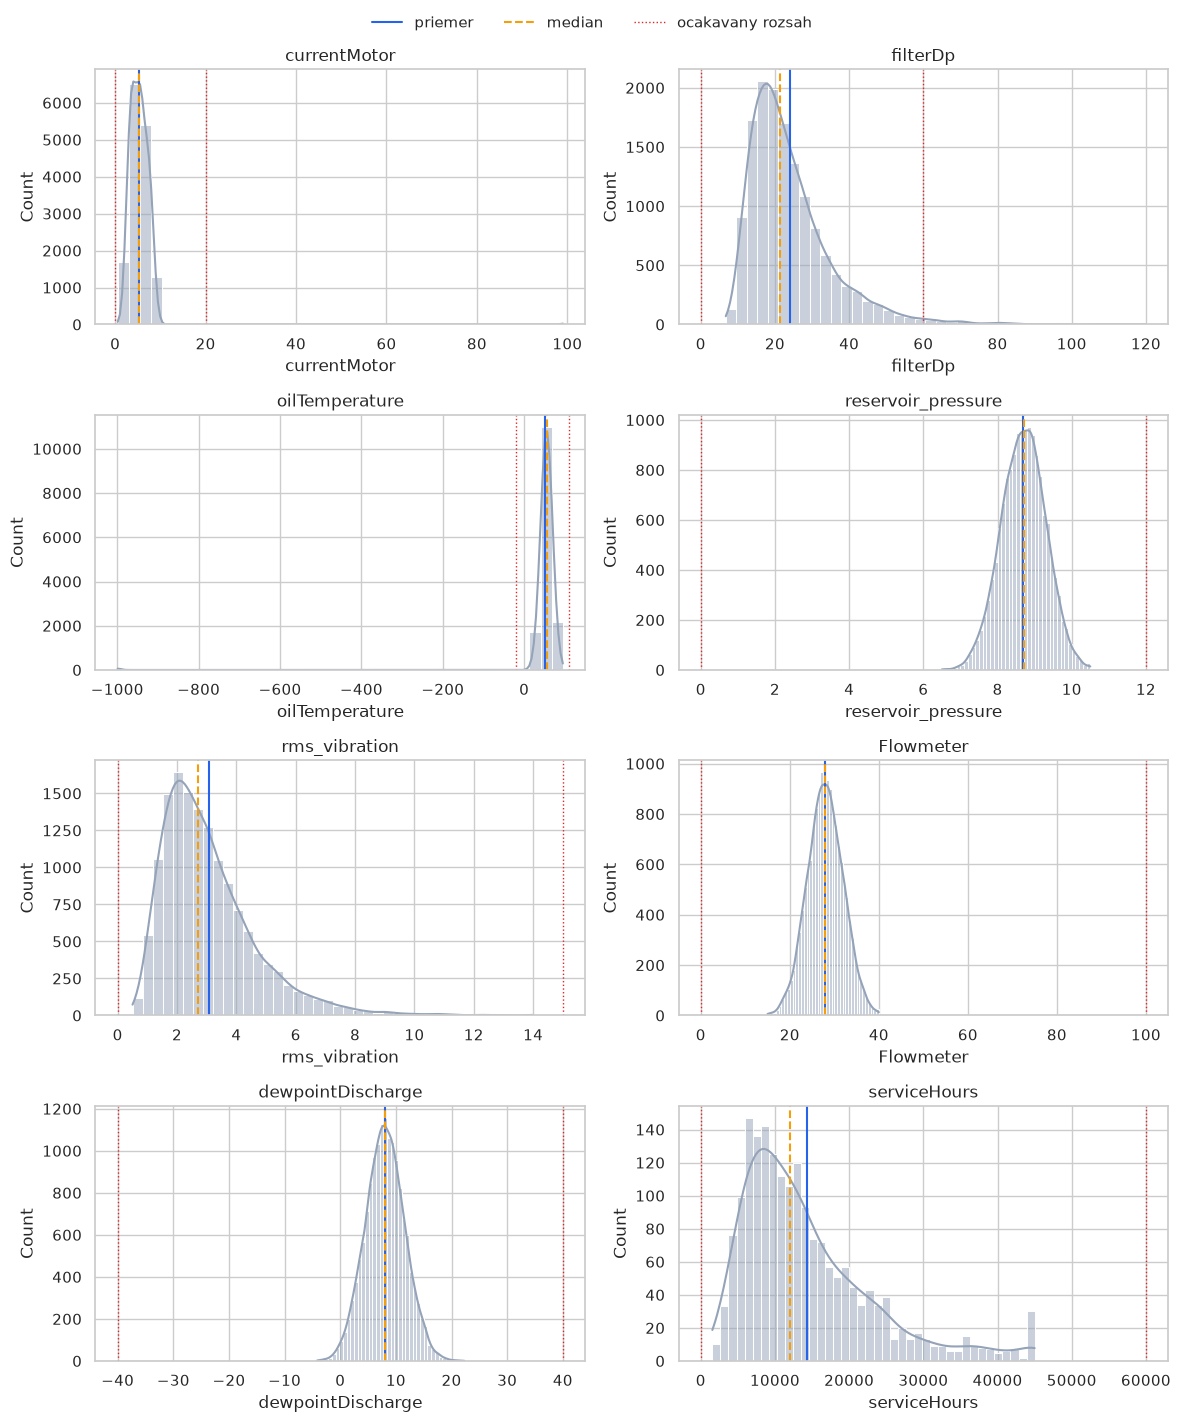

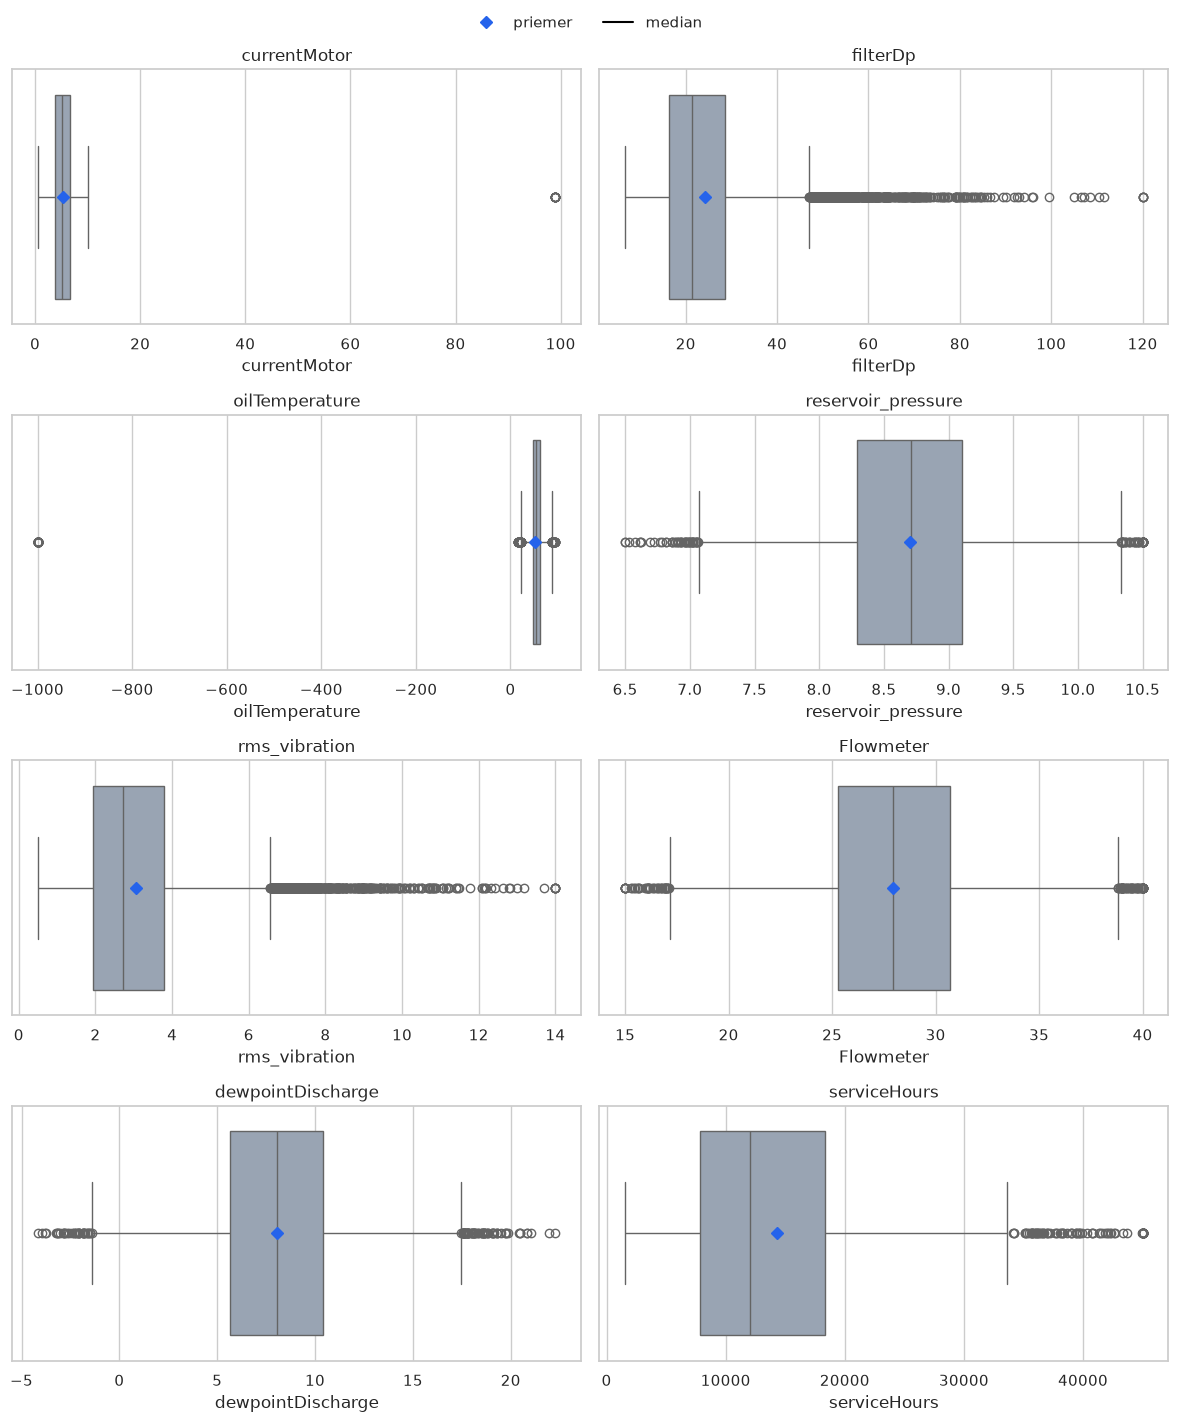

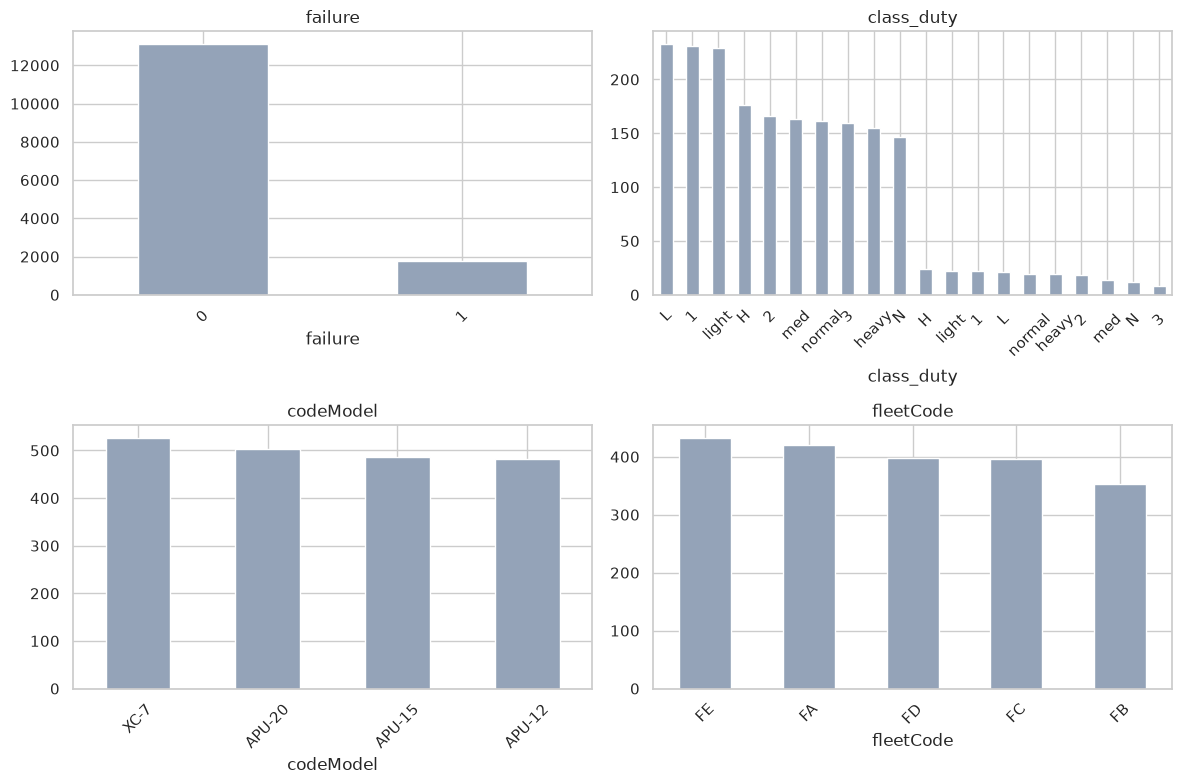

In [9]:
#1.1 B: Vizualizacia distribucii (histogramy s priemerom/medianom a ocakavanym rozsahom, boxploty, bar charty)

MEAN_COLOR = "#2563eb" #modra - priemer
MEDIAN_COLOR = "#f59e0b" #jantarova - median
RANGE_COLOR = "#dc2626" #cervena - hranice ocakavaneho rozsahu

fig, axes = plt.subplots(4, 2, figsize=(12, 14))
for ax, (name, s) in zip(axes.ravel(), numeric_attrs.items()):
    valid = s.dropna()
    sns.histplot(valid, kde = True, ax = ax, bins = 40, color ="#94a3b8")
    ax.axvline(valid.mean(), color = MEAN_COLOR, linestyle = "-", linewidth = 1.5)
    ax.axvline(valid.median(), color = MEDIAN_COLOR, linestyle = "--", linewidth = 1.5)
    lo, hi = expected_ranges[name]
    ax.axvline(lo, color = RANGE_COLOR, linestyle = ":", linewidth = 1)
    ax.axvline(hi, color = RANGE_COLOR, linestyle = ":", linewidth = 1)
    ax.set_title(name)

legend_handles = [
    plt.Line2D([0], [0], color = MEAN_COLOR, linestyle = "-", linewidth = 1.5, label = "priemer"),
    plt.Line2D([0], [0], color = MEDIAN_COLOR, linestyle = "--", linewidth = 1.5, label = "median"),
    plt.Line2D([0], [0], color = RANGE_COLOR, linestyle = ":", linewidth = 1, label = "ocakavany rozsah"),
]
fig.legend(handles = legend_handles, loc = "upper center", ncol = 3, bbox_to_anchor = (0.5, 1.02), frameon = False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 2, figsize = (12, 14))
for ax, (name, s) in zip(axes.ravel(), numeric_attrs.items()):
    valid = s.dropna()
    sns.boxplot(
        x = valid, ax = ax, color = "#94a3b8",
        showmeans = True,
        meanprops = {"marker": "D", "markerfacecolor": MEAN_COLOR, "markeredgecolor": MEAN_COLOR, "markersize": 6},
    )
    ax.set_title(name)

legend_handles = [
    plt.Line2D([0], [0], marker = "D", color = "none", markerfacecolor = MEAN_COLOR, markeredgecolor = MEAN_COLOR, markersize = 6, label = "priemer"),
    plt.Line2D([0], [0], color = "black", linewidth = 1.5, label = "median"), #median - ciara v boxe
]
fig.legend(handles = legend_handles, loc = "upper center", ncol = 2, bbox_to_anchor = (0.5, 1.02), frameon = False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize = (12, 8))
for ax, (name, s) in zip(axes.ravel(), categorical_attrs.items()):
    s.value_counts(dropna = False).plot(kind = "bar", ax = ax, color = "#94a3b8")
    ax.set_title(name)
    ax.tick_params(axis = "x", rotation = 45)
plt.tight_layout()
plt.show()

**Doplnková vizualizácia po predbežnom skríningu rozsahov**

Pôvodné histogramy vyššie ponechávame, pretože ukazujú aj dátové anomálie (napr. `oilTemperature = -999`). Nasledujúce grafy slúžia iba na čitateľnejšie zobrazenie hodnôt v pracovných rozsahoch z tabuľky `expected_ranges`. **Nejde o dôkaz, že všetky hodnoty mimo nich sú fyzikálne nemožné**, ani o dodatočnú zmenu zdrojových dát.

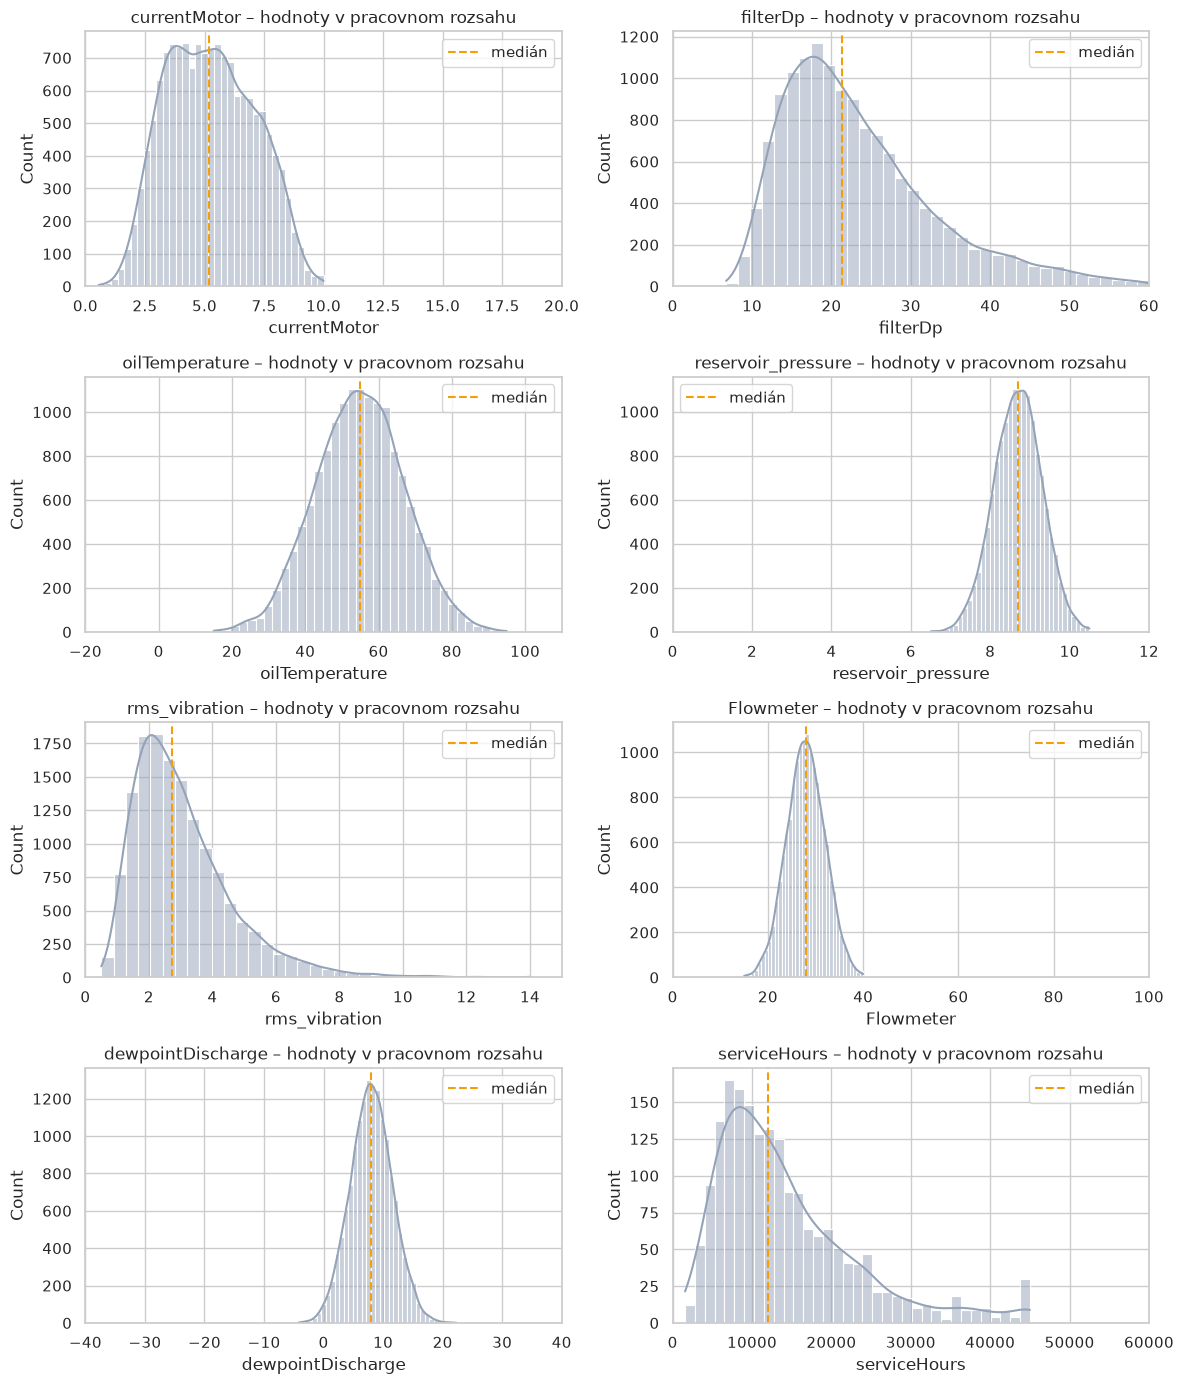

In [10]:
# Doplnkove histogramy: hodnoty v predbeznych skriningovych rozsahoch
# Ide len o vizualizaciu, numeric_attrs a zdrojove series nemenime
fig, axes = plt.subplots(4, 2, figsize=(12, 14))
for ax, (name, series) in zip(axes.ravel(), numeric_attrs.items()):
    lo, hi = expected_ranges[name]
    valid = series.dropna()
    valid = valid.loc[valid.between(lo, hi)]
    if len(valid):
        sns.histplot(valid, ax=ax, bins=35, kde=(len(valid) > 10), color="#94a3b8")
        ax.axvline(valid.median(), color="#f59e0b", linestyle="--", linewidth=1.5, label="medián")
    ax.set_xlim(lo, hi)
    ax.set_title(f"{name} – hodnoty v pracovnom rozsahu")
    ax.set_xlabel(name)
    ax.legend(loc="best") if len(valid) else None
plt.tight_layout()
plt.show()

### 1.1 C - Párová analýza dát (1b)
Identifikujte vzťahy a závislosti **medzi dvojicami atribútov** (napr. korelačná matica, scatter ploty, pairploty, krížové tabuľky pre kategorické premenné).

Spájame `readings` s `units` (cez zjednotené `id_unit`) a agregované brány z `gateways` (cez `id_depot`) do tabuľky `eda`.

In [11]:
#1.1 C: Priprava dat na parovu analyzu

#1. Zjednotenie formatu ID jednotky
readings_for_analysis = readings.copy()
readings_for_analysis["unit_num"] = (
    readings_for_analysis["id_unit"]
    .astype("string")
    .str.extract(r"(\d+)", expand=False)
    .astype("Int64")
)

units_for_analysis = units.copy()
units_for_analysis["unit_num"] = (
    pd.to_numeric(units_for_analysis["id_unit"], errors="coerce")
    .astype("Int64")
)

units_for_analysis = units_for_analysis.drop(columns=["id_unit"])

#2. Spojenie merani s informaciami o jednotkach
eda = readings_for_analysis.merge(
    units_for_analysis,
    on = "unit_num",
    how = "left",
    validate = "many_to_one",
    indicator = True
)

print("Vysledok spojenia readings a units:")
print(eda["_merge"].value_counts())

print("\nPocet riadkov pred spojenim:", len(readings))
print("Pocet riadkov po spojeni:", len(eda))

#Pocet merani, ku ktorym sa nepodarilo najst jednotku
print("Pocet merani bez zodpovedajucej jednotky:",
    (eda["_merge"] == "left_only").sum()
)

eda = eda.drop(columns = ["_merge"])

#3. Zhrnutie bran na uroven depa
gateway_by_depot = (
    gateways.groupby("id_depot", as_index=False).agg(
        mean_signal_dbm = ("signal_dbm", "mean"),
        median_signal_dbm = ("signal_dbm", "median")
    )
)

#4. Pripojenie zhrnutych udajov o branach
eda = eda.merge(
    gateway_by_depot,
    on = "id_depot",
    how = "left",
    validate = "many_to_one"
)

print("\nVysledna tabulka:", eda.shape)
display(eda.head())

Vysledok spojenia readings a units:
_merge
both          14773
left_only       140
right_only        0
Name: count, dtype: int64

Pocet riadkov pred spojenim: 14913
Pocet riadkov po spojeni: 14913
Pocet merani bez zodpovedajucej jednotky: 140

Vysledna tabulka: (14913, 19)


,id_unit,cycle_ts,currentMotor,filterDp,oilTemperature,reservoir_pressure,rms_vibration,Flowmeter,dewpointDischarge,failure,unit_num,serviceHours,class_duty,codeModel,id_depot,install_region,fleetCode,mean_signal_dbm,median_signal_dbm
0,U00255,01 Apr 2023,2.13647,35.27064,46.51969,8.67058,1.57706,31.55756,-0.38500,0,255,8662.0,light,XC-7,71.0,Esmoriz,FE,-72.418056,-72.40
1,U01678,2023-10-15,2.37777,15.52975,53.89221,8.66316,2.77607,27.21814,6.24255,0,1678,3446.1,1,XC-7,20.0,Ludwigslust,FA,-68.667187,-69.05
2,U01566,22 Jan 2023,4.37201,23.72927,41.83953,7.52580,3.18238,32.39756,9.00128,0,1566,25410.2,1,APU-20,23.0,Stuttgart,FE,-69.537121,-69.80
3,U00210,2023-11-25,4.71999,16.27284,48.42641,8.89410,1.12479,30.09175,7.41247,0,210,14907.7,normal,APU-20,56.0,Rudolstadt,FD,-71.623226,-71.60
4,U00367,05 Dec 2023,7.29926,15.88964,77.20834,7.92713,1.43034,20.98899,1.28321,0,367,14742.0,2,APU-20,55.0,Cuxhaven,FC,-70.581395,-70.10


Pearsonova a Spearmanova korelačná matica numerických atribútov (hodnoty mimo rozsahu sú pred výpočtom vyradené).

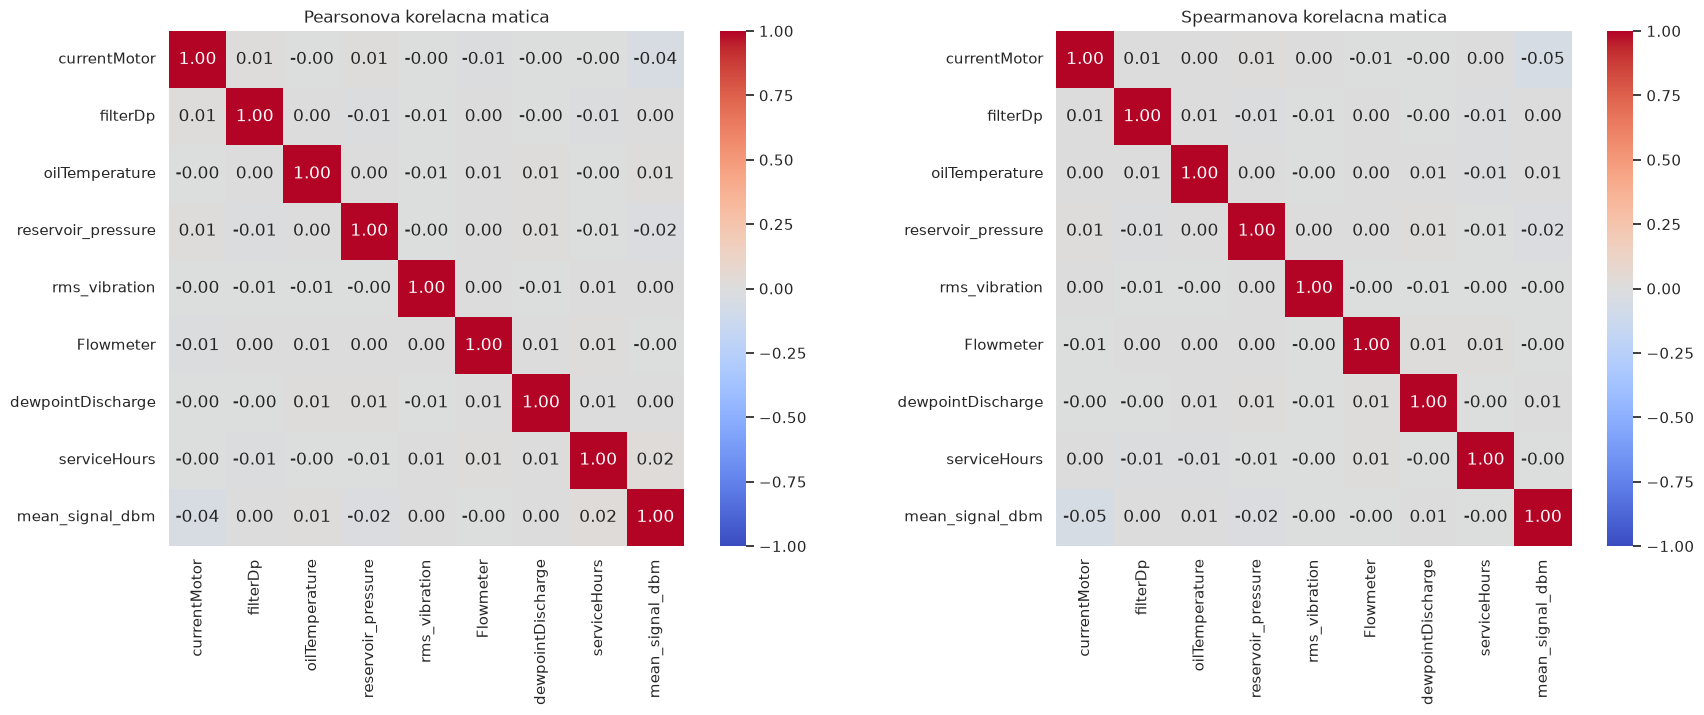

In [12]:
#Korelacna matica numerickych atributov
sensor_cols = [
    "currentMotor",
    "filterDp",
    "oilTemperature",
    "reservoir_pressure",
    "rms_vibration",
    "Flowmeter",
    "dewpointDischarge"
]

correlation_cols = sensor_cols + [
    "serviceHours",
    "mean_signal_dbm"
]

#Pracujeme iba s kopiou dat
pair_num = eda[correlation_cols].copy()

#Predbezne odfiltrovanie hodnot mimo ocakavanych rozsahov
#Pouzivame rozsahy definovane v casti 1.1 B
for col in sensor_cols + ["serviceHours"]:
    lower, upper = expected_ranges[col]
    pair_num[col] = pair_num[col].where(
        pair_num[col].between(lower, upper)
    )

#Vypocet korelacii, pandas pracuje s dostupnymi dvojicami hodnot
corr_pearson = pair_num.corr(method = "pearson")
corr_spearman = pair_num.corr(method = "spearman")

#Vizualizacia oboch matic
fig, axes = plt.subplots(1, 2, figsize = (18, 7))

sns.heatmap(
    corr_pearson,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm",
    vmin = -1,
    vmax = 1,
    center = 0,
    square = True,
    ax = axes[0]
)
axes[0].set_title("Pearsonova korelacna matica")

sns.heatmap(
    corr_spearman,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm",
    vmin = -1,
    vmax = 1,
    center = 0,
    square = True,
    ax = axes[1]
)
axes[1].set_title("Spearmanova korelacna matica")

plt.tight_layout()
plt.show()

Vyberáme 3 najsilnejšie dvojice atribútov podľa Spearmanovej korelácie a zobrazujeme ich ako scatter ploty.

,atribut1,atribut2,spearman_rho,abs_rho,pocet_spolocnych_merani
7,currentMotor,mean_signal_dbm,-0.051035,0.051035,14762
25,reservoir_pressure,mean_signal_dbm,-0.019530,0.019530,14773
23,reservoir_pressure,dewpointDischarge,0.014742,0.014742,14913


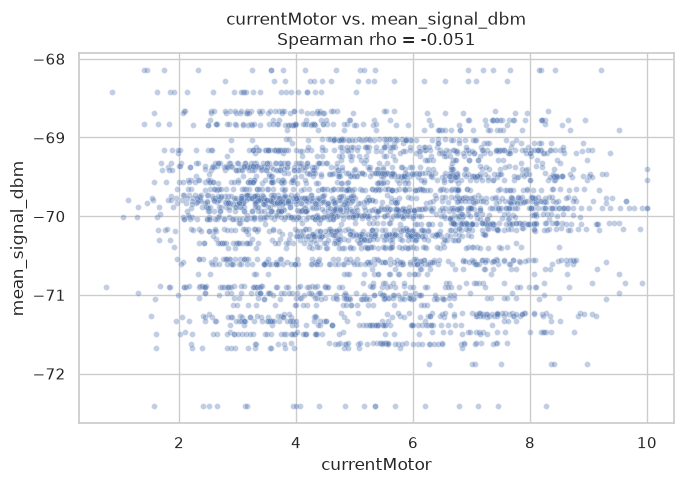

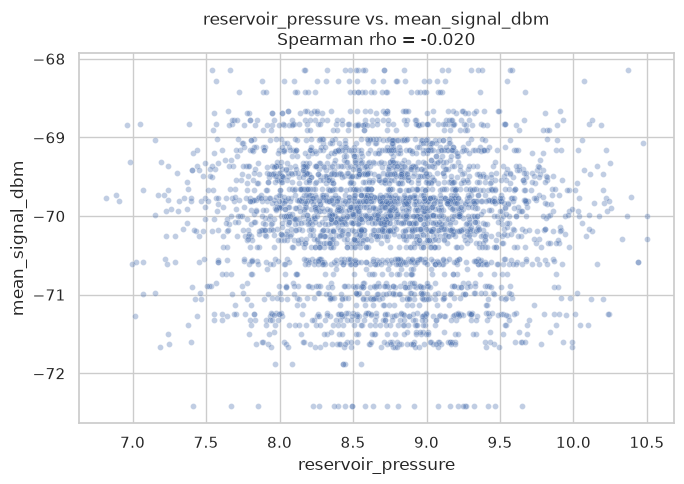

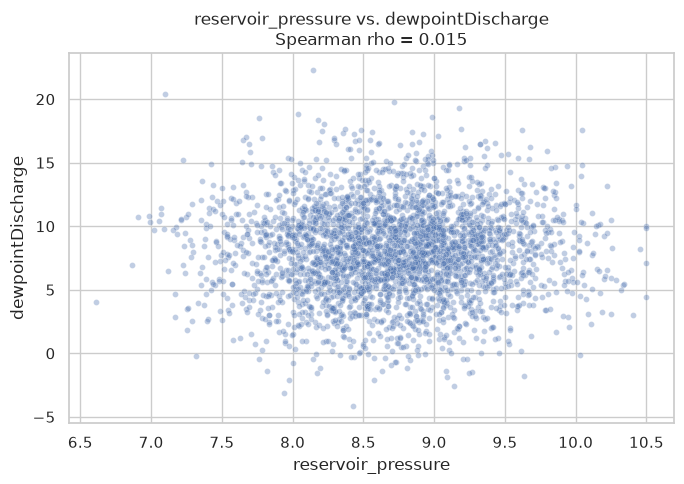

In [13]:
#Vyber najsilnejsich parov podla Spearmanovej korelacie
pairs = []

cols = list(pair_num.columns)

for i, col1 in enumerate(cols):
    for col2 in cols[i + 1:]:
        rho = corr_spearman.loc[col1, col2]
        n_valid = pair_num[[col1, col2]].dropna().shape[0]

        if pd.notna(rho) and n_valid >= 50:
            pairs.append({
                "atribut1": col1,
                "atribut2": col2,
                "spearman_rho": rho,
                "abs_rho": abs(rho),
                "pocet_spolocnych_merani": n_valid
            })

top_pairs = (
    pd.DataFrame(pairs)
    .sort_values("abs_rho", ascending=False)
    .head(3)
)

display(top_pairs)

#Bodove grafy troch najsilnejsich dvojic
for _, pair in top_pairs.iterrows():
    x = pair["atribut1"]
    y = pair["atribut2"]

    plot_data = pair_num[[x, y]].dropna()

    #Pri velkom pocte bodov pouzijeme nahodnu vzorku, aby graf zostal dobre citatelny
    if len(plot_data) > 3000:
        plot_data = plot_data.sample(3000, random_state=42)

    plt.figure(figsize = (7, 5))
    sns.scatterplot(
        data = plot_data,
        x = x,
        y = y,
        alpha = 0.35,
        s = 18
    )

    plt.title(
        f"{x} vs. {y}\n"
        f"Spearman rho = {pair['spearman_rho']:.3f}"
    )
    plt.tight_layout()
    plt.show()

Cramérovo V ako miera asociácie medzi kategorickými atribútmi (heatmapa). Pred výpočtom zjednocujeme zápisy `class_duty` na tri kanonické kategórie, aby rôzne zápisy tej istej úrovne umelo nenavyšovali počet kategórií.


Pocet nezmapovanych class_duty: 0
Kanonicke kategorie class_duty:
class_duty
light     758
medium    700
heavy     542
Name: count, dtype: int64


,class_duty,codeModel,fleetCode
class_duty,1.000,0.039,0.023
codeModel,0.039,1.000,0.047
fleetCode,0.023,0.047,1.000


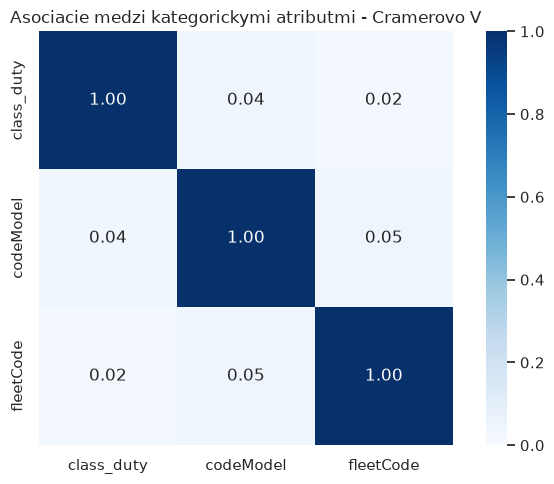

In [14]:
#Kontingencne tabulky a Cramerovo V
#class_duty ma 20 zapisov, ale v ramci EDA ich mapujeme na tri kanonicke urovne.
#Ponechavame povodnu frekvencnu tabulku z 1.1 B ako dokaz nekonzistentneho formatu.
class_duty_map = {
    "light": "light", "l": "light", "1": "light",
    "normal": "medium", "med": "medium", "medium": "medium", "n": "medium", "2": "medium",
    "heavy": "heavy", "h": "heavy", "3": "heavy",
}

cat_cols = ["class_duty", "codeModel", "fleetCode"]
cat_data = units[cat_cols].copy()
for col in cat_cols:
    cat_data[col] = cat_data[col].astype("string").str.strip().str.lower()
cat_data["class_duty"] = cat_data["class_duty"].map(class_duty_map)

print("Pocet nezmapovanych class_duty:", cat_data["class_duty"].isna().sum())
print("Kanonicke kategorie class_duty:")
print(cat_data["class_duty"].value_counts(dropna=False))


def cramers_v(x, y):
    #Vypocita Cramerovo V pre dvojicu kategorickych premennych
    #Chybajuce hodnoty pandas.crosstab standardne nezapocitava
    table = pd.crosstab(x, y)
    n = table.to_numpy().sum()
    if n == 0 or min(table.shape) < 2:
        return np.nan
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

cramers_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
for col1 in cat_cols:
    for col2 in cat_cols:
        cramers_matrix.loc[col1, col2] = cramers_v(cat_data[col1], cat_data[col2])

display(cramers_matrix.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(
    cramers_matrix.astype(float), annot=True, fmt=".2f", cmap="Blues",
    vmin=0, vmax=1, square=True
)
plt.title("Asociacie medzi kategorickymi atributmi - Cramerovo V")
plt.tight_layout()
plt.show()


Krížová tabuľka `class_duty` × `codeModel` (počty a podiely).

In [15]:
#Pocty jednotiek podla pracovneho rezimu a modelu
ct_counts = pd.crosstab(
    cat_data["class_duty"],
    cat_data["codeModel"]
)

print("Pocty jednotiek:")
display(ct_counts)

#Podiely modelov v ramci jednotlivych kategorii class_duty
ct_proportions = pd.crosstab(
    cat_data["class_duty"],
    cat_data["codeModel"],
    normalize="index"
).round(3)

print("Podiely v ramci class_duty:")
display(ct_proportions)

Pocty jednotiek:


codeModel,apu-12,apu-15,apu-20,xc-7
class_duty,,,,
heavy,130,140,147,125
light,176,186,189,207
medium,177,160,168,195


Podiely v ramci class_duty:


codeModel,apu-12,apu-15,apu-20,xc-7
class_duty,,,,
heavy,0.240,0.258,0.271,0.231
light,0.232,0.245,0.249,0.273
medium,0.253,0.229,0.240,0.279


Boxploty vybraných senzorov podľa zjednotenej kategórie `class_duty` (`light`, `medium`, `heavy`).


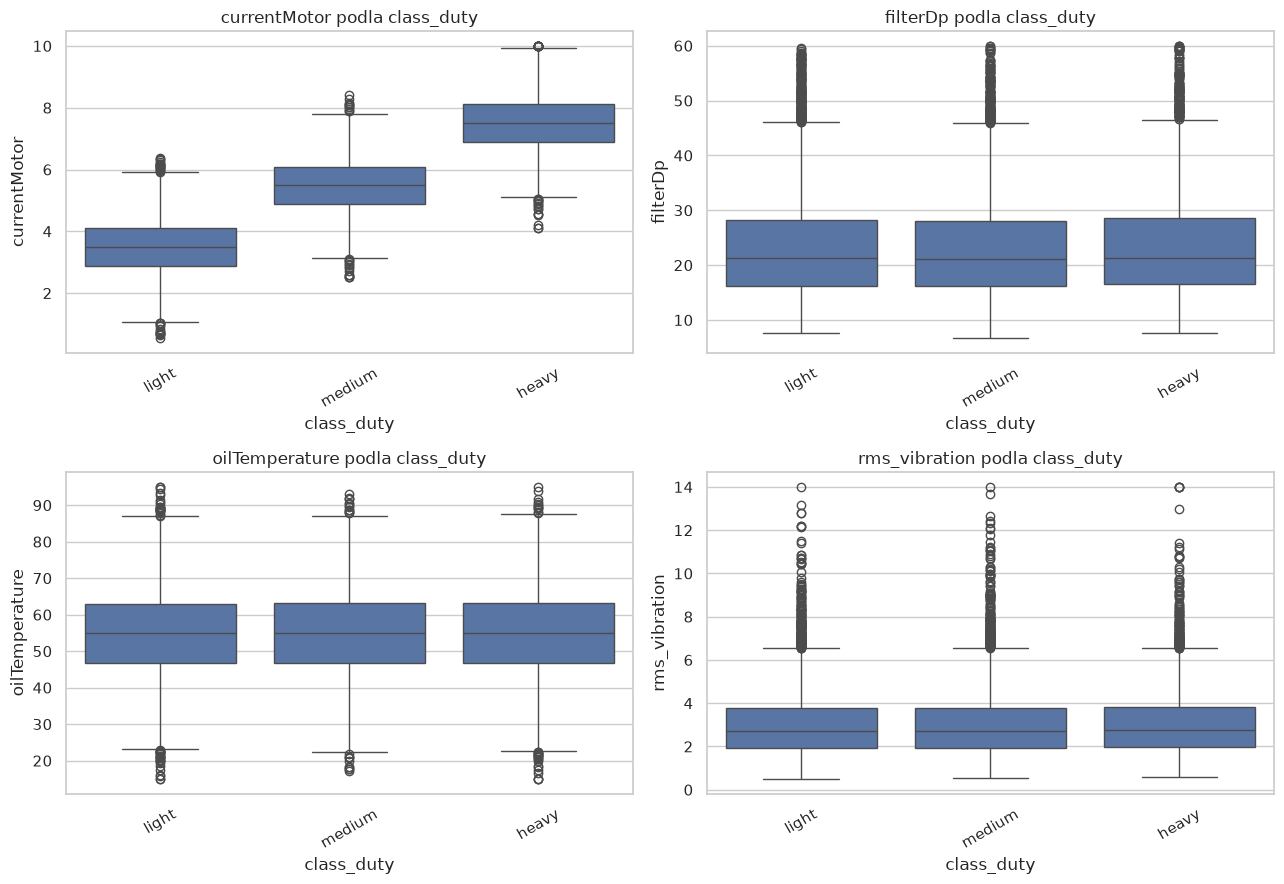

In [16]:
#Numericke atributy podla class_duty
num_cat_cols = [
    "currentMotor",
    "filterDp",
    "oilTemperature",
    "rms_vibration"
]

plot_data = eda[["class_duty"] + num_cat_cols].copy()
plot_data["class_duty"] = (
    plot_data["class_duty"].astype("string").str.strip().str.lower().map(class_duty_map)
)

#Rovnake predbezne oznacenie hodnot mimo pracovnych skriningovych rozsahov
for col in num_cat_cols:
    lower, upper = expected_ranges[col]
    plot_data[col] = plot_data[col].where(
        plot_data[col].between(lower, upper)
    )

fig, axes = plt.subplots(2, 2, figsize = (13, 9))

for ax, col in zip(axes.ravel(), num_cat_cols):
    temp = plot_data[["class_duty", col]].dropna()

    order = temp["class_duty"].value_counts().index

    sns.boxplot(
        data = temp,
        x = "class_duty",
        y = col,
        order = order,
        ax = ax
    )

    ax.set_title(f"{col} podla class_duty")
    ax.set_xlabel("class_duty")
    ax.set_ylabel(col)
    ax.tick_params(axis = "x", rotation = 30)

plt.tight_layout()
plt.show()


### 1.1 D - Párová analýza: predikovaná premenná vs. ostatné (1b)
Identifikujte závislosti medzi **predikovanou premennou `failure`** a ostatnými (potenciálnymi prediktormi) – napr. boxploty podľa `failure`, korelácia s cieľovou premennou, rozdiely distribúcií.

Pripravujeme numerické atribúty a porovnávame ich priemer, medián a smerodajnú odchýlku podľa `failure`.

In [17]:
#1.1 D: Priprava numerickych atributov vzhladom na failure
failure_num_cols = sensor_cols + ["serviceHours", "mean_signal_dbm"]

failure_num = eda[failure_num_cols + ["failure"]].copy()

#Rovnake predbezne oznacenie hodnot mimo ocakavanych rozsahov ako v 1.1 B/C
for col in sensor_cols + ["serviceHours"]:
    lower, upper = expected_ranges[col]
    failure_num[col] = failure_num[col].where(
        failure_num[col].between(lower, upper)
    )

#Suhrnne statistiky (priemer, median, smerodajna odchylka) podla stavu failure
group_stats = (
    failure_num.groupby("failure")[failure_num_cols]
    .agg(["mean", "median", "std"])
)
display(group_stats.round(3))

#Rozdiel priemerov (failure = 1 minus failure = 0) - rychly prehlad smeru a velkosti rozdielu
mean_diff = (
    failure_num.groupby("failure")[failure_num_cols].mean().diff().iloc[-1]
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
print("Rozdiel priemerov (failure=1 minus failure=0), zoradene podla velkosti rozdielu:")
print(mean_diff.round(3))

currentMotor               filterDp                 oilTemperature  \
                mean median    std     mean  median     std           mean   
failure                                                                      
0              5.306  5.273  1.850   23.146  21.002   9.567         54.921   
1              4.964  4.677  1.651   26.055  23.962  10.506         55.260   

                        reservoir_pressure               rms_vibration         \
         median     std               mean median    std          mean median   
failure                                                                         
0        54.945  11.807              8.715  8.725  0.600         3.044  2.702   
1        55.413  13.676              8.577  8.580  0.597         3.213  2.867   

               Flowmeter                dewpointDischarge                \
           std      mean  median    std              mean median    std   
failure                                                                   
0        1.582    28.000  28.001  4.009             7.956  7.930  3.515   
1        1.708    27.679  27.493  4.073             8.782  8.712  3.608   

        serviceHours                     mean_signal_dbm                 
                mean   median        std            mean  median    std  
failure                                                                  
0            13881.7  11678.0   8606.576         -70.001 -69.926  0.796  
1            17400.1  14838.0  10216.941         -70.002 -69.895  0.815

Rozdiel priemerov (failure=1 minus failure=0), zoradene podla velkosti rozdielu:
serviceHours          3518.400
filterDp                 2.909
dewpointDischarge        0.825
currentMotor            -0.342
oilTemperature           0.339
Flowmeter               -0.321
rms_vibration            0.169
reservoir_pressure      -0.138
mean_signal_dbm         -0.002
Name: 1, dtype: float64


Boxploty všetkých numerických atribútov rozdelené podľa `failure`.

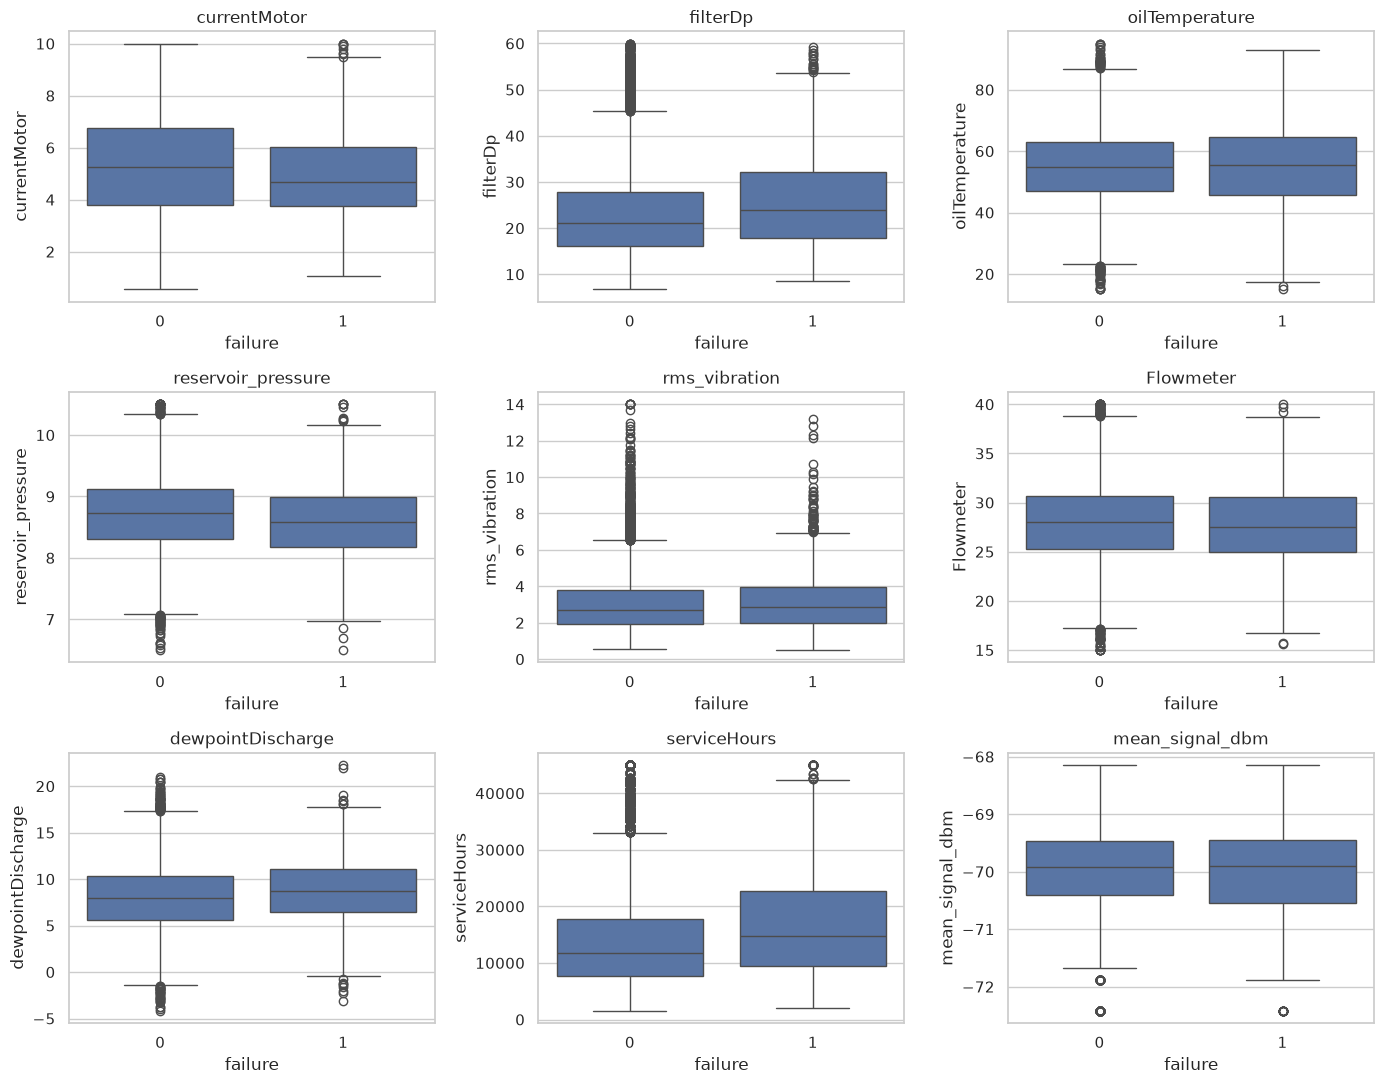

In [18]:
#1.1 D: Boxploty numerickych atributov podla failure

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, col in zip(axes.ravel(), failure_num_cols):
    sns.boxplot(
        data = failure_num,
        x  ="failure",
        y = col,
        ax = ax
    )
    ax.set_title(col)

#Nevyuzite subploty (ak atributov je menej ako mriezka) vypneme
for ax in axes.ravel()[len(failure_num_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Pearsonova a Spearmanova korelácia numerických atribútov s `failure` (zoradené podľa sily) a stĺpcový graf.

,pearson,spearman,abs_spearman
serviceHours,0.129,0.121,0.121
filterDp,0.090,0.088,0.088
reservoir_pressure,-0.074,-0.075,0.075
dewpointDischarge,0.076,0.074,0.074
currentMotor,-0.061,-0.064,0.064
rms_vibration,0.032,0.029,0.029
Flowmeter,-0.026,-0.025,0.025
oilTemperature,0.009,0.010,0.010
mean_signal_dbm,-0.001,0.002,0.002


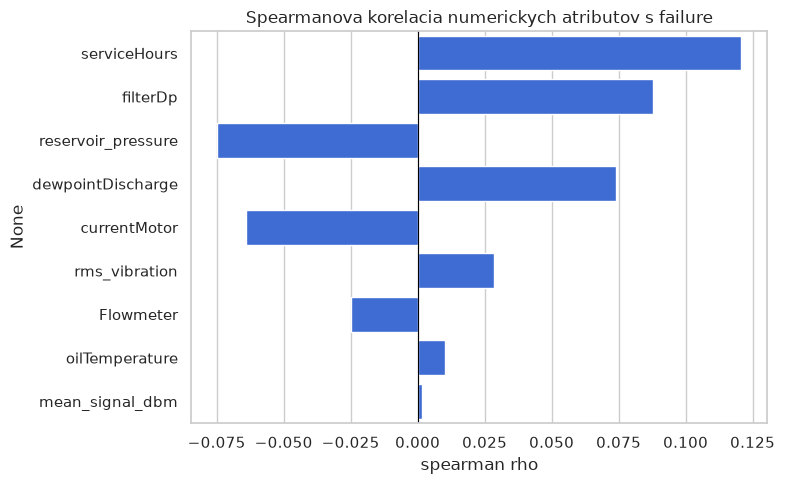

In [19]:
#1.1 D: Korelacia numerickych atributov s cielovou premennou failure

corr_with_failure = pd.DataFrame({
    "pearson": failure_num[failure_num_cols].corrwith(failure_num["failure"], method="pearson"),
    "spearman": failure_num[failure_num_cols].corrwith(failure_num["failure"], method="spearman"),
})
corr_with_failure["abs_spearman"] = corr_with_failure["spearman"].abs()
corr_with_failure = corr_with_failure.sort_values("abs_spearman", ascending = False)

display(corr_with_failure.round(3))

plt.figure(figsize=(8, 5))
sns.barplot(
    x=corr_with_failure["spearman"],
    y=corr_with_failure.index,
    color="#2563eb"
)
plt.axvline(0, color = "black", linewidth = 0.8)
plt.title("Spearmanova korelacia numerickych atributov s failure")
plt.xlabel("spearman rho")
plt.tight_layout()
plt.show()

Miera `failure` podľa kategórií a Cramérovo V medzi kategorickými atribútmi a `failure`.

In [20]:
#1.1 D: Kategoricke atributy vs. failure

cat_cols_failure = ["class_duty", "codeModel", "fleetCode"]
cat_vs_failure = eda[cat_cols_failure + ["failure"]].copy()
for col in cat_cols_failure:
    cat_vs_failure[col] = cat_vs_failure[col].astype("string").str.strip().str.lower()
cat_vs_failure["class_duty"] = cat_vs_failure["class_duty"].map(class_duty_map)

print("Nezmapovane class_duty v EDA:", cat_vs_failure["class_duty"].isna().sum())
print("Miera failure (%) podla kategorie (class_duty je zjednotene):")
for col in cat_cols_failure:
    rate = (
        cat_vs_failure.groupby(col)["failure"].mean().mul(100).round(2)
        .sort_values(ascending=False)
    )
    print(f"\n=== {col} ===")
    print(rate)

print("\nCramerovo V medzi kategorickymi atributmi a failure:")
for col in cat_cols_failure:
    v = cramers_v(cat_vs_failure[col], cat_vs_failure["failure"])
    print(f"{col}: {v:.3f}")


Nezmapovane class_duty v EDA: 140
Miera failure (%) podla kategorie (class_duty je zjednotene):

=== class_duty ===
class_duty
light     18.26
medium     9.40
heavy      6.60
Name: failure, dtype: float64

=== codeModel ===
codeModel
xc-7      12.77
apu-20    12.68
apu-12    11.73
apu-15    10.91
Name: failure, dtype: float64

=== fleetCode ===
fleetCode
fc    12.45
fa    12.25
fb    12.15
fe    12.13
fd    11.18
Name: failure, dtype: float64

Cramerovo V medzi kategorickymi atributmi a failure:
class_duty: 0.154
codeModel: 0.023
fleetCode: 0.013


Stĺpcové grafy miery `failure` pre `class_duty`, `codeModel` a `fleetCode`.

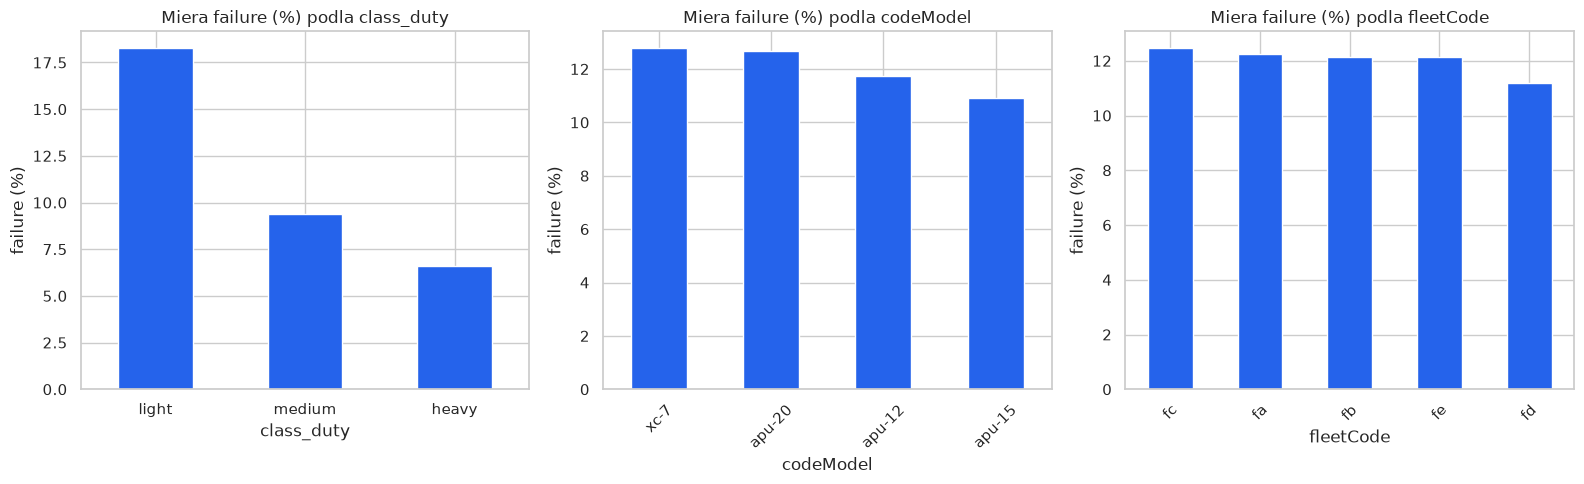

In [21]:
#1.1 D: Vizualizacia miery failure podla kategorie

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, cat_cols_failure):
    rate = (
        cat_vs_failure.groupby(col)["failure"].mean().mul(100)
        .sort_values(ascending=False)
    )
    rate.plot(kind = "bar", ax = ax, color = "#2563eb")
    ax.set_title(f"Miera failure (%) podla {col}")
    ax.set_ylabel("failure (%)")
    ax.tick_params(axis = "x", rotation = 0 if col == "class_duty" else 45)
plt.tight_layout()
plt.show()


### 1.1 E - Prvotné zamyslenie k riešeniu zadania (1b)
Zhrňte textovo: Sú niektoré atribúty medzi sebou závislé? Od ktorých atribútov zrejme závisí `failure`? Je potrebné kombinovať záznamy z viacerých súborov a ako?


**Sú niektoré atribúty medzi sebou závislé?**

V 1.1 C sme porovnali Spearmanove korelácie numerických atribútov a Cramérovo V medzi kategorickými atribútmi. Najsilnejšia zobrazená dvojica numerických atribútov mala Spearmanovu koreláciu rho približne -0,05 (`currentMotor` vs. `mean_signal_dbm`), čo naznačuje veľmi slabú (prakticky zanedbateľnú) monotónnu závislosť v analyzovaných dvojiciach. **Korelácia blízka nule však sama osebe nedokazuje nezávislosť** a tieto výsledky nevylučujú nelineárne či viacpremenné vzťahy. Kategórie `class_duty` sme zjednotili na `light`, `medium` a `heavy`. Výsledky Cramérovej matice preto interpretujeme až po tomto zjednotení. Na základe zobrazených párových výsledkov nevidíme výrazné párové korelácie, nie je však správne vyhlásiť všetky atribúty za nezávislé.

**Od ktorých atribútov zrejme závisí `failure`?**

V 1.1 D porovnávame distribúcie pri jednotlivých meraniach (`failure = 0` a `failure = 1`). Z numerických atribútov najviac vystupujú `serviceHours` a `filterDp`. Po zjednotení zápisov `class_duty` je miera `failure` najvyššia v kategórii `light` (18,26%), nasleduje `medium` (9,40%) a `heavy` (6,60%). Cramérovo V medzi `class_duty` a `failure` je 0,154. Pri `codeModel` (V = 0,023) a `fleetCode` (V = 0,013) je asociácia podstatne slabšia. Ide o asociácie, nie dôkaz príčinnej súvislosti.

Rozdiel `serviceHours` približne 3 518 hodín v deskriptívnej analýze 1.1 D je počítaný na úrovni meraní, takže jednotky s viacerými meraniami majú väčšiu váhu. V hypotéze H1 v časti 1.3 najprv sumarizujeme dáta na jeden záznam na jednotku, preto tam rozdiel priemerov vychádza približne 3 267 hodín. Ide o dve odlišné úrovne analýzy, nie nevyhnutne o rozpor.

Ostatné senzory a kategórie majú v párových výstupoch slabšie vzťahy s `failure`. Ide však o prieskumné porovnania, nie o dôkaz, že dané atribúty nemajú predikčnú hodnotu v kombinácii s inými premennými. Pri modelovaní bude vhodné porovnať prínos viacerých atribútov spoločne.

**Je potrebné kombinovať záznamy z viacerých súborov a ako?**

Áno. Cieľová premenná `failure` a senzorové merania sú v `readings.csv`, zatiaľ čo `serviceHours`, `class_duty`, `codeModel` a `fleetCode` sú v `units.csv`. Integrácia prebieha cez `id_unit` po zjednotení formátu (`"U00255"` vs. `255`) a vzťah je N:1 (viac meraní na jednu jednotku). Údaje `gateways.csv` sa v tejto fáze agregujú na úroveň `id_depot` (napr. priemerný `signal_dbm`) a pripájajú cez depo. Hoci `gateways.id_unit` pokrýva vlastnú bránu každej jednotky, tento vzťah zatiaľ nie je použitý pre hlavnú integráciu, jeho ďalšie využitie treba rozhodnúť v ďalších fázach.

**Časové obmedzenie:** merania `readings` pokrývajú rok 2023, ale 1 531 z 16 000 brán má `install_date` po 31. 12. 2023. Agregovaný `mean_signal_dbm` na úrovni depa preto môže zahŕňať aj brány, ktoré v čase historického merania ešte neboli nainštalované. V tejto fáze to evidujeme ako obmedzenie, pred použitím tohto atribútu v prediktívnom modeli bude potrebné overiť, či sú informácie dostupné k času predikcie, aby nevznikol únik informácií z budúcnosti.


## 1.2 Identifikácia problémov, integrácia a čistenie dát (5b)

### 1.2 A - Identifikácia a riešenie problémov v dátach (2b)
Identifikujte a prvotne riešte problémy v dátach, napr.: nevhodná štruktúra dát, duplicitné záznamy, nejednotné formáty (napr. rôzne formáty dátumov v `install_date`), chýbajúce hodnoty. V dátach sa môžu nachádzať aj iné, tu nevymenované problémy.

Odstraňujeme úplné duplicity v `readings` a zlučujeme konfliktné dvojice s rovnakým `(id_unit, cycle_ts)`.

In [22]:
#1.2 A: Duplicitne zaznamy v readings

print(f"Pocet uplne duplicitnych riadkov v readings: {readings.duplicated().sum()}")

#Odstranenie uplnych duplicit (nechame len prvy vyskyt)
readings_clean = readings.drop_duplicates().copy()
print(f"Po odstraneni uplnych duplicit: {readings.shape[0]} -> {readings_clean.shape[0]} riadkov ")
print(f"({readings.shape[0] - readings_clean.shape[0]} odstránených)")

#Dolezita kontrola: ci sa pri zlucovani zaznamov meni cielovy stitok failure.
#Ak ma rovnaky (id_unit, cycle_ts) viac roznych stitkov, pravidlo failure=max
#uprednostni pozitivnu triedu a moze zvysit pocet zaznamenanych poruch.
raw_label_nunique = readings_clean.groupby(["id_unit", "cycle_ts"])["failure"].nunique(dropna=True)
raw_label_conflict_keys = raw_label_nunique[raw_label_nunique > 1]
print(f"Skupiny s konfliktnym failure pred agregaciou (povodne kluce): {len(raw_label_conflict_keys)}")
if len(raw_label_conflict_keys):
    display(readings_clean.set_index(["id_unit", "cycle_ts"]).loc[raw_label_conflict_keys.index].reset_index().sort_values(["id_unit", "cycle_ts"]).head(10))
    #kolko konkretnych riadkov malo povodne failure=0 a po pravidle max skonci v skupine oznacenej ako 1
    rows_flipped_raw = readings_clean.set_index(["id_unit", "cycle_ts"]).loc[raw_label_conflict_keys.index]
    rows_flipped_raw = (rows_flipped_raw["failure"] == 0).sum()
    print(f"Z toho riadkov s povodnym failure=0 (ich stitok po max prebije failure=1 tej istej skupiny): {rows_flipped_raw}")
else:
    print("Pri povodnych klucoch sme nenasli skupinu s roznymi hodnotami failure.")

#Kontrola ci po odstraneni uplnych duplicit este existuju zaznamy s rovnakym klucom (id_unit, cycle_ts),
#ale rozdielnymi nameranymi hodnotami - jedna jednotka nemoze mat v tom istom okamihu dve rôzne merania, 
#ide teda o konfliktné (nelogické) duplicity.
key_dup_mask = readings_clean.duplicated(subset=["id_unit", "cycle_ts"], keep=False)
print(f"\nZáznamy s rovnakým (id_unit, cycle_ts), ale rozdielnymi hodnotami: ")
print(f"{key_dup_mask.sum()} riadkov ({key_dup_mask.sum() // 2} dvojíc)")
display(readings_clean.loc[key_dup_mask].sort_values(["id_unit", "cycle_ts"]).head(6))

#Pri konfliktnych dvojiciach nevieme urcit, ktore meranie je spravne. Numericke senzory spriemerujeme.
#failure=max je nasa PRACOVNA/zjednodusujuca volba, nie overena pravda - automaticky uprednostnuje
#pozitivny stitok, teda moze umelo navysit pocet zaznamenanych poruch. Pocet konfliktov aj pocet
#riadkov, ktorym sa takto zmenil stitok z 0 na 1, preto explicitne vykazujeme vyssie aj nizsie.
agg_dict = {c: "mean" for c in readings_clean.select_dtypes("number").columns if c != "failure"}
agg_dict["failure"] = "max"
n_before_merge = len(readings_clean)
readings_clean = readings_clean.groupby(["id_unit", "cycle_ts"], as_index=False).agg(agg_dict)

print(f"\nPo zlúčení konfliktných duplicít: {n_before_merge} -> {len(readings_clean)} riadkov ")
print(f"(zostávajúce duplicitné kľúče: {readings_clean.duplicated(subset=['id_unit','cycle_ts']).sum()})")


Pocet uplne duplicitnych riadkov v readings: 220
Po odstraneni uplnych duplicit: 14913 -> 14693 riadkov 
(220 odstránených)
Skupiny s konfliktnym failure pred agregaciou (povodne kluce): 8


,id_unit,cycle_ts,currentMotor,filterDp,oilTemperature,reservoir_pressure,rms_vibration,Flowmeter,dewpointDischarge,failure
0,U00489,26 Feb 2023,6.13280,29.29393,51.90011,8.17829,2.05036,30.49980,7.88613,0
1,U00489,26 Feb 2023,6.17461,25.42985,81.56655,7.78178,3.07551,18.18079,7.57247,1
2,U00595,2023-03-26,3.54824,11.42888,37.88074,8.67668,0.81025,21.86883,10.94271,1
3,U00595,2023-03-26,2.96890,21.50258,48.27363,9.21304,1.57351,21.54320,3.14652,0
4,U00750,23 Apr 2023,3.84970,33.11421,65.29582,8.63810,0.84484,30.62664,14.46481,0
5,U00750,23 Apr 2023,2.71394,43.17025,57.06846,6.96745,4.82652,21.25367,11.21146,1
6,U00792,06 Nov 2023,4.30970,19.25692,65.73673,8.10499,2.51773,29.83091,7.06943,1
7,U00792,06 Nov 2023,3.67995,14.79403,64.43287,8.85219,7.34772,25.55178,6.27104,0
8,U00872,2023/08/27,5.52158,17.17332,65.96023,8.89466,4.10783,30.62891,6.04622,0
9,U00872,2023/08/27,4.37327,26.99062,46.62119,9.19851,2.47005,31.08101,10.86300,1


Z toho riadkov s povodnym failure=0 (ich stitok po max prebije failure=1 tej istej skupiny): 8

Záznamy s rovnakým (id_unit, cycle_ts), ale rozdielnymi hodnotami: 
70 riadkov (35 dvojíc)


,id_unit,cycle_ts,currentMotor,filterDp,oilTemperature,reservoir_pressure,rms_vibration,Flowmeter,dewpointDischarge,failure
402,U00098,03 Feb 2023,5.18881,25.34033,80.16214,8.04493,2.63631,31.54074,7.11677,0
11990,U00098,03 Feb 2023,6.25358,36.88739,69.95757,9.04216,1.83706,27.91426,4.18842,0
10322,U00156,08 Oct 2023,5.76604,17.79072,46.82021,9.12423,1.95322,27.05374,-1.18121,0
12901,U00156,08 Oct 2023,2.55827,15.30020,50.94457,9.63646,3.70421,29.59381,7.52433,0
359,U00198,2023/07/29,2.00088,26.29264,66.06991,9.16536,4.64221,28.90552,9.39737,0
3811,U00198,2023/07/29,4.16058,28.74561,58.92487,7.36803,0.96246,37.33315,12.64485,0



Po zlúčení konfliktných duplicít: 14693 -> 14658 riadkov 
(zostávajúce duplicitné kľúče: 0)


Zjednocujeme rôzne formáty dátumov (`cycle_ts`, `install_date`) na jeden typ `datetime`.

In [23]:
#1.2 A: Nejednotne formaty - datumy (cycle_ts, install_date)

print("Priklady roznych formatov cycle_ts v readings:")
print(readings_clean["cycle_ts"].sample(8, random_state = 1).tolist())
print("\nPriklady roznych formatov install_date v gateways:")
print(gateways["install_date"].sample(8, random_state=1).tolist())

#Oba stlpce obsahuju zmes formatov ("DD Mon YYYY", "YYYY-MM-DD", "YYYY/MM/DD", "MM/DD/YYYY, HH:MM:SS") 
#pandas.to_datetime s format = "mixed" vie rozne formaty
#v ramci jedneho stlpca rozpoznat a zjednotit na jeden datetime typ.
readings_clean["cycle_ts"] = pd.to_datetime(readings_clean["cycle_ts"], format = "mixed", dayfirst = False)

gateways_clean = gateways.copy()
gateways_clean["install_date"] = pd.to_datetime(gateways_clean["install_date"], format = "mixed", dayfirst = False)

print(f"\ncycle_ts po zjednoteni: typ={readings_clean['cycle_ts'].dtype}, "
      f"rozsah {readings_clean['cycle_ts'].min().date()} .. {readings_clean['cycle_ts'].max().date()}, "
      f"neparsovateľne: {readings_clean['cycle_ts'].isna().sum()}")
print(f"install_date po zjednoteni: typ = {gateways_clean['install_date'].dtype}, "
      f"rozsah {gateways_clean['install_date'].min().date()} .. {gateways_clean['install_date'].max().date()}, "
      f"neparsovateľné: {gateways_clean['install_date'].isna().sum()}")


Priklady roznych formatov cycle_ts v readings:
['2023-01-23', '2023/08/12', '2023/07/22', '22 Nov 2023', '2023-07-29', '06/07/2023, 11:58:00', '2023/04/10', '09 Jun 2023']

Priklady roznych formatov install_date v gateways:
['2020/11/07', '28 Jan 2022', '2019/02/12', '2021/11/24', '2023/10/02', '19 Jan 2023', '2017/04/25', '2024-06-25']



cycle_ts po zjednoteni: typ=datetime64[us], rozsah 2023-01-01 .. 2023-12-31, neparsovateľne: 0
install_date po zjednoteni: typ = datetime64[us], rozsah 2015-01-01 .. 2024-12-28, neparsovateľné: 0


Pri čistení zjednocujeme 20 rôznych zápisov `class_duty` na 3 úrovne záťaže (`light`, `medium`, `heavy`). Rovnaké mapovanie už používame aj v párovej analýze 1.1 C a pri analýze `failure` v 1.1 D, takže závery neporovnávajú oddelené zápisy tej istej kategórie.


In [24]:
#1.2 A: Nejednotné formáty - kategórie class_duty

print("Povodne hodnoty class_duty (jedna logicka kategoria zapisana viacerymi sposobmi):")
print(units["class_duty"].value_counts(dropna=False))

#pouzijeme rovnake class_duty_map ako v 1.1 C, aby mapping bol konzistentny napriec analyzou a cistenim
units_clean = units.copy()
units_clean["class_duty"] = units_clean["class_duty"].astype(str).str.strip().str.lower().map(class_duty_map)

print(f"\nNezmapovanych hodnot: {units_clean['class_duty'].isna().sum()}")
print("\nclass_duty po zjednoteni (3 kategorie):")
print(units_clean["class_duty"].value_counts(dropna=False))


Povodne hodnoty class_duty (jedna logicka kategoria zapisana viacerymi sposobmi):
class_duty
L           233
1           231
light       229
H           176
2           166
med         163
normal      161
3           160
heavy       155
N           147
 H           24
 light       22
 1           22
 L           21
 normal      19
 heavy       19
 2           18
 med         14
 N           12
 3            8
Name: count, dtype: int64

Nezmapovanych hodnot: 0

class_duty po zjednoteni (3 kategorie):
class_duty
light     758
medium    700
heavy     542
Name: count, dtype: int64


Zjednocujeme `id_unit` na číslo, vyraďujeme merania bez jednotky v `units` a spájame všetko do `df_clean`.

In [25]:
#1.2 A: Zjednotenie formatu id_unit a integracia súborov

#readings.id_unit je retazec ("U00255"), units/gateways.id_unit je cislo (255) -> zjednotime na cislo
readings_clean["id_unit"] = readings_clean["id_unit"].str.extract(r"(\d+)").astype(int)

#kontrola duplicit kluca este raz - teraz uz maju datum aj id_unit jednotny format
#Pred ich zlucenim znovu overime, ci sa nelisia aj hodnoty cielovej premennej failure.
label_nunique_after_norm = readings_clean.groupby(["id_unit", "cycle_ts"])["failure"].nunique(dropna=True)
label_conflicts_after_norm = label_nunique_after_norm[label_nunique_after_norm > 1]
print(f"Skupiny s konfliktnym failure po normalizacii id a datumu: {len(label_conflicts_after_norm)}")
if len(label_conflicts_after_norm):
    conflict_keys = label_conflicts_after_norm.index
    conflict_mask = pd.MultiIndex.from_frame(readings_clean[["id_unit", "cycle_ts"]]).isin(conflict_keys)
    display(readings_clean.loc[conflict_mask].sort_values(["id_unit", "cycle_ts"]).head(10))
    #rovnaka kontrola ako pri 1.2 A - kolko riadkov malo povodne failure=0 a po max skonci oznacenych ako 1
    rows_flipped_norm = readings_clean.loc[conflict_mask]
    rows_flipped_norm = (rows_flipped_norm["failure"] == 0).sum()
    print(f"Z toho riadkov s povodnym failure=0 (pravidlo max ich prebije na 1): {rows_flipped_norm}")
else:
    print("Ani po normalizacii klucov sme nenasli konfliktny stitok failure.")

dup_after_norm = readings_clean.duplicated(subset=["id_unit", "cycle_ts"]).sum()
print(f"Duplicitne (id_unit, cycle_ts) po zjednoteni formatov: {dup_after_norm}")
if dup_after_norm > 0:
    readings_clean = readings_clean.groupby(["id_unit", "cycle_ts"], as_index=False).agg(agg_dict)

#Merania, ku ktorym sa nenasla zodpovedajuca jednotka v units (chybne/nezname id_unit, v 1.1 A) 
#nevieme obohatit o najdolezitejsie prediktory (serviceHours, class_duty...),
#preto ich z integrovanej mnoziny vyradujeme
orphan_mask = ~readings_clean["id_unit"].isin(units_clean["id_unit"])
print(f"Merania bez zodpovedajucej jednotky v units: {orphan_mask.sum()} "
      f"({readings_clean.loc[orphan_mask, 'id_unit'].nunique()} unikatnych id_unit) - vyradujeme ich")
readings_valid = readings_clean.loc[~orphan_mask].copy()

#brany zatial agregujeme na uroven depa (priemerny signal) a pripajame cez id_depot
#jednotkove udaje vlastnej brany (gateways.id_unit, 1:1) pridame vo fazi 2
gateway_by_depot = (
    gateways_clean.groupby("id_depot", as_index = False)
    .agg(mean_signal_dbm = ("signal_dbm", "mean"), median_signal_dbm = ("signal_dbm", "median"))
)

df_clean = (
    readings_valid
    .merge(units_clean, on = "id_unit", how = "left", validate = "many_to_one")
    .merge(gateway_by_depot, on = "id_depot", how = "left", validate = "many_to_one")
)

print(f"\nIntegrovana a vycistena datova sada df_clean: {df_clean.shape[0]} riadkov, {df_clean.shape[1]} stlpcov")
display(df_clean.head(3))


Skupiny s konfliktnym failure po normalizacii id a datumu: 11


,id_unit,cycle_ts,currentMotor,filterDp,oilTemperature,reservoir_pressure,rms_vibration,Flowmeter,dewpointDischarge,failure
2588,366,2023-10-29,6.27306,20.43265,57.74846,8.28778,1.44657,23.97696,10.06815,0
2589,366,2023-10-29,10.00000,NaN,64.09936,8.63631,3.13912,31.27737,6.46704,1
3387,470,2023-12-28,6.78485,NaN,48.89294,7.94173,2.10134,30.17202,5.64075,1
3390,470,2023-12-28,4.13627,NaN,49.73889,8.92192,1.99868,33.15244,7.33061,0
4542,622,2023-07-08,3.25402,20.29496,27.36655,8.06134,2.71540,32.20685,7.18935,0
4546,622,2023-07-08,3.96572,14.46958,60.48690,9.07937,NaN,31.24332,7.32336,1
4851,666,2023-10-10,5.82719,11.51654,47.25880,9.21682,1.97878,28.64781,7.06589,1
4855,666,2023-10-10,7.30402,28.02232,40.90996,8.96496,3.52978,15.48574,7.82241,0
6767,941,2023-08-29,5.74910,10.50659,59.42598,8.69220,3.43905,26.61865,8.39008,1
6768,941,2023-08-29,5.03609,23.64338,39.68548,8.94944,1.99775,34.21276,8.51629,0


Z toho riadkov s povodnym failure=0 (pravidlo max ich prebije na 1): 11
Duplicitne (id_unit, cycle_ts) po zjednoteni formatov: 62
Merania bez zodpovedajucej jednotky v units: 140 (117 unikatnych id_unit) - vyradujeme ich

Integrovana a vycistena datova sada df_clean: 14456 riadkov, 18 stlpcov


,id_unit,cycle_ts,currentMotor,filterDp,oilTemperature,reservoir_pressure,rms_vibration,Flowmeter,dewpointDischarge,failure,serviceHours,class_duty,codeModel,id_depot,install_region,fleetCode,mean_signal_dbm,median_signal_dbm
0,1,2023-02-03,4.73839,24.88211,54.20939,9.56212,1.51633,25.66921,7.43573,0,7380.9,medium,APU-15,51,Merseburg,FE,-71.039073,-71.5
1,1,2023-03-01,5.81631,22.29925,67.28390,8.02690,4.26492,29.64814,6.18256,0,7380.9,medium,APU-15,51,Merseburg,FE,-71.039073,-71.5
2,1,2023-04-03,5.52916,26.79847,52.16245,8.61309,1.08048,29.80549,7.58645,0,7380.9,medium,APU-15,51,Merseburg,FE,-71.039073,-71.5


Prehľad chýbajúcich hodnôt v `df_clean`, imputáciu odkladáme na fázu 2 (kvôli data leakage).

In [26]:
#1.2 A: Nevhodna struktura dat a chybajuce hodnoty

#struktura: df_clean je casovy rad - na jednu jednotku pripada v priemere ~7 merani, ale failure je zaznamenane pri kazdom meranie
#o urovni pozorovania (meranie vs. jednotka) a o rozdeleni na train/test (podla id_unit, aby jednotka nebola v oboch castiach)
#rozhodneme v casti 2.1

missing = df_clean.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (100 * missing / len(df_clean)).round(2)
display(pd.DataFrame({"chybajuce": missing, "chybajuce_%": missing_pct}))


#chybajuce hodnoty (filterDp, rms_vibration, serviceHours) teraz ponechavame ako NaN a neimputujeme ich napriec celym datasetom 
#finálna imputacia sa realizuje az vo faze 2 (2.1 C) pomocou transformera fitnuteho len na trenovacej mnozine, aby nedošlo
#k uniku informacie (data leakage) z testovacej mnoziny 
#V EDA a statistickych testoch nizsie pracujeme len s dostupnymi (nechybajucimi) hodnotami.



,chybajuce,chybajuce_%
serviceHours,711,4.92
filterDp,581,4.02
rms_vibration,523,3.62


**Zhrnutie identifikovaných a vyriešených problémov (1.2 A):**

- **Duplicitné záznamy:** 220 úplne duplicitných riadkov, po ich odstránení ešte 35 dvojíc so zhodným pôvodným `(id_unit, cycle_ts)`, ale rozdielnymi hodnotami, a po normalizácii ID/dátumu ďalších 62 duplicitných kľúčov. Úplné duplicity sme odstránili, zvyšné konflikty zlučujeme - numerické hodnoty priemerom, `failure` pravidlom `max`. Počty skupín s rozdielnymi štítkami `failure` kontrolujeme osobitne pred oboma agregáciami (výstupy buniek 1.2 A). `failure=max` je naša pracovná/zjednodušujúca voľba, nie overená pravda - pri pôvodných kľúčoch takto zmenilo štítok z 0 na 18 riadkov, po normalizácii 11 riadkov.
- **Nejednotný formát dátumov:** `cycle_ts` a `install_date` obsahujú 4 rôzne formáty zápisu dátumu/času. Zjednotili sme ich na `datetime64` pomocou `pd.to_datetime(..., format="mixed")`.
- **Nejednotný formát kategórií:** `class_duty` má 20 rôznych zápisov (skratky, čísla, medzery navyše) pre iba 3 skutočné úrovne. Zjednotili sme ich na `{light, medium, heavy}` (`normal`/`N` a `med`/`2` zodpovedajú strednej úrovni).
- **Nejednotný formát kľúča `id_unit`:** v `readings` je reťazec (napr. `"U00255"`), v `units`/`gateways` číslo (`255`). Pred spojením sme ho zjednotili na číselný typ.
- **Nevhodná štruktúra (integrácia):** `failure` a senzory sú v `readings`, najsilnejšie prediktory (`serviceHours`, `class_duty`) v `units`. Tabuľky sme spojili cez `id_unit`, brány agregovali na úroveň `id_depot` a pripojili k jednotkám (výsledkom je `df_clean`).
- **Nezhodujúce sa `id_unit`:** časť meraní odkazuje na `id_unit`, ktoré v `units` neexistuje (~117 unikátnych jednotiek, pozri 1.1 A). Tieto záznamy sme z `df_clean` vyradili, pretože im chýbajú kľúčové prediktory.
- **Chýbajúce hodnoty:** `filterDp`, `rms_vibration` (v `readings`) a `serviceHours` (v `units`) chýbajú v rádovo jednotkách percent. Ponechali sme ich ako `NaN` - finálna imputácia prebehne až vo Fáze 2, fitovaná len na trénovacej množine, aby sme sa vyhli úniku informácie (data leakage).
- **Dlhý časový rad:** jedna jednotka zodpovedá viacerým riadkom (~7 meraní), ale `failure` je zaznamenané pri každom meraní. Ponechávame úroveň merania (1 riadok = 1 meranie), o rozdelení train/test podľa `id_unit` rozhodneme vo Fáze 2.


### 1.2 B - Kontrola správnosti dát (2b)
Skontrolujte:
- či dáta obsahujú **abnormálne hodnoty** (mimo fyzikálne/logicky možného rozsahu),
- či obsahujú **nelogické dátové vzťahy**, ktoré sú následkom dátovej kolekcie a anotovania dát (napr. záporné `serviceHours`, nekonzistentné kombinácie atribútov).

Kontrolujeme hodnoty mimo **predbežne predpokladaných skríningových rozsahov**. Pred ďalším krokom porovnáme ich počet a mieru `failure` s hodnotami v rozsahu. Rozsahy nie sú potvrdené technickou špecifikáciou, preto `currentMotor` a `oilTemperature` mimo rozsahu nahrádzame `NaN` (sensor/prenosová chyba), ale `filterDp` mimo rozsahu **nenahrádzame** - pozri zdôvodnenie nižšie.

**Diagnostika pred nahradením hodnôt mimo rozsahu**

Tabuľka porovnáva zastúpenie `failure = 1` pri platných hodnotách v pracovnom rozsahu a mimo neho. Výsledok je diagnostický, nie kauzálny dôkaz. Skupiny mimo rozsahu môžu byť malé. Pri rozhodovaní o definitívnom čistení treba zohľadniť technickú špecifikáciu senzorov.

In [27]:
#diagnostika pred cistenim: su hodnoty mimo pracovnych rozsahov spojene s inou mierou failure?
range_failure_rows = []
for col, (lo, hi) in expected_ranges.items():
    if col not in df_clean.columns:
        continue
    valid_mask = df_clean[col].notna()
    outside_mask = valid_mask & ~df_clean[col].between(lo, hi)
    inside_mask = valid_mask & df_clean[col].between(lo, hi)
    outside = df_clean.loc[outside_mask]
    inside = df_clean.loc[inside_mask]
    range_failure_rows.append({
        "atribut": col,
        "n_mimo_rozsahu": int(outside_mask.sum()),
        "failure_n_mimo": int(outside["failure"].sum()) if len(outside) else 0,
        "failure_rate_mimo_%": round(100 * outside["failure"].mean(), 2) if len(outside) else np.nan,
        "n_v_rozsahu": int(inside_mask.sum()),
        "failure_rate_v_rozsahu_%": round(100 * inside["failure"].mean(), 2) if len(inside) else np.nan,
    })
range_failure_summary = pd.DataFrame(range_failure_rows).set_index("atribut")
display(range_failure_summary)
print("Pozor: vysoky rozdiel miery failure mimo/v rozsahu je podnet na kontrolu, nie automaticky dovod na vymazanie hodnot.")

,n_mimo_rozsahu,failure_n_mimo,failure_rate_mimo_%,n_v_rozsahu,failure_rate_v_rozsahu_%
atribut,,,,,
currentMotor,11,0,0.00,14445,12.14
filterDp,195,46,23.59,13680,10.07
oilTemperature,46,9,19.57,14410,12.11
reservoir_pressure,0,0,NaN,14456,12.13
rms_vibration,0,0,NaN,13933,10.56
Flowmeter,0,0,NaN,14456,12.13
dewpointDischarge,0,0,NaN,14456,12.13
serviceHours,0,0,NaN,13745,12.20


Pozor: vysoky rozdiel miery failure mimo/v rozsahu je podnet na kontrolu, nie automaticky dovod na vymazanie hodnot.


Hodnoty `currentMotor` a `oilTemperature` mimo rozsahu nahrádzame `NaN` - ide o ojedinelé extrémy (napr. senzorový chybový kód `-999`), ktoré fyzikálne nedávajú zmysel. U `filterDp` postupujeme inak: hodnoty mimo rozsahu **neodstraňujeme ani nenahrádzame**, len ich označíme novým stĺpcom `filterDp_suspicious`, pretože nezvyčajne vysoký `filterDp` (upchatý filter) môže byť reálny signál blížiacej sa poruchy, nie len chyba merania - diagnostika vyššie ukazuje vyššiu mieru `failure` práve mimo rozsahu, čo to podporuje.

In [28]:
#1.2 B: Abnormalne hodnoty (mimo fyzikalne mozneho rozsahu)

#Pouzivame tie iste ocakavane rozsahy ako v 1.1 B
print("Pocet hodnot mimo ocakavaneho fyzikalneho rozsahu (po integracii, pred osetrenim):")
oor_rows = []
for col, (lo, hi) in expected_ranges.items():
    if col not in df_clean.columns:
        continue
    s = df_clean[col]
    oor = ((s < lo) | (s > hi)).sum()
    oor_rows.append({"atribut": col, "rozsah": f"[{lo}, {hi}]", "mimo_rozsahu_n": int(oor),
                      "mimo_rozsahu_%": round(100 * oor / s.notna().sum(), 2), "min": s.min(), "max": s.max()})
oor_summary = pd.DataFrame(oor_rows).set_index("atribut")
display(oor_summary)

#oilTemperature = -999 je zjavný senzorový chybový kód (presne rovnaka hodnota, desiatky vyskytov),
#nie skutočná teplota (očakávaný rozsah [-20, 110] °C) -> nahradzame NaN
print(f"\noilTemperature -> -999 (chybovy kod senzora): {(df_clean['oilTemperature'] == -999).sum()} zaznamov")

#filterDp: NEVYMAZAVAME hodnoty mimo rozsahu, iba ich OZNACIME flagom a ponechame povodnu hodnotu
#(zdovodnenie v markdown bunke vyssie: moze ist o realny signal poruchy, nie len o chybu senzora)
filterDp_lo, filterDp_hi = expected_ranges["filterDp"]
df_clean["filterDp_suspicious"] = ~df_clean["filterDp"].between(filterDp_lo, filterDp_hi) & df_clean["filterDp"].notna()
print(f"\nfilterDp mimo [{filterDp_lo}, {filterDp_hi}]: {df_clean['filterDp_suspicious'].sum()} zaznamov "
      f"- hodnoty NEMENIME, len oznacene v stlpci filterDp_suspicious")

#pripomienka z diagnostiky vyssie (cell "diagnostika pred cistenim"): miera failure mimo vs. v rozsahu pre filterDp
print(f"Miera failure mimo rozsahu filterDp: {range_failure_summary.loc['filterDp', 'failure_rate_mimo_%']:.2f} %, "
      f"v rozsahu: {range_failure_summary.loc['filterDp', 'failure_rate_v_rozsahu_%']:.2f} % "
      f"- vyssia miera mimo rozsahu podporuje rozhodnutie hodnoty NEMAZAT.")

#kontrola skutocne nezmyselnych (fyzikalne nemoznych) hodnot filterDp - zaporne cisla by sme nahradili NaN
filterDp_negative = (df_clean["filterDp"] < 0).sum()
print(f"filterDp zaporne hodnoty (fyzikalne nemozne): {filterDp_negative}")
if filterDp_negative > 0:
    df_clean.loc[df_clean["filterDp"] < 0, "filterDp"] = np.nan

#hodnoty mimo fyzikalne mozneho rozsahu pre OSTATNE atributy (nie filterDp) povazujeme za chybu senzora/prenosu
#a nahradzame ich chybajucou hodnotou (NaN), rovnako ako doteraz
for col, (lo, hi) in expected_ranges.items():
    if col not in df_clean.columns or col == "filterDp":
        continue
    out_of_range = ~df_clean[col].between(lo, hi) & df_clean[col].notna()
    df_clean.loc[out_of_range, col] = np.nan

print("\nPo osetreni - pocet hodnot mimo rozsahu okrem filterDp (malo by byt 0):")
for col, (lo, hi) in expected_ranges.items():
    if col not in df_clean.columns or col == "filterDp":
        continue
    s = df_clean[col]
    print(f"  {col}: {((s < lo) | (s > hi)).sum()}")


Pocet hodnot mimo ocakavaneho fyzikalneho rozsahu (po integracii, pred osetrenim):


,rozsah,mimo_rozsahu_n,mimo_rozsahu_%,min,max
atribut,,,,,
currentMotor,"[0, 20]",11,0.08,0.55037,99.00000
filterDp,"[0, 60]",195,1.41,6.73572,120.00000
oilTemperature,"[-20, 110]",46,0.32,-999.00000,95.00000
reservoir_pressure,"[0, 12]",0,0.00,6.50000,10.50000
rms_vibration,"[0, 15]",0,0.00,0.50000,14.00000
Flowmeter,"[0, 100]",0,0.00,15.00000,40.00000
dewpointDischarge,"[-40, 40]",0,0.00,-4.15805,22.28222
serviceHours,"[0, 60000]",0,0.00,1559.70000,45000.00000



oilTemperature -> -999 (chybovy kod senzora): 46 zaznamov

filterDp mimo [0, 60]: 195 zaznamov - hodnoty NEMENIME, len oznacene v stlpci filterDp_suspicious
Miera failure mimo rozsahu filterDp: 23.59 %, v rozsahu: 10.07 % - vyssia miera mimo rozsahu podporuje rozhodnutie hodnoty NEMAZAT.
filterDp zaporne hodnoty (fyzikalne nemozne): 0

Po osetreni - pocet hodnot mimo rozsahu okrem filterDp (malo by byt 0):
  currentMotor: 0
  oilTemperature: 0
  reservoir_pressure: 0
  rms_vibration: 0
  Flowmeter: 0
  dewpointDischarge: 0
  serviceHours: 0


Po doplnení `NaN` pri `currentMotor` a `oilTemperature` (1.2 B) zopakujeme prehľad chýbajúcich hodnôt z 1.2 A a porovnáme, ktoré atribúty tým pribudli. `filterDp` sa tu nemení - jeho hodnoty mimo rozsahu sú len označené (`filterDp_suspicious`), nie nahradené.

In [29]:
#Aktualizovany prehlad chybajucich hodnot po celom cisteni 1.2 B (porovnanie s tabulkou z 1.2 A)
missing_after_12b = df_clean.isna().sum()
missing_after_12b = missing_after_12b[missing_after_12b > 0].sort_values(ascending=False)
missing_after_12b_pct = (100 * missing_after_12b / len(df_clean)).round(2)

missing_compare = pd.DataFrame({
    "chybajuce_pred_1.2B": missing,
    "chybajuce_po_1.2B": missing_after_12b,
}).fillna(0).astype(int)
missing_compare["pribudlo"] = missing_compare["chybajuce_po_1.2B"] - missing_compare["chybajuce_pred_1.2B"]
missing_compare = missing_compare.sort_values("chybajuce_po_1.2B", ascending=False)
display(missing_compare)

zvysene = missing_compare.loc[missing_compare["pribudlo"] > 0].index.tolist()
print(f"Atributy, ktorym pocet chybajucich hodnot vo 1.2 B narastol: {zvysene}")


,chybajuce_pred_1.2B,chybajuce_po_1.2B,pribudlo
serviceHours,711,711,0
filterDp,581,581,0
rms_vibration,523,523,0
oilTemperature,0,46,46
currentMotor,0,11,11


Atributy, ktorym pocet chybajucich hodnot vo 1.2 B narastol: ['oilTemperature', 'currentMotor']


Kontrola logiky: záporné hodnoty, rozsah `cycle_ts`, binárnosť `failure` a časový rámec `install_date`.

In [30]:
#1.2 B: Nelogicke datove vztahy
#1. Konfliktne duplicity (rovnaky id_unit + cycle_ts, rozdielne hodnoty) sme uz identifikovali a vyriešili zlucenim v 1.2 A
#2. Zaporne hodnoty tam, kde su fyzikalne nemozne (prud, tlakova strata, vibracie, prietok, hodiny)
neg_checks = ["currentMotor", "filterDp", "rms_vibration", "Flowmeter", "reservoir_pressure", "serviceHours"]
print("Zaporne hodnoty (mali by byt 0, kedze ide o fyzikalne nezaporne veliciny):")
for col in neg_checks:
    print(f"{col}: {(df_clean[col] < 0).sum()}")

#3. cycle_ts by mal spadat do obdobia zberu dat (readings z roku 2023)
print(f"\ncycle_ts rozsah: {df_clean['cycle_ts'].min().date()} .. {df_clean['cycle_ts'].max().date()}")
print(f"cycle_ts mimo roku 2023: {(df_clean['cycle_ts'].dt.year != 2023).sum()}")

#4. failure musi byt striktne binarna premenna
print(f"\nUnikatne hodnoty failure: {sorted(df_clean['failure'].unique())}")

#5. Informativna kontrola (nie chyba): install_date brany voci obdobiu merania (2023)
#brany sa instaluju nezavisle od toho, kedy sa nasledne zbierali data z jednotiek,
#preto inštalácia po roku 2023 sama osebe nie je nelogicka
after_2023 = (gateways_clean["install_date"] > pd.Timestamp("2023-12-31")).sum()
print(f"\ninstall_date brány po 31.12.2023: {after_2023} / {len(gateways_clean)} "
      f"(brany instalovane neskor ako prebiehal zber readings - nejde o chybu, len o odlisny casovy ramec)")


Zaporne hodnoty (mali by byt 0, kedze ide o fyzikalne nezaporne veliciny):
currentMotor: 0
filterDp: 0
rms_vibration: 0
Flowmeter: 0
reservoir_pressure: 0
serviceHours: 0

cycle_ts rozsah: 2023-01-01 .. 2023-12-31
cycle_ts mimo roku 2023: 0

Unikatne hodnoty failure: [np.int64(0), np.int64(1)]

install_date brány po 31.12.2023: 1531 / 16000 (brany instalovane neskor ako prebiehal zber readings - nejde o chybu, len o odlisny casovy ramec)


Kontrolujeme kvalitu atribútov brán (chýbajúce hodnoty, preklepy a nejednotné zápisy, rozsahy `signal_dbm`, `Lat`, `Lon`, duplicity `id_gateway`), brány sú viazané 1:1 na jednotky, takže môžu byť prediktormi vo Fáze 2.

In [31]:
#1.2 b: kontrola kvality atributov brany (gateways) - preklepy, rozsahy, duplicity
#brany su viazane 1:1 na jednotky, takze ich atributy mozu byt prediktormi vo fazi 2

gw = gateways_clean.copy()
gw_cols = ["signal_dbm", "Vendor", "install_date", "Lat", "firmware_version", "Lon", "modelHardware", "Technician"]

#1. chybajuce hodnoty
print("chybajuce hodnoty v atributoch brany:")
print(gw[gw_cols].isna().sum().to_string())

#2. textove atributy: pocet roznych zapisov povodne -> po odstraneni medzier a zjednoteni velkosti pismen
print("\nroznych zapisov (povodne -> po strip + lower):")
for col in ["Vendor", "firmware_version", "modelHardware", "Technician"]:
    s = gw[col].dropna().astype(str)
    print(f"{col}: {s.nunique()} -> {s.str.strip().str.lower().nunique()}")

#3. najcastejsie hodnoty kategorii s malym poctom variantov
for col in ["modelHardware", "firmware_version", "Vendor"]:
    print(f"\n{col} (najcastejsie hodnoty):")
    print(gw[col].value_counts(dropna=False).head(12).to_string())

#4.ciselne atributy: rozdelenie a podozrive hodnoty
print("\nsignal_dbm, Lat, Lon:")
display(gw[["signal_dbm", "Lat", "Lon"]].describe().round(2))

#plauzibilne rozsahy: signal_dbm -120 az 0 dBm, zemepisna sirka -90..90, zemepisna dlzka -180..180
for col, (lo, hi) in {"signal_dbm": (-120, 0), "Lat": (-90, 90), "Lon": (-180, 180)}.items():
    n_out = (~gw[col].between(lo, hi) & gw[col].notna()).sum()
    print(f"{col}: mimo [{lo}, {hi}]: {n_out}")

#najcastejsie hodnoty signal_dbm (kontrola chybovych kodov typu -999 alebo 0)
print("\nnajcastejsie hodnoty signal_dbm:")
print(gw["signal_dbm"].value_counts().head(5).to_string())

#5. duplicity brany
print(f"\nduplicitne id_gateway: {gw['id_gateway'].duplicated().sum()}")


chybajuce hodnoty v atributoch brany:
signal_dbm          0
Vendor              0
install_date        0
Lat                 0
firmware_version    0
Lon                 0
modelHardware       0
Technician          0

roznych zapisov (povodne -> po strip + lower):
Vendor: 39 -> 39
firmware_version: 3 -> 3
modelHardware: 5 -> 5
Technician: 120 -> 120

modelHardware (najcastejsie hodnoty):
modelHardware
GWX-100    3292
GWX-200    3243
NODE-7     3207
NODE-9     3163
GWX-300    3095

firmware_version (najcastejsie hodnoty):
firmware_version
v3.4.1    5469
v2.7.0    5333
v1.2.5    5198

Vendor (najcastejsie hodnoty):
Vendor
Rocha                           794
Krause                          441
Simões                          434
Hethur Rust GmbH & Co. KGaA     434
Esteves                         433
Warren-Graham                   433
Amorim                          425
Gomes                           415
Jähn Wilms Stiftung & Co. KG    414
Boyer PLC                       411
Garcia-Buchanan

,signal_dbm,Lat,Lon
count,16000.00,16000.00,16000.00
mean,-70.02,40.16,-7.76
std,9.96,0.90,0.90
min,-110.00,38.60,-9.30
25%,-76.70,39.38,-8.54
50%,-70.10,40.16,-7.76
75%,-63.40,40.93,-6.98
max,-40.00,41.70,-6.20


signal_dbm: mimo [-120, 0]: 0
Lat: mimo [-90, 90]: 0
Lon: mimo [-180, 180]: 0

najcastejsie hodnoty signal_dbm:
signal_dbm
-70.5    80
-70.6    79
-70.4    75
-68.4    75
-74.3    74

duplicitne id_gateway: 0


**Zhrnutie kontroly správnosti dát (1.2 B):**

- **Zjavný chybový kód:** `oilTemperature = -999` sa vyskytuje opakovane a nie je vierohodnou teplotou, nahrádzame ho `NaN`.
- **Hodnoty mimo pracovných rozsahov:** `currentMotor`, `filterDp` a `oilTemperature` majú aj ďalšie hodnoty mimo nami predbežne určených hraníc (rozsahy nie sú prevzaté z technickej špecifikácie, ide o skríningové predpoklady). `currentMotor` a `oilTemperature` mimo rozsahu nahrádzame `NaN` (chyba senzora/prenosu). **`filterDp` NEnahrádzame** - mieru `failure` porovnávame vnútri a mimo rozsahu (diagnostika vyššie) a je viditeľne vyššia mimo rozsahu, preto hodnoty len označujeme stĺpcom `filterDp_suspicious` a ponechávame ich v dátach ako potenciálne informatívne.
- **Nelogické vzťahy:** skontrolovali sme konfliktné štítky pri duplicitách, nezáporné fyzikálne veličiny, obdobie `cycle_ts` a binárnosť `failure`. Po normalizácii kľúčov zostalo 62 duplicitných kľúčov na agregáciu, v 11 skupinách sa líšil aj `failure` a pravidlo `max` zmenilo 11 pôvodných nulových štítkov na pozitívny výsledok skupiny.
- **Dopad na chýbajúce hodnoty:** pri aktuálnej politike skríningu pribúda `NaN` len v `oilTemperature` a `currentMotor` (**nie** vo `filterDp`, ten sa iba označuje). Presné porovnanie pred/po je v aktualizovanom prehľade chýbajúcich hodnôt vyššie. Imputáciu zatiaľ ponechávame na Fázu 2.
- **Atribúty brán (`gateways`):** podľa kontrol nemajú chýbajúce hodnoty, duplicity `id_gateway` ani rozsahové problémy `signal_dbm`, `Lat`, `Lon`. Počet kategórií `Vendor` a `Technician` je vyšší než pri `modelHardware` a `firmware_version`, čo treba zohľadniť pri neskoršom výbere atribútov. Zároveň 1 531 z 16 000 brán má `install_date` po roku 2023, keď prebiehali merania `readings`. Agregovaný signál podľa depa preto môže obsahovať informáciu z obdobia po meraniach a pred použitím ako prediktora treba overiť časovú dostupnosť.
- Dátová sada `df_clean` je integrovaná a zbavená identifikovaných duplicitných kľúčov. Hodnoty `currentMotor` a `oilTemperature` mimo predbežných hraníc sa nahrádzajú `NaN`, kým `filterDp` sa zachováva a označuje pomocným príznakom, pretože vyššia miera `failure` mimo rozsahu môže predstavovať užitočný signál. Rozsahy sú pracovné odhady, ktoré treba overiť voči technickej špecifikácii.


### 1.2 C - Vychýlené hodnoty / outlier detection (1b)
Vyskúšajte riešiť problém outlierov **minimálne 2 technikami**:
1. odstránenie vychýlených/odľahlých pozorovaní,
2. nahradenie vychýlenej hodnoty hraničnými hodnotami rozdelenia (napr. 5. a 95. percentil - winsorizing).

Technika 1: odstránenie riadkov s outliermi podľa pravidla 1.5xIQR a kontrola dopadu na triedu `failure`.

In [32]:
#1.2 C: Vychylene hodnoty (outlier detection) - technika 1: IQR pravidlo

outlier_cols = ["currentMotor", "filterDp", "oilTemperature", "rms_vibration",
                "Flowmeter", "dewpointDischarge", "serviceHours"]

iqr_bounds = {}
row_is_outlier = pd.Series(False, index=df_clean.index)

for col in outlier_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_bounds[col] = (lo, hi)
    flag = ~df_clean[col].between(lo, hi) & df_clean[col].notna()
    row_is_outlier |= flag
    print(f"{col}: hranice = ({lo:.2f}, {hi:.2f}), pocet vychylenych hodnot={flag.sum()} "
          f"({100 * flag.sum() / df_clean[col].notna().sum():.2f} % platnych hodnot)")

print(f"\nZaznamov vychylenych aspon v jednom atribute: {row_is_outlier.sum()} / {len(df_clean)} "
      f"({100 * row_is_outlier.mean():.2f} %)")

#Technika 1: odstranenie vychylenych pozorovani (riadkov)
df_iqr = df_clean.loc[~row_is_outlier].copy()
print(f"\ndf_iqr (po odstraneni vychylenych pozorovani): {df_iqr.shape[0]} riadkov "
      f"(povodne {df_clean.shape[0]})")

#Dolezita kontrola pre tento predikcny problem -> nestracame neumerne vela zaznamov
#s failure = 1 (minoritna trieda)?
print(f"\nMiera failure: povodne {df_clean['failure'].mean():.4f} "
      f"({df_clean['failure'].sum()} pripadov) -> po IQR odstraneni {df_iqr['failure'].mean():.4f} "
      f"({df_iqr['failure'].sum()} prípadov)")


currentMotor: hranice = (-0.55, 11.02), pocet vychylenych hodnot=0 (0.00 % platnych hodnot)
filterDp: hranice = (-1.92, 47.02), pocet vychylenych hodnot=631 (4.55 % platnych hodnot)
oilTemperature: hranice = (22.52, 87.33), pocet vychylenych hodnot=97 (0.67 % platnych hodnot)
rms_vibration: hranice = (-0.82, 6.55), pocet vychylenych hodnot=514 (3.69 % platnych hodnot)
Flowmeter: hranice = (17.17, 38.76), pocet vychylenych hodnot=92 (0.64 % platnych hodnot)
dewpointDischarge: hranice = (-1.40, 17.45), pocet vychylenych hodnot=106 (0.73 % platnych hodnot)
serviceHours: hranice = (-7889.40, 34055.40), pocet vychylenych hodnot=686 (4.99 % platnych hodnot)

Zaznamov vychylenych aspon v jednom atribute: 2030 / 14456 (14.04 %)

df_iqr (po odstraneni vychylenych pozorovani): 12426 riadkov (povodne 14456)

Miera failure: povodne 0.1213 (1754 pripadov) -> po IQR odstraneni 0.1100 (1367 prípadov)


Technika 2: winsorizing – orezanie hodnôt na 5. a 95. percentil.

In [33]:
#1.2 C: Vychylene hodnoty - technika 2: winsorizing (5. a 95. percentil)

df_winsor = df_clean.copy()
winsor_bounds = {}

for col in outlier_cols:
    lo, hi = df_clean[col].quantile([0.05, 0.95])
    winsor_bounds[col] = (lo, hi)
    n_affected = (~df_clean[col].between(lo, hi) & df_clean[col].notna()).sum()
    df_winsor[col] = df_winsor[col].clip(lower=lo, upper=hi)
    print(f"{col}: hranice = ({lo:.2f}, {hi:.2f}), nahradenych hodnot = {n_affected} "
          f"({100 * n_affected / df_clean[col].notna().sum():.2f} % platnych hodnot)")

print(f"\ndf_winsor: {df_winsor.shape[0]} riadkov (rovnako ako df_clean - ziadny zaznam sa neodstranil, "
      f"iba sa orezali extremne hodnoty)")


currentMotor: hranice = (2.47, 8.32), nahradenych hodnot = 1446 (10.01 % platnych hodnot)
filterDp: hranice = (11.72, 45.95), nahradenych hodnot = 1388 (10.00 % platnych hodnot)
oilTemperature: hranice = (35.18, 74.61), nahradenych hodnot = 1442 (10.01 % platnych hodnot)
rms_vibration: hranice = (1.20, 6.11), nahradenych hodnot = 1394 (10.01 % platnych hodnot)
Flowmeter: hranice = (21.45, 34.58), nahradenych hodnot = 1446 (10.00 % platnych hodnot)


dewpointDischarge: hranice = (2.24, 13.97), nahradenych hodnot = 1446 (10.00 % platnych hodnot)
serviceHours: hranice = (4561.00, 33601.70), nahradenych hodnot = 1372 (9.98 % platnych hodnot)

df_winsor: 14456 riadkov (rovnako ako df_clean - ziadny zaznam sa neodstranil, iba sa orezali extremne hodnoty)


Porovnanie oboch techník (boxploty, priemery a smerodajné odchýlky).

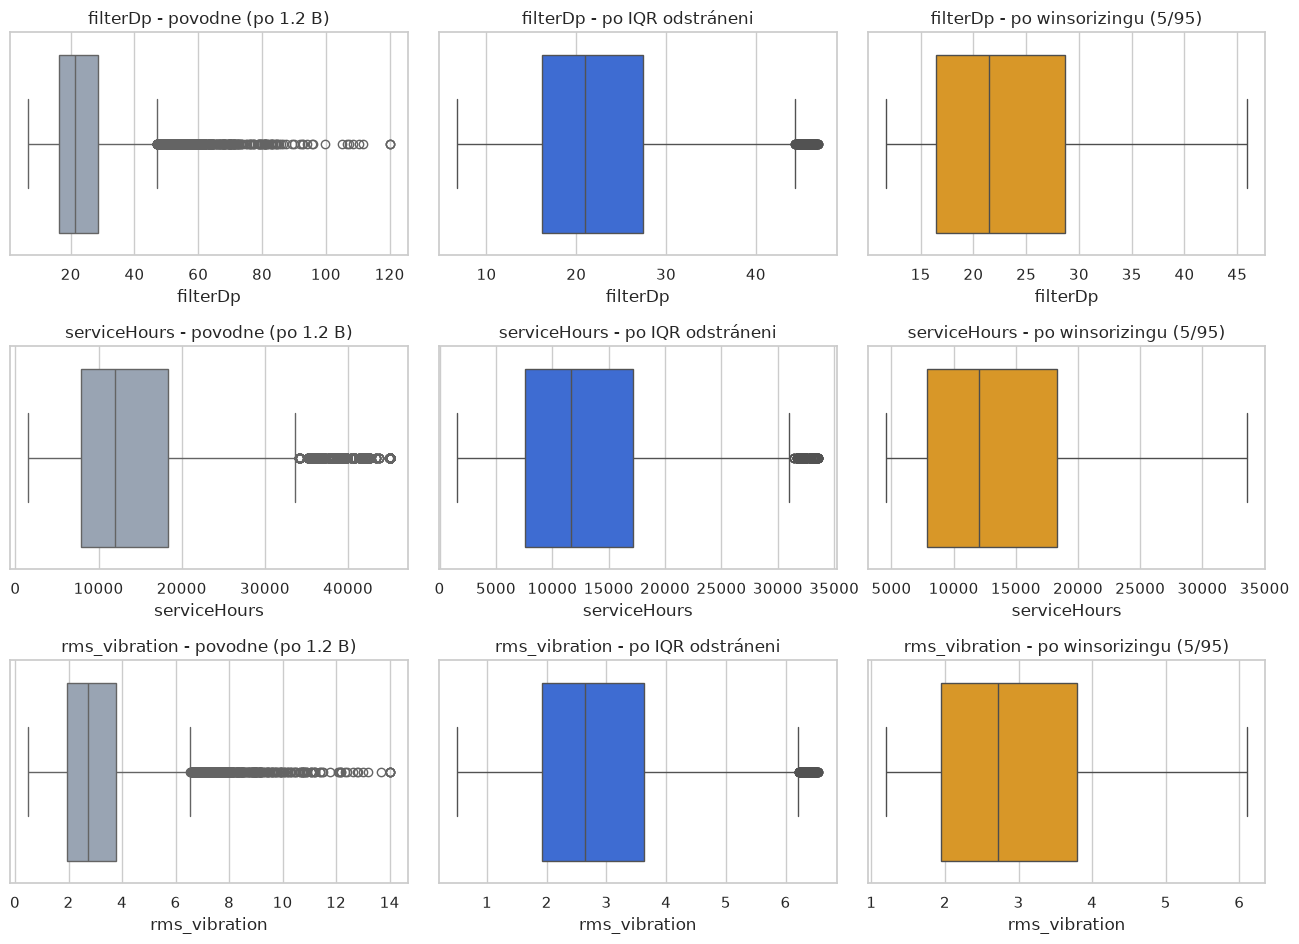

,povodny_priemer,IQR_priemer,winsor_priemer,povodny_std,IQR_std,winsor_std
currentMotor,5.269,5.271,5.266,1.831,1.834,1.748
filterDp,24.147,22.523,23.645,11.304,8.286,9.356
oilTemperature,54.974,54.993,54.968,12.037,11.722,10.996
rms_vibration,3.064,2.864,3.000,1.593,1.247,1.352
Flowmeter,27.961,27.937,27.965,4.003,3.903,3.657
dewpointDischarge,8.044,8.002,8.038,3.532,3.428,3.230
serviceHours,14302.322,12957.781,14024.221,8888.268,6737.675,7906.280


In [34]:
#1.2 C: Porovnanie efektu oboch technik

compare_cols = ["filterDp", "serviceHours", "rms_vibration"]
fig, axes = plt.subplots(len(compare_cols), 3, figsize=(13, 3.2 * len(compare_cols)))

for row, col in enumerate(compare_cols):
    sns.boxplot(x=df_clean[col].dropna(), ax=axes[row, 0], color="#94a3b8")
    axes[row, 0].set_title(f"{col} - povodne (po 1.2 B)")
    sns.boxplot(x=df_iqr[col].dropna(), ax=axes[row, 1], color="#2563eb")
    axes[row, 1].set_title(f"{col} - po IQR odstráneni")
    sns.boxplot(x=df_winsor[col].dropna(), ax=axes[row, 2], color="#f59e0b")
    axes[row, 2].set_title(f"{col} - po winsorizingu (5/95)")

plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "povodny_priemer": df_clean[outlier_cols].mean(),
    "IQR_priemer": df_iqr[outlier_cols].mean(),
    "winsor_priemer": df_winsor[outlier_cols].mean(),
    "povodny_std": df_clean[outlier_cols].std(),
    "IQR_std": df_iqr[outlier_cols].std(),
    "winsor_std": df_winsor[outlier_cols].std(),
}).round(3)
display(summary)


**Zhrnutie riešenia outlierov (1.2 C):**

Vyskúšali sme dve techniky na siedmich číselných atribútoch (`currentMotor`, `filterDp`, `oilTemperature`, `rms_vibration`, `Flowmeter`, `dewpointDischarge`, `serviceHours`):

1. **Odstránenie vychýlených pozorovaní (IQR, 1.5xIQR):** pri spoločnom uplatnení na 7 atribútov sa záznamy kumulujú, odstránených je 2 030 z 14 456 riadkov (14,04%).
2. **Winsorizácia na 5. a 95. percentile:** zachová všetky riadky, ale oreže približne 10% platných hodnôt v každom zo sledovaných atribútov. Nie je to neutrálna operácia a môže obmedziť aj reálne extrémne hodnoty.

**Dôležité zistenie:** `failure = 1` tvorí približne 12% meraní. Po IQR odstránení počet pozitívnych prípadov klesá z 1 754 na 1 367 (pokles o 387 prípadov, teda 22,1%). Hoci riadkov ubudne 14,04%, podiel `failure = 1` medzi zostávajúcimi riadkami je približne 11,0% oproti pôvodným 12,1% . To naznačuje, že odľahlé hodnoty môžu niesť informáciu o poruche. Nepreukazuje to však, že každý outlier je reálny ani že každý outlier treba zachovať.

**Predbežný záver:** pre ďalšie fázy je rozumné neodstraňovať plošne celé riadky iba na základe IQR, pretože sa tým mení zastúpenie cieľovej triedy. `df_winsor` zostáva jednou z možností na porovnanie, nie definitívne rozhodnutie: winsorizácia na 5/95 mení veľa hodnôt a vhodnosť treba posúdiť na základe doménovej validity a neskoršieho výkonu modelu. V tejto fáze ešte nevyberáme finálnu pipeline.


## 1.3 Formulácia a štatistické overenie hypotéz o dátach (5b)

### 1.3 A - Formulácia a overenie dvoch hypotéz (4b)
Sformulujte **dve hypotézy** o dátach v kontexte predikčnej úlohy a overte ich vhodne zvoleným štatistickým testom.

Príklad formulovania: *„flowmeter má v priemere vyššiu hodnotu v stave s failure ako bez nej."*

**Hypotéza 1:** 

Cieľom tejto časti je formulovať dve hypotézy súvisiace s predikciou premennej `failure` a overiť ich pomocou vhodných štatistických testov. Zameriame sa na vzťah medzi prevádzkovými hodinami APU jednotiek a výskytom poruchy a na vzťah medzi tlakovou stratou na filtri (`filterDp`) a stavom poruchy.

Pri testovaní použijeme hladinu štatistickej významnosti a = 0.05. Okrem p-hodnoty vyhodnotíme aj veľkosť efektu a interval spoľahlivosti, aby sme neposudzovali výsledky iba na základe štatistickej významnosti.

**Výskumná hypotéza H1:** APU jednotky, pri ktorých bolo v sledovanom období zaznamenané aspoň jedno `failure = 1`, majú vyšší priemerný počet `serviceHours` než jednotky, pri ktorých sa porucha nezaznamenala.

- **Nulová hypotéza (H0):** Priemerné `serviceHours` jednotiek so zaznamenaným zlyhaním nie sú vyššie než pri jednotkách bez zaznamenaného zlyhania.
- **Alternatívna hypotéza (H1):** Priemerné `serviceHours` jednotiek so zaznamenaným zlyhaním sú vyššie.
- **Hladina významnosti:** a = 0.05.
- **Štatistický test:** Jednostranný Welchov t-test pre dva nezávislé výbery (kontrola: Mann-Whitneyho test).

Keďže jeden riadok v dátach predstavuje jedno meranie a rovnaká jednotka môže mať viac meraní, najprv vytvoríme jednu sumarizáciu pre každú `id_unit`. Prevádzkové hodiny zhrnieme mediánom a výskyt poruchy určíme maximálnou hodnotou premennej `failure`. Hodnota 1 teda znamená, že sa pri danej jednotke počas sledovaného obdobia zaznamenalo aspoň jedno zlyhanie.

Welchov t-test je vhodný na porovnanie priemerov dvoch nezávislých skupín bez predpokladu rovnosti ich rozptylov. Jednotky s chýbajúcou hodnotou `serviceHours` do testu nezaradíme.

**Výber testu:** Shapiro-Wilkov test normalitu `serviceHours` zamietne, no pri stovkách jednotiek v každej skupine je Welchov t-test voči miernej nenormalite robustný (centrálna limitná veta). Neparametrický Mann-Whitneyho test slúži ako kontrola - ak by oba testy dali opačný záver, výsledku by sme neverili.


Pre H₁ vytvárame jeden riadok na jednotku (medián `serviceHours`, `failure` = max) a delíme jednotky na dve skupiny.

In [35]:
#1.3 A: Hypoteza 1 - priprava dat

#jedno pozorovanie - jedna APU jednotka
h1_units = (
    df_clean.groupby("id_unit", as_index=False)
    .agg(serviceHours=("serviceHours", "median"), unit_failure=("failure", "max"))
    .dropna(subset=["serviceHours", "unit_failure"])
)

# Rozdelenie jednotiek do dvoch skupín
hours_no_failure = h1_units.loc[
    h1_units["unit_failure"] == 0, "serviceHours"
]

hours_failure = h1_units.loc[
    h1_units["unit_failure"] == 1, "serviceHours"
]

print("Počet jednotiek bez failure:", len(hours_no_failure))
print("Počet jednotiek s failure:", len(hours_failure))

Počet jednotiek bez failure: 862
Počet jednotiek s failure: 1037


Histogramy `serviceHours` v oboch skupinách, Shapiro-Wilkov test normality a Leveneho test rovnosti rozptylov (iba informatívne).

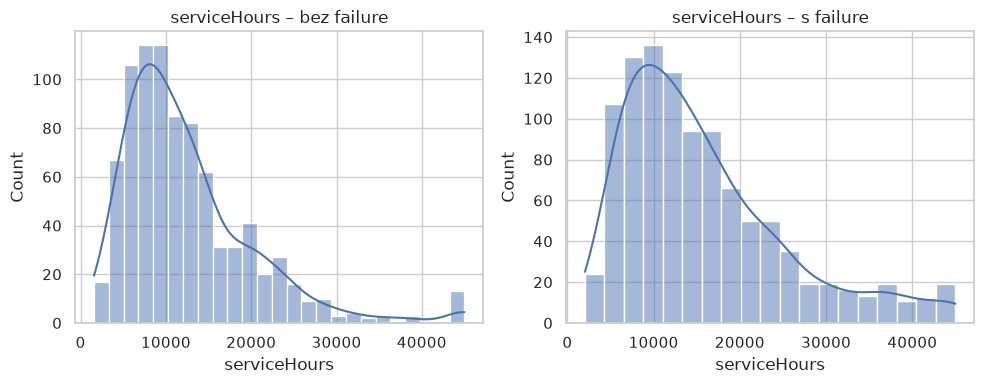

Shapiro-Wilk - bez failure: ShapiroResult(statistic=np.float64(0.8578293700187571), pvalue=np.float64(3.544072215772963e-27))
Shapiro-Wilk - s failure: ShapiroResult(statistic=np.float64(0.8924989866051708), pvalue=np.float64(2.840147108538566e-26))
Ine rozdelenie (reject H0)

Leveneho test: LeveneResult(statistic=np.float64(29.359638156179273), pvalue=np.float64(6.778256485919228e-08))
Rozdielne rozptyly (reject H0)


In [36]:
#porovnanie distribucii a kontrola normality
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(hours_no_failure, kde=True, ax=axes[0])
axes[0].set_title("serviceHours – bez failure")

sns.histplot(hours_failure, kde=True, ax=axes[1])
axes[1].set_title("serviceHours – s failure")

plt.tight_layout()
plt.show()

#Shapiro-Wilk test normality
shapiro_no_failure = stats.shapiro(hours_no_failure)
shapiro_failure = stats.shapiro(hours_failure)

print("Shapiro-Wilk - bez failure:",
      shapiro_no_failure)

print("Shapiro-Wilk - s failure:",
      shapiro_failure)

#interpretacia normality (alpha = 0.05)
alpha = 0.05
if shapiro_no_failure.pvalue > alpha and shapiro_failure.pvalue > alpha:
    print("Normalne rozdelenie (fail to reject H0)")
else:
    print("Ine rozdelenie (reject H0)")

#Leveneho test rovnosti rozptylov
levene_test = stats.levene(hours_failure, hours_no_failure)
print("\nLeveneho test:", levene_test)

#interpretacia rovnosti rozptylov (alpha = 0.05)
if levene_test.pvalue > alpha:
    print("Rovnake rozptyly (fail to reject H0)")
else:
    print("Rozdielne rozptyly (reject H0)")


Leveneho test potvrdzuje nerovnosť rozptylov (p ≈ 6,8×10⁻⁸), preto používame Welchov (nie Studentov) t-test. Ďalej: jednostranný Welchov t-test, kontrolný Mann-Whitneyho test, 95% interval spoľahlivosti rozdielu priemerov a Cohenovo d.

In [37]:
#h1: jednostranny welchov t-test (serviceHours: jednotky s failure > jednotky bez failure)
alpha = 0.05

n1, n0 = len(hours_failure), len(hours_no_failure)
m1, m0 = hours_failure.mean(), hours_no_failure.mean()
v1, v0 = hours_failure.var(ddof=1), hours_no_failure.var(ddof=1)

h1_test = stats.ttest_ind(hours_failure, hours_no_failure, equal_var=False, alternative="greater")

#95% interval spolahlivosti rozdielu priemerov (welch-satterthwaite)
h1_diff = m1 - m0
h1_se = np.sqrt(v1 / n1 + v0 / n0)
h1_df = h1_se**4 / ((v1 / n1)**2 / (n1 - 1) + (v0 / n0)**2 / (n0 - 1))
h1_t_crit = stats.t.ppf(0.975, h1_df)
h1_ci = (h1_diff - h1_t_crit * h1_se, h1_diff + h1_t_crit * h1_se)

#velkost efektu: cohenovo d (spolocna smerodajna odchylka)
h1_pooled_sd = np.sqrt(((n1 - 1) * v1 + (n0 - 1) * v0) / (n1 + n0 - 2))
h1_cohens_d = h1_diff / h1_pooled_sd

#kontrola robustnosti: neparametricky mann-whitneyho test
h1_mw = stats.mannwhitneyu(hours_failure, hours_no_failure, alternative="greater")

print(f"priemer serviceHours: s failure {m1:.0f} h, bez failure {m0:.0f} h (rozdiel {h1_diff:.0f} h)")
print(f"95 % interval spolahlivosti rozdielu: ({h1_ci[0]:.0f}, {h1_ci[1]:.0f}) h")
print(f"welchov t-test: t = {h1_test.statistic:.2f}, p = {h1_test.pvalue:.2e}")
print(f"mann-whitney (kontrola): p = {h1_mw.pvalue:.2e}")
print(f"cohenovo d = {h1_cohens_d:.3f}")
print("vysledok: zamietame h0 (alfa = 0.05)" if h1_test.pvalue < alpha else "vysledok: h0 nezamietame (alfa = 0.05)")


priemer serviceHours: s failure 15797 h, bez failure 12530 h (rozdiel 3267 h)
95 % interval spolahlivosti rozdielu: (2487, 4047) h
welchov t-test: t = 8.22, p = 1.89e-16
mann-whitney (kontrola): p = 4.19e-16
cohenovo d = 0.372
vysledok: zamietame h0 (alfa = 0.05)


**Hypotéza 2:** 

**Výskumná hypotéza H2:** Pri tej istej APU jednotke má `filterDp` v priemere vyššiu hodnotu pri meraniach s `failure = 1` než pri meraniach s `failure = 0`.

- **Nulová hypotéza (H0):** Priemerný rozdiel `filterDp` medzi stavom s poruchou a bez poruchy nie je kladný.
- **Alternatívna hypotéza (Ha):** Priemerný rozdiel je kladný.
- **Hladina významnosti:** a = 0.05.
- **Štatistický test:** Jednostranný párový t-test (kontrola: Wilcoxonov párový test).

Pre každú jednotku vypočítame priemernú hodnotu `filterDp` osobitne pre stav `failure = 0` a `failure = 1`. Do testu zaradíme iba jednotky, pre ktoré máme platné merania v oboch stavoch. Takýto prístup zohľadňuje opakované merania tej istej jednotky a obmedzuje vplyv rozdielov medzi samotnými jednotkami. Pred testom vypočítame rozdiel medzi priemernými hodnotami v oboch stavoch.

**Výber testu:** Shapiro-Wilkov test normalitu rozdielov zamietne, ale pri ~900 pároch je párový t-test robustný (centrálna limitná veta). Wilcoxonov test slúži ako kontrola.

Výsledok môže poukazovať na súvislosť medzi tlakovou stratou na filtri a stavom poruchy, sám osebe však nedokazuje, že zvýšený `filterDp` poruchu spôsobuje ani že ju dokáže predvídať v predstihu.


Pre H2 priemerujeme `filterDp` osobitne pre `failure` = 0 a 1 u každej jednotky a ponechávame jednotky s oboma stavmi. Keďže `filterDp` mimo pracovného rozsahu sme v 1.2 B nenahradili `NaN` (len označili stĺpcom `filterDp_suspicious`), vstupujú do tohto priemeru aj tieto extrémne hodnoty - zámerne, keďže môžu niesť informáciu o poruche.

In [38]:
#hypoteza 2: filterDp a failure

filter_by_state = (
    df_clean.groupby(["id_unit", "failure"])["filterDp"]
    .mean()
    .unstack("failure")
)

#ponechame iba jednotky s meraniami v oboch stavoch
filter_pairs = filter_by_state[[0, 1]].dropna().copy()

filter_pairs.columns = [
    "filterDp_no_failure",
    "filterDp_failure"
]

#rozdiel: hodnota pri failure minus hodnota bez failure
filter_difference = (
    filter_pairs["filterDp_failure"]
    - filter_pairs["filterDp_no_failure"]
)

print("Pocet jednotiek s oboma stavmi:", len(filter_pairs))
display(filter_pairs.head())

Pocet jednotiek s oboma stavmi: 953


,filterDp_no_failure,filterDp_failure
id_unit,,
1,30.539287,34.213240
3,26.665737,25.290277
5,21.477677,27.669535
9,23.560707,51.177495
13,21.735875,23.075905


Histogram párových rozdielov `filterDp` a Shapiro-Wilkov test ich normality (iba informatívne).

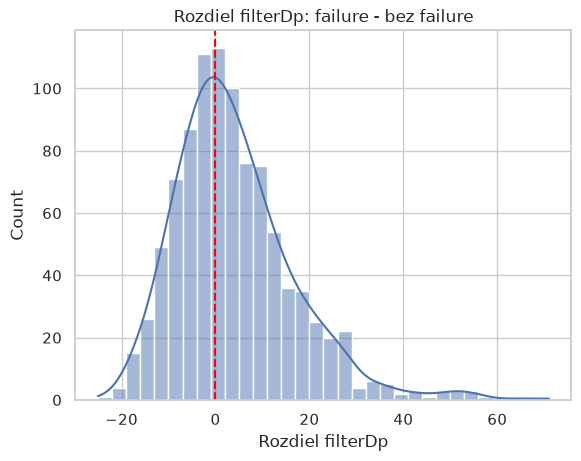

Shapiro-Wilk test rozdielov: ShapiroResult(statistic=np.float64(0.9378818116025647), pvalue=np.float64(1.660614485634293e-19))


In [39]:
#vizualizacia rozdielov medzi oboma stavmi
sns.histplot(filter_difference, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.title("Rozdiel filterDp: failure - bez failure")
plt.xlabel("Rozdiel filterDp")
plt.show()

#pri parovom teste kontrolujeme normalitu rozdielov, nie normalitu každej skupiny samostatne
if len(filter_difference) < 3:
    raise ValueError("Na kontrolu normality treba aspon tri parové pozorovania")

shapiro_difference = stats.shapiro(filter_difference)

print("Shapiro-Wilk test rozdielov:", shapiro_difference)

Rovnaký test (filterDp) je na cvičení ukázaný len pre nezávislé výbery (`ttest_ind`/`mannwhitneyu`), my ale meriame filterDp opakovane na tej istej jednotke (v stave bez aj so zlyhaním) - tieto merania nie sú nezávislé, preto použijeme párový dizajn namiesto nezávislých výberov z cvičenia. Párovanie odstraňuje medzi-jednotkovú variabilitu a priamo odpovedá na otázku, či filterDp v rámci tej istej jednotky stúpa počas zlyhania. Ďalej: jednostranný párový t-test, kontrolný Wilcoxonov test, 95% interval spoľahlivosti rozdielu a Cohenovo dz.

In [40]:
#h2: jednostranny parovy t-test (filterDp: pri failure > bez failure)
h2_n = len(filter_difference)
h2_diff = filter_difference.mean()
h2_sd = filter_difference.std(ddof=1)
h2_se = h2_sd / np.sqrt(h2_n)

h2_test = stats.ttest_rel(filter_pairs["filterDp_failure"], filter_pairs["filterDp_no_failure"], alternative="greater")

#95% interval spolahlivosti priemerneho rozdielu
h2_t_crit = stats.t.ppf(0.975, h2_n - 1)
h2_ci = (h2_diff - h2_t_crit * h2_se, h2_diff + h2_t_crit * h2_se)

#velkost efektu: cohenovo dz
h2_cohens_dz = h2_diff / h2_sd

#kontrola robustnosti: neparametricky wilcoxonov test na parovych rozdieloch
h2_wil = stats.wilcoxon(filter_difference, alternative="greater")

print(f"priemerny rozdiel filterDp (failure - bez failure): {h2_diff:.2f}")
print(f"95 % interval spolahlivosti rozdielu: ({h2_ci[0]:.2f}, {h2_ci[1]:.2f})")
print(f"parovy t-test: t = {h2_test.statistic:.2f}, p = {h2_test.pvalue:.2e}")
print(f"wilcoxon (kontrola): p = {h2_wil.pvalue:.2e}")
print(f"cohenovo dz = {h2_cohens_dz:.3f}")
print("vysledok: zamietame h0 (alfa = 0.05)" if h2_test.pvalue < alpha else "vysledok: h0 nezamietame (alfa = 0.05)")


priemerny rozdiel filterDp (failure - bez failure): 4.06
95 % interval spolahlivosti rozdielu: (3.24, 4.87)
parovy t-test: t = 9.77, p = 7.61e-22
wilcoxon (kontrola): p = 7.91e-15
cohenovo dz = 0.316
vysledok: zamietame h0 (alfa = 0.05)


### 1.3 B - Overenie štatistickej sily testov (1b)
Overte, či majú vaše štatistické testy dostatok podpory z dát (dostatočne silnú **štatistickú silu / power analysis**, napr. pomocou `statsmodels.stats.power`).

Silu testov vypočítame cez `statsmodels.stats.power`, rovnako ako na cvičení (`week-04/IAU_01_EDA-statistical-analysis.ipynb`, `week-04/IAU_02_EDA-statistical-power.ipynb`). H1 (nezávislé výbery): `tt_ind_solve_power` s Cohenovým d a pomerom veľkostí skupín. H2 (párový test): použijeme `TTestPower` aplikovaný na párové rozdiely a Cohenovo dz. Mann–Whitneyho a Wilcoxonov test sú len kontroly robustnosti, ich silu nepočítame.

**Metodické obmedzenie H1:** samotnú hypotézu testujeme Welchovým t-testom, ktorý nevyžaduje rovnaké rozptyly, zatiaľ čo `tt_ind_solve_power` je štandardná aproximácia pre klasický dvojvýberový t-test. Uvedená sila a minimálny detekovateľný efekt pre H1 sa preto interpretujú orientačne, nie ako presný výpočet sily Welchovho testu. Pre H2 je `TTestPower` jednovýberový ekvivalent aplikovaný na párové rozdiely, čo zodpovedá použitému párovému dizajnu.

**Všeobecné obmedzenie:** sila založená na pozorovanom efekte môže byť optimistická, preto uvádzame aj minimálny detekovateľný efekt pri sile 0,80. Vysoká vypočítaná sila neznamená, že by sme vždy zachytili aj menšie efekty alebo že sú dáta reprezentatívne.

Korekciu na viacnásobné testovanie neuvádzame, obe p-hodnoty sú výrazne pod konzervatívnou Bonferroniho hranicou a/2 = 0.025.

Vypočítame silu a minimálny detekovateľný efekt pre obe hypotézy pomocou `statsmodels.stats.power`.

In [41]:
#1.3 B: vypocet sily testu pomocou statsmodels.stats.power (ako na cviceni)
import statsmodels.stats.power as sm_power

#H1: nezavisle vybery - tt_ind_solve_power (rovnaky vzor ako week-04/IAU_01, IAU_02)
h1_power = sm_power.tt_ind_solve_power(
    effect_size=h1_cohens_d, nobs1=n1, alpha=0.05, power=None, ratio=n0 / n1, alternative="larger"
)
h1_min_effect = sm_power.tt_ind_solve_power(
    effect_size=None, nobs1=n1, alpha=0.05, power=0.80, ratio=n0 / n1, alternative="larger"
)

#H2: parovy test - TTestPower (jednovyberovy ekvivalent, aplikovany na parove rozdiely filterDp)
h2_power = sm_power.TTestPower().power(effect_size=h2_cohens_dz, nobs=h2_n, alpha=0.05, alternative="larger")
h2_min_effect = sm_power.TTestPower().solve_power(nobs=h2_n, alpha=0.05, power=0.80, alternative="larger")


print(f"H1: sila testu = {h1_power:.4f}, minimalny detekovatelny efekt (sila 0.8) d = {h1_min_effect:.3f}")
print(f"H2: sila testu = {h2_power:.4f}, minimalny detekovatelny efekt (sila 0.8) dz = {h2_min_effect:.3f}")

H1: sila testu = 1.0000, minimalny detekovatelny efekt (sila 0.8) d = 0.115
H2: sila testu = 1.0000, minimalny detekovatelny efekt (sila 0.8) dz = 0.081


Tabuľka s veľkosťou efektu, p-hodnotou, silou testu a minimálnym detekovateľným efektom pre obe hypotézy.

In [42]:
#suhrn: velkost efektu, p-hodnota, sila a minimalny detekovatelny efekt
power_summary = pd.DataFrame({
    "hypoteza": ["H1 - serviceHours", "H2 - filterDp"],
    "velkost_efektu": [h1_cohens_d, h2_cohens_dz],
    "p_hodnota": [f"{h1_test.pvalue:.2e}", f"{h2_test.pvalue:.2e}"],
    "sila": [h1_power, h2_power],
    "min_detekovatelny_efekt": [h1_min_effect, h2_min_effect],
})
display(power_summary.round(3))

for name, power in zip(power_summary["hypoteza"], power_summary["sila"]):
    verdikt = "dostatocna (>= 0.80)" if power >= 0.80 else "nedostatocna (< 0.80)"
    print(f"{name}: sila {power:.3f} - {verdikt}")


,hypoteza,velkost_efektu,p_hodnota,sila,min_detekovatelny_efekt
0,H1 - serviceHours,0.372,1.89e-16,1.0,0.115
1,H2 - filterDp,0.316,7.61e-22,1.0,0.081


H1 - serviceHours: sila 1.000 - dostatocna (>= 0.80)
H2 - filterDp: sila 1.000 - dostatocna (>= 0.80)


**Interpretácia 1.3:** Výsledky oboch testov poskytujú štatistický dôkaz proti príslušným nulovým hypotézam na hladine a = 0.05. Na úrovni APU jednotiek majú jednotky so zaznamenaným zlyhaním priemerne približne o 3 267 h vyššie `serviceHours` (95% IS približne 2 487–4 047 h, Welchov test p = 1.9x10^-16). V párovom porovnaní je `filterDp` pri meraniach s `failure = 1` priemerne vyšší približne o 4.06 (95% IS približne 3.24–4.87, p = 7.6x10^-22). Rozdiel vychádza z finálnej politiky čistenia v 1.2 B, pri ktorej sa `filterDp` mimo predbežného rozsahu nenahrádza `NaN`, ale zachováva sa a označuje príznakom. Neparametrické kontrolné testy dávajú rovnaký smer záveru. Výsledky ukazujú asociáciu, nie príčinnosť.

Veľkosti efektov sú skôr malé (Cohenovo d = 0.37, dz = 0.32), preto štatistická významnosť sama osebe neznamená, že jednotlivý atribút bude dobrým prediktorom. Deskriptívny rozdiel `serviceHours` v 1.1 D (~3 518 h) vychádza z meraní, kým H1 v 1.3 používa jeden súhrnný záznam na jednotku, obe čísla preto nemusia byť rovnaké.

**Štatistická sila:** pri pozorovaných veľkostiach efektu vychádza veľmi vysoko (v tabuľke sa zaokrúhľuje na 1,00) a minimálny detekovateľný efekt je podstatne menší než pozorovaný efekt. Pre H1 ide o orientačnú aproximáciu, pretože výpočet `tt_ind_solve_power` predpokladá klasický dvojvýberový t-test, zatiaľ čo hypotézu testujeme Welchovým testom. Výsledok nevylučuje malé efekty ani obmedzenia reprezentatívnosti dát.

## Zhrnutie Fázy 1 – odpovede na kľúčové otázky

**Majú dáta vhodný formát pre ďalšie spracovanie?**

Nie priamo. Dáta sú v troch súboroch s rôznymi oddeľovačmi a formátmi kľúčov. `failure` a prediktory sú v rôznych súboroch a časť atribútov je textová. Po integrácii a prvotnom čistení vzniká `df_clean` (14 456 riadkov), kde jeden riadok predstavuje jedno meranie. Kategorické atribúty `class_duty`, `codeModel`, `fleetCode` a tiež `install_region` treba pred strojovým učením vyhodnotiť a podľa rozhodnutia zakódovať.

**Aké problémy sa v dátach vyskytujú a ako ich riešime?**

- 220 úplných duplicít. Po ich odstránení sa našli skupiny s rovnakým `(id_unit, cycle_ts)` a rozdielnymi záznamami, ďalšie duplicitné kľúče sa odhalili po normalizácii formátu ID a dátumu. Po normalizácii kľúčov sa zistilo 11 skupín s konfliktným `failure`. Pravidlo `max` zmenilo 11 pôvodných riadkov s nulovým štítkom na pozitívny výsledný štítok skupiny. Pravidlo môže zvýšiť počet pozitívnych prípadov, preto tento konflikt uvádzame explicitne.
- Rôzne formáty dátumov a `id_unit` ako `"U00255"` vs. `255` sú normalizované pred integráciou.
- 140 meraní (117 jednotiek) bez záznamu v `units` sa z integrovanej sady vyradilo, pretože im chýbajú kľúčové atribúty jednotky.
- Chýbajúce hodnoty zostávajú zatiaľ ako `NaN`, imputáciu treba robiť až v neskoršej fáze na základe tréningových dát.
- Pri `gateways` má 1 531 z 16 000 brán dátum inštalácie po 31. 12. 2023, hoci `readings` pokrýva rok 2023. Agregovaný `mean_signal_dbm` podľa depa môže preto zahŕňať informáciu z obdobia po meraní. Pred použitím v prediktívnom modeli treba overiť časovú dostupnosť atribútu a zabrániť úniku informácií z budúcnosti.
- Ako outlier techniky sme vyskúšali IQR odstránenie (14,04% riadkov, pričom počet `failure = 1` klesol z 1 754 na 1 367, teda o 22,1%) a winsorizáciu 5/95 (riadky zachová, ale oreže približne 10% platných hodnôt z každého sledovaného atribútu). Winsorizácia je kandidát na porovnanie, nie finálne rozhodnutie.

**Nadobúdajú niektoré atribúty nekonzistentné hodnoty?**

Áno. `class_duty` má 20 pôvodných zápisov mapovaných na tri kategórie. `oilTemperature = -999` sa považuje za zjavný chybový kód. `currentMotor` až do 99 a `filterDp` až do 120 sú mimo pracovných, predbežne odhadnutých rozsahov. Tieto hranice nepochádzajú z potvrdenej špecifikácie, preto ide o pracovné čistenie, ktoré si vyžaduje overenie. Pred nahradením hodnôt mimo rozsahu `NaN` sa porovnáva aj ich miera `failure` s hodnotami v rozsahu, u `filterDp` to na základe tejto diagnostiky vedie k rozhodnutiu hodnoty nenahrádzať, len označiť (`filterDp_suspicious`), keďže môžu niesť informáciu o poruche.

**Čo sme zistili o predikcii `failure`?**

Na úrovni prieskumnej analýzy sa medzi numerickými atribútmi najviac oplatí ďalej sledovať `serviceHours` a `filterDp`. `class_duty` je relevantný kandidát a jeho kategórie sú teraz zjednotené aj v párovej analýze. Slabé párové korelácie neznamenajú preukázanú nezávislosť atribútov ani to, že nemajú spoločnú predikčnú hodnotu. Obe štatistické hypotézy poskytli dôkaz proti nulovým hypotézam, ale veľkosti efektov sú skôr malé a výsledky nedokazujú príčinnosť.

**Percentuálny podiel práce (Fáza 1):** Samuel Ivan = 50%, Juraj Krátky = 50%


# Fáza 2 - Predspracovanie údajov: 15 bodov
Cieľom je pripraviť dátovú sadu (csv/tsv), kde jedno pozorovanie = jeden riadok, všetky atribúty numerické (scikit-learn vyžaduje numerické dáta), a zabezpečiť **replikovateľnosť** predspracovania na trénovacej aj testovacej množine. Ak predspracovanie zmenilo tvar/charakteristiky dát, podľa potreby zopakujte časti EDA (nebodujeme znovu, ale dokumentujte zmeny).

## 2.1 Realizácia predspracovania dát (5b)

### 2.1 A - Train/test split (1b)
Rozdeľte dáta na trénovaciu a testovaciu množinu podľa vami zvoleného pomeru. **Ďalej pracujte len s trénovacím datasetom** (testovací odložte bokom pre časť 2.3).

Zostavíme funkciu, ktorá reprodukuje čistenie a integráciu z Fázy 1 priamo zo surových súborov (`readings`, `units`, `gateways`) - zjednotenie formátov, duplicity, mapovanie `class_duty`, spojenie tabuliek, orezanie podľa pevných rozsahov z 1.1 B. Tieto kroky sú nezávislé od štatistík z dát, takže je bezpečné spustiť ich pred rozdelením na train/test. Imputáciu a škálovanie odkladáme až po splite a počítame len z `df_train` (2.1 B/C).

In [43]:
#2.1 A: funkcia reprodukuje integraciu/cistenie z fazy 1 - len deterministicke kroky, preto bezpecne bezi pred splitom
#imputacia a skalovanie (zavisle od statistik) su az po splite, len na train

def build_integrated_dataset(readings_raw, units_raw, gateways_raw,
                              class_duty_map = class_duty_map, expected_ranges = expected_ranges):
    #1. uplne duplicity a konfliktne zaznamy v readings (zhodne s 1.2 A)
    readings_clean = readings_raw.drop_duplicates().copy()
    agg_dict = {c: "mean" for c in readings_clean.select_dtypes("number").columns if c != "failure"}
    agg_dict["failure"] = "max"
    readings_clean = readings_clean.groupby(["id_unit", "cycle_ts"], as_index = False).agg(agg_dict)

    #2. zjednotenie formatu datumov a id_unit - retazec "U00255" -> cislo
    readings_clean["cycle_ts"] = pd.to_datetime(readings_clean["cycle_ts"], format = "mixed", dayfirst = False)
    readings_clean["id_unit"] = readings_clean["id_unit"].str.extract(r"(\d+)").astype(int)
    if readings_clean.duplicated(subset = ["id_unit", "cycle_ts"]).sum() > 0:
        readings_clean = readings_clean.groupby(["id_unit", "cycle_ts"], as_index=False).agg(agg_dict)

    gateways_clean = gateways_raw.copy()
    gateways_clean["install_date"] = pd.to_datetime(gateways_clean["install_date"], format="mixed", dayfirst=False)

    #3. zjednotenie 20 zapisov class_duty na 3 kanonicke kategorie
    units_clean = units_raw.copy()
    units_clean["class_duty"] = units_clean["class_duty"].astype(str).str.strip().str.lower().map(class_duty_map)

    #4. vyradenie merani bez zodpovedajucej jednotky v units (chybaju im klucove prediktory)
    orphan_mask = ~readings_clean["id_unit"].isin(units_clean["id_unit"])
    readings_valid = readings_clean.loc[~orphan_mask].copy()

    #5. agregacia bran na uroven depa a spojenie vsetkych troch tabuliek
    gateway_by_depot = (gateways_clean.groupby("id_depot", as_index=False)
        .agg(mean_signal_dbm = ("signal_dbm", "mean"), median_signal_dbm = ("signal_dbm", "median"))
    )
    df = (readings_valid.merge(units_clean, on = "id_unit", how = "left", validate = "many_to_one")
        .merge(gateway_by_depot, on = "id_depot", how = "left", validate = "many_to_one")
    )

    #6. filterDp mimo rozsahu len oznacujeme (moze byt realny signal poruchy), nemazeme
    filterDp_lo, filterDp_hi = expected_ranges["filterDp"]
    df["filterDp_suspicious"] = (~df["filterDp"].between(filterDp_lo, filterDp_hi) & df["filterDp"].notna()).astype(int)
    df.loc[df["filterDp"] < 0, "filterDp"] = np.nan

    #7. ostatne atributy mimo fyzikalneho rozsahu = chyba senzora -> NaN rovnako ako 1.2 B
    for col, (lo, hi) in expected_ranges.items():
        if col not in df.columns or col == "filterDp":
            continue
        out_of_range = ~df[col].between(lo, hi) & df[col].notna()
        df.loc[out_of_range, col] = np.nan

    return df

df_integrated = build_integrated_dataset(readings, units, gateways)

#kontrola reprodukovatelnosti - funkcia zo surovych dat musi dat ten isty tvar aj rovnaky pocet
#chybajucich hodnot ako df_clean, s ktorym sme pracovali vo faze 1
print(f"df_integrated: {df_integrated.shape}, df_clean (Faza 1): {df_clean.shape}")
shared_cols = [c for c in df_integrated.columns if c in df_clean.columns]
same_missing = (df_integrated[shared_cols].isna().sum() == df_clean[shared_cols].isna().sum()).all()
print(f"rovnaky tvar ako df_clean: {df_integrated.shape == df_clean.shape}")
print(f"rovnaky pocet chybajucich hodnot v zdielanych stlpcoch: {same_missing}")


df_integrated: (14456, 19), df_clean (Faza 1): (14456, 19)
rovnaky tvar ako df_clean: True
rovnaky pocet chybajucich hodnot v zdielanych stlpcoch: True


Funkcia dáva rovnaký tvar aj počet chýbajúcich hodnôt ako `df_clean` z fázy 1 - integráciu vieme kedykoľvek zopakovať od nuly.
Teraz rozdelíme dáta na train/test.

In [44]:
#2.1 A: split podla id_unit, nie podla riadkov - jednotka ma ~7 korelovanych merani (1.1 A),
#nahodny split po riadkoch by pustil rovnaku jednotku do train aj test (group leakage, umelo vyssia test presnost)

from sklearn.model_selection import train_test_split

#jedna jednotka - jedno pozorovanie pre stratifikaciu (podla toho, ci mala aspon 1x failure)
unit_failure = df_integrated.groupby("id_unit")["failure"].max()

train_units, test_units = train_test_split(
    unit_failure.index,
    test_size = 0.2,
    random_state = 42,
    stratify = unit_failure.values,
)

df_train = df_integrated.loc[df_integrated["id_unit"].isin(train_units)].copy()
df_test = df_integrated.loc[df_integrated["id_unit"].isin(test_units)].copy()

print(f"jednotky: {len(train_units)} train / {len(test_units)} test ({len(test_units) / len(unit_failure):.1%} test)")
print(f"merania:  {len(df_train)} train / {len(df_test)} test ({len(df_test) / len(df_integrated):.1%} test)")
print(f"prekryv jednotiek medzi train a test: {len(set(train_units) & set(test_units))} (musi byt 0)")
print(f"miera failure (na urovni merania): train={df_train['failure'].mean():.3f}, test={df_test['failure'].mean():.3f}")


jednotky: 1598 train / 400 test (20.0% test)
merania:  11514 train / 2942 test (20.4% test)
prekryv jednotiek medzi train a test: 0 (musi byt 0)
miera failure (na urovni merania): train=0.122, test=0.120


Test obsahuje ~20% jednotiek aj meraní, bez prekryvu s train, a miera `failure` sa medzi množinami líši len o zlomok p.b. - stratifikácia podľa `failure` na jednotke zafungovala. Odtiaľto pracujeme **výlučne** s `df_train`. `df_test` sa znova použije až v 2.3 B.

### 2.1 B - Transformácia do formátu vhodného pre ML (1b)
Transformujte dáta tak, aby jedno pozorovanie bolo opísané jedným riadkom a každý atribút bol v numerickom formáte (napr. integrácia súborov, encoding kategorických premenných, parsovanie dátumov). Iteratívne integrujte aj kroky čistenia dát z fázy 1.

`df_train` prevádzame na jeden riadok = jedno meranie, všetko numerické. `id_unit`/`id_depot` sú len identifikátory (nie prediktory, `id_unit` ostáva ako index). `cycle_ts` prevedieme na počet dní od najstaršieho merania v train.

In [45]:
#2.1 B: cycle_ts - dni od min(cycle_ts) v train (fit len na train, pri replikacii na test v 2.3 sa pouzije ta ista konstanta, nie znova min() testu)
#id_unit/id_depot su identifikatory, nie namerane veliciny - id_unit ostava len ako index

df_train_ml = df_train.copy()
cycle_ts_reference = df_train_ml["cycle_ts"].min()
df_train_ml["cycle_ts_days"] = (df_train_ml["cycle_ts"] - cycle_ts_reference).dt.days
df_train_ml = df_train_ml.drop(columns=["cycle_ts", "id_depot"]).set_index("id_unit")

print(f"referencny datum (min cycle_ts v train): {cycle_ts_reference.date()}")
print(f"cycle_ts_days rozsah: {df_train_ml['cycle_ts_days'].min()} - {df_train_ml['cycle_ts_days'].max()} dni")
display(df_train_ml.head(3))


referencny datum (min cycle_ts v train): 2023-01-01
cycle_ts_days rozsah: 0 - 364 dni


,currentMotor,filterDp,oilTemperature,reservoir_pressure,rms_vibration,Flowmeter,dewpointDischarge,failure,serviceHours,class_duty,codeModel,install_region,fleetCode,mean_signal_dbm,median_signal_dbm,filterDp_suspicious,cycle_ts_days
id_unit,,,,,,,,,,,,,,,,,
2,5.68844,38.88359,52.83688,8.42006,1.95073,32.52970,1.90802,0,NaN,medium,XC-7,West Michaelborough,FB,-70.239655,-70.1,0,125
2,5.05886,32.11883,58.74046,7.81521,5.51997,29.01337,14.10151,0,NaN,medium,XC-7,West Michaelborough,FB,-70.239655,-70.1,0,267
2,7.66200,33.21775,83.35437,9.91336,1.72087,23.53479,16.05029,0,NaN,medium,XC-7,West Michaelborough,FB,-70.239655,-70.1,0,282


Kategorické atribúty kódujeme podľa typu: `class_duty` má poradie (light<medium<heavy) -> ordinálne kódovanie. `codeModel`/`fleetCode` sú nominálne s nízkou kardinalitou (4-5 kat.) -> one-hot. `install_region` by cez one-hot vytvoril 59 väčšinou prázdnych stĺpcov -> frekvenčné kódovanie (fit na train).

In [46]:
#2.1 B: kodovanie kategorickych atributov podla typu a kardinality
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

#class_duty je poradova (light < medium < heavy) -> ordinalne kodovanie zachova poradie
duty_encoder = OrdinalEncoder(categories = [["light", "medium", "heavy"]])
df_train_ml["class_duty_ord"] = duty_encoder.fit_transform(df_train_ml[["class_duty"]])

#codeModel (4 kat.) a fleetCode (5 kat.) su nominalne s nizkou kardinalitou -> one-hot
onehot_cols = ["codeModel", "fleetCode"]
onehot_encoder = OneHotEncoder(sparse_output=False, handle_unknown = "ignore", dtype=int)
onehot_array = onehot_encoder.fit_transform(df_train_ml[onehot_cols])
onehot_df = pd.DataFrame(
    onehot_array, columns=onehot_encoder.get_feature_names_out(onehot_cols), index=df_train_ml.index
)

#install_region: 59 hodnot -> frekvencne kodovanie namiesto one-hot (59 prazdnych stlpcov)
#frekvencie pocitane len na train
region_freq = df_train_ml["install_region"].value_counts()
df_train_ml["install_region_freq"] = df_train_ml["install_region"].map(region_freq)

df_train_ml = pd.concat(
    [df_train_ml.drop(columns=["class_duty"] + onehot_cols + ["install_region"]), onehot_df],
    axis=1,
)

print("tvar df_train_ml po kodovani:", df_train_ml.shape)
print("zostavajuce neciselne stlpce (mal by byt prazdny zoznam):",
      df_train_ml.select_dtypes(exclude="number").columns.tolist())


tvar df_train_ml po kodovani: (11514, 24)
zostavajuce neciselne stlpce (mal by byt prazdny zoznam): []


Pred škálovaním doplníme chýbajúce hodnoty (`currentMotor`, `filterDp`, `oilTemperature`, `rms_vibration`, `serviceHours` - zámerne ponechané ako `NaN` v 1.2 A/B). Použijeme medián, pretože viaceré atribúty sú zošikmené (z 1.1 B) a priemer by bol vychýlený extrémami. `SimpleImputer` fitujeme výlučne na `df_train`, na test sa len aplikuje transform - žiadna informácia z testu nesmie ovplyvniť trénovacie štatistiky.

In [47]:
#2.1 B: imputacia chybajucich hodnot medianom, fitnute vylucne na df_train (ziadny data leakage z testu)
from sklearn.impute import SimpleImputer

missing_cols = df_train_ml.columns[df_train_ml.isna().any()].tolist()
print("stlpce s chybajucimi hodnotami pred imputaciou:")
print(df_train_ml[missing_cols].isna().sum())

median_imputer = SimpleImputer(strategy = "median")
df_train_ml[missing_cols] = median_imputer.fit_transform(df_train_ml[missing_cols])

print("\nchybajuce hodnoty po imputacii (musi byt 0):", int(df_train_ml[missing_cols].isna().sum().sum()))
print("tvar df_train_ml:", df_train_ml.shape)
print("vsetky atributy numericke:", all(np.issubdtype(d, np.number) for d in df_train_ml.dtypes))
display(df_train_ml.head(3))


stlpce s chybajucimi hodnotami pred imputaciou:
currentMotor        8
filterDp          470
oilTemperature     33
rms_vibration     409
serviceHours      581
dtype: int64

chybajuce hodnoty po imputacii (musi byt 0): 0
tvar df_train_ml: (11514, 24)
vsetky atributy numericke: True


,currentMotor,filterDp,oilTemperature,reservoir_pressure,rms_vibration,Flowmeter,dewpointDischarge,failure,serviceHours,mean_signal_dbm,median_signal_dbm,filterDp_suspicious,cycle_ts_days,class_duty_ord,install_region_freq,codeModel_APU-12,codeModel_APU-15,codeModel_APU-20,codeModel_XC-7,fleetCode_FA,fleetCode_FB,fleetCode_FC,fleetCode_FD,fleetCode_FE
id_unit,,,,,,,,,,,,,,,,,,,,,,,,
2,5.68844,38.88359,52.83688,8.42006,1.95073,32.52970,1.90802,0,12162.8,-70.239655,-70.1,0,125,1.0,131,0,0,0,1,0,1,0,0,0
2,5.05886,32.11883,58.74046,7.81521,5.51997,29.01337,14.10151,0,12162.8,-70.239655,-70.1,0,267,1.0,131,0,0,0,1,0,1,0,0,0
2,7.66200,33.21775,83.35437,9.91336,1.72087,23.53479,16.05029,0,12162.8,-70.239655,-70.1,0,282,1.0,131,0,0,0,1,0,1,0,0,0


`df_train_ml` má teraz jeden riadok = jedno meranie, všetko numerické - pripravené pre scikit-learn. Pribudli stĺpce z kódovania (`class_duty_ord`, `codeModel_*`, `fleetCode_*`, `install_region_freq`, `cycle_ts_days`), zmizli textové/dátumové stĺpce a `id_unit`/`id_depot` už nie sú vstupom a všetky kódovacie objekty a `median_imputer` sú fitnuté len na `df_train`.

### 2.1 C - Škálovanie a transformácie atribútov (1b)
Aplikujte min. **2 techniky scalingu** (napr. StandardScaler, MinMaxScaler) a min. **2 techniky transformácie** (napr. log-transform, PowerTransformer/Box-Cox, one-hot encoding). Porovnajte efekty, aby ste ich vedeli vhodne skombinovať v pipeline.

Oddelíme cieľovú premennú (`failure` sa neškáluje) a vyberieme kontinuálne číselné atribúty (bez binárnych/one-hot stĺpcov). Zopakujeme ich šikmosť z 1.1 B, aby bolo jasné, kde treba transformer a nie len scaler.

In [48]:
#2.1 C: oddelenie cielovej premennej a vyber kontinualnych atributov na porovnanie scalingu/transformacie
from scipy.stats import skew

feature_cols = [c for c in df_train_ml.columns if c != "failure"]
X_train = df_train_ml[feature_cols]
y_train = df_train_ml["failure"]

continuous_cols = [
    "currentMotor", "filterDp", "oilTemperature", "reservoir_pressure", "rms_vibration",
    "Flowmeter", "dewpointDischarge", "serviceHours", "mean_signal_dbm", "median_signal_dbm",
    "cycle_ts_days", "install_region_freq",
]

skew_table = X_train[continuous_cols].apply(skew).sort_values(ascending=False)
display(skew_table.to_frame("sikmost").round(3))


,sikmost
install_region_freq,2.154
filterDp,1.988
rms_vibration,1.634
serviceHours,1.427
currentMotor,0.139
median_signal_dbm,0.083
dewpointDischarge,0.082
Flowmeter,0.008
oilTemperature,-0.003
cycle_ts_days,-0.016


`filterDp`, `rms_vibration` a `serviceHours` majú šikmosť >1 (zhodne s 1.1 B). Porovnáme `StandardScaler` a `MinMaxScaler` na všetkých kontinuálnych atribútoch.

In [49]:
#2.1 C: scaling - StandardScaler vs MinMaxScaler
from sklearn.preprocessing import StandardScaler, MinMaxScaler

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_standard = pd.DataFrame(standard_scaler.fit_transform(X_train[continuous_cols]), columns=continuous_cols, index=X_train.index)
X_minmax = pd.DataFrame(minmax_scaler.fit_transform(X_train[continuous_cols]), columns=continuous_cols, index=X_train.index)

scaling_compare = pd.DataFrame({
    "povodny_priemer": X_train[continuous_cols].mean(),
    "povodny_rozsah": X_train[continuous_cols].max() - X_train[continuous_cols].min(),
    "standard_priemer": X_standard.mean(),
    "standard_std": X_standard.std(),
    "minmax_min": X_minmax.min(),
    "minmax_max": X_minmax.max(),
}).round(3)
display(scaling_compare)


,povodny_priemer,povodny_rozsah,standard_priemer,standard_std,minmax_min,minmax_max
currentMotor,5.293,9.338,0.0,1.0,0.0,1.0
filterDp,23.997,112.960,-0.0,1.0,0.0,1.0
oilTemperature,54.929,80.000,-0.0,1.0,0.0,1.0
reservoir_pressure,8.704,4.000,-0.0,1.0,0.0,1.0
rms_vibration,3.052,13.500,0.0,1.0,0.0,1.0
Flowmeter,27.988,25.000,0.0,1.0,0.0,1.0
dewpointDischarge,8.052,26.440,0.0,1.0,0.0,1.0
serviceHours,14343.893,43440.300,0.0,1.0,0.0,1.0
mean_signal_dbm,-69.991,4.274,0.0,1.0,0.0,1.0
median_signal_dbm,-70.031,4.800,-0.0,1.0,0.0,1.0


Vizuálne porovnanie na symetrickom (`oilTemperature`) a zošikmenom (`filterDp`) atribúte - scalery menia len polohu/rozsah osi x, šikmosť histogramu ostáva rovnaká.

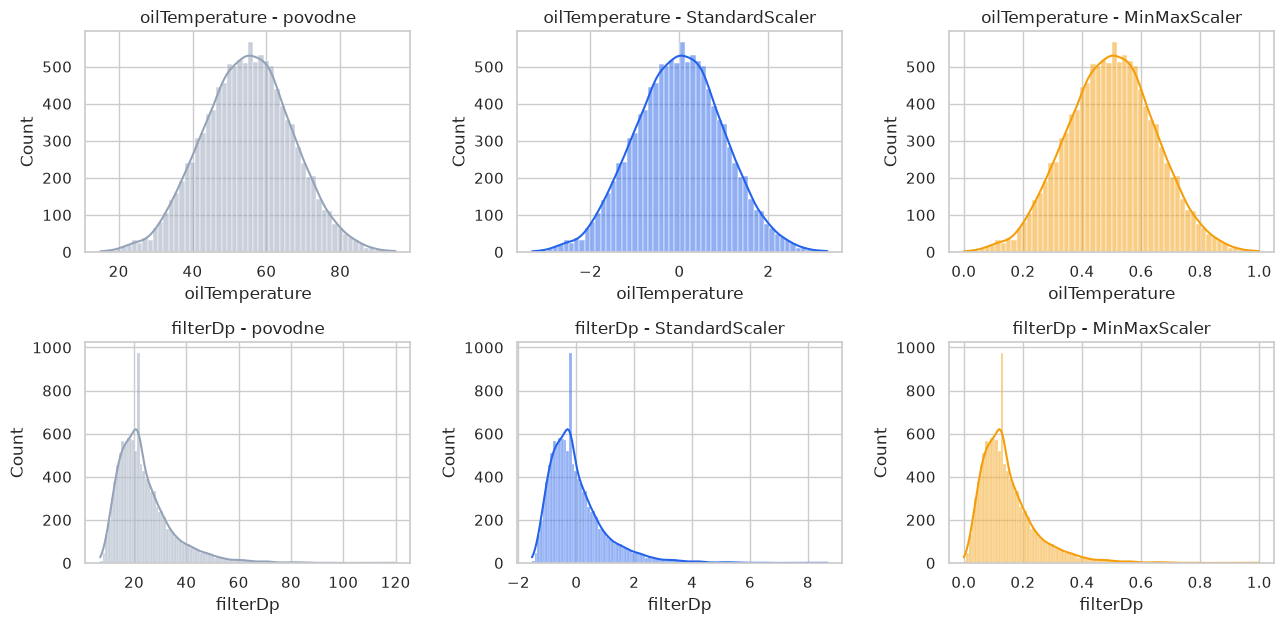

sikmost sa skalovanim nemeni:


,povodna,standard,minmax
oilTemperature,-0.003,-0.003,-0.003
filterDp,1.988,1.988,1.988


In [50]:
#2.1 C: vizualne porovnanie efektu scalerov (tvar rozdelenia sa NEMENI, len polohu/rozsah)
example_cols = ["oilTemperature", "filterDp"]
fig, axes = plt.subplots(len(example_cols), 3, figsize=(13, 3.2 * len(example_cols)))
for row, col in enumerate(example_cols):
    sns.histplot(X_train[col], ax=axes[row, 0], color="#94a3b8", kde=True)
    axes[row, 0].set_title(f"{col} - povodne")
    sns.histplot(X_standard[col], ax=axes[row, 1], color="#2563eb", kde=True)
    axes[row, 1].set_title(f"{col} - StandardScaler")
    sns.histplot(X_minmax[col], ax=axes[row, 2], color="#f59e0b", kde=True)
    axes[row, 2].set_title(f"{col} - MinMaxScaler")
plt.tight_layout()
plt.show()

print("sikmost sa skalovanim nemeni:")
display(pd.DataFrame({
    "povodna": X_train[example_cols].apply(skew),
    "standard": X_standard[example_cols].apply(skew),
    "minmax": X_minmax[example_cols].apply(skew),
}).round(3))


Šikmosť `filterDp` ostáva po scaleroch ~1.9 - na reálne zníženie šikmosti treba transformer, nie scaler. Porovnáme `PowerTransformer` (Yeo-Johnson) a `QuantileTransformer` na troch najviac zošikmených atribútoch.

In [51]:
#2.1 C: transformery - PowerTransformer (Yeo-Johnson) vs QuantileTransformer na najviac zoskmenych atributoch
from sklearn.preprocessing import PowerTransformer, QuantileTransformer

skewed_cols = ["filterDp", "rms_vibration", "serviceHours"]

power_transformer = PowerTransformer(method = "yeo-johnson")
quantile_transformer = QuantileTransformer(output_distribution="normal", random_state = 42)

X_power = pd.DataFrame(power_transformer.fit_transform(X_train[skewed_cols]), columns = skewed_cols, index = X_train.index)
X_quantile = pd.DataFrame(quantile_transformer.fit_transform(X_train[skewed_cols]), columns = skewed_cols, index = X_train.index)

transform_compare = pd.DataFrame({
    "sikmost_povodna": X_train[skewed_cols].apply(skew),
    "sikmost_power": X_power.apply(skew),
    "sikmost_quantile": X_quantile.apply(skew),
}).round(3)
display(transform_compare)


,sikmost_povodna,sikmost_power,sikmost_quantile
filterDp,1.988,0.006,0.019
rms_vibration,1.634,0.008,0.013
serviceHours,1.427,-0.001,1.010


Histogramy potvrdzujú tabuľku: `filterDp` a `rms_vibration` sú po oboch technikách takmer symetrické. `serviceHours` je výnimka - `QuantileTransformer` šikmosť nezmenil (~1.0), pretože ~150 meraní (cca 20 jednotiek) má identický strop `serviceHours = 45 000 h` (zrejme censoring v dátach), ktorý sa pri mapovaní na poradie natlačí na okraj rozdelenia. `PowerTransformer` tento problém nemá - je to plynulá mocninová transformácia, nie mapovanie na kvantily.

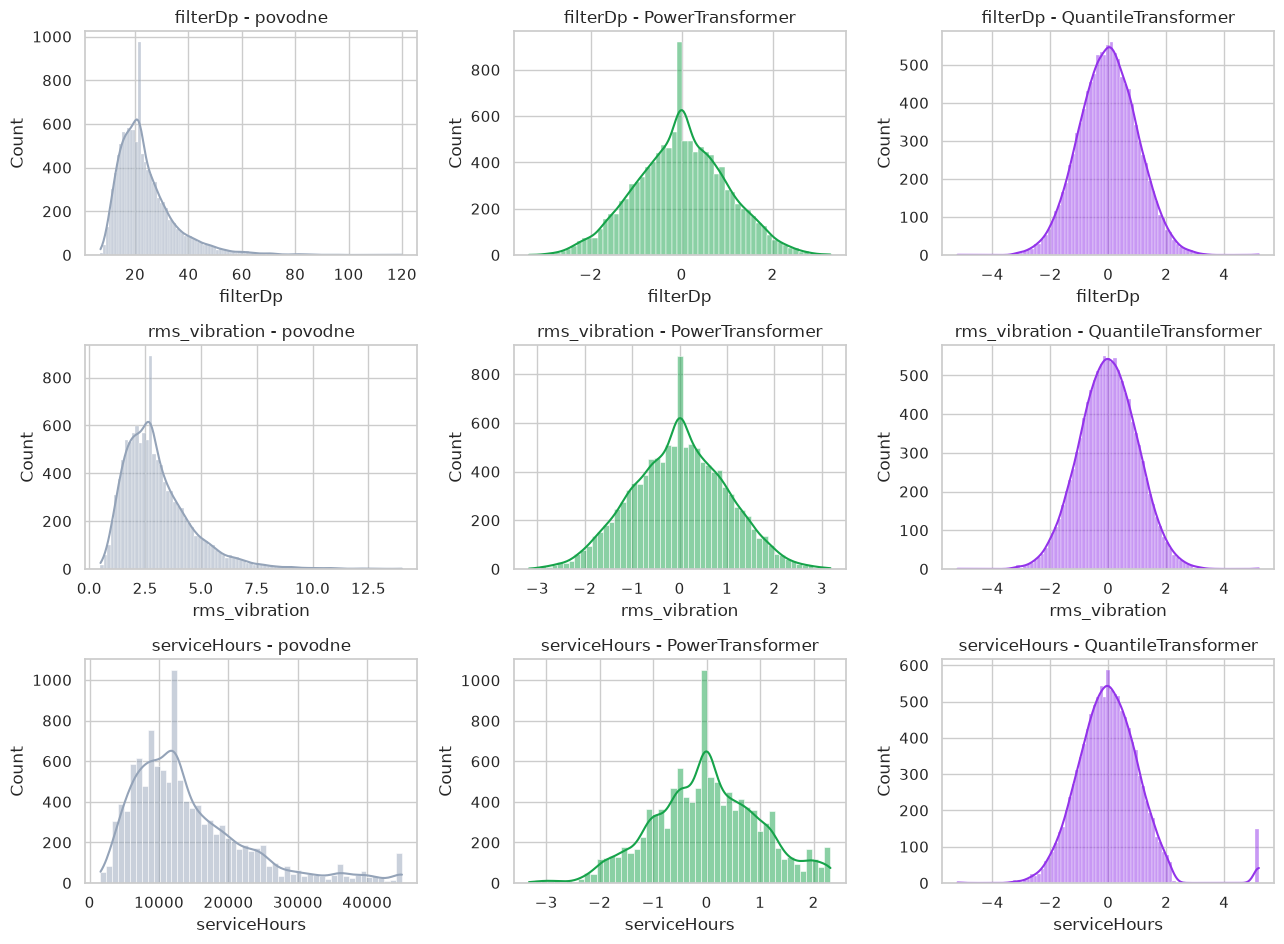

In [52]:
#2.1 C: vizualne porovnanie efektu transformerov
fig, axes = plt.subplots(len(skewed_cols), 3, figsize=(13, 3.2 * len(skewed_cols)))
for row, col in enumerate(skewed_cols):
    sns.histplot(X_train[col], ax = axes[row, 0], color = "#94a3b8", kde = True)
    axes[row, 0].set_title(f"{col} - povodne")
    sns.histplot(X_power[col], ax = axes[row, 1], color ="#16a34a", kde = True)
    axes[row, 1].set_title(f"{col} - PowerTransformer")
    sns.histplot(X_quantile[col], ax = axes[row, 2], color ="#9333ea", kde = True)
    axes[row, 2].set_title(f"{col} - QuantileTransformer")
plt.tight_layout()
plt.show()


**Zhrnutie 2.1 C:** scalery menia len polohu/rozsah (vhodné pre symetrické atribúty: `oilTemperature`, `reservoir_pressure`, `Flowmeter`, `dewpointDischarge`, `currentMotor`, `mean/median_signal_dbm`). Transformery menia tvar rozdelenia - pri `filterDp`/`rms_vibration` oba znížili šikmosť takmer na 0, pri `serviceHours` len `PowerTransformer` (dôvod vyššie). `PowerTransformer` je navyše monotónny a invertovateľný.

### 2.1 D - Zdôvodnenie volieb (2b)
Zdokumentujte a zdôvodnite rozhodnutia urobené v 2.1 (prečo tento pomer splitu, prečo tieto scalery/transformery, ako ste riešili kategorické atribúty...).

**Pomer train/test (80/20)** - pri ~2000 jednotkách a ~14,5 tis. meraniach ponechá 80/20 dostatočne veľkú trénovaciu množinu (~1598 jednotiek) pre robustné fitovanie imputerov/scalerov/modelov a ~400 testovacích jednotiek pre spoľahlivý odhad výkonu vo fáze 3. Delíme podľa `id_unit` (nie podľa riadkov) - jedna jednotka má približne 7 meraní s takmer identickými hodnotami `serviceHours`/`class_duty`, nezávislý split po riadkoch by umožnil group leakage (kvôli tomu, že je rovnaká jednotka v train aj test) a umelo nadhodnotil testovaciu presnosť. Stratifikujeme podľa toho, či jednotka mala aspoň jedno `failure=1`, aby sa zastúpenie minoritnej triedy nelíšilo medzi množinami. `random_state = 42` zabezpečuje reprodukovateľnosť.

Kódovanie atribútov sme vybrali podľa typu a kardinality. `class_duty` je poradová (light<medium<heavy) -> ordinálne. `codeModel`/`fleetCode` sú nominálne s nízkou kardinalitou (4-5 kat.) -> one-hot (bez vnúteného poradia). `install_region` (59 kategórií, slabý prediktor v 1.1/1.3) -> frekvenčné kódovanie namiesto one-hot (ktorý by vytvoril desiatky riedkych stĺpcov). `cycle_ts` - počet dní od referenčného dátumu (min v train). `id_unit`/`id_depot` sú len identifikátory, nevstupujú ako prediktory.

**Imputácia** - medián, fitovaný výlučne na `df_train` (`SimpleImputer`) - `filterDp`, `rms_vibration`, `serviceHours` sú zošikmené, priemer by bol citlivejší na extrémy. Fit len na train (nie na celom `df_clean`) je nutný, aby sa do trénovacích štatistík nepremietla informácia z testu.

**Scalery** - `StandardScaler` (priemer 0, rozptyl 1) je vhodnejší pre približne symetrické atribúty a modely citlivé na mierku (napr. logistická regresia). `MinMaxScaler` je vhodný pri pevne ohraničenom rozsahu [0,1] (napr. neurónové siete, alebo veličiny s prirodzenými fyzikálnymi hranicami ako signal_dbm). Oba menia len polohu/rozsah, nie tvar rozdelenia.

**Transformery** - aplikované na tri najviac zošikmené atribúty (`filterDp`, `rms_vibration`, `serviceHours`, šikmosť 1,4-2,0). `PowerTransformer` znížil šikmosť na ~0 pri všetkých troch. `QuantileTransformer` zlyhal pri `serviceHours` (~150 meraní s identickým stropom 45 000 h sa natlačí na okraj rozdelenia). Preferujeme `PowerTransformer` pre pipeline (2.3) - je navyše monotónny, invertovateľný a funguje aj so zápornými hodnotami. `QuantileTransformer` ostáva alternatívou pre atribúty bez podobných extrémov.

Dáta sa oproti fáze 1 zmenili nasledovne:  `df_train_ml` má viac stĺpcov (pribudli `class_duty_ord`, `codeModel_*`, `fleetCode_*`, `install_region_freq`, `cycle_ts_days`) a menej riadkov (len ~80% jednotiek) než `df_clean`. Chýbajúce hodnoty z fázy 1 sú doplnené, pôvodné textové kategórie a `id_unit`/`id_depot` ako vstupy zmizli. Škálované distribúcie sa prirodzene líšia od EDA z fázy 1 - pôvodné hodnoty v `df_clean`/`df_train` zostávajú zachované.

## 2.2 Výber atribútov pre strojové učenie (5b)

### 2.2 A - Informatívnosť atribútov (3b)
Zistite, ktoré atribúty sú informatívne k predikovanej premennej `failure`, použite **min. 3 techniky** (napr. korelácia/point-biserial, mutual information, chi-kvadrát test, feature importance z stromového modelu, RFE) a porovnajte ich medzi sebou.

1. **ANOVA F-test** (`f_classif`) - rýchly filter test lineárneho vzťahu s `failure`.
2. **Mutual information** - zachytáva aj nelineárne/nemonotónne závislosti.
3. **Feature importance (Random Forest)** - viacrozmerná, zohľadňuje interakcie.

In [53]:
#2.2 A, technika 1: ANOVA F-test - rychly filter test linearneho vztahu atributu s failure
from sklearn.feature_selection import f_classif

f_stat, f_pval = f_classif(X_train[feature_cols], y_train)
fstat_scores = pd.Series(f_stat, index = feature_cols).sort_values(ascending = False)

display(fstat_scores.to_frame("f_statistic").round(2))


,f_statistic
class_duty_ord,264.06
serviceHours,182.12
filterDp,80.64
reservoir_pressure,68.38
dewpointDischarge,51.44
currentMotor,46.50
filterDp_suspicious,20.05
Flowmeter,6.51
codeModel_APU-15,6.38
rms_vibration,3.73


Teraz mutual information - na rozdiel od F-testu nepredpokladá lineárny ani monotónny vzťah.

In [54]:
#2.2 A, technika 2: mutual information - zachyti aj nelinearne/nemonotonne zavislosti
#diskretne su vsetky zakodovane KATEGORICKE atributy: ordinalne class_duty_ord, binarne filterDp_suspicious,
#one-hot stlpce a frekvencne kodovany install_region_freq (1 hodnota = 1 region, nie mnozstvo)
#cycle_ts_days je celociselny, ale je to casova velicina s 365 hodnotami -> spojity (vid kontrola nizsie)
from sklearn.feature_selection import mutual_info_classif

discrete_cols = {"class_duty_ord", "filterDp_suspicious", "install_region_freq"} | set(onehot_encoder.get_feature_names_out(onehot_cols))
discrete_mask = [col in discrete_cols for col in feature_cols]

#kontrola: kazdy celociselny stlpec je bud v maske, alebo vedome spojity
integer_cols = {col for col in feature_cols if pd.api.types.is_integer_dtype(X_train[col])}
print("celociselne stlpce mimo masky (vedome spojite):", sorted(integer_cols - discrete_cols))
display(pd.DataFrame({
    "typ": [str(X_train[col].dtype) for col in feature_cols],
    "pocet_unikatnych": [X_train[col].nunique() for col in feature_cols],
    "diskretny_v_MI": discrete_mask,
}, index = feature_cols))

mi_scores = pd.Series(
    mutual_info_classif(X_train[feature_cols], y_train, discrete_features=discrete_mask, random_state=42),
    index=feature_cols,
).sort_values(ascending=False)

display(mi_scores.to_frame("mutual_information").round(4))


celociselne stlpce mimo masky (vedome spojite): ['cycle_ts_days']


,typ,pocet_unikatnych,diskretny_v_MI
currentMotor,float64,11397,False
filterDp,float64,11026,False
oilTemperature,float64,11471,False
reservoir_pressure,float64,11218,False
rms_vibration,float64,10949,False
Flowmeter,float64,11470,False
dewpointDischarge,float64,11457,False
serviceHours,float64,1493,False
mean_signal_dbm,float64,120,False
median_signal_dbm,float64,63,False


,mutual_information
filterDp,0.0320
rms_vibration,0.0222
serviceHours,0.0168
class_duty_ord,0.0120
mean_signal_dbm,0.0083
median_signal_dbm,0.0047
dewpointDischarge,0.0046
oilTemperature,0.0039
currentMotor,0.0029
Flowmeter,0.0026


Prečo `cycle_ts_days` neoznačujeme ako diskrétny: odhad MI pre diskrétny atribút s mnohými hodnotami je systematicky nadhodnotený (približne o (K-1)/(2N) nats). Overíme to permutačným testom - MI s náhodne premiešaným `failure` by mala byť 0, každá kladná hodnota je len skreslenie odhadu.

In [55]:
#2.2 A: skreslenie MI pri diskretnom odhade - MI s nahodne premiesanym failure (skutocna MI = 0)
rng = np.random.default_rng(42)
bias_rows = []
for col in ["cycle_ts_days", "install_region_freq"]:
    for as_discrete in [True, False]:
        mi_real = mutual_info_classif(X_train[[col]], y_train, discrete_features = [as_discrete], random_state = 42)[0]
        mi_perm = np.mean([mutual_info_classif(X_train[[col]], rng.permutation(y_train.to_numpy()),
                                               discrete_features = [as_discrete], random_state = 42)[0] for _ in range(5)])
        bias_rows.append({"atribut": col, "odhad": "diskretny" if as_discrete else "spojity (kNN)",
                          "pocet_hodnot": X_train[col].nunique(), "MI_skutocna": mi_real,
                          "MI_premiesany_failure": mi_perm, "MI_po_odcitani_skreslenia": mi_real - mi_perm})
display(pd.DataFrame(bias_rows).set_index(["atribut", "odhad"]).round(4))


pocet_hodnot  MI_skutocna  \
atribut             odhad                                      
cycle_ts_days       diskretny               365       0.0183   
                    spojity (kNN)           365       0.0000   
install_region_freq diskretny                49       0.0023   
                    spojity (kNN)            49       0.0056   

                                   MI_premiesany_failure  \
atribut             odhad                                  
cycle_ts_days       diskretny                     0.0170   
                    spojity (kNN)                 0.0010   
install_region_freq diskretny                     0.0020   
                    spojity (kNN)                 0.0016   

                                   MI_po_odcitani_skreslenia  
atribut             odhad                                     
cycle_ts_days       diskretny                         0.0013  
                    spojity (kNN)                    -0.0010  
install_region_freq diskretny                         0.0003  
                    spojity (kNN)                     0.0040

Permutačný test potvrdil skreslenie: pri diskrétnom odhade má `cycle_ts_days` MI 0.0183, ale rovnaký odhad s náhodne premiešaným `failure` dá 0.0170 - **~93 % hodnoty je len skreslenie** z 365 úrovní a skutočná informácia je ~0.001. Spojitý (kNN) odhad dáva ~0, čo zodpovedá aj F-testu (rank 15). Preto `cycle_ts_days` (časová veličina s prirodzeným poradím) odhadujeme ako spojitý. `install_region_freq` je naopak zakódovaná **kategória** (každá hodnota = jeden región, nie množstvo), preto patrí medzi diskrétne - aj po tejto oprave má prakticky nulovú MI (0.0023 vs. 0.0020 pri premiešaní), región montáže teda s poruchou nesúvisí.

Tretia technika - feature importance z Random Forest. Použijeme `class_weight = "balanced"`, aby dôležitosť atribútov neurčovala len majoritná trieda (`failure = 0` tvorí ~88% meraní).

In [56]:
#2.2 A, technika 3: feature importance z Random Forest - viacrozmerna miera, zohladnuje aj interakcie
from sklearn.ensemble import RandomForestClassifier

rf_selector = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1)
rf_selector.fit(X_train[feature_cols], y_train)

rf_scores = pd.Series(rf_selector.feature_importances_, index=feature_cols).sort_values(ascending=False)
display(rf_scores.to_frame("rf_importance").round(4))


,rf_importance
filterDp,0.1204
currentMotor,0.0946
rms_vibration,0.0875
serviceHours,0.0856
reservoir_pressure,0.0755
dewpointDischarge,0.0739
oilTemperature,0.0672
Flowmeter,0.0668
cycle_ts_days,0.0629
install_region_freq,0.0514


Všetky tri skóre normalizujeme na rozsah [0, 1] (voči maximu v rámci danej techniky), aby sa dali zobraziť v jednom grafe - absolútne hodnoty naprieč technikami totiž nie sú v rovnakých jednotkách.

,anova_f,mutual_info,rf_importance
currentMotor,46.4995,0.0029,0.0946
filterDp,80.6380,0.0320,0.1204
oilTemperature,0.2826,0.0039,0.0672
reservoir_pressure,68.3820,0.0017,0.0755
rms_vibration,3.7272,0.0222,0.0875
Flowmeter,6.5086,0.0026,0.0668
dewpointDischarge,51.4359,0.0046,0.0739
serviceHours,182.1243,0.0168,0.0856
mean_signal_dbm,0.0148,0.0083,0.0506
median_signal_dbm,0.7426,0.0047,0.0475


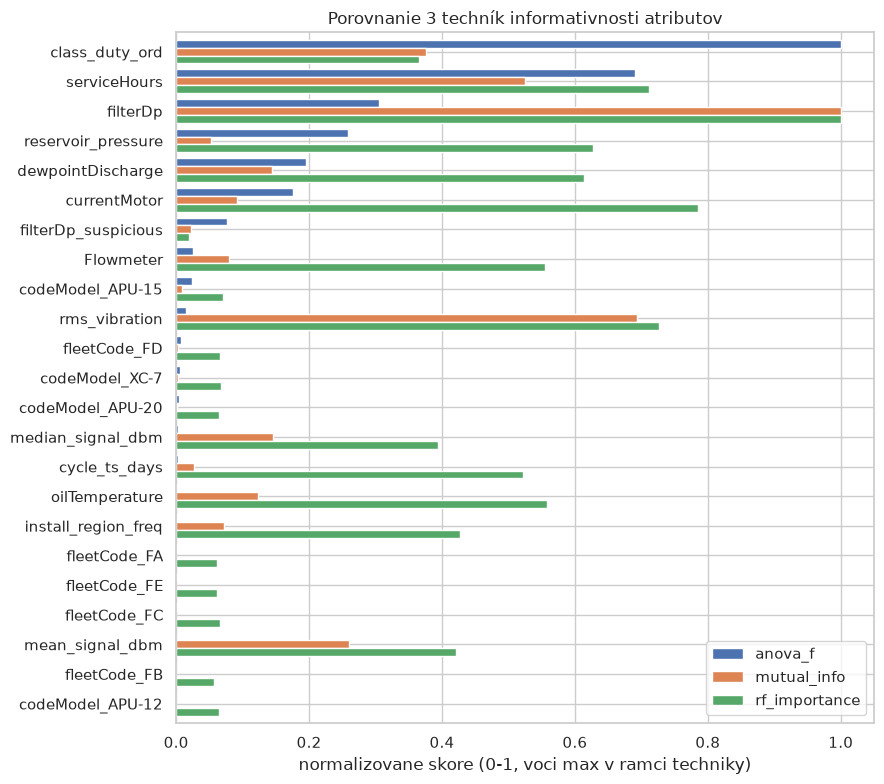

In [57]:
#2.2 A: porovnanie vsetkych troch technik v jednej tabulke a grafe
comparison = pd.DataFrame({
    "anova_f": fstat_scores,
    "mutual_info": mi_scores,
    "rf_importance": rf_scores,
}).loc[feature_cols]
display(comparison.round(4))

comparison_norm = comparison / comparison.max()
comparison_norm = comparison_norm.loc[comparison.mean(axis=1).sort_values(ascending=False).index]

comparison_norm.plot(kind="barh", figsize=(9, 8), width=0.8)
plt.gca().invert_yaxis()
plt.xlabel("normalizovane skore (0-1, voci max v ramci techniky)")
plt.title("Porovnanie 3 techník informativnosti atributov")
plt.tight_layout()
plt.show()


`filterDp` a `serviceHours` vedú vo všetkých troch technikách - najspoľahlivejšie prediktory. `rms_vibration` má slabý F-test s rankom 10, ale vysokú MI aj RF importance s rankom 2-3 -> nelineárny vzťah, ktorý F-test (lineárny) nevidí. `currentMotor` je opačný prípad - silný v RF (rank 2), ale len priemerný vo F-teste/MI (rank 6/9). `class_duty_ord` je číslo 1 podľa F-testu a 4 podľa MI, ale prepadá pri RF (rank 13). Dummy `codeModel_*`/`fleetCode_*` sú na spodku všetkých troch, zhodne so slabým Cramérovym V (0.023/0.013) z 1.1 D.

### 2.2 B - Zoradenie atribútov podľa dôležitosti (1b)
Zoraďte zistené atribúty podľa dôležitosti (súhrnná tabuľka/graf naprieč technikami).

Skóre troch techník sú v nezlučiteľných jednotkách (korelácia, nats, Gini pokles) a nemôžeme ich spriemerovať priamo. Poradie je ale porovnateľné - skombinujeme priemerným poradím.

In [58]:
#2.2 B: kombinacia 3 technik do jedneho poradia - priemerne poradie
rank_table = pd.DataFrame({
    "f_test_poradie": fstat_scores.rank(ascending=False),
    "mutual_info_poradie": mi_scores.rank(ascending=False),
    "rf_poradie": rf_scores.rank(ascending=False),
})
rank_table["priemerne_poradie"] = rank_table.mean(axis=1)
rank_table = rank_table.sort_values("priemerne_poradie")

display(rank_table.round(2))


,f_test_poradie,mutual_info_poradie,rf_poradie,priemerne_poradie
filterDp,3.0,1.0,1.0,1.67
serviceHours,2.0,3.0,4.0,3.00
rms_vibration,10.0,2.0,3.0,5.00
currentMotor,6.0,9.0,2.0,5.67
dewpointDischarge,5.0,7.0,6.0,6.00
class_duty_ord,1.0,4.0,13.0,6.00
reservoir_pressure,4.0,12.0,5.0,7.00
Flowmeter,8.0,10.0,8.0,8.67
oilTemperature,16.0,8.0,7.0,10.33
median_signal_dbm,14.0,6.0,12.0,10.67


Prvých 8 atribútov má priemerné poradie ≤ 8.7, potom nasleduje medzera 1.7 k `oilTemperature` (10.3), za ktorým tesne nasleduje `median_signal_dbm` (10.7) a ďalej už len atribúty s poradím ≥ 12.3 (`cycle_ts_days`, dummy stĺpce, `mean_signal_dbm`, `install_region_freq`). Výber robíme po 9. atribút - `oilTemperature` aj `median_signal_dbm` sú na hranici, ale `median_signal_dbm` vyraďujeme z vecných dôvodov (2.2 C).

vybranych atributov: 9
['filterDp', 'serviceHours', 'rms_vibration', 'currentMotor', 'dewpointDischarge', 'class_duty_ord', 'reservoir_pressure', 'Flowmeter', 'oilTemperature']


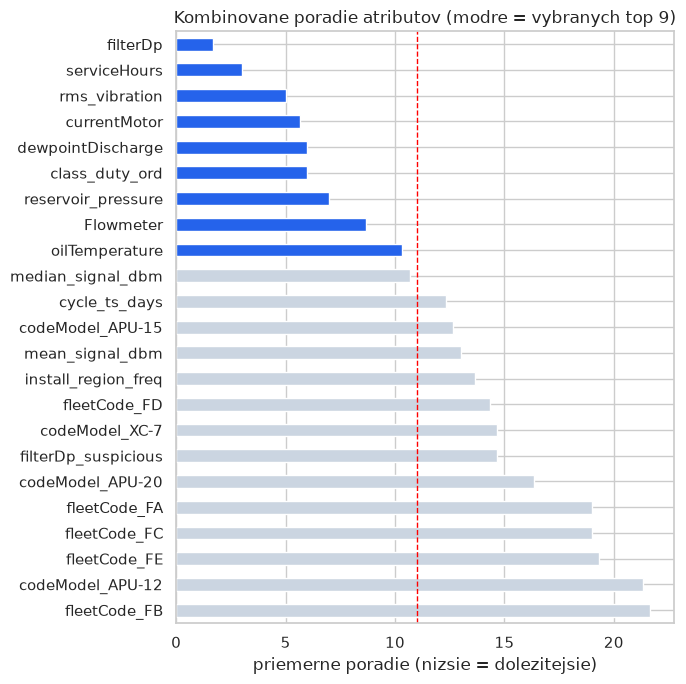

In [59]:
#2.2 B: prakticka hranica vyberu - top 9 atributov podla priemerneho poradia (prirodzena medzera pred ostatnymi)
selected_features = rank_table.head(9).index.tolist()
print("vybranych atributov:", len(selected_features))
print(selected_features)

colors = ["#2563eb" if f in selected_features else "#cbd5e1" for f in rank_table.index]
rank_table["priemerne_poradie"].plot(kind="barh", figsize=(7, 7), color=colors)
plt.gca().invert_yaxis()
cutoff = rank_table.loc[selected_features, "priemerne_poradie"].max()
plt.axvline(cutoff + 0.65, color="red", linestyle="--", linewidth=1)
plt.xlabel("priemerne poradie (nizsie = dolezitejsie)")
plt.title("Kombinovane poradie atributov (modre = vybranych top 9)")
plt.tight_layout()
plt.show()


### 2.2 C - Zdôvodnenie volieb (1b)
Zdôvodnite výber finálnej sady atribútov pre ďalšie modelovanie.


**Prečo tieto tri techniky?** Pokrývajú odlišné typy vzťahu s `failure` - ANOVA F-test (`f_classif`) lineárny vzťah jedného atribútu s cieľom, mutual information nelineárne/nemonotónne vzťahy, RF importance viacrozmerné interakcie. Pri mutual information sme ako diskrétne označili všetky zakódované kategorické atribúty (`class_duty_ord`, `filterDp_suspicious`, `install_region_freq`, one-hot stĺpce); `cycle_ts_days` je časová veličina a pri diskrétnom odhade by jeho MI bola z ~93 % skreslenie (permutačný test v 2.2 A).

`filterDp` a `serviceHours` sú zhodne v top priečkach všetkých troch - najspoľahlivejšie prediktory. `rms_vibration` má nízky F-test (rank 10), ale vysokú MI aj RF (rank 2-3) - vzťah je zrejme nelineárny, F-test (lineárny) ho podhodnocuje. `currentMotor` má opačný profil - silný v RF (rank 2, zachytáva interakcie), ale len priemerný F-test/MI (rank 6/9). `class_duty_ord` je naopak #1 podľa F-testu, ale rank 13 podľa RF (impurity-based importance podhodnocuje nízkokardinálne atribúty voči kontinuálnym náhradám). `mean_signal_dbm` je opačný nesúlad - takmer nulový F-test (rank 23), ale nadpriemerná MI (rank 5). Dummy stĺpce `codeModel`/`fleetCode` sú na spodku vo všetkých troch, zhodne so slabým Cramérovym V (0.023, 0.013) z 1.1 D.

Kombinujeme priemerným poradím (2.2 B) - škály skóre nie sú porovnateľné, poradie je. Do finálnej sady berieme top 9: `filterDp`, `serviceHours`, `rms_vibration`, `currentMotor`, `dewpointDischarge`, `class_duty_ord`, `reservoir_pressure`, `Flowmeter`, `oilTemperature`. `oilTemperature` (10.3) je na hranici výberu - ponechávame ho ako priamo merací senzor kompresora, ktorý je v doméne prediktívnej údržby APU relevantný. Vyraďujeme `mean_signal_dbm`/`median_signal_dbm` (poradie 13.0 / 10.7, nekonzistentné medzi technikami, navyše nevyriešené riziko časového úniku z brán inštalovaných po období merania - 1.1 C/1.2 B), `install_region_freq`/`cycle_ts_days` (priemerné poradie 13.7 / 12.3, bez skutočnej informácie podľa MI po odčítaní skreslenia) a `filterDp_suspicious` (najmenej dôležitý podľa RF, redundantný voči `filterDp`).

## 2.3 Replikovateľnosť predspracovania (5b)

### 2.3 A - Znovupoužiteľný kód predspracovania (3b)
Upravte kód realizujúci predspracovanie trénovacej množiny tak, aby ho bolo možné bez ďalších úprav znovu použiť na predspracovanie testovacej množiny (napr. funkcie/triedy fitnuté len na train, aplikované na test).

V 2.1/2.2 sme fitovali viacero objektov výlučne na `df_train` (`cycle_ts_reference`, `duty_encoder`, `onehot_encoder`, `region_freq`, `median_imputer`, `selected_features`). Teraz ich znovu použijeme (len `.transform()`, nikdy `.fit()`) na `df_test` - bez prepočítania čohokoľvek z testu.

In [60]:
#2.3 A: vsetky kroky su objekty fitnute v 2.1 B (duty_encoder, onehot_encoder, region_freq, median_imputer, cycle_ts_reference)
#tu len aplikuju (.transform), nikdy znova nefituju 
#funguje na akykolvek vystup build_integrated_dataset

def apply_fitted_preprocessing(df_raw):
    df_ml = df_raw.copy()

    #cas: pouzivame cycle_ts_reference vypocitane na train
    df_ml["cycle_ts_days"] = (df_ml["cycle_ts"] - cycle_ts_reference).dt.days
    df_ml = df_ml.drop(columns=["cycle_ts", "id_depot"]).set_index("id_unit")

    #kategoricke atributy: .transform s objektami fitnutymi na train
    df_ml["class_duty_ord"] = duty_encoder.transform(df_ml[["class_duty"]])
    onehot_array = onehot_encoder.transform(df_ml[onehot_cols])
    onehot_df_new = pd.DataFrame(
        onehot_array, columns=onehot_encoder.get_feature_names_out(onehot_cols), index=df_ml.index
    )

    #install_region: frekvencie pocitane na train (region_freq) 
    #nezname regiony testu -> 0 (= nevideny v train, nie realna nulova frekvencia)
    unseen_regions = (~df_ml["install_region"].isin(region_freq.index)).sum()
    df_ml["install_region_freq"] = df_ml["install_region"].map(region_freq).fillna(0)

    df_ml = pd.concat(
        [df_ml.drop(columns=["class_duty"] + onehot_cols + ["install_region"]), onehot_df_new],
        axis=1,
    )

    #imputacia: SimpleImputer fitnuty na train (median_imputer), tu len .transform
    df_ml[missing_cols] = median_imputer.transform(df_ml[missing_cols])

    return df_ml, unseen_regions

df_test_ml, n_unseen_regions = apply_fitted_preprocessing(df_test)

print("neznamych install_region v teste (dostanu frekvenciu 0):", n_unseen_regions)
print("tvar df_test_ml:", df_test_ml.shape)
print("stlpce sa zhoduju s df_train_ml (bez ohladu na poradie)?",
      sorted(df_test_ml.columns) == sorted(df_train_ml.columns))
print("vsetky atributy numericke:", all(np.issubdtype(d, np.number) for d in df_test_ml.dtypes))


neznamych install_region v teste (dostanu frekvenciu 0): 0
tvar df_test_ml: (2942, 24)
stlpce sa zhoduju s df_train_ml (bez ohladu na poradie)? True
vsetky atributy numericke: True


Explicitne vypíšeme všetky fitnuté objekty/konštanty použité vyššie, aby bolo jasne vidieť, že pochádzajú len z `df_train` - žiadny z nich sa nepočítal (ani čiastočne) z `df_test`.

In [61]:
#2.3 A: explicitna kontrola proti data leakage - vymenujeme vsetky fitnute objekty a potvrdime,
#ze boli vytvorene (fit) vylucne z df_train
fitted_objects = {
    "cycle_ts_reference (min datum v train)": cycle_ts_reference,
    "duty_encoder.categories_": duty_encoder.categories_,
    "onehot_encoder.categories_": onehot_encoder.categories_,
    "region_freq (pocet unikatnych regionov v train)": region_freq.shape[0],
    "median_imputer.statistics_": median_imputer.statistics_,
}
for name, value in fitted_objects.items():
    print(f"{name}: {value}")

print(f"\nvsetky vyssie uvedene objekty boli fitnute v 2.1 B VYLUCNE na df_train ({len(df_train)} riadkov) "
      f"- df_test ({len(df_test)} riadkov) sa pri ich fitovani nikdy nepouzil.")


cycle_ts_reference (min datum v train): 2023-01-01 00:00:00
duty_encoder.categories_: [array(['light', 'medium', 'heavy'], dtype=object)]
onehot_encoder.categories_: [array(['APU-12', 'APU-15', 'APU-20', 'XC-7'], dtype=object), array(['FA', 'FB', 'FC', 'FD', 'FE'], dtype=object)]
region_freq (pocet unikatnych regionov v train): 59
median_imputer.statistics_: [5.228945e+00 2.143069e+01 5.503321e+01 2.725080e+00 1.216280e+04]

vsetky vyssie uvedene objekty boli fitnute v 2.1 B VYLUCNE na df_train (11514 riadkov) - df_test (2942 riadkov) sa pri ich fitovani nikdy nepouzil.


Nakoniec aplikujeme aj výber atribútov z 2.2 B - rovnaký zoznam `selected_features`, žiadne nové rozhodovanie na základe testovacích dát.

In [62]:
#2.3 A: aplikacia vyberu atributov z 2.2 B - rovnaky zoznam selected_features pre train aj test
X_train_final = X_train[selected_features]
X_test_final = df_test_ml[selected_features]
y_test = df_test_ml["failure"]

print("X_train_final:", X_train_final.shape, " X_test_final:", X_test_final.shape)
display(X_test_final.head(3))


X_train_final: (11514, 9)  X_test_final: (2942, 9)


,filterDp,serviceHours,rms_vibration,currentMotor,dewpointDischarge,class_duty_ord,reservoir_pressure,Flowmeter,oilTemperature
id_unit,,,,,,,,,
1,24.88211,7380.9,1.51633,4.73839,7.43573,1.0,9.56212,25.66921,54.20939
1,22.29925,7380.9,4.26492,5.81631,6.18256,1.0,8.02690,29.64814,67.28390
1,26.79847,7380.9,1.08048,5.52916,7.58645,1.0,8.61309,29.80549,52.16245


### 2.3 B - Využitie sklearn.pipeline (2b)
Zostavte `sklearn.pipeline.Pipeline` (prípadne `ColumnTransformer`), ktorý spája kroky predspracovania (imputácia, scaling, transformácie, encoding) do jedného znovupoužiteľného objektu, a overte ho na testovacej množine.

Po výbere v 2.2 B ostáva `class_duty` (3 úrovne) a 8 číselných atribútov - `OneHotEncoder`/frekvenčné kódovanie už nepotrebujeme (boli pre vyradené `codeModel`/`fleetCode`/`install_region`). `ColumnTransformer` postavíme s 3 vetvami a zabalíme do `Pipeline`, rozšíriteľnej vo fáze 3 o krok s modelom. Pipeline obsahuje **všetky kroky predspracovania, ktoré závisia od hodnôt jednotlivých atribútov**, aby fungoval samostatne aj na dátach, ktoré neprešli čistením z fázy 1:

| vetva | kroky |
|---|---|
| kategorická (`class_duty`) | `OrdinalEncoder` (light < medium < heavy, neznáma kategória -> `NaN`) -> `SimpleImputer` (najčastejšia úroveň) |
| zošikmené (`filterDp`, `rms_vibration`, `serviceHours`) | kontrola fyzikálneho rozsahu -> `NaN` (1.2 B) -> `SimpleImputer` (medián) -> `PowerTransformer` (Yeo-Johnson) -> `StandardScaler` |
| ostatné číselné (5 atribútov) | kontrola fyzikálneho rozsahu -> `NaN` (1.2 B) -> `SimpleImputer` (medián) -> `StandardScaler` |

Kroky, ktoré pracujú s celými záznamami (deduplikácia, spájanie troch súborov, zjednotenie zápisov `class_duty` a formátov dátumov), robí funkcia `build_integrated_dataset` z 2.1 A - nie sú to transformácie stĺpcov, preto nemôžu byť v `ColumnTransformer`. Outliery (1.2 C) zámerne neorezávame - extrémne `filterDp` sú signál poruchy (1.2 B, H2 v 1.3).

In [63]:
#2.3 B: formalny sklearn Pipeline (ColumnTransformer + Pipeline) - len pre 9 atributov vybranych v 2.2 B
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

categorical_cols = ["class_duty"]
skewed_numeric_cols = ["filterDp", "rms_vibration", "serviceHours"]
other_numeric_cols = ["currentMotor", "oilTemperature", "reservoir_pressure", "Flowmeter", "dewpointDischarge"]
raw_input_cols = categorical_cols + skewed_numeric_cols + other_numeric_cols

from sklearn.base import BaseEstimator, TransformerMixin

class PhysicalRangeToNaN(BaseEstimator, TransformerMixin):
    #krok cistenia z 1.2 B ako sucast pipeline: hodnoty mimo fyzikalneho rozsahu (chyba senzora) -> NaN,
    #ktore potom doplni imputer; pri filterDp len zaporne hodnoty (vysoke su realny signal poruchy, 1.2 B)
    #pravidla su fixne z domeny, nic sa neuci z dat - fit len zapamata nazvy stlpcov
    def __init__(self, ranges = None, lower_bound_only = ()):
        self.ranges = ranges
        self.lower_bound_only = lower_bound_only

    def fit(self, X, y = None):
        self.feature_names_in_ = np.asarray(X.columns, dtype = object)
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns = self.feature_names_in_).astype(float)
        for col in X.columns:
            if col not in (self.ranges or {}):
                continue
            lo, hi = self.ranges[col]
            invalid = (X[col] < lo) if col in self.lower_bound_only else ~X[col].between(lo, hi)
            X.loc[invalid & X[col].notna(), col] = np.nan
        return X

    def get_feature_names_out(self, input_features = None):
        return self.feature_names_in_

#kategoricky atribut: nezname kategorie -> NaN, chybajuce/nezname -> najcastejsia uroven (fit na train)
categorical_pipeline = Pipeline([
    ("ordinal", OrdinalEncoder(categories=[["light", "medium", "heavy"]],
                               handle_unknown = "use_encoded_value", unknown_value = np.nan)),
    ("imputer", SimpleImputer(strategy = "most_frequent")),
])
#zoskmene atributy: kontrola rozsahu -> imputacia medianom -> PowerTransformer -> StandardScaler
skewed_pipeline = Pipeline([
    ("range", PhysicalRangeToNaN(ranges = expected_ranges, lower_bound_only = ("filterDp",))),
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson", standardize = False)),
    ("scaler", StandardScaler()),
])
#ostatne (priblizne symetricke) numericke atributy: kontrola rozsahu -> imputacia -> StandardScaler (2.1 C)
other_pipeline = Pipeline([
    ("range", PhysicalRangeToNaN(ranges = expected_ranges, lower_bound_only = ("filterDp",))),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessing = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_cols),
    ("skewed", skewed_pipeline, skewed_numeric_cols),
    ("other", other_pipeline, other_numeric_cols),
])

#Pipeline so zatial jednym krokom
preprocessing_pipeline = Pipeline([("preprocess", preprocessing)])

#fit vylucne na train, transform zvlast na train aj na test (ziadny opatovny fit na teste)
preprocessing_pipeline.fit(df_train[raw_input_cols])
train_transformed = preprocessing_pipeline.transform(df_train[raw_input_cols])
test_transformed = preprocessing_pipeline.transform(df_test[raw_input_cols])

out_cols = preprocessing_pipeline.named_steps["preprocess"].get_feature_names_out()
print("vystupne stlpce:", list(out_cols))
print(f"tvar train: {train_transformed.shape}, test: {test_transformed.shape}")
print(f"typ vystupu: {train_transformed.dtype} (numericky: {np.issubdtype(train_transformed.dtype, np.number)})")


vystupne stlpce: ['categorical__class_duty', 'skewed__filterDp', 'skewed__rms_vibration', 'skewed__serviceHours', 'other__currentMotor', 'other__oilTemperature', 'other__reservoir_pressure', 'other__Flowmeter', 'other__dewpointDischarge']
tvar train: (11514, 9), test: (2942, 9)
typ vystupu: float64 (numericky: True)


Dôkaz, že `Pipeline` bol fitovaný len raz -> po `StandardScaler` je priemer v train ~0 (tak je scaler nastavený), v teste presne 0 nebude, pretože parametre (priemer, rozptyl) pochádzajú z train, nie z opätovného prepočítania na teste - presne toto by sa pokazilo pri omylom zavolanom `fit_transform()` na teste.

In [64]:
#2.3 B: dokaz spravneho fit/transform workflow - priemer po skalovani v train ~0, v teste NIE je presne 0
train_df_out = pd.DataFrame(train_transformed, columns=out_cols)
test_df_out = pd.DataFrame(test_transformed, columns=out_cols)

display(pd.DataFrame({"train_priemer": train_df_out.mean(), "test_priemer": test_df_out.mean()}).round(3))


,train_priemer,test_priemer
categorical__class_duty,0.895,0.849
skewed__filterDp,-0.000,0.014
skewed__rms_vibration,0.000,-0.016
skewed__serviceHours,-0.000,-0.101
other__currentMotor,0.000,-0.065
other__oilTemperature,-0.000,0.019
other__reservoir_pressure,-0.000,-0.047
other__Flowmeter,0.000,-0.033
other__dewpointDischarge,0.000,-0.010


`pipeline.fit()` sme zavolali raz na `df_train[raw_input_cols]`, `.transform()` zvlášť na train aj test - oba výstupy majú 9 stĺpcov, rovnaké poradie, `float64`. Priemer po škálovaní je v train ~0, v teste nie (líši sa o desatiny) - presne tak má vyzerať korektný fit-len-na-train workflow.

Overíme ešte, že pipeline zvládne aj **nevyčistené a neúplné dáta** - vytvoríme niekoľko umelých záznamov s chybami, ktoré sme v dátach našli vo fáze 1 (chybový kód `oilTemperature = -999`, záporný `filterDp`, chýbajúce hodnoty, neznáma kategória `class_duty`).

In [65]:
#2.3 B: pipeline na nevycistenych/neuplnych zaznamoch - vystup musi byt kompletny a ciselny
broken_rows = df_test[raw_input_cols].head(4).copy()
broken_rows.iloc[0, broken_rows.columns.get_loc("oilTemperature")] = -999   #chybovy kod senzora (1.2 B)
broken_rows.iloc[1, broken_rows.columns.get_loc("filterDp")] = -5           #fyzikalne nemozna hodnota
broken_rows.iloc[2, broken_rows.columns.get_loc("currentMotor")] = np.nan   #chybajuca hodnota
broken_rows.iloc[2, broken_rows.columns.get_loc("class_duty")] = np.nan     #chybajuca kategoria
broken_rows.iloc[3, broken_rows.columns.get_loc("class_duty")] = "extreme"  #kategoria, ktoru train nepozna
display(broken_rows)

broken_out = pd.DataFrame(preprocessing_pipeline.transform(broken_rows), columns = out_cols, index = broken_rows.index)
display(broken_out.round(3))
print("vsetky vystupy konecne cisla (ziadne NaN):", bool(np.isfinite(broken_out.to_numpy()).all()))

#na nasich (uz vycistenych) datach kontrola rozsahu nic nemeni - pipeline dava rovnaky vysledok ako bez nej
range_step = preprocessing_pipeline.named_steps["preprocess"].named_transformers_["other"].named_steps["range"]
print("hodnot nahradenych kontrolou rozsahu v df_train:",
      int(range_step.transform(df_train[other_numeric_cols]).isna().sum().sum() - df_train[other_numeric_cols].isna().sum().sum()))


,class_duty,filterDp,rms_vibration,serviceHours,currentMotor,oilTemperature,reservoir_pressure,Flowmeter,dewpointDischarge
0,medium,24.88211,1.51633,7380.9,4.73839,-999.00000,9.56212,25.66921,7.43573
1,medium,-5.00000,4.26492,7380.9,5.81631,67.28390,8.02690,29.64814,6.18256
2,NaN,26.79847,1.08048,7380.9,NaN,52.16245,8.61309,29.80549,7.58645
3,extreme,47.18120,1.74596,7380.9,5.17943,69.17796,9.66668,22.60743,7.57696


,categorical__class_duty,skewed__filterDp,skewed__rms_vibration,skewed__serviceHours,other__currentMotor,other__oilTemperature,other__reservoir_pressure,other__Flowmeter,other__dewpointDischarge
0,1.0,0.370,-1.235,-0.856,-0.303,0.009,1.421,-0.578,-0.174
1,1.0,0.000,0.956,-0.856,0.286,1.026,-1.122,0.413,-0.528
2,0.0,0.547,-1.905,-0.856,-0.035,-0.230,-0.151,0.453,-0.131
3,0.0,1.755,-0.943,-0.856,-0.062,1.183,1.594,-1.340,-0.134


vsetky vystupy konecne cisla (ziadne NaN): True
hodnot nahradenych kontrolou rozsahu v df_train: 0


Pipeline zvládol všetky chybné záznamy a výstup je kompletný a číselný:
- `oilTemperature = -999` a `filterDp = -5` krok **kontroly rozsahu** zmenil na `NaN` a imputer ich doplnil mediánom z train (po škálovaní ≈ 0),
- chýbajúci `currentMotor` doplnil **imputer** mediánom,
- chýbajúca aj **neznáma** kategória `class_duty` („extreme“) dostala najčastejšiu úroveň z train (`light` = 0) - pri prediktívnej údržbe je to konzervatívna voľba, `light` jednotky majú v train najvyššiu mieru porúch (18.5 % oproti 9.6 % `medium` a 6.6 % `heavy`).

Na našich dátach, ktoré už prešli čistením z fázy 1, kontrola rozsahu nenahradila ani jednu hodnotu - pipeline dáva rovnaké výsledky ako predtým, ale teraz je **samostatne použiteľný aj na nové, nevyčistené dáta** (využijeme vo fáze 3, 3.4 E).

Exportujeme spracované datasety do csv:

In [66]:
train_prepared = pd.DataFrame(
    train_transformed,
    columns=out_cols
)
train_prepared["failure"] = df_train["failure"].to_numpy()

test_prepared = pd.DataFrame(
    test_transformed,
    columns=out_cols
)
test_prepared["failure"] = df_test["failure"].to_numpy()

#Export
train_prepared.to_csv(
    "train_preprocessed.csv", index=False
)
test_prepared.to_csv(
    "test_preprocessed.csv", index=False
)

print(train_prepared.shape)
print(test_prepared.shape)

(11514, 10)
(2942, 10)


---
**Percentuálny podiel práce členov dvojice (Fáza 2):** Samuel Ivan = 50%, Juraj Krátky = 50%

# Fáza 3 - Strojové učenie: 20 bodov

Cieľom fázy je natrénovať model, ktorý bude robiť rozumné predikcie `failure` pre nové pozorovania. Vychádzame z predspracovania z fázy 2 (`preprocessing_pipeline`, 9 atribútov z 2.2 B, `df_train`/`df_test` rozdelené po `id_unit`). Testovaciu množinu používame len na záverečné vyhodnotenie modelov - všetky rozhodnutia (hĺbka stromov, hyperparametre, stratégie predspracovania, rozhodovací prah) robíme na validačnej časti alebo krížovou validáciou na trénovacej množine.

**Termín odovzdania Fázy 3:** nedeľa 22.11.2026 23:59 (UIS)

## 3.1 Jednoduchý klasifikátor na základe závislosti v dátach (5b)

### 3.1 A - Implementácia ID3 klasifikátora (2b)
Naimplementujte jednoduchý **ID3 klasifikátor s hĺbkou min. 2** (vrátane root/koreň).

Implementujeme **pôvodný (raw) ID3** podľa Quinlana, nie jeho rozšírenie C4.5:
- kritérium je **informačný zisk** `IG(S, A) = H(S) - Σ_v |S_v|/|S| · H(S_v)` z entropie `H` cieľovej premennej `failure` (nie gain ratio ako v C4.5),
- ID3 pracuje len s **diskrétnymi atribútmi** - uzol sa rozvetví na **všetky hodnoty** zvoleného atribútu (nie binárne delenie podľa prahu, ktoré je doplnkom C4.5/CART),
- atribút použitý v uzle sa na danej ceste stromu **už znova nepoužije**,
- strom rastie, kým nie je uzol čistý, neminú sa atribúty alebo informačný zisk nie je kladný; jediný doplnok je `max_depth` (pre-pruning, ktorý potrebujeme v 3.1 C), koreň má hĺbku 1.

Dve úpravy dát preto robíme **mimo algoritmu**, ako samostatné kroky pipeline:
1. **Diskretizácia** - spojité atribúty rozdelíme `KBinsDiscretizer` do kvantilových košov (fitovaný len na trénovacích dátach); `class_duty` je už diskrétny (0/1/2).
2. **Vyváženie tried** - `failure = 1` tvorí len ~12 % meraní a ID3 v liste hlasuje väčšinou, takže by takmer všade predikoval `0` (overíme nižšie). Pred trénovaním preto náhodne zmenšíme majoritnú triedu na veľkosť minoritnej (**random undersampling**, cvičenie week-06 *Imbalanced data*). Vyvažuje sa len trénovanie - vyhodnocujeme vždy na pôvodných, nevyvážených dátach.

Importy potrebné pre vlastnú implementáciu (rozhranie `BaseEstimator`/`ClassifierMixin`, aby sa ID3 dal používať rovnako ako modely zo sklearn - v `Pipeline`, s `ConfusionMatrixDisplay`...) a pre vyhodnotenie.

In [67]:
#3.1 A: potrebne importy pre ID3 a vyhodnotenie
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
)
from sklearn.model_selection import train_test_split

Najprv entropia, informačný zisk pre delenie na všetky hodnoty atribútu a výber atribútu s najväčším ziskom.

In [68]:
#3.1 A: raw ID3 - entropia, informacny zisk a vyber atributu (len diskretne atributy, delenie na vsetky hodnoty)

class ID3Classifier(ClassifierMixin, BaseEstimator):
    def __init__(self, max_depth = None):
        self.max_depth = max_depth

    @staticmethod
    def _entropy(y):
        #H(S) = -sum p_i * log2(p_i)
        counts = np.bincount(y)
        probabilities = counts[counts > 0] / len(y)
        return -np.sum(probabilities * np.log2(probabilities))

    def _information_gain(self, x, y):
        #IG(S, A) = H(S) - sum_v |S_v|/|S| * H(S_v), kde v su vsetky hodnoty atributu A
        weighted_entropy = 0.0
        for value in np.unique(x):
            subset = y[x == value]
            weighted_entropy += len(subset) / len(y) * self._entropy(subset)
        return self._entropy(y) - weighted_entropy

    def _best_attribute(self, X, y, attributes):
        gains = {a: self._information_gain(X[:, a], y) for a in attributes}
        best = max(gains, key = gains.get)
        return best, gains[best]

Rekurzívne budovanie stromu (vetva pre každú hodnotu atribútu, atribút sa z ďalších úrovní vyradí), predikcia prechodom stromu a textový výpis pravidiel. Ak sa pri predikcii objaví hodnota, ktorá v danom uzle pri trénovaní nebola, ostaneme v uzle a použijeme jeho väčšinovú triedu.

In [69]:
#3.1 A: raw ID3 - rekurzivne budovanie stromu, predikcia a vypis pravidiel

class ID3Classifier(ID3Classifier):
    def _build(self, X, y, attributes, depth):
        counts = np.bincount(y, minlength = len(self.classes_))
        node = {"leaf": True, "prediction": int(np.argmax(counts)), "proba": counts / counts.sum(),
                "samples": len(y), "depth": depth}

        #stop podla ID3: cisty uzol alebo minute atributy; + pre-pruning: max_depth (koren = hlbka 1)
        if len(np.unique(y)) == 1 or not attributes:
            return node
        if self.max_depth is not None and depth >= self.max_depth:
            return node

        attribute, gain = self._best_attribute(X, y, attributes)
        if gain <= 0:
            return node

        #vetva pre kazdu hodnotu atributu, atribut sa na tejto ceste uz znova nepouzije
        remaining = [a for a in attributes if a != attribute]
        node.update({"leaf": False, "attribute": attribute, "gain": gain, "children": {
            value: self._build(X[X[:, attribute] == value], y[X[:, attribute] == value], remaining, depth + 1)
            for value in np.unique(X[:, attribute])
        }})
        return node

    def fit(self, X, y):
        X = np.asarray(X)
        self.classes_, y_encoded = np.unique(np.asarray(y), return_inverse = True)
        self.n_features_in_ = X.shape[1]
        self.tree_ = self._build(X, y_encoded, list(range(X.shape[1])), depth = 1)
        return self

    def _leaf(self, row):
        node = self.tree_
        #hodnota, ktora sa v trenovani v danom uzle nevyskytla -> zostaneme v uzle (jeho vacsinova trieda)
        while not node["leaf"] and row[node["attribute"]] in node["children"]:
            node = node["children"][row[node["attribute"]]]
        return node

    def predict_proba(self, X):
        return np.vstack([self._leaf(row)["proba"] for row in np.asarray(X)])

    def predict(self, X):
        return self.classes_[[self._leaf(row)["prediction"] for row in np.asarray(X)]]

    def get_depth(self):
        walk = lambda n: n["depth"] if n["leaf"] else max(walk(c) for c in n["children"].values())
        return walk(self.tree_)

    def get_n_leaves(self):
        walk = lambda n: 1 if n["leaf"] else sum(walk(c) for c in n["children"].values())
        return walk(self.tree_)

    def export_rules(self, feature_names, max_depth = None):
        lines = []
        def walk(node, indent):
            for value, child in node["children"].items():
                name = feature_names[node["attribute"]]
                if child["leaf"] or (max_depth is not None and child["depth"] > max_depth):
                    lines.append(f"{indent}{name} = {value:g} --> class: {self.classes_[child['prediction']]} "
                                 f"(n={child['samples']}, P(failure)={child['proba'][-1]:.2f})")
                else:
                    lines.append(f"{indent}{name} = {value:g}  [IG={child['gain']:.3f}]")
                    walk(child, indent + "|   ")
        lines.append(f"koren: {feature_names[self.tree_['attribute']]} [IG={self.tree_['gain']:.3f}]")
        walk(self.tree_, "")
        return "\n".join(lines)

Kroky mimo algoritmu: obal pre random undersampling a funkcia, ktorá zloží celý model `diskretizácia -> undersampling -> ID3`. Vstupom je výstup `preprocessing_pipeline` z 2.3 B (9 atribútov, stĺpec 0 je `class_duty`).

In [70]:
#3.1 A: diskretizacia spojitych atributov a vyvazenie tried - MIMO algoritmu ID3
from sklearn.preprocessing import KBinsDiscretizer

class RandomUnderSampledClassifier(ClassifierMixin, BaseEstimator):
    #obal: pred fitom nahodne zmensi majoritnu triedu na velkost minoritnej, potom fituje vnutorny model
    #samotny algoritmus (ID3) ostava nezmeneny, predikcie sa robia na povodnych (nevyvazenych) datach
    def __init__(self, estimator, random_state = 42):
        self.estimator = estimator
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        rng = np.random.default_rng(self.random_state)
        classes, counts = np.unique(y, return_counts = True)
        keep = np.concatenate([rng.choice(np.flatnonzero(y == c), counts.min(), replace = False) for c in classes])
        self.estimator_ = clone(self.estimator).fit(X[keep], y[keep])
        self.classes_ = self.estimator_.classes_
        self.n_train_balanced_ = len(keep)
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

def make_id3_model(max_depth = None, n_bins = 4):
    #vstup = vystup preprocessing_pipeline (2.3 B): stlpec 0 = class_duty (uz diskretny 0/1/2), 1-8 = spojite
    discretizer = ColumnTransformer([
        ("class_duty", "passthrough", [0]),
        ("bins", KBinsDiscretizer(n_bins = n_bins, encode = "ordinal", strategy = "quantile",
                                  quantile_method = "averaged_inverted_cdf"), list(range(1, 9))),
    ])
    return Pipeline([
        ("discretize", discretizer),
        ("id3", RandomUnderSampledClassifier(ID3Classifier(max_depth = max_depth), random_state = 42)),
    ])

Pre ID3 aj pre ďalšie klasifikátory v 3.2/3.3 používame jednu spoločnú vyhodnocovaciu funkciu s rovnakými metrikami (viac v 3.1 B).

In [71]:
#3.1 A: pomocna funkcia na vyhodnotenie klasifikatorov (rovnake metriky pre vsetky modely)
def evaluate_classifier(model, X, y):
    y = np.asarray(y).astype(int)
    y_pred = model.predict(X)
    positive_class_idx = np.flatnonzero(np.asarray(model.classes_) == 1)[0]
    y_score = model.predict_proba(X)[:, positive_class_idx]

    return {
        "accuracy": accuracy_score(y, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division = 0),
        "recall": recall_score(y, y_pred, zero_division = 0),
        "f1": f1_score(y, y_pred, zero_division = 0),
        "roc_auc": roc_auc_score(y, y_score),
        "pr_auc": average_precision_score(y, y_score),
    }

Na ladenie a kontrolu overfittingu nechceme používať testovaciu množinu. Z trénovacej množiny preto vyčleníme validačné jednotky - rovnako ako pri train/test splite v 2.1 A **po celých `id_unit`** so stratifikáciou podľa toho, či jednotka mala aspoň jedno `failure`.

In [72]:
#3.1 A: rozdelenie treningovych dat na fit a validation cast po jednotkach (ako v 2.1 A)
unit_failure_train = df_train.groupby("id_unit")["failure"].max()
id3_fit_units, id3_val_units = train_test_split(
    unit_failure_train.index,
    test_size = 0.2,
    random_state = 42,
    stratify = unit_failure_train.values,
)

id3_fit_rows = np.flatnonzero(df_train["id_unit"].isin(id3_fit_units).to_numpy())
id3_val_rows = np.flatnonzero(df_train["id_unit"].isin(id3_val_units).to_numpy())
y_id3_fit = df_train.iloc[id3_fit_rows]["failure"].astype(int).to_numpy()
y_id3_val = df_train.iloc[id3_val_rows]["failure"].astype(int).to_numpy()

print(f"jednotky: {len(id3_fit_units)} fit / {len(id3_val_units)} validation")
print(f"merania: {len(id3_fit_rows)} fit / {len(id3_val_rows)} validation")
print(f"prekryv id_unit: {len(set(id3_fit_units) & set(id3_val_units))} (musi byt 0)")
print(f"miera failure: fit={y_id3_fit.mean():.3f}, validation={y_id3_val.mean():.3f}")

jednotky: 1278 fit / 320 validation
merania: 9221 fit / 2293 validation
prekryv id_unit: 0 (musi byt 0)
miera failure: fit=0.118, validation=0.135


Predspracovanie z 2.3 B (`preprocessing_pipeline`) naklonujeme a fitneme len na fit časti - validačné jednotky sa iba transformujú, aby sa do mediánov/škálovania nedostala informácia z validácie.

In [73]:
#3.1 A: preprocessing pre validacny experiment bez data leakage (fit len na fit casti)
id3_validation_preprocessing = clone(preprocessing_pipeline)
X_id3_fit = id3_validation_preprocessing.fit_transform(df_train.iloc[id3_fit_rows][raw_input_cols])
X_id3_val = id3_validation_preprocessing.transform(df_train.iloc[id3_val_rows][raw_input_cols])
print("X_id3_fit:", X_id3_fit.shape, " X_id3_val:", X_id3_val.shape)

X_id3_fit: (9221, 9)  X_id3_val: (2293, 9)


Prvý ID3 (hĺbka 4, 4 kvantilové koše) natrénujeme bez vyváženia a s random undersamplingom, aby bolo vidieť, prečo vyváženie potrebujeme.

In [74]:
#3.1 A: ID3 hlbky 4 - bez vyvazenia tried vs. s random undersamplingom
id3_unbalanced = Pipeline([
    ("discretize", clone(make_id3_model(max_depth = 4, n_bins = 4).named_steps["discretize"])),
    ("id3", ID3Classifier(max_depth = 4)),
]).fit(X_id3_fit, y_id3_fit)
id3_demo = make_id3_model(max_depth = 4, n_bins = 4).fit(X_id3_fit, y_id3_fit)

balance_rows = []
for name, model in [("bez vyvazenia", id3_unbalanced), ("random undersampling", id3_demo)]:
    balance_rows.append({
        "variant": name,
        "predikovane_failure_validation": int(model.predict(X_id3_val).sum()),
        **{f"validation_{k}": v for k, v in evaluate_classifier(model, X_id3_val, y_id3_val).items()},
    })
display(pd.DataFrame(balance_rows).set_index("variant").round(3))
print(f"undersampling: {len(y_id3_fit)} -> {id3_demo.named_steps['id3'].n_train_balanced_} trenovacich merani "
      f"({y_id3_fit.sum()} failure + rovnako vela bez failure)")

,predikovane_failure_validation,validation_accuracy,validation_balanced_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_pr_auc
variant,,,,,,,,
bez vyvazenia,10,0.867,0.511,0.70,0.023,0.044,0.681,0.265
random undersampling,803,0.669,0.629,0.22,0.573,0.318,0.693,0.300


undersampling: 9221 -> 2182 trenovacich merani (1091 failure + rovnako vela bez failure)


Bez vyváženia je ID3 prakticky **nepoužiteľný** - na validácii označí len 10 meraní ako `failure` (recall 0.023, F1 0.044, balanced accuracy 0.511), hoci accuracy je 0.867 (≈ podiel triedy 0). Pri 12 % porúch má takmer každý list väčšinu „bez failure“. Po random undersamplingu (9 221 -> 2 182 trénovacích meraní, 1 091 + 1 091) model zachytí 57 % porúch (recall 0.573), balanced accuracy stúpne na 0.629 a PR-AUC z 0.265 na 0.300. Cenou je, že sa ID3 učí len zo štvrtiny trénovacích dát. Ďalej pracujeme s vyváženou verziou.

Pravidlá naučeného ID3 vypíšeme textovo - pri každom vetvení informačný zisk, v liste počet (vyvážených) trénovacích meraní a podiel `failure`. Hodnoty 0-3 sú čísla kvantilových košov (0 = najnižšia štvrtina hodnôt atribútu), pri `class_duty` 0 = light, 1 = medium, 2 = heavy. Hranice košov v pôvodných jednotkách vypíšeme pod pravidlami.

In [75]:
#3.1 A: pravidla nauceneho ID3 (hlbka 4, 4 kose) + hranice kosov v povodnych jednotkach
id3_demo_tree = id3_demo.named_steps["id3"].estimator_
short_names = [c.split("__", 1)[1] for c in out_cols]
print(f"hlbka (koren = 1): {id3_demo_tree.get_depth()}, pocet listov: {id3_demo_tree.get_n_leaves()}\n")
print(id3_demo_tree.export_rules(short_names, max_depth = 3))

#hranice kvantilovych kosov (fitnute na fit casti) prevedene do povodnych jednotiek - kvantily su
#pri monotonnych transformaciach rovnake, preto ich staci spocitat priamo z povodnych hodnot
fit_raw = df_train.iloc[id3_fit_rows]
print("\nhranice kosov (kvantily 25/50/75 % na fit casti, povodne jednotky):")
for col in short_names[1:]:
    print(f"  {col}: {np.round(fit_raw[col].quantile([0.25, 0.5, 0.75]).to_numpy(), 2)}")

hlbka (koren = 1): 4, pocet listov: 46

koren: class_duty [IG=0.042]
class_duty = 0  [IG=0.030]
|   serviceHours = 0  [IG=0.069]
|   |   rms_vibration = 0 --> class: 0 (n=42, P(failure)=0.33)
|   |   rms_vibration = 1 --> class: 0 (n=40, P(failure)=0.33)
|   |   rms_vibration = 2 --> class: 1 (n=63, P(failure)=0.68)
|   |   rms_vibration = 3 --> class: 0 (n=48, P(failure)=0.44)
|   serviceHours = 1  [IG=0.027]
|   |   currentMotor = 0 --> class: 0 (n=111, P(failure)=0.50)
|   |   currentMotor = 1 --> class: 1 (n=92, P(failure)=0.65)
|   |   currentMotor = 2 --> class: 1 (n=11, P(failure)=0.82)
|   serviceHours = 2  [IG=0.031]
|   |   filterDp = 0 --> class: 1 (n=61, P(failure)=0.51)
|   |   filterDp = 1 --> class: 1 (n=44, P(failure)=0.55)
|   |   filterDp = 2 --> class: 1 (n=90, P(failure)=0.76)
|   |   filterDp = 3 --> class: 1 (n=77, P(failure)=0.62)
|   serviceHours = 3  [IG=0.037]
|   |   currentMotor = 0 --> class: 1 (n=154, P(failure)=0.65)
|   |   currentMotor = 1 --> class: 1 

Do koreňa ID3 vybral `class_duty` (IG 0.042) - ľahko zaťažované jednotky majú v train mieru `failure` 18.5 % oproti 9.6 % (`medium`) a 6.6 % (`heavy`). V druhej úrovni sa vetvy líšia: pri `light` rozhoduje `serviceHours`, pri `medium` a `heavy` `filterDp` - zhodne s top atribútmi z 2.2 B. Pri `light` jednotkách s najvyššími motohodinami (kôš 3, > 18 306 h) majú všetky listy P(failure) 0.65-0.88. Pravdepodobnosti v listoch sú z vyvážených dát (základ 50 %), takže P(failure) > 0.5 znamená nadpriemerné riziko. Strom je pri delení na všetky hodnoty rýchlo „široký“ - pri hĺbke 4 má 46 listov, niektoré len s 1-11 meraniami.

### 3.1 B - Vyhodnotenie ID3 klasifikátora (1b)
Vyhodnoťte Váš ID3 klasifikátor pomocou vhodných metrík.

Keďže `failure = 1` tvorí len ~12 % meraní, samotná **accuracy** je zavádzajúca - model, ktorý vždy povie „bez poruchy“, má accuracy ~0.88. Sledujeme preto:
- **recall** (koľko skutočných porúch zachytíme) - v prediktívnej údržbe najdôležitejšia, nezachytená porucha = neplánovaná odstávka,
- **precision** (koľko alarmov je oprávnených) - nízka precision znamená zbytočné servisné zásahy,
- **F1** ako kompromis precision/recall a **balanced accuracy** (priemer recallu oboch tried),
- **ROC-AUC** a **PR-AUC** (average precision) - nezávislé od prahu; PR-AUC je pri nevyvážených triedach informatívnejšia (náhodný model má PR-AUC ≈ podiel `failure` ≈ 0.12).

Vyhodnocujeme na fit aj validačnej časti; testovaciu množinu použijeme až pri finálnom modeli v 3.1 C.

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
fit,0.664,0.634,0.196,0.595,0.295,0.701,0.249
validation,0.669,0.629,0.220,0.573,0.318,0.693,0.300


              precision    recall  f1-score   support

 bez failure       0.91      0.68      0.78      1984
     failure       0.22      0.57      0.32       309

    accuracy                           0.67      2293
   macro avg       0.57      0.63      0.55      2293
weighted avg       0.82      0.67      0.72      2293



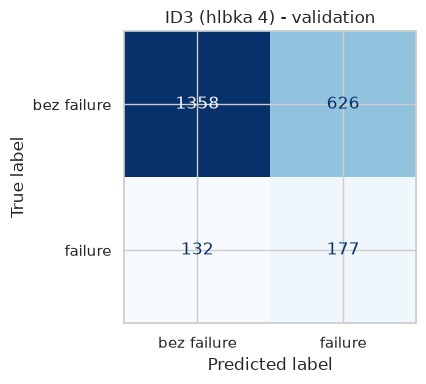

In [76]:
#3.1 B: vyhodnotenie ID3 (hlbka 4, 4 kose) na fit a validation casti
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

id3_demo_metrics = pd.DataFrame(
    [evaluate_classifier(id3_demo, X_id3_fit, y_id3_fit), evaluate_classifier(id3_demo, X_id3_val, y_id3_val)],
    index = ["fit", "validation"],
)
display(id3_demo_metrics.round(3))

print(classification_report(y_id3_val, id3_demo.predict(X_id3_val),
                            target_names = ["bez failure", "failure"], zero_division = 0))

fig, ax = plt.subplots(figsize = (4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_id3_val, id3_demo.predict(X_id3_val),
                                        display_labels = ["bez failure", "failure"],
                                        cmap = "Blues", colorbar = False, ax = ax)
ax.set_title("ID3 (hlbka 4) - validation")
plt.tight_layout()
plt.show()

Na fit aj validačnej časti sú výsledky blízko seba (balanced accuracy 0.634 vs. 0.629, ROC-AUC 0.701 vs. 0.693) - model hĺbky 4 nemá overfit. Zachytí 57 % porúch (177 z 309), ale precision je len 0.22: z 803 alarmov je 626 falošných, t. j. ~4.5 alarmu na jednu skutočnú poruchu. PR-AUC 0.300 je ~2× lepšia ako náhodný model (0.135).

### 3.1 C - Kontrola a riešenie overfittingu (2b)
Zistite, či Váš ID3 klasifikátor má overfit. Ak áno, riešte, aby nemal overfitting.

Overfitting posudzujeme rozdielom medzi výkonom na fit a validačnej časti pri rastúcej komplexite stromu (rovnaký postup ako v cvičení week-08 - `model_complexity` vs. chyba). Najprv natrénujeme **neobmedzený** ID3 (`max_depth=None` - strom rastie, kým nie sú listy čisté alebo sa neminú atribúty), potom krivku komplexity pre hĺbky 2-9 a rôzny počet košov (jemnejšia diskretizácia = viac vetiev = komplexnejší strom).

In [77]:
#3.1 C: neobmedzeny ID3 - strom rastie, kym nie su listy ciste / neminu sa atributy
id3_unbounded = make_id3_model(max_depth = None, n_bins = 4).fit(X_id3_fit, y_id3_fit)
display(pd.DataFrame(
    [evaluate_classifier(id3_unbounded, X_id3_fit, y_id3_fit), evaluate_classifier(id3_unbounded, X_id3_val, y_id3_val)],
    index = ["fit", "validation"],
).round(3))
tree_unbounded = id3_unbounded.named_steps["id3"].estimator_
print(f"neobmedzeny ID3 - hlbka: {tree_unbounded.get_depth()}, listy: {tree_unbounded.get_n_leaves()}")

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
fit,0.669,0.808,0.262,0.992,0.415,0.829,0.282
validation,0.581,0.575,0.175,0.566,0.267,0.582,0.161


neobmedzeny ID3 - hlbka: 10, listy: 1248


Neobmedzený ID3 použil na niektorých cestách všetkých 9 atribútov (hĺbka 10) a má 1 248 listov - na 2 182 vyvážených trénovacích meraní to je menej ako 2 merania na list. Na fit časti má recall 0.992 a balanced accuracy 0.808, na validácii len 0.575 a PR-AUC 0.161 (horšie ako strom hĺbky 4). Rozdiel fit - validation **0.233** je jasný dôkaz **overfittingu**. Fit skóre nie je 1.0 len preto, že po diskretizácii majú niektoré merania rovnaké hodnoty všetkých atribútov, ale rôzny `failure` - také dvojice raw ID3 rozlíšiť nevie.

Krivka komplexity: pre každú kombináciu hĺbky a počtu košov natrénujeme ID3 na fit časti a zmeriame balanced accuracy, F1 a PR-AUC na fit aj validačnej časti.

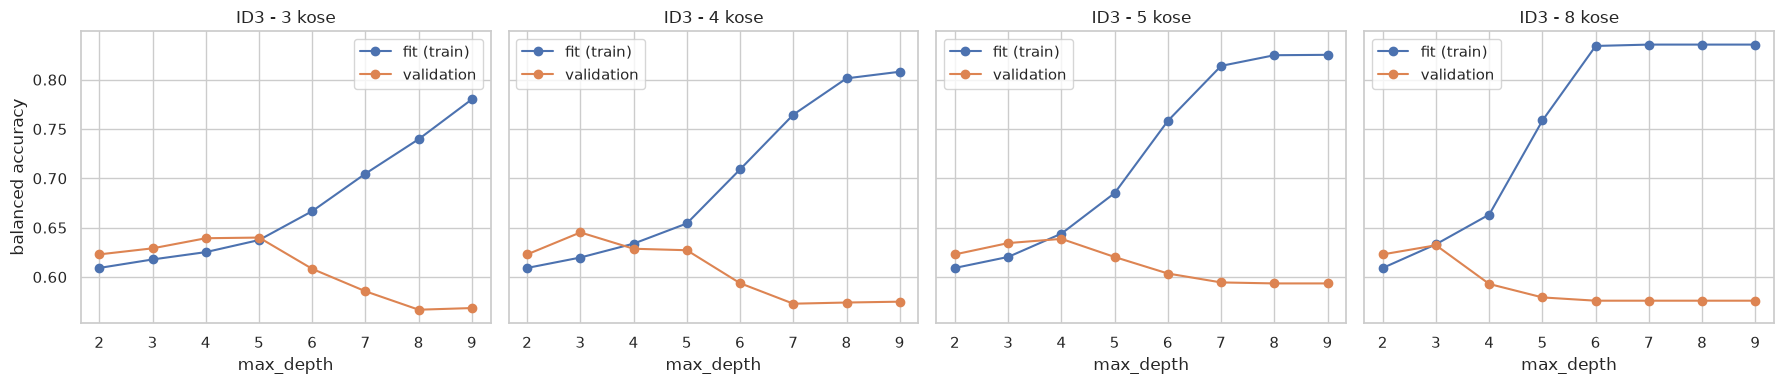

listy  fit_balanced_accuracy  val_balanced_accuracy  \
n_bins max_depth                                                        
5      4             69                  0.644                  0.639   
4      4             46                  0.634                  0.629   
3      4             25                  0.625                  0.639   
8      3             24                  0.633                  0.632   
5      3             14                  0.620                  0.634   
3      5             72                  0.637                  0.640   
4      3             12                  0.620                  0.645   
       5            178                  0.654                  0.627   

                  fit_pr_auc  val_pr_auc  val_roc_auc  fit_f1  val_f1  \
n_bins max_depth                                                        
5      4               0.252       0.304        0.711   0.301   0.324   
4      4               0.249       0.300        0.693   0.295   0.318   
3      4               0.226       0.257        0.685   0.285   0.325   
8      3               0.206       0.249        0.690   0.284   0.312   
5      3               0.208       0.247        0.689   0.272   0.309   
3      5               0.230       0.242        0.677   0.292   0.322   
4      3               0.196       0.236        0.695   0.274   0.323   
       5               0.230       0.224        0.659   0.307   0.313   

                  gap_balanced_accuracy  
n_bins max_depth                         
5      4                          0.005  
4      4                          0.005  
3      4                         -0.014  
8      3                          0.001  
5      3                         -0.014  
3      5                         -0.002  
4      3                         -0.025  
       5                          0.027

vybrane: max_depth = 4, n_bins = 5


In [78]:
#3.1 C: krivka komplexity ID3 (hlbka x pocet kosov), vyhodnotenie na fit aj validation
id3_complexity_rows = []
for n_bins in [3, 4, 5, 8]:
    for depth in range(2, 10):
        model = make_id3_model(max_depth = depth, n_bins = n_bins).fit(X_id3_fit, y_id3_fit)
        fit_m = evaluate_classifier(model, X_id3_fit, y_id3_fit)
        val_m = evaluate_classifier(model, X_id3_val, y_id3_val)
        id3_complexity_rows.append({
            "n_bins": n_bins, "max_depth": depth, "listy": model.named_steps["id3"].estimator_.get_n_leaves(),
            "fit_balanced_accuracy": fit_m["balanced_accuracy"], "val_balanced_accuracy": val_m["balanced_accuracy"],
            "fit_pr_auc": fit_m["pr_auc"], "val_pr_auc": val_m["pr_auc"], "val_roc_auc": val_m["roc_auc"],
            "fit_f1": fit_m["f1"], "val_f1": val_m["f1"],
        })
id3_complexity = pd.DataFrame(id3_complexity_rows)
id3_complexity["gap_balanced_accuracy"] = id3_complexity["fit_balanced_accuracy"] - id3_complexity["val_balanced_accuracy"]

fig, axes = plt.subplots(1, 4, figsize = (18, 4), sharey = True)
for ax, n_bins in zip(axes, [3, 4, 5, 8]):
    part = id3_complexity[id3_complexity["n_bins"] == n_bins]
    ax.plot(part["max_depth"], part["fit_balanced_accuracy"], marker = "o", label = "fit (train)")
    ax.plot(part["max_depth"], part["val_balanced_accuracy"], marker = "o", label = "validation")
    ax.set_title(f"ID3 - {n_bins} kose")
    ax.set_xlabel("max_depth")
    ax.legend()
axes[0].set_ylabel("balanced accuracy")
plt.tight_layout()
plt.show()

#vyber: najlepsia validacna PR-AUC spomedzi nastaveni s malou medzerou fit - validation (bez overfitu)
id3_candidates = id3_complexity[id3_complexity["gap_balanced_accuracy"] <= 0.03]
id3_best = id3_candidates.loc[id3_candidates["val_pr_auc"].idxmax()]
ID3_MAX_DEPTH, ID3_N_BINS = int(id3_best["max_depth"]), int(id3_best["n_bins"])
display(id3_complexity.sort_values("val_pr_auc", ascending = False).head(8).set_index(["n_bins", "max_depth"]).round(3))
print(f"vybrane: max_depth = {ID3_MAX_DEPTH}, n_bins = {ID3_N_BINS}")

Krivky majú typický tvar z cvičenia week-08: fit skóre s hĺbkou stále rastie, validačné má maximum pri hĺbke 3-5 a potom klesá. **Jemnejšia diskretizácia zrýchľuje overfit** - pri 8 košoch klesá validácia už od hĺbky 4, pri 3 košoch až od hĺbky 6, lebo každé delenie vytvorí viac vetiev s menším počtom meraní.

**Riešenie overfittingu = pre-pruning** `max_depth=4` pri **5 košoch**: najvyššia validačná PR-AUC (0.304) a ROC-AUC (0.711) spomedzi nastavení s malou medzerou (balanced accuracy fit 0.644 vs. validation 0.639, rozdiel 0.005). Najvyššiu validačnú balanced accuracy mal síce variant 4 koše / hĺbka 3 (0.645), ale s PR-AUC len 0.236 - horšie zoraďuje merania podľa rizika.

Vybrané nastavenie natrénujeme na celej trénovacej množine (`train_transformed` z 2.3 B) a raz vyhodnotíme aj na odloženom teste. Ako kontrolu porovnáme s neobmedzeným stromom na rovnakých dátach.

In [79]:
#3.1 C: finalny ID3 (pre-pruning podla krivky komplexity) - fit na celom train, vyhodnotenie na test
y_train_model = df_train["failure"].astype(int).to_numpy()
y_test_model = df_test["failure"].astype(int).to_numpy()

id3_model = make_id3_model(max_depth = ID3_MAX_DEPTH, n_bins = ID3_N_BINS).fit(train_transformed, y_train_model)
id3_full_unbounded = make_id3_model(max_depth = None, n_bins = ID3_N_BINS).fit(train_transformed, y_train_model)

id3_final_rows = []
for name, model in [("ID3 - neobmedzeny", id3_full_unbounded), ("ID3 - orezany (finalny)", id3_model)]:
    for split, X_split, y_split in [("train", train_transformed, y_train_model), ("test", test_transformed, y_test_model)]:
        id3_final_rows.append({"model": name, "mnozina": split, **evaluate_classifier(model, X_split, y_split)})
id3_final = pd.DataFrame(id3_final_rows).set_index(["model", "mnozina"])
display(id3_final.round(3))

for name, model in [("ID3 - neobmedzeny", id3_full_unbounded), ("ID3 - orezany (finalny)", id3_model)]:
    tree = model.named_steps["id3"].estimator_
    gap = id3_final.loc[(name, "train"), "balanced_accuracy"] - id3_final.loc[(name, "test"), "balanced_accuracy"]
    print(f"{name}: hlbka {tree.get_depth()}, listy {tree.get_n_leaves()}, "
          f"rozdiel balanced accuracy train - test = {gap:.3f}")

accuracy  balanced_accuracy  precision  \
model                   mnozina                                           
ID3 - neobmedzeny       train       0.692              0.824      0.283   
                        test        0.597              0.573      0.158   
ID3 - orezany (finalny) train       0.653              0.645      0.203   
                        test        0.649              0.630      0.193   

                                 recall     f1  roc_auc  pr_auc  
model                   mnozina                                  
ID3 - neobmedzeny       train     0.998  0.441    0.849   0.315  
                        test      0.542  0.245    0.584   0.145  
ID3 - orezany (finalny) train     0.636  0.308    0.708   0.263  
                        test      0.605  0.293    0.683   0.227

ID3 - neobmedzeny: hlbka 9, listy 1645, rozdiel balanced accuracy train - test = 0.251
ID3 - orezany (finalny): hlbka 4, listy 70, rozdiel balanced accuracy train - test = 0.015


Na celej trénovacej množine sa potvrdil rovnaký obraz: neobmedzený ID3 (hĺbka 9, 1 645 listov) má train balanced accuracy 0.824 a test 0.573, medzera **0.251**. Orezaný ID3 (hĺbka 4, 70 listov) má train 0.645 a test 0.630, medzera len **0.015** - overfitting je odstránený. Na teste zachytí 61 % porúch (recall 0.605, precision 0.193, F1 0.293, ROC-AUC 0.683, PR-AUC 0.227). Tento model (`id3_model` - diskretizácia + undersampling + ID3) ďalej porovnávame v 3.2.

## 3.2 Trénovanie a vyhodnotenie klasifikátorov strojového učenia (5b)

### 3.2 A - Stromový algoritmus v scikit-learn (1b)
Na trénovanie využite jeden **stromový algoritmus** v scikit-learn.

Ako stromový algoritmus použijeme `DecisionTreeClassifier` (CART). Používame rovnaké kritérium ako ID3 (`criterion="entropy"`, informačný zisk), ale CART sa od raw ID3 líši v podstatných veciach: pracuje priamo so **spojitými** atribútmi a delí **binárne** podľa najlepšieho prahu (`x <= t`), ten istý atribút môže použiť opakovane a nevyváženosť tried rieši váhami (`class_weight="balanced"`) namiesto undersamplingu, takže sa učí zo všetkých trénovacích meraní. Komplexitu obmedzíme miernym pre-pruningom `max_depth=4` (v sklearn má koreň hĺbku 0, t. j. 4 úrovne delení) a `min_samples_leaf=50`. Hyperparametre zámerne neladíme, to je náplňou 3.3.

Trénujeme na rovnakých dátach ako finálny ID3: `train_transformed` (výstup `preprocessing_pipeline` z 2.3 B, 9 atribútov vybraných v 2.2 B).

In [80]:
#3.2 A: stromovy algoritmus - DecisionTreeClassifier (CART) s entropiou a miernym pre-pruningom
from sklearn.tree import DecisionTreeClassifier

DT_MAX_DEPTH, DT_MIN_SAMPLES_LEAF = 4, 50

decision_tree_model = DecisionTreeClassifier(
    criterion = "entropy",
    max_depth = DT_MAX_DEPTH, #sklearn: koren = hlbka 0
    min_samples_leaf = DT_MIN_SAMPLES_LEAF,
    class_weight = "balanced",
    random_state = 42,
)
decision_tree_model.fit(train_transformed, y_train_model)
print(f"Decision Tree - hlbka (sklearn, koren = 0): {decision_tree_model.get_depth()}, listy: {decision_tree_model.get_n_leaves()}")
print(f"ID3           - hlbka (koren = 1): {id3_model.named_steps['id3'].estimator_.get_depth()}, listy: {id3_model.named_steps['id3'].estimator_.get_n_leaves()}")

Decision Tree - hlbka (sklearn, koren = 0): 4, listy: 16
ID3           - hlbka (koren = 1): 4, listy: 70


### 3.2 B - Nestromový algoritmus v scikit-learn (1b)
Porovnajte s jedným iným **nestromovým algoritmom** v scikit-learn.

Ako nestromový algoritmus volíme **logistickú regresiu** (cvičenie week-07). Je to lineárny model - pravdepodobnosť `failure` modeluje ako sigmoidu lineárnej kombinácie atribútov - teda principiálne odlišný prístup od stromov, ktoré delia priestor na obdĺžnikové oblasti. Pre logistickú regresiu má zmysel práve naše predspracovanie z 2.1 C: je citlivá na mierku atribútov (preto `StandardScaler`) aj na zošikmené rozdelenia (preto `PowerTransformer` pri `filterDp`, `rms_vibration`, `serviceHours`). Stromy sú voči monotónnym transformáciám invariantné. Aj tu použijeme `class_weight="balanced"`, regularizáciu necháme na predvolenej hodnote `C=1.0` (ladenie v 3.3).

In [81]:
#3.2 B: nestromovy algoritmus - logisticka regresia na skalovanych/transformovanych atributoch
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(class_weight = "balanced", max_iter = 2000, random_state = 42)
logistic_model.fit(train_transformed, y_train_model)

display(pd.Series(logistic_model.coef_[0], index = out_cols, name = "koeficient").sort_values(key = abs, ascending = False)
        .to_frame().round(3))
print(f"intercept: {logistic_model.intercept_[0]:.3f}")

,koeficient
categorical__class_duty,-1.505
other__currentMotor,0.848
skewed__serviceHours,0.359
skewed__filterDp,0.306
other__reservoir_pressure,-0.225
other__dewpointDischarge,0.196
skewed__rms_vibration,0.081
other__Flowmeter,-0.072
other__oilTemperature,0.000


intercept: 1.073


Najväčší koeficient má `class_duty` (-1.51 na jednu úroveň `light -> medium -> heavy`) - zhodne s koreňom ID3 majú ľahko zaťažované jednotky vyššie riziko poruchy. Kladný vplyv majú `currentMotor` (+0.85), `serviceHours` (+0.36) a `filterDp` (+0.31) - vyšší odber prúdu motora, viac motohodín a vyšší tlakový rozdiel na filtri zvyšujú pravdepodobnosť `failure` (súhlasí s hypotézami H1/H2 z 1.3). `oilTemperature` má koeficient ≈ 0 - v lineárnom modeli prakticky nič nepridáva.

### 3.2 C - Porovnanie s ID3 z prvého kroku (1b)
Porovnajte výsledky s ID3 z prvého kroku.

Všetky tri modely (finálny ID3 z 3.1 C, Decision Tree, Logistic Regression) vyhodnotíme rovnakou funkciou `evaluate_classifier` na trénovacej aj testovacej množine. Test slúži len na porovnanie - na jeho základe nič nenastavujeme.

In [82]:
#3.2 C: vyhodnotenie vsetkych troch modelov na train a test
models_32 = {
    "ID3": id3_model,
    "Decision Tree": decision_tree_model,
    "Logistic Regression": logistic_model,
}

results_32_rows = []
for model_name, model in models_32.items():
    for split_name, X_split, y_split in [("train", train_transformed, y_train_model), ("test", test_transformed, y_test_model)]:
        results_32_rows.append({"model": model_name, "mnozina": split_name, **evaluate_classifier(model, X_split, y_split)})
metrics_32 = pd.DataFrame(results_32_rows).set_index(["model", "mnozina"])

metrics_32_test = metrics_32.xs("test", level = "mnozina")
gap_32 = metrics_32.xs("train", level = "mnozina") - metrics_32_test

print("Testovacia mnozina (zoradene podla PR-AUC):")
display(metrics_32_test.sort_values("pr_auc", ascending = False).round(3))
print("Rozdiel train - test (kladny = horsie na teste):")
display(gap_32[["balanced_accuracy", "recall", "f1", "roc_auc", "pr_auc"]].round(3))

Testovacia mnozina (zoradene podla PR-AUC):


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Logistic Regression,0.678,0.683,0.226,0.689,0.340,0.729,0.320
Decision Tree,0.719,0.656,0.231,0.573,0.330,0.710,0.267
ID3,0.649,0.630,0.193,0.605,0.293,0.683,0.227


Rozdiel train - test (kladny = horsie na teste):


,balanced_accuracy,recall,f1,roc_auc,pr_auc
model,,,,,
ID3,0.015,0.031,0.015,0.025,0.036
Decision Tree,0.011,0.004,0.017,0.030,0.049
Logistic Regression,-0.010,-0.007,-0.008,0.001,0.021


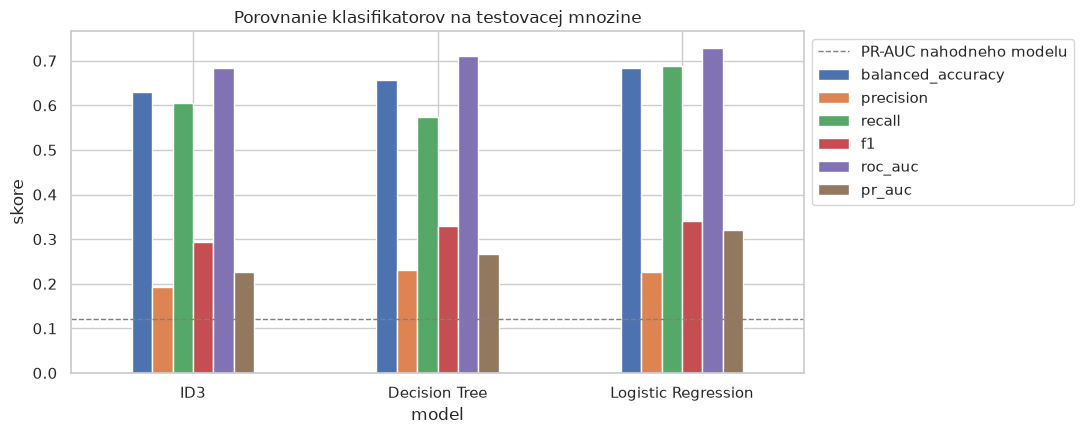

In [83]:
#3.2 C: graficke porovnanie hlavnych metrik na testovacej mnozine
ax = metrics_32_test[["balanced_accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].plot(kind = "bar", figsize = (11, 4.5))
ax.axhline(y_test_model.mean(), color = "grey", linestyle = "--", linewidth = 1, label = "PR-AUC nahodneho modelu")
ax.set_ylabel("skore")
ax.set_title("Porovnanie klasifikatorov na testovacej mnozine")
ax.legend(loc = "upper left", bbox_to_anchor = (1, 1))
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

**Logistic Regression je na teste najlepšia** vo všetkých prahovo nezávislých metrikách (ROC-AUC 0.729, PR-AUC 0.320) aj v balanced accuracy (0.683) a recalle (0.689). Nasleduje Decision Tree (balanced accuracy 0.656, ROC-AUC 0.710, PR-AUC 0.267) a náš ID3 (0.630 / 0.683 / 0.227). Všetky tri sú výrazne nad náhodným modelom (PR-AUC 0.12), ale precision je pri všetkých nízka (0.19-0.23).

Rozdiely train - test sú malé pri všetkých modeloch (balanced accuracy ≤ 0.016), žiadny z nich teda nemá overfit. Najstabilnejšia je logistická regresia (rozdiely ≈ 0, na teste dokonca mierne lepšia).

**ID3 vs. Decision Tree:** CART je o 0.026 lepší v balanced accuracy a o 0.04 v PR-AUC. Raw ID3 je principiálne obmedzenejší: (1) diskretizácia do 5 košov stratí informáciu o presnej hodnote (CART si prah nájde sám), (2) každý atribút môže použiť na ceste len raz, (3) delenie na všetky hodnoty rýchlo trieští dáta (70 listov pri hĺbke 4 oproti 16 pri CART), (4) kvôli undersamplingu sa učí len z ~2 800 meraní namiesto 11 514.

Oba stromy používajú informačný zisk - pozrieme, nakoľko sa zhodujú v samotných predikciách a ktorý atribút si zvolili do koreňa.

In [84]:
#3.2 C: zhoda predikcii ID3 vs Decision Tree na teste a atribut v koreni
id3_test_pred = id3_model.predict(test_transformed)
dt_test_pred = decision_tree_model.predict(test_transformed)
print(f"zhoda predikcii ID3 a Decision Tree na teste: {(id3_test_pred == dt_test_pred).mean():.3f}")
id3_root = id3_model.named_steps['id3'].estimator_.tree_
print(f"koren ID3: {out_cols[id3_root['attribute']]} (vetvenie na {len(id3_root['children'])} hodnoty, IG = {id3_root['gain']:.3f})")
print(f"koren DT:  {out_cols[decision_tree_model.tree_.feature[0]]} <= {decision_tree_model.tree_.threshold[0]:.3f}")

zhoda predikcii ID3 a Decision Tree na teste: 0.745
koren ID3: categorical__class_duty (vetvenie na 3 hodnoty, IG = 0.039)
koren DT:  categorical__class_duty <= 0.500


Oba stromy vybrali do koreňa ten istý atribút `class_duty` - ID3 sa vetví na všetky 3 hodnoty, CART binárne na `light` vs. ostatné. Na teste sa zhodujú v **74.5 %** predikcií; rozdiely vznikajú v hlbších úrovniach, kde ID3 pracuje s košmi a CART s presnými prahmi.

### 3.2 D - Vizualizácia natrénovaných pravidiel (1b)
Vizualizujte natrénované pravidlá minimálne pre jeden Vami vybraný algoritmus.

Pravidlá vizualizujeme pre `DecisionTreeClassifier` cez `plot_tree` (prvé 3 úrovne, aby bol graf čitateľný) a textovo cez `export_text`. Prahy sú v transformovaných jednotkách (po `PowerTransformer`/`StandardScaler`), ktoré sa ťažko interpretujú, preto ich nižšie pomocou inverzných transformácií z fitnutého `preprocessing_pipeline` prevedieme aj späť do pôvodných jednotiek senzorov.

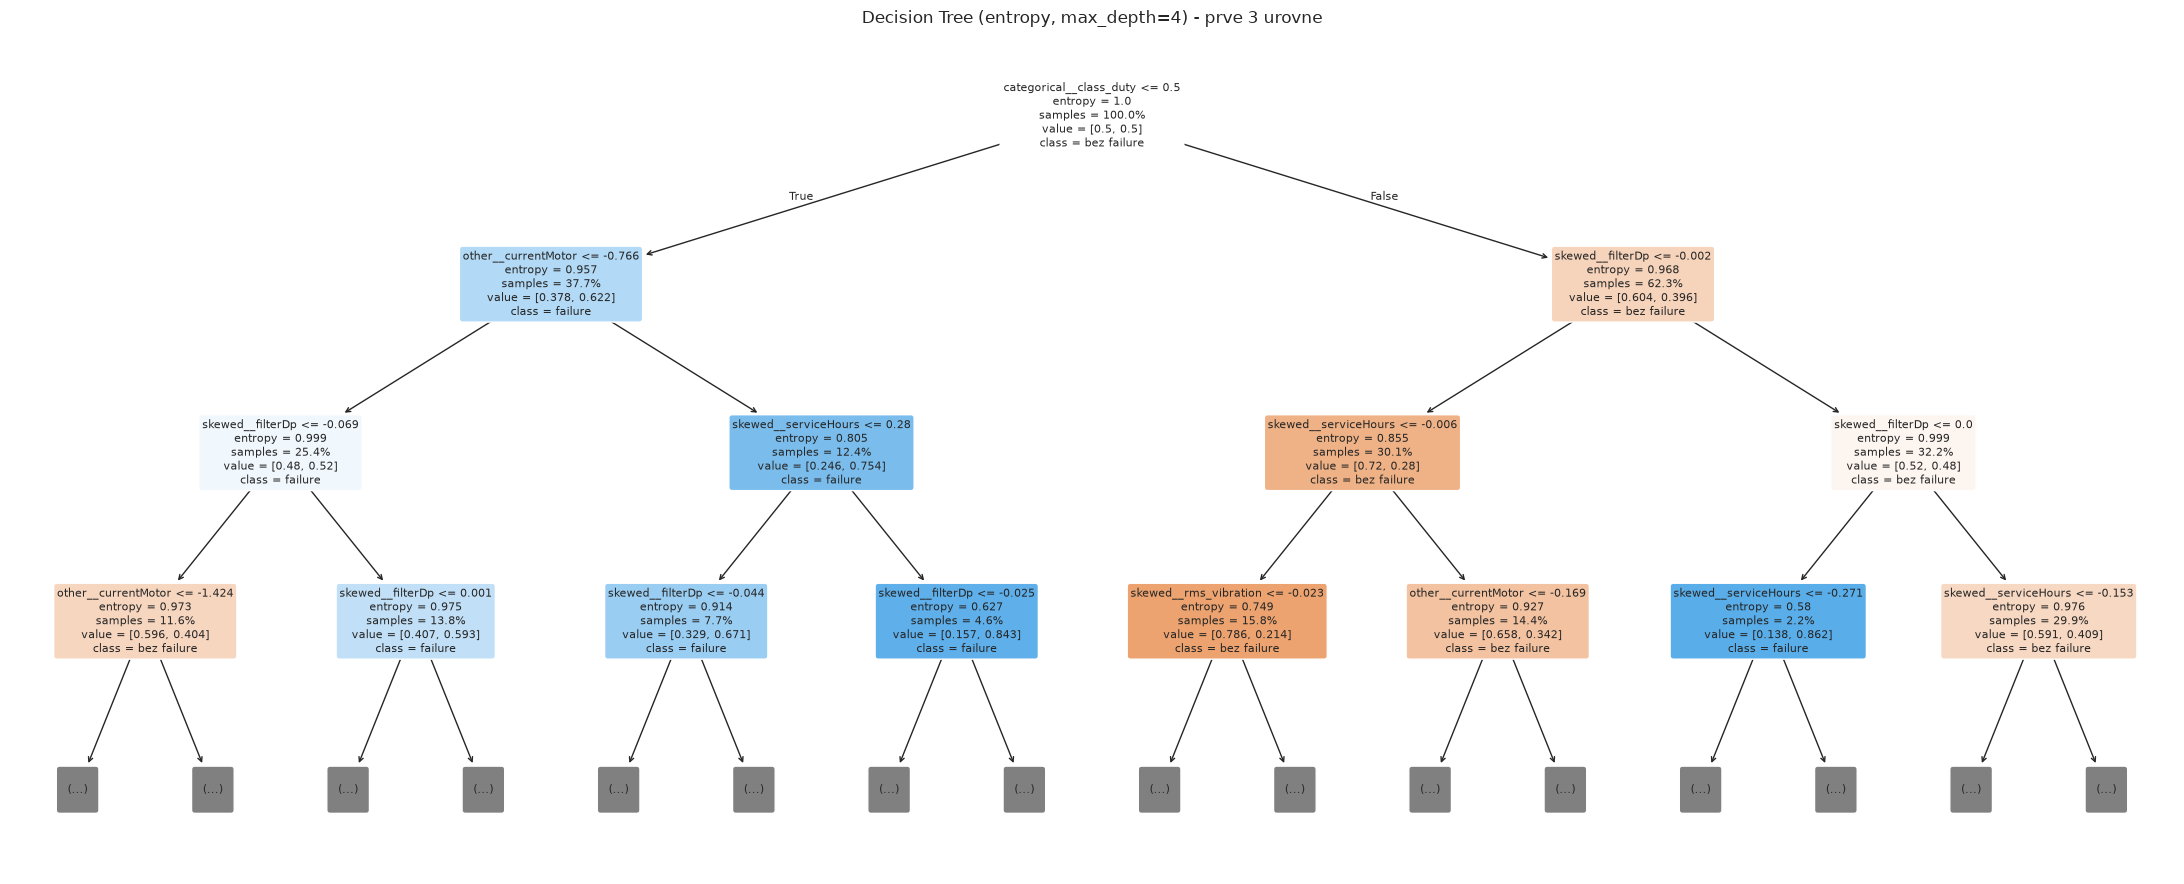

|--- categorical__class_duty <= 0.50
|   |--- other__currentMotor <= -0.77
|   |   |--- skewed__filterDp <= -0.07
|   |   |   |--- other__currentMotor <= -1.42
|   |   |   |   |--- class: 0
|   |   |   |--- other__currentMotor >  -1.42
|   |   |   |   |--- class: 0
|   |   |--- skewed__filterDp >  -0.07
|   |   |   |--- skewed__filterDp <= 0.00
|   |   |   |   |--- class: 1
|   |   |   |--- skewed__filterDp >  0.00
|   |   |   |   |--- class: 1
|   |--- other__currentMotor >  -0.77
|   |   |--- skewed__serviceHours <= 0.28
|   |   |   |--- skewed__filterDp <= -0.04
|   |   |   |   |--- class: 1
|   |   |   |--- skewed__filterDp >  -0.04
|   |   |   |   |--- class: 1
|   |   |--- skewed__serviceHours >  0.28
|   |   |   |--- skewed__filterDp <= -0.02
|   |   |   |   |--- class: 1
|   |   |   |--- skewed__filterDp >  -0.02
|   |   |   |   |--- class: 1
|--- categorical__class_duty >  0.50
|   |--- skewed__filterDp <= -0.00
|   |   |--- skewed__serviceHours <= -0.01
|   |   |   |--- skewe

In [85]:
#3.2 D: vizualizacia stromu - prve 3 urovne
from sklearn.tree import plot_tree, export_text

feature_names_32 = [str(c) for c in out_cols]
fig, ax = plt.subplots(figsize = (22, 9))
plot_tree(decision_tree_model, feature_names = feature_names_32, class_names = ["bez failure", "failure"],
          filled = True, rounded = True, max_depth = 3, fontsize = 8, proportion = True, ax = ax)
ax.set_title("Decision Tree (entropy, max_depth=4) - prve 3 urovne")
plt.tight_layout()
plt.show()

print(export_text(decision_tree_model, feature_names = feature_names_32, max_depth = 3, show_weights = False))

Prevod prahov do pôvodných jednotiek: pre zošikmené atribúty invertujeme `StandardScaler` a potom `PowerTransformer`, pre ostatné len `StandardScaler`, pre `class_duty` prah prevedieme na kategórie `light < medium < heavy`.

In [86]:
#3.2 D: pravidla Decision Tree v povodnych jednotkach (inverzia transformacii z preprocessing_pipeline)
fitted_ct = preprocessing_pipeline.named_steps["preprocess"]

def threshold_to_original(feature_name, value):
    branch, col = feature_name.split("__", 1)
    if branch == "categorical":
        levels = list(fitted_ct.named_transformers_["categorical"].named_steps["ordinal"].categories_[0])
        return "{" + ", ".join(levels[: int(np.floor(value)) + 1]) + "}"
    cols = skewed_numeric_cols if branch == "skewed" else other_numeric_cols
    steps = fitted_ct.named_transformers_[branch].named_steps
    row = np.zeros((1, len(cols)))
    row[0, cols.index(col)] = value
    row = steps["scaler"].inverse_transform(row)
    if branch == "skewed":
        row = steps["power"].inverse_transform(row)
    return f"{row[0, cols.index(col)]:.2f}"

def export_rules_original(tree_model, max_depth = 3):
    t = tree_model.tree_
    lines = []
    def walk(node, depth, indent):
        if t.children_left[node] == -1 or depth > max_depth:
            dist = t.value[node][0] / t.value[node][0].sum()
            n = t.n_node_samples[node]
            lines.append(f"{indent}--> {'FAILURE' if np.argmax(dist) == 1 else 'bez failure'} (n={n})")
            return
        name = feature_names_32[t.feature[node]]
        orig = threshold_to_original(name, t.threshold[node])
        short = name.split("__", 1)[1]
        if name.startswith("categorical"):
            lines.append(f"{indent}{short} in {orig}")
            walk(t.children_left[node], depth + 1, indent + "|   ")
            lines.append(f"{indent}{short} not in {orig}")
        else:
            lines.append(f"{indent}{short} <= {orig}")
            walk(t.children_left[node], depth + 1, indent + "|   ")
            lines.append(f"{indent}{short} >  {orig}")
        walk(t.children_right[node], depth + 1, indent + "|   ")
    walk(0, 1, "")
    return "\n".join(lines)

print(export_rules_original(decision_tree_model, max_depth = 3))

class_duty in {light}
|   currentMotor <= 3.89
|   |   filterDp <= 20.86
|   |   |   --> bez failure (n=1330)
|   |   filterDp >  20.86
|   |   |   --> FAILURE (n=1589)
|   currentMotor >  3.89
|   |   serviceHours <= 14424.85
|   |   |   --> FAILURE (n=887)
|   |   serviceHours >  14424.85
|   |   |   --> FAILURE (n=535)
class_duty not in {light}
|   filterDp <= 21.41
|   |   serviceHours <= 12218.33
|   |   |   --> bez failure (n=1817)
|   |   serviceHours >  12218.33
|   |   |   --> bez failure (n=1654)
|   filterDp >  21.41
|   |   filterDp <= 21.43
|   |   |   --> FAILURE (n=255)
|   |   filterDp >  21.43
|   |   |   --> bez failure (n=3447)


V pôvodných jednotkách sú pravidlá interpretovateľné:
- **`light` jednotky:** pri `currentMotor > 3.89` je predikcia vždy FAILURE, pri nižšom prúde rozhoduje `filterDp > 20.86`.
- **`medium`/`heavy` jednotky:** pri `filterDp <= 21.41` vždy „bez failure“; pri vyššom `filterDp` je FAILURE len v **extrémne úzkom intervale `21.41 < filterDp <= 21.43`** (255 meraní).

Hodnota 21.43 je presne **medián `filterDp` v train**, ktorým `SimpleImputer` v 2.1 B nahradil chýbajúce merania. Strom sa teda naučil pravidlo „`filterDp` chýba -> porucha“.

Pravidlá s veľmi úzkymi intervalmi okolo stredu rozdelenia `filterDp` (a podobne `rms_vibration`) naznačujú, že strom zachytáva hodnotu, ktorou sme v 2.1 B **imputovali chýbajúce merania (medián)**. Overíme, či chýbajúca hodnota súvisí s `failure`.

In [87]:
#3.2 D: overenie - suvisi chybajuca hodnota senzora s failure? (len train)
missing_check = pd.DataFrame({
    col: {
        "podiel_NaN": df_train[col].isna().mean(),
        "miera_failure_ak_NaN": df_train.loc[df_train[col].isna(), "failure"].mean(),
        "miera_failure_ak_namerane": df_train.loc[df_train[col].notna(), "failure"].mean(),
    }
    for col in ["filterDp", "rms_vibration", "serviceHours", "currentMotor", "oilTemperature"]
}).T
display(missing_check.round(3))

,podiel_NaN,miera_failure_ak_NaN,miera_failure_ak_namerane
filterDp,0.041,0.583,0.102
rms_vibration,0.036,0.550,0.106
serviceHours,0.050,0.107,0.122
currentMotor,0.001,0.000,0.122
oilTemperature,0.003,0.273,0.121


Potvrdené: keď chýba `filterDp`, je miera `failure` **58.3 %** oproti 10.2 % pri nameranej hodnote; pri `rms_vibration` 55.0 % vs. 10.6 %. Chýbajúce merania `filterDp` (4.1 % riadkov) obsahujú ~20 % všetkých porúch v train. Chýbanie týchto dvoch senzorov teda **nie je náhodné (MNAR)** - výpadok merania zrejme súvisí s poruchou zariadenia. Pri `serviceHours`, `currentMotor` (1 riadok) ani `oilTemperature` (0.3 %) taký efekt nie je.

Dôsledky: (1) imputácia mediánom túto informáciu „skrýva“ do jednej hodnoty, ktorú strom vie nájsť len náhodným úzkym prahom a logistická regresia vôbec (medián leží v strede škály); (2) ide o skutočný signál, nie únik z testu - imputer je fitovaný len na train a test má rovnaký mechanizmus. V 3.4 preto otestujeme úpravu predspracovania `SimpleImputer(add_indicator=True)` (binárny stĺpec „hodnota chýbala“) a jej vplyv na kvalitu klasifikácie.

Okrem pravidiel stromu vizualizujeme aj to, čo sa naučili ostatné modely - dôležitosť atribútov v Decision Tree (pokles váženej entropie) a absolútne koeficienty logistickej regresie (atribúty sú štandardizované, takže veľkosti sú približne porovnateľné; výnimkou je ordinálny `class_duty` v škále 0-2).

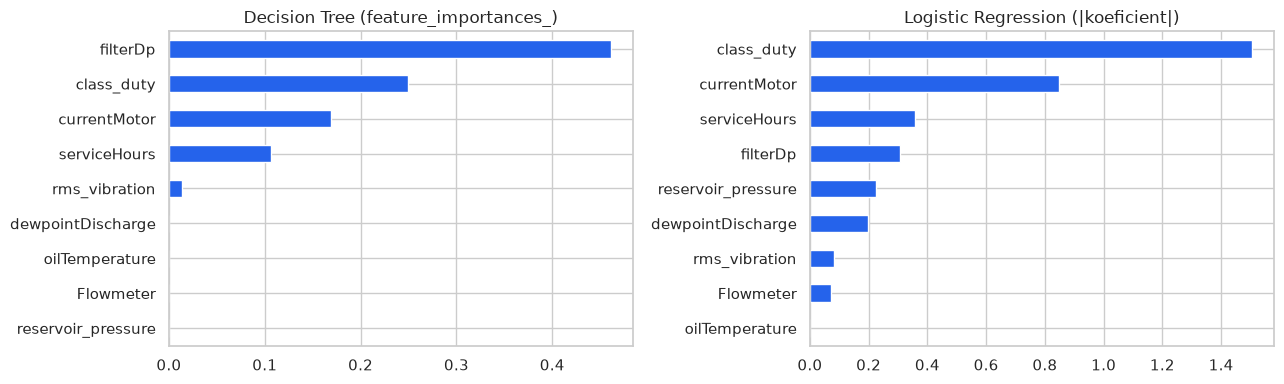

In [88]:
#3.2 D: dolezitost atributov - Decision Tree vs koeficienty logistickej regresie
importance_32 = pd.DataFrame({
    "Decision Tree (feature_importances_)": decision_tree_model.feature_importances_,
    "Logistic Regression (|koeficient|)": np.abs(logistic_model.coef_[0]),
}, index = [c.split("__", 1)[1] for c in out_cols])

fig, axes = plt.subplots(1, 2, figsize = (13, 4))
for ax, col in zip(axes, importance_32.columns):
    importance_32[col].sort_values().plot(kind = "barh", ax = ax, color = "#2563eb")
    ax.set_title(col)
plt.tight_layout()
plt.show()

Decision Tree stavia takmer polovicu rozhodovania na `filterDp` (importance 0.46, vrátane pravidla o imputovanom mediáne), ďalej `class_duty` (0.25), `currentMotor` (0.17) a `serviceHours` (0.11); `rms_vibration` len okrajovo (0.01) a zvyšné štyri atribúty vôbec. Logistická regresia má poradie `class_duty` > `currentMotor` > `serviceHours` > `filterDp` - `filterDp` je tu slabší, lebo lineárny model nevie využiť „špičku“ imputovaných hodnôt v strede rozdelenia. Oba modely sa zhodujú s top 4 atribútmi z 2.2 B; `oilTemperature` (9. v 2.2 B) je v oboch nevyužitý - kandidát na vyradenie v 3.4.

### 3.2 E - Vyhodnotenie natrénovaných modelov (1b)
Vyhodnoťte natrénované modely pomocou vhodných metrík.

Metriky z tabuľky v 3.2 C doplníme o **confusion matrix** (aké typy chýb modely robia), **classification report** pre obe triedy a **ROC / Precision-Recall krivky** na testovacej množine (prahovo nezávislé porovnanie, cvičenia week-06/week-07).

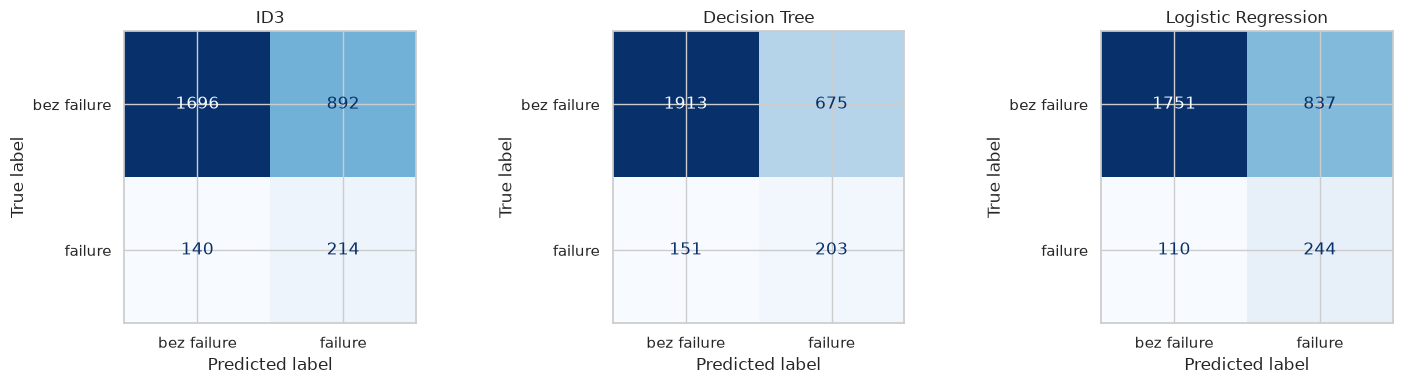

,TP (zachytene poruchy),FN (prehliadnute poruchy),FP (falosne alarmy),TN,alarmov na 1 skutocnu poruchu
model,,,,,
ID3,214,140,892,1696,5.17
Decision Tree,203,151,675,1913,4.33
Logistic Regression,244,110,837,1751,4.43


In [89]:
#3.2 E: confusion matrix pre vsetky tri modely na testovacej mnozine
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

fig, axes = plt.subplots(1, 3, figsize = (15, 4))
for ax, (model_name, model) in zip(axes, models_32.items()):
    ConfusionMatrixDisplay.from_estimator(model, test_transformed, y_test_model,
                                          display_labels = ["bez failure", "failure"],
                                          cmap = "Blues", colorbar = False, ax = ax)
    ax.set_title(model_name)
plt.tight_layout()
plt.show()

cm_rows = []
for model_name, model in models_32.items():
    tn, fp, fn, tp = confusion_matrix(y_test_model, model.predict(test_transformed)).ravel()
    cm_rows.append({"model": model_name, "TP (zachytene poruchy)": tp, "FN (prehliadnute poruchy)": fn,
                    "FP (falosne alarmy)": fp, "TN": tn, "alarmov na 1 skutocnu poruchu": (tp + fp) / max(tp, 1)})
display(pd.DataFrame(cm_rows).set_index("model").round(2))

In [90]:
#3.2 E: classification report pre obe triedy (test)
for model_name, model in models_32.items():
    print(f"{model_name} - classification report (test):")
    print(classification_report(y_test_model, model.predict(test_transformed),
                                target_names = ["bez failure", "failure"], zero_division = 0))

ID3 - classification report (test):
              precision    recall  f1-score   support

 bez failure       0.92      0.66      0.77      2588
     failure       0.19      0.60      0.29       354

    accuracy                           0.65      2942
   macro avg       0.56      0.63      0.53      2942
weighted avg       0.84      0.65      0.71      2942

Decision Tree - classification report (test):
              precision    recall  f1-score   support

 bez failure       0.93      0.74      0.82      2588
     failure       0.23      0.57      0.33       354

    accuracy                           0.72      2942
   macro avg       0.58      0.66      0.58      2942
weighted avg       0.84      0.72      0.76      2942

Logistic Regression - classification report (test):
              precision    recall  f1-score   support

 bez failure       0.94      0.68      0.79      2588
     failure       0.23      0.69      0.34       354

    accuracy                           0.68     

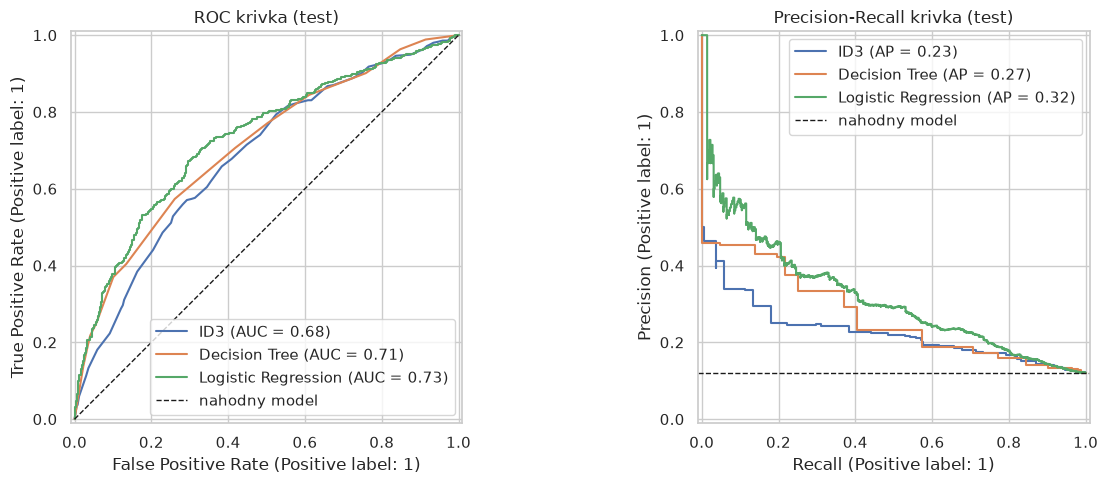

In [91]:
#3.2 E: ROC a Precision-Recall krivky na testovacej mnozine
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize = (13, 5))
for model_name, model in models_32.items():
    RocCurveDisplay.from_estimator(model, test_transformed, y_test_model, name = model_name, ax = axes[0])
    PrecisionRecallDisplay.from_estimator(model, test_transformed, y_test_model, name = model_name, ax = axes[1])
axes[0].plot([0, 1], [0, 1], "k--", linewidth = 1, label = "nahodny model")
axes[1].axhline(y_test_model.mean(), color = "k", linestyle = "--", linewidth = 1, label = "nahodny model")
axes[0].set_title("ROC krivka (test)")
axes[1].set_title("Precision-Recall krivka (test)")
for ax in axes:
    ax.legend(loc = "best")
plt.tight_layout()
plt.show()

**Confusion matrix:** z 354 porúch v teste zachytí Logistic Regression najviac (244, prehliadne 110), ID3 214 a Decision Tree 203. Decision Tree má zas najmenej falošných alarmov (675 vs. 837 pri LR a 892 pri ID3), preto má najvyššiu accuracy (0.72). Všetky modely vyvolajú ~4-5 alarmov na jednu skutočnú poruchu - dôsledok vyváženia tried (váhy / undersampling), ktoré uprednostňuje recall pred precision. Pri prediktívnej údržbe je to prijateľnejší kompromis (kontrola jednotky je lacnejšia ako neplánovaná odstávka), ale pomer by sa dal ladiť posunom rozhodovacieho prahu (3.4 C).

**Classification report:** trieda „bez failure“ má precision 0.92-0.94 - keď model povie „v poriadku“, takmer vždy má pravdu. Slabinou je precision triedy `failure` (0.19-0.23).

**ROC / PR krivky:** Logistic Regression má najvyššiu ROC (AUC 0.73) aj PR krivku (AP 0.32), Decision Tree je o niečo nižšie (0.71 / 0.27) a ID3 najnižšie (0.68 / 0.23). LR má plynulý priebeh (spojité pravdepodobnosti), stromy „schodíky“ - jedna hodnota pravdepodobnosti na list. Pri nízkom recalle (< 0.1) dosahuje LR precision 0.6-0.9, t. j. najrizikovejšie merania vie označiť spoľahlivo; pri vyššom recalle precision rýchlo klesá k ~0.2.

**Zhrnutie 3.2:**
- **3.2 A/B:** natrénovali sme `DecisionTreeClassifier` (CART, entropy, `max_depth=4`, `min_samples_leaf=50`) a `LogisticRegression` - oba s `class_weight="balanced"` na rovnakých dátach z `preprocessing_pipeline` (2.3 B).
- **3.2 C:** najlepšia je Logistic Regression (test balanced accuracy 0.683, PR-AUC 0.320), potom Decision Tree (0.656 / 0.267) a raw ID3 (0.630 / 0.227). ID3 a CART majú rovnaký koreň (`class_duty`) a zhodujú sa v 74.5 % predikcií; CART je lepší vďaka práci so spojitými hodnotami a učeniu zo všetkých dát.
- **3.2 D:** pravidlá stromu v pôvodných jednotkách ukázali, že `light` jednotky s vysokým `currentMotor` alebo `filterDp` sú rizikové, a odhalili, že **chýbajúce `filterDp`/`rms_vibration` silne indikujú poruchu (58 % / 55 % failure)** - informáciu, ktorú mediánová imputácia z fázy 2 čiastočne skrýva.
- **3.2 E:** žiadny model nemá overfit (rozdiel train - test v balanced accuracy ≤ 0.016). Modely zachytia 57-69 % porúch, ale s nízkou precision (~0.2), t. j. ~4-5 alarmov na jednu poruchu.

Do optimalizácie v 3.3 berieme **stromový prístup** (hĺbka/listy sú zatiaľ len odhad a stromy sa dajú skladať do ensemble - random forest, boosting) aj **Logistic Regression** (ladenie regularizácie `C`), ktorá je zatiaľ najlepším a najstabilnejším modelom. Ďalšie zlepšenie očakávame od indikátorov chýbajúcich hodnôt (3.4) a od ladenia hyperparametrov s krížovou validáciou po jednotkách (3.3).

## 3.3 Optimalizácia alias hyperparameter tuning (5b)

**Spoločné nastavenie pre celú 3.3.** Ako zvolený algoritmus optimalizujeme **rozhodovací strom** (`DecisionTreeClassifier` z 3.2 A): v 3.2 bol blízko logistickej regresii, jeho hyperparametre (hĺbka, listy) sme zatiaľ len odhadli z jedného validačného splitu a stromy sú základom ensemble metód (bagging, random forest, boosting).

Všetky experimenty robíme **krížovou validáciou len na trénovacej množine** (3.3 C), testovaciu množinu použijeme až pri finálnom modeli v 3.3 D:
- **`StratifiedGroupKFold` (5 foldov) so skupinami `id_unit`** - rovnako ako pri train/test splite (2.1 A) a validácii v 3.1 nesmú byť merania jednej jednotky súčasne v trénovacom aj validačnom folde, inak by CV skóre bolo nadhodnotené (group leakage).
- Ladíme **celý pipeline** `preprocessing (2.3 B) -> model`, takže imputácia a škálovanie sa fitujú v každom folde len na jeho trénovacej časti.
- Hlavná metrika je **PR-AUC** (`average_precision`) - prahovo nezávislá a vhodná pre nevyvážené triedy (3.1 B); sledujeme aj ROC-AUC, balanced accuracy a F1.
- **Ochrana pred overfitom priamo pri výbere:** z kandidátov vyberáme najlepšiu CV PR-AUC len spomedzi nastavení, kde je rozdiel `train - CV` PR-AUC najviac **0.05**. Najlepšie CV skóre totiž často dosahujú veľmi komplexné modely, ktoré trénovacie dáta takmer memorujú.

In [92]:
#3.3: spolocne nastavenie - vstupy pre cely pipeline, krizova validacia po jednotkach, metriky
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV, cross_validate, learning_curve, validation_curve,
)

X_train_raw = df_train[raw_input_cols]
X_test_raw = df_test[raw_input_cols]
groups_train = df_train["id_unit"].to_numpy()

cv_groups = StratifiedGroupKFold(n_splits = 5, shuffle = True, random_state = 42)
scoring_33 = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
}
MAX_PR_AUC_GAP = 0.05 #max. povoleny rozdiel train - CV v PR-AUC pri vybere nastavenia
pd.set_option("display.max_colwidth", 200) #aby sa v tabulkach zobrazili cele nastavenia hyperparametrov

def make_pipeline_33(model):
    #rovnake predspracovanie ako v 2.3 B (neftnuta kopia), na konci model
    return Pipeline([("preprocess", clone(preprocessing_pipeline.named_steps["preprocess"])), ("model", model)])

#kontrola foldov: ziadna jednotka v train aj validation casti, podobna miera failure
fold_rows = []
for k, (tr_idx, va_idx) in enumerate(cv_groups.split(X_train_raw, y_train_model, groups_train), start = 1):
    fold_rows.append({
        "fold": k, "merania_train": len(tr_idx), "merania_validation": len(va_idx),
        "jednotky_validation": len(np.unique(groups_train[va_idx])),
        "prekryv_jednotiek": len(set(groups_train[tr_idx]) & set(groups_train[va_idx])),
        "failure_validation": y_train_model[va_idx].mean(),
    })
display(pd.DataFrame(fold_rows).set_index("fold").round(3))

,merania_train,merania_validation,jednotky_validation,prekryv_jednotiek,failure_validation
fold,,,,,
1,9211,2303,316,0,0.122
2,9216,2298,321,0,0.121
3,9208,2306,317,0,0.122
4,9212,2302,320,0,0.121
5,9209,2305,324,0,0.122


Pomocné funkcie: výber nastavenia s najlepšou CV PR-AUC pri obmedzenej medzere train - CV (použije sa ako `refit` v `GridSearchCV`/`RandomizedSearchCV`) a prehľadná tabuľka výsledkov hľadania.

In [93]:
#3.3: vyber nastavenia bez overfitu (refit callable) a tabulka vysledkov ladenia
def select_without_overfit(cv_results):
    results = pd.DataFrame(cv_results)
    gap = results["mean_train_pr_auc"] - results["mean_test_pr_auc"]
    allowed = results[gap <= MAX_PR_AUC_GAP]
    if allowed.empty: #ak by ziadne nastavenie nesplnalo podmienku, berieme najmensiu medzeru
        return int(gap.idxmin())
    return int(allowed["mean_test_pr_auc"].idxmax())

def search_table(search, top = 8):
    results = pd.DataFrame(search.cv_results_)
    table = pd.DataFrame({
        "nastavenie": results["params"].apply(lambda p: {k.replace("model__", ""): v for k, v in p.items()}),
        "train_pr_auc": results["mean_train_pr_auc"],
        "cv_pr_auc": results["mean_test_pr_auc"],
        "cv_pr_auc_std": results["std_test_pr_auc"],
        "gap_pr_auc": results["mean_train_pr_auc"] - results["mean_test_pr_auc"],
        "cv_balanced_accuracy": results["mean_test_balanced_accuracy"],
        "cv_f1": results["mean_test_f1"],
        "cv_roc_auc": results["mean_test_roc_auc"],
    })
    table["vybrane"] = table.index == search.best_index_
    return table.sort_values("cv_pr_auc", ascending = False).head(top)

def summary_row(name, search = None, cv_result = None):
    #jeden riadok porovnania: bud z vybraneho nastavenia hladania, alebo z cross_validate
    if search is not None:
        r = pd.DataFrame(search.cv_results_).iloc[search.best_index_]
        get = lambda m, part = "test": r[f"mean_{part}_{m}"]
        std = r["std_test_pr_auc"]
    else:
        get = lambda m, part = "test": cv_result[f"{part}_{m}"].mean()
        std = cv_result["test_pr_auc"].std()
    return {
        "model": name, "train_pr_auc": get("pr_auc", "train"), "cv_pr_auc": get("pr_auc"), "cv_pr_auc_std": std,
        "gap_pr_auc": get("pr_auc", "train") - get("pr_auc"), "cv_roc_auc": get("roc_auc"),
        "cv_balanced_accuracy": get("balanced_accuracy"), "cv_f1": get("f1"),
    }

### 3.3 A - Ladenie hyperparametrov zvoleného algoritmu (1b)
Vyskúšajte rôzne nastavenia hyperparametrov (tuning) pre zvolený algoritmus tak, aby ste optimalizovali výkonnosť (bez underfitingu).

Pre `DecisionTreeClassifier` (s `class_weight="balanced"`) prehľadáme celú mriežku (`GridSearchCV`, 2 × 7 × 5 × 3 = 210 nastavení × 5 foldov):
- `criterion` - `entropy` (ID3 princíp) vs. `gini`,
- `max_depth` - 3 až 10 a bez obmedzenia (pre-pruning),
- `min_samples_leaf` - 1 až 200 (pre-pruning),
- `ccp_alpha` - cost-complexity **post-pruning** (cvičenie week-08), 0 = bez orezania.

In [94]:
#3.3 A: GridSearchCV pre Decision Tree - cely pipeline, CV po jednotkach, vyber bez overfitu
dt_param_grid = {
    "model__criterion": ["entropy", "gini"],
    "model__max_depth": [3, 4, 5, 6, 8, 10, None],
    "model__min_samples_leaf": [1, 20, 50, 100, 200],
    "model__ccp_alpha": [0.0, 0.001, 0.003],
}
dt_search = GridSearchCV(
    make_pipeline_33(DecisionTreeClassifier(class_weight = "balanced", random_state = 42)),
    dt_param_grid, cv = cv_groups, scoring = scoring_33, refit = select_without_overfit,
    return_train_score = True, n_jobs = -1,
)
dt_search.fit(X_train_raw, y_train_model, groups = groups_train)

print(f"vyskusanych nastaveni: {len(dt_search.cv_results_['params'])}")
print("TOP 8 podla CV PR-AUC (bez ohladu na overfit):")
display(search_table(dt_search).round(3))
print("Vybrane nastavenie (najlepsia CV PR-AUC pri gap <= 0.05):")
display(search_table(dt_search, top = 300).query("vybrane").round(3))

vyskusanych nastaveni: 210
TOP 8 podla CV PR-AUC (bez ohladu na overfit):


,nastavenie,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_balanced_accuracy,cv_f1,cv_roc_auc,vybrane
57,"{'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 50}",0.444,0.331,0.036,0.112,0.670,0.339,0.719,False
67,"{'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 50}",0.459,0.331,0.032,0.128,0.669,0.337,0.719,False
62,"{'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 50}",0.457,0.331,0.034,0.126,0.669,0.337,0.718,False
102,"{'ccp_alpha': 0.001, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 50}",0.428,0.330,0.039,0.098,0.662,0.327,0.717,False
97,"{'ccp_alpha': 0.001, 'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 50}",0.426,0.330,0.040,0.096,0.664,0.331,0.717,False
92,"{'ccp_alpha': 0.001, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 50}",0.414,0.329,0.039,0.085,0.669,0.336,0.718,False
91,"{'ccp_alpha': 0.001, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 20}",0.437,0.329,0.033,0.108,0.660,0.328,0.717,False
22,"{'ccp_alpha': 0.0, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 50}",0.439,0.328,0.037,0.112,0.673,0.341,0.717,False


Vybrane nastavenie (najlepsia CV PR-AUC pri gap <= 0.05):


,nastavenie,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_balanced_accuracy,cv_f1,cv_roc_auc,vybrane
82,"{'ccp_alpha': 0.001, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 50}",0.363,0.318,0.036,0.045,0.665,0.338,0.722,True


Najlepšie CV PR-AUC (0.331) dosahujú hlboké stromy (`gini`, `max_depth` 8/10/None, `min_samples_leaf=50`), ale s rozdielom train - CV 0.11-0.13 - CV skóre si kupujú výrazným nárastom trénovacieho skóre, čo je začínajúci overfit. Pravidlo `gap <= 0.05` vybralo **`entropy`, `max_depth=5`, `min_samples_leaf=50`, `ccp_alpha=0.001`**: CV PR-AUC 0.318 (len o 0.013 menej ako absolútne najlepšie nastavenie, čo je pod smerodajnou odchýlkou medzi foldami 0.036) pri medzere 0.045. CV balanced accuracy 0.665 a ROC-AUC 0.722 sú prakticky rovnaké ako pri najlepších hlbokých stromoch. Post-pruning (`ccp_alpha=0.001`) sa uplatnil - orezáva vetvy, ktoré entropiu znížia len nepatrne.

Vplyv hĺbky na trénovacie a CV skóre (ostatné parametre fixné na vybranom nastavení) - rovnaký pohľad ako krivka komplexity v 3.1 C, ale už s krížovou validáciou.

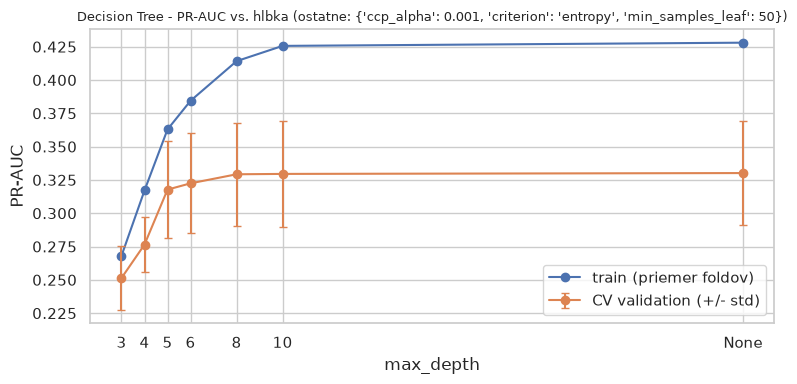

In [95]:
#3.3 A: train vs CV PR-AUC v zavislosti od max_depth (ostatne parametre = vybrane nastavenie)
dt_results = pd.DataFrame(dt_search.cv_results_)
best_dt_params = dt_search.best_params_
mask = np.ones(len(dt_results), dtype = bool)
for param in ["model__criterion", "model__min_samples_leaf", "model__ccp_alpha"]:
    mask &= dt_results[f"param_{param}"] == best_dt_params[param]
depth_curve = dt_results[mask].copy()
depth_curve["max_depth"] = depth_curve["param_model__max_depth"].apply(lambda d: 30 if d is None else d)
depth_curve = depth_curve.sort_values("max_depth")

fig, ax = plt.subplots(figsize = (8, 4))
ax.plot(depth_curve["max_depth"], depth_curve["mean_train_pr_auc"], marker = "o", label = "train (priemer foldov)")
ax.errorbar(depth_curve["max_depth"], depth_curve["mean_test_pr_auc"], yerr = depth_curve["std_test_pr_auc"],
            marker = "o", capsize = 3, label = "CV validation (+/- std)")
ax.set_xticks(depth_curve["max_depth"])
ax.set_xticklabels([("None" if d == 30 else str(d)) for d in depth_curve["max_depth"]])
ax.set_xlabel("max_depth")
ax.set_ylabel("PR-AUC")
ax.set_title(f"Decision Tree - PR-AUC vs. hlbka (ostatne: {({k.replace('model__', ''): v for k, v in best_dt_params.items() if k != 'model__max_depth'})})", fontsize = 9)
ax.legend()
plt.tight_layout()
plt.show()

Krivka potvrdzuje výber: CV PR-AUC rastie do hĺbky 5-6 (0.318 / 0.323) a potom sa zastaví na ~0.33, zatiaľ čo trénovacie skóre ďalej rastie až na 0.43 - od hĺbky 6 už pridané úrovne len memorujú trénovacie dáta. Hĺbky 3-4 sú v **underfite** (CV 0.25-0.28, nízke aj trénovacie skóre). Pri hĺbke 5 sú train a CV ešte blízko seba a chybové úsečky CV (± std) sa pri hĺbkach 5-None prekrývajú, takže hlbší strom nie je štatisticky lepší.

Porovnanie s pôvodným (neladeným) nastavením z 3.2 A - tá istá CV, aby bolo vidieť, koľko ladenie prinieslo.

In [96]:
#3.3 A: povodne nastavenie z 3.2 A vs. vyladene - rovnaka krizova validacia
dt_baseline_cv = cross_validate(
    make_pipeline_33(DecisionTreeClassifier(criterion = "entropy", max_depth = DT_MAX_DEPTH,
                                            min_samples_leaf = DT_MIN_SAMPLES_LEAF, class_weight = "balanced",
                                            random_state = 42)),
    X_train_raw, y_train_model, groups = groups_train, cv = cv_groups, scoring = scoring_33,
    return_train_score = True, n_jobs = -1,
)
display(pd.DataFrame([
    summary_row("Decision Tree - 3.2 A (neladeny)", cv_result = dt_baseline_cv),
    summary_row("Decision Tree - vyladeny (3.3 A)", search = dt_search),
]).set_index("model").round(3))

,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_roc_auc,cv_balanced_accuracy,cv_f1
model,,,,,,,
Decision Tree - 3.2 A (neladeny),0.321,0.281,0.023,0.040,0.715,0.659,0.340
Decision Tree - vyladeny (3.3 A),0.363,0.318,0.036,0.045,0.722,0.665,0.338


Ladenie zlepšilo strom z 3.2 A z CV PR-AUC 0.281 na **0.318** (+13 %) a ROC-AUC z 0.715 na 0.722, pri takmer rovnakej medzere train - CV (0.040 vs. 0.045). Pôvodný strom (efektívne 4 úrovne delení) bol mierne podtrénovaný. Balanced accuracy a F1 sa zmenili len minimálne (±0.006) - samotný strom je pre túto úlohu obmedzený, väčší posun čakáme od ensemble.

### 3.3 B - Kombinácie modelov (ensemble) pre zvolený algoritmus (1b)
Vyskúšajte kombinácie modelov (ensemble) pre zvolený algoritmus tak, aby ste optimalizovali výkonnosť (bez underfitingu).

Rozhodovací strom kombinujeme tromi ensemble prístupmi (cvičenie week-06 *Ensemble learning*):
- **Bagging** - 100 stromov s vyladenými parametrami z 3.3 A, každý na inom bootstrap výbere; predikcie sa priemerujú (znižuje varianciu).
- **Random Forest** - bagging + náhodný výber atribútov pri každom delení (stromy sú menej korelované). Ladíme `RandomizedSearchCV` (30 náhodných nastavení z mriežky).
- **Gradient Boosting** (`HistGradientBoostingClassifier`) - stromy sa stavajú postupne, každý opravuje chyby predchádzajúcich (znižuje bias). Tiež `RandomizedSearchCV` (30 nastavení).

Všetky s váhami tried a s rovnakou CV aj pravidlom výberu (gap ≤ 0.05). Ako nestromovú referenciu doladíme aj regularizáciu `C` logistickej regresie z 3.2 B.

In [97]:
#3.3 B: Bagging vyladenych stromov z 3.3 A
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, HistGradientBoostingClassifier

best_dt_model = dt_search.best_estimator_.named_steps["model"]
bagging_cv = cross_validate(
    make_pipeline_33(BaggingClassifier(estimator = clone(best_dt_model), n_estimators = 100, random_state = 42, n_jobs = 1)),
    X_train_raw, y_train_model, groups = groups_train, cv = cv_groups, scoring = scoring_33,
    return_train_score = True, n_jobs = -1,
)
display(pd.DataFrame([summary_row("Bagging (100 x vyladeny strom)", cv_result = bagging_cv)]).set_index("model").round(3))

,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_roc_auc,cv_balanced_accuracy,cv_f1
model,,,,,,,
Bagging (100 x vyladeny strom),0.437,0.372,0.036,0.065,0.754,0.687,0.377


In [98]:
#3.3 B: Random Forest - RandomizedSearchCV (30 nastaveni), vyber bez overfitu
rf_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [4, 6, 8, 10, None],
    "model__min_samples_leaf": [5, 20, 50, 100],
    "model__max_features": ["sqrt", 0.5, None],
}
rf_search = RandomizedSearchCV(
    make_pipeline_33(RandomForestClassifier(class_weight = "balanced", random_state = 42, n_jobs = 1)),
    rf_param_grid, n_iter = 30, random_state = 42, cv = cv_groups, scoring = scoring_33,
    refit = select_without_overfit, return_train_score = True, n_jobs = -1,
)
rf_search.fit(X_train_raw, y_train_model, groups = groups_train)
display(search_table(rf_search, top = 6).round(3))

,nastavenie,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_balanced_accuracy,cv_f1,cv_roc_auc,vybrane
29,"{'n_estimators': 400, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}",0.983,0.423,0.029,0.559,0.687,0.434,0.767,False
9,"{'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': None}",0.682,0.423,0.034,0.259,0.699,0.405,0.771,False
6,"{'n_estimators': 400, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10}",0.864,0.422,0.032,0.442,0.697,0.422,0.769,False
4,"{'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 6}",0.529,0.416,0.041,0.112,0.697,0.383,0.765,False
16,"{'n_estimators': 400, 'min_samples_leaf': 50, 'max_features': 0.5, 'max_depth': None}",0.531,0.412,0.037,0.119,0.698,0.386,0.768,False
19,"{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None}",0.979,0.412,0.030,0.566,0.687,0.432,0.763,False


In [99]:
#3.3 B: Gradient Boosting (HistGradientBoosting) - RandomizedSearchCV (30 nastaveni), vyber bez overfitu
hgb_param_grid = {
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 6],
    "model__max_iter": [100, 200, 400],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 1.0],
}
hgb_search = RandomizedSearchCV(
    make_pipeline_33(HistGradientBoostingClassifier(class_weight = "balanced", random_state = 42)),
    hgb_param_grid, n_iter = 30, random_state = 42, cv = cv_groups, scoring = scoring_33,
    refit = select_without_overfit, return_train_score = True, n_jobs = -1,
)
hgb_search.fit(X_train_raw, y_train_model, groups = groups_train)
display(search_table(hgb_search, top = 6).round(3))

,nastavenie,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_balanced_accuracy,cv_f1,cv_roc_auc,vybrane
20,"{'min_samples_leaf': 20, 'max_iter': 400, 'max_depth': 2, 'learning_rate': 0.1, 'l2_regularization': 1.0}",0.570,0.469,0.040,0.100,0.720,0.415,0.782,False
22,"{'min_samples_leaf': 50, 'max_iter': 400, 'max_depth': 2, 'learning_rate': 0.1, 'l2_regularization': 0.0}",0.567,0.467,0.040,0.100,0.721,0.415,0.781,False
10,"{'min_samples_leaf': 20, 'max_iter': 400, 'max_depth': 3, 'learning_rate': 0.05, 'l2_regularization': 1.0}",0.609,0.466,0.041,0.143,0.721,0.421,0.780,False
7,"{'min_samples_leaf': 50, 'max_iter': 100, 'max_depth': 2, 'learning_rate': 0.1, 'l2_regularization': 0.0}",0.516,0.465,0.044,0.051,0.715,0.400,0.784,False
6,"{'min_samples_leaf': 100, 'max_iter': 100, 'max_depth': 2, 'learning_rate': 0.1, 'l2_regularization': 1.0}",0.514,0.464,0.044,0.050,0.714,0.398,0.784,False
26,"{'min_samples_leaf': 100, 'max_iter': 400, 'max_depth': 3, 'learning_rate': 0.05, 'l2_regularization': 1.0}",0.585,0.464,0.045,0.121,0.719,0.417,0.782,False


In [100]:
#3.3 B: nestromova referencia - logisticka regresia s ladenim regularizacie C
lr_search = GridSearchCV(
    make_pipeline_33(LogisticRegression(class_weight = "balanced", max_iter = 3000)),
    {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv = cv_groups, scoring = scoring_33,
    refit = select_without_overfit, return_train_score = True, n_jobs = -1,
)
lr_search.fit(X_train_raw, y_train_model, groups = groups_train)
display(search_table(lr_search, top = 6).round(3))

,nastavenie,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_balanced_accuracy,cv_f1,cv_roc_auc,vybrane
2,{'C': 0.1},0.340,0.339,0.038,0.001,0.667,0.326,0.728,True
3,{'C': 1},0.340,0.339,0.038,0.001,0.668,0.328,0.728,False
5,{'C': 100},0.340,0.339,0.038,0.001,0.668,0.327,0.728,False
4,{'C': 10},0.340,0.339,0.038,0.001,0.668,0.327,0.728,False
1,{'C': 0.01},0.332,0.331,0.040,0.002,0.665,0.324,0.724,False
0,{'C': 0.001},0.285,0.284,0.031,0.001,0.649,0.308,0.701,False


Súhrnné porovnanie všetkých kandidátov (vybrané nastavenie každého z nich) na rovnakej krížovej validácii.

,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_roc_auc,cv_balanced_accuracy,cv_f1
model,,,,,,,
Gradient Boosting (HGB),0.487,0.446,0.048,0.040,0.776,0.710,0.389
Random Forest,0.436,0.392,0.042,0.045,0.750,0.686,0.357
Bagging stromov,0.437,0.372,0.036,0.065,0.754,0.687,0.377
Logistic Regression - vyladena,0.340,0.339,0.038,0.001,0.728,0.667,0.326
Decision Tree - vyladeny,0.363,0.318,0.036,0.045,0.722,0.665,0.338
Decision Tree - 3.2 A (neladeny),0.321,0.281,0.023,0.040,0.715,0.659,0.340


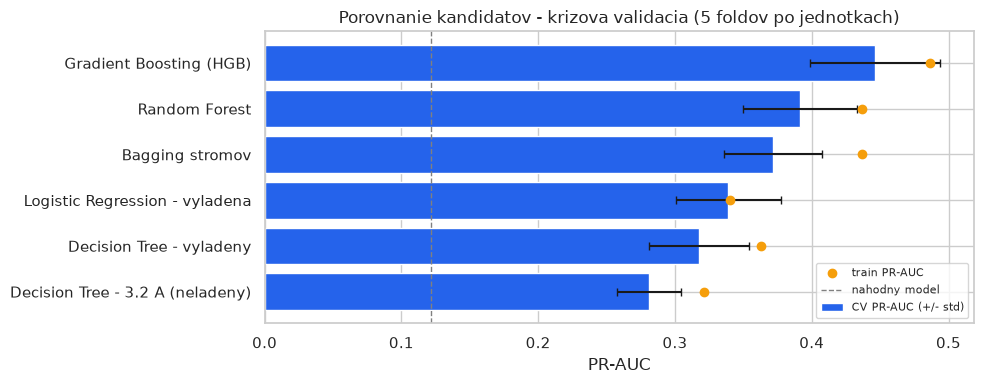

vybrane nastavenia:
  Decision Tree: {'ccp_alpha': 0.001, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 50}
  Random Forest: {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 4}
  Gradient Boosting: {'min_samples_leaf': 100, 'max_iter': 100, 'max_depth': 2, 'learning_rate': 0.05, 'l2_regularization': 1.0}
  Logistic Regression: {'C': 0.1}


In [101]:
#3.3 B: porovnanie vsetkych kandidatov na rovnakej CV
comparison_33 = pd.DataFrame([
    summary_row("Decision Tree - 3.2 A (neladeny)", cv_result = dt_baseline_cv),
    summary_row("Decision Tree - vyladeny", search = dt_search),
    summary_row("Bagging stromov", cv_result = bagging_cv),
    summary_row("Random Forest", search = rf_search),
    summary_row("Gradient Boosting (HGB)", search = hgb_search),
    summary_row("Logistic Regression - vyladena", search = lr_search),
]).set_index("model").sort_values("cv_pr_auc", ascending = False)
display(comparison_33.round(3))

fig, ax = plt.subplots(figsize = (10, 4))
plot_df = comparison_33.sort_values("cv_pr_auc")
ax.barh(plot_df.index, plot_df["cv_pr_auc"], xerr = plot_df["cv_pr_auc_std"], color = "#2563eb", capsize = 3, label = "CV PR-AUC (+/- std)")
ax.scatter(plot_df["train_pr_auc"], plot_df.index, color = "#f59e0b", zorder = 3, label = "train PR-AUC")
ax.axvline(y_train_model.mean(), color = "grey", linestyle = "--", linewidth = 1, label = "nahodny model")
ax.set_xlabel("PR-AUC")
ax.set_title("Porovnanie kandidatov - krizova validacia (5 foldov po jednotkach)")
ax.legend(loc = "lower right", fontsize = 8)
plt.tight_layout()
plt.show()

print("vybrane nastavenia:")
for name, search in [("Decision Tree", dt_search), ("Random Forest", rf_search), ("Gradient Boosting", hgb_search), ("Logistic Regression", lr_search)]:
    print(f"  {name}: { {k.replace('model__', ''): v for k, v in search.best_params_.items()} }")

**Ensemble metódy výrazne prekonali samotný strom:**
- **Gradient Boosting (HGB)** - CV PR-AUC **0.446** (+40 % oproti vyladenému stromu 0.318), ROC-AUC 0.776, balanced accuracy 0.710, F1 0.389, medzera train - CV len 0.040. Vybrané nastavenie je veľmi „plytké“: 100 stromov hĺbky 2, `learning_rate=0.05`, `min_samples_leaf=100`, L2 regularizácia 1.0. Najvyššie CV skóre v hľadaní (0.469) mali dlhšie trénované modely (400 iterácií), ale s medzerou 0.10.
- **Random Forest** - CV PR-AUC 0.392 pri `max_depth=4`, `min_samples_leaf=20`, 400 stromov. Neobmedzené lesy dosiahli CV 0.423, ale s trénovacím PR-AUC až 0.98 (gap 0.56 - typické memorovanie hlbokých stromov v lese), preto ich pravidlo vyradilo.
- **Bagging** 100 vyladených stromov - CV 0.372, ale medzera 0.065 mierne prekračuje náš limit (bagging sme neladili, len použili parametre z 3.3 A).
- **Logistic Regression** - regularizácia takmer nemá vplyv (C 0.1-100 dáva rovnaké CV 0.339); model je tak jednoduchý, že overfit nehrozí (gap 0.001), ale nevie zachytiť nelineárne vzťahy a interakcie, ktoré boosting využíva.

Boosting vyhral, lebo každý ďalší plytký strom opravuje chyby predchádzajúcich (znižuje bias), čím zachytí interakcie atribútov (napr. `class_duty` × `currentMotor` × `filterDp` z pravidiel v 3.2 D), a zároveň malá rýchlosť učenia s L2 regularizáciou drží varianciu nízko.

### 3.3 C - Krížová validácia na trénovacej množine (1b)
Využite krížovú validáciu (cross validation) na trénovacej množine.

Krížovú validáciu (`StratifiedGroupKFold`, 5 foldov po `id_unit`) sme použili pri každom ladení v 3.3 A/B - spolu ~1 400 trénovaní modelov, bez jediného pohľadu na test. Tu sa pozrieme na skóre najlepšieho kandidáta **po jednotlivých foldoch** - stabilita medzi foldami ukazuje, či výsledok nezávisí od náhodného rozdelenia jednotiek.

In [102]:
#3.3 C: vyber najlepsieho kandidata podla CV PR-AUC a jeho skore po jednotlivych foldoch
candidate_searches = {
    "Decision Tree - vyladeny": dt_search,
    "Random Forest": rf_search,
    "Gradient Boosting (HGB)": hgb_search,
    "Logistic Regression - vyladena": lr_search,
}
best_name_33 = comparison_33.drop(index = ["Decision Tree - 3.2 A (neladeny)", "Bagging stromov"]).index[0]
best_search_33 = candidate_searches[best_name_33]
print(f"najlepsi kandidat podla CV PR-AUC: {best_name_33}")
print(f"nastavenie: { {k.replace('model__', ''): v for k, v in best_search_33.best_params_.items()} }")

best_cv_33 = cross_validate(
    clone(best_search_33.best_estimator_), X_train_raw, y_train_model, groups = groups_train,
    cv = cv_groups, scoring = scoring_33, return_train_score = True, n_jobs = -1,
)
folds_33 = pd.DataFrame({
    f"{part}_{metric}": best_cv_33[f"{part}_{metric}"]
    for metric in ["pr_auc", "roc_auc", "balanced_accuracy", "f1"] for part in ["train", "test"]
}, index = pd.Index(range(1, 6), name = "fold")).rename(columns = lambda c: c.replace("test_", "cv_"))
folds_33.loc["priemer"] = folds_33.mean()
folds_33.loc["std"] = folds_33.iloc[:5].std()
display(folds_33.round(3))

najlepsi kandidat podla CV PR-AUC: Gradient Boosting (HGB)
nastavenie: {'min_samples_leaf': 100, 'max_iter': 100, 'max_depth': 2, 'learning_rate': 0.05, 'l2_regularization': 1.0}


,train_pr_auc,cv_pr_auc,train_roc_auc,cv_roc_auc,train_balanced_accuracy,cv_balanced_accuracy,train_f1,cv_f1
fold,,,,,,,,
1,0.483,0.499,0.803,0.800,0.730,0.726,0.410,0.402
2,0.479,0.497,0.800,0.805,0.727,0.728,0.406,0.397
3,0.504,0.372,0.811,0.744,0.732,0.687,0.413,0.373
4,0.472,0.425,0.801,0.757,0.731,0.700,0.407,0.382
5,0.496,0.438,0.808,0.774,0.733,0.710,0.416,0.393
priemer,0.487,0.446,0.804,0.776,0.731,0.710,0.410,0.389
std,0.013,0.053,0.005,0.027,0.002,0.017,0.004,0.012


Najlepším kandidátom je **Gradient Boosting (HGB)**. Trénovacie skóre je medzi foldami veľmi stabilné (PR-AUC 0.472-0.504, std 0.013; balanced accuracy std 0.002). Validačné skóre kolíše viac (PR-AUC 0.372-0.499, std 0.053), hlavne kvôli foldu 3 (0.372) - validačné jednotky sú v každom folde iné a pri ~320 jednotkách s ~280 poruchami je PR-AUC citlivá na to, ktoré jednotky padnú do validácie. ROC-AUC (std 0.027), balanced accuracy (std 0.017) a F1 (std 0.012) sú stabilné. V 3 z 5 foldov je rozdiel train - CV v balanced accuracy pod 0.03 a vo foldoch 1 a 2 je CV PR-AUC dokonca vyššie ako trénovacie - model nie je naučený na konkrétne jednotky.

### 3.3 D - Dôkaz, že najlepší model je bez overfitingu (2b)
Dokážte, že Váš nastavený najlepší model je bez overfitingu.

Overfitting (a zároveň underfitting) posudzujeme štyrmi nezávislými dôkazmi:
1. **train vs. CV vs. test** - finálny model natrénujeme na celej trénovacej množine a raz vyhodnotíme na odloženom teste,
2. **learning curve** - ako sa vyvíja train a CV skóre s rastúcim počtom trénovacích dát,
3. **validation curve** - train a CV skóre v závislosti od hlavného parametra komplexity (počet boosting iterácií / stromov),
4. **stabilita** - smerodajná odchýlka medzi foldami (3.3 C).

In [103]:
#3.3 D (1): finalny model - fit na celom train, train vs CV vs test
best_model_33 = clone(best_search_33.best_estimator_).fit(X_train_raw, y_train_model)

final_train = evaluate_classifier(best_model_33, X_train_raw, y_train_model)
final_test = evaluate_classifier(best_model_33, X_test_raw, y_test_model)
final_cv = {m: best_cv_33[f"test_{m}"].mean() for m in ["pr_auc", "roc_auc", "balanced_accuracy", "f1"]}
final_table = pd.DataFrame({
    "train": final_train,
    "CV (priemer 5 foldov)": {"pr_auc": final_cv["pr_auc"], "roc_auc": final_cv["roc_auc"],
                              "balanced_accuracy": final_cv["balanced_accuracy"], "f1": final_cv["f1"]},
    "test": final_test,
}).loc[["pr_auc", "roc_auc", "balanced_accuracy", "f1", "recall", "precision", "accuracy"]]
final_table["gap train - test"] = final_table["train"] - final_table["test"]
display(final_table.round(3))

,train,CV (priemer 5 foldov),test,gap train - test
pr_auc,0.483,0.446,0.414,0.069
roc_auc,0.798,0.776,0.773,0.025
balanced_accuracy,0.725,0.710,0.702,0.023
f1,0.403,0.389,0.376,0.028
recall,0.689,NaN,0.655,0.033
precision,0.285,NaN,0.263,0.022
accuracy,0.752,NaN,0.738,0.014


Finálny HGB (fit na celých 11 514 trénovacích meraniach) má na odloženom teste **PR-AUC 0.414, ROC-AUC 0.773, balanced accuracy 0.702, F1 0.376, recall 0.655**. Rozdiely train - test sú malé: 0.025 v ROC-AUC, 0.023 v balanced accuracy, 0.028 v F1. Najväčší je pri PR-AUC (0.069), ale testové PR-AUC (0.414) leží v rozsahu CV foldov (0.372-0.499) a je len ~0.6 std pod priemerom CV (0.446) - rozdiel zodpovedá variabilite medzi skupinami jednotiek, nie memorovaniu (pri overfite by train bol blízko 1.0 ako pri neobmedzenom ID3 alebo lese). Poradie train > CV > test je konzistentné a skoky sú malé - **bez overfitu**. Model zároveň **nie je v underfite**: trénovacie skóre (0.483) je 4× nad náhodným modelom (0.12) a všetky metriky sú lepšie ako pri jednoduchších modeloch z 3.2.

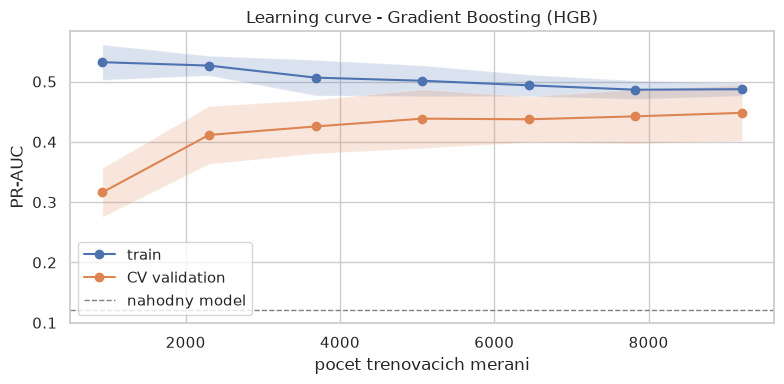

,train,cv,gap
921,0.532,0.316,0.216
2302,0.526,0.411,0.115
3684,0.507,0.426,0.081
5066,0.501,0.438,0.063
6447,0.494,0.437,0.056
7829,0.486,0.442,0.044
9211,0.487,0.448,0.039


In [104]:
#3.3 D (2): learning curve - train vs CV PR-AUC pri raste poctu trenovacich dat
lc_sizes, lc_train, lc_cv = learning_curve(
    clone(best_search_33.best_estimator_), X_train_raw, y_train_model, groups = groups_train, cv = cv_groups,
    scoring = "average_precision", train_sizes = np.linspace(0.1, 1.0, 7), n_jobs = -1, shuffle = True, random_state = 42,
)
fig, ax = plt.subplots(figsize = (8, 4))
for scores, label in [(lc_train, "train"), (lc_cv, "CV validation")]:
    ax.plot(lc_sizes, scores.mean(axis = 1), marker = "o", label = label)
    ax.fill_between(lc_sizes, scores.mean(axis = 1) - scores.std(axis = 1), scores.mean(axis = 1) + scores.std(axis = 1), alpha = 0.2)
ax.axhline(y_train_model.mean(), color = "grey", linestyle = "--", linewidth = 1, label = "nahodny model")
ax.set_xlabel("pocet trenovacich merani")
ax.set_ylabel("PR-AUC")
ax.set_title(f"Learning curve - {best_name_33}")
ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({"train": lc_train.mean(axis = 1), "cv": lc_cv.mean(axis = 1),
                      "gap": lc_train.mean(axis = 1) - lc_cv.mean(axis = 1)}, index = lc_sizes).round(3))

Learning curve má tvar „zdravého“ modelu: trénovacie PR-AUC s pribúdajúcimi dátami mierne klesá (0.532 -> 0.487), CV stúpa (0.316 -> 0.448) a medzera sa zmenšuje z 0.216 pri 921 meraniach na **0.039** pri plnej trénovacej množine. Pri malých dátach model overfituje, s celou množinou sa krivky takmer zbiehajú. CV krivka od ~5 000 meraní už rastie len pozvoľna (0.438 -> 0.448) - viac dát by pomohlo len mierne, ďalšie zlepšenie skôr prinesú lepšie atribúty (indikátory chýbajúcich hodnôt z 3.2 D, 3.4).

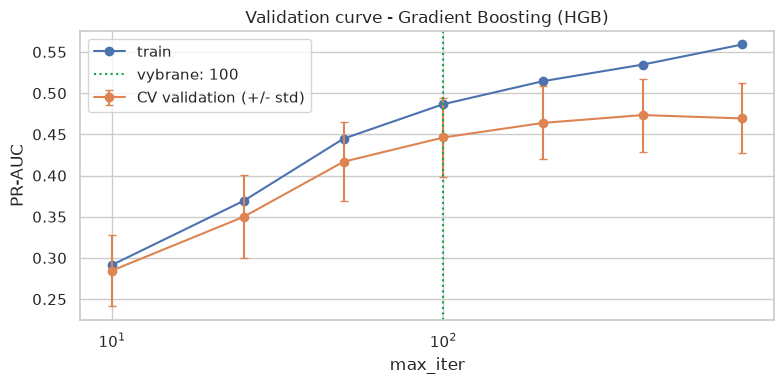

,train,cv,gap
max_iter,,,
10,0.291,0.285,0.007
25,0.369,0.350,0.019
50,0.445,0.417,0.028
100,0.487,0.446,0.040
200,0.515,0.464,0.051
400,0.535,0.473,0.061
800,0.559,0.469,0.090


In [105]:
#3.3 D (3): validation curve - hlavny parameter komplexity vybraneho modelu
complexity_param = {
    "Gradient Boosting (HGB)": ("model__max_iter", [10, 25, 50, 100, 200, 400, 800]),
    "Random Forest": ("model__max_depth", [2, 3, 4, 6, 8, 10, 15]),
    "Decision Tree - vyladeny": ("model__max_depth", [2, 3, 4, 5, 6, 8, 10, 15]),
    "Logistic Regression - vyladena": ("model__C", [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]),
}[best_name_33]
vc_train, vc_cv = validation_curve(
    clone(best_search_33.best_estimator_), X_train_raw, y_train_model, groups = groups_train, cv = cv_groups,
    param_name = complexity_param[0], param_range = complexity_param[1], scoring = "average_precision", n_jobs = -1,
)
chosen_value = best_search_33.best_params_.get(complexity_param[0])

fig, ax = plt.subplots(figsize = (8, 4))
ax.plot(complexity_param[1], vc_train.mean(axis = 1), marker = "o", label = "train")
ax.errorbar(complexity_param[1], vc_cv.mean(axis = 1), yerr = vc_cv.std(axis = 1), marker = "o", capsize = 3, label = "CV validation (+/- std)")
if chosen_value is not None:
    ax.axvline(chosen_value, color = "#16a34a", linestyle = ":", label = f"vybrane: {chosen_value}")
ax.set_xscale("log")
ax.set_xlabel(complexity_param[0].replace("model__", ""))
ax.set_ylabel("PR-AUC")
ax.set_title(f"Validation curve - {best_name_33}")
ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({"train": vc_train.mean(axis = 1), "cv": vc_cv.mean(axis = 1),
                      "gap": vc_train.mean(axis = 1) - vc_cv.mean(axis = 1)},
                     index = pd.Index(complexity_param[1], name = complexity_param[0].replace("model__", ""))).round(3))

Validation curve pre počet boosting iterácií (`max_iter`) ukazuje obe hranice: pri 10-25 iteráciách sú train aj CV nízke a takmer rovnaké (0.29 / 0.29, 0.37 / 0.35) - **underfit**. CV rastie do ~400 iterácií (0.473) a pri 800 už klesá (0.469), kým train ďalej stúpa (0.559) a medzera rastie na 0.090 - **začiatok overfitu**. Vybraných **100 iterácií** leží v oblasti, kde je CV už vysoké (0.446) a medzera malá (0.040); 200-400 iterácií by pridalo +0.02-0.03 CV PR-AUC, ale za cenu medzery 0.05-0.06. Uprednostnili sme stabilitu - je to aj zámerná rezerva pre nasadenie, kde sa dáta môžu od trénovacích mierne líšiť.

Nakoniec porovnáme finálny model so všetkými modelmi z 3.2 na testovacej množine (rovnaké metriky aj krivky).

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Gradient Boosting (HGB) (3.3),0.738,0.702,0.263,0.655,0.376,0.773,0.414
Logistic Regression,0.678,0.683,0.226,0.689,0.340,0.729,0.320
Decision Tree,0.719,0.656,0.231,0.573,0.330,0.710,0.267
ID3,0.649,0.630,0.193,0.605,0.293,0.683,0.227


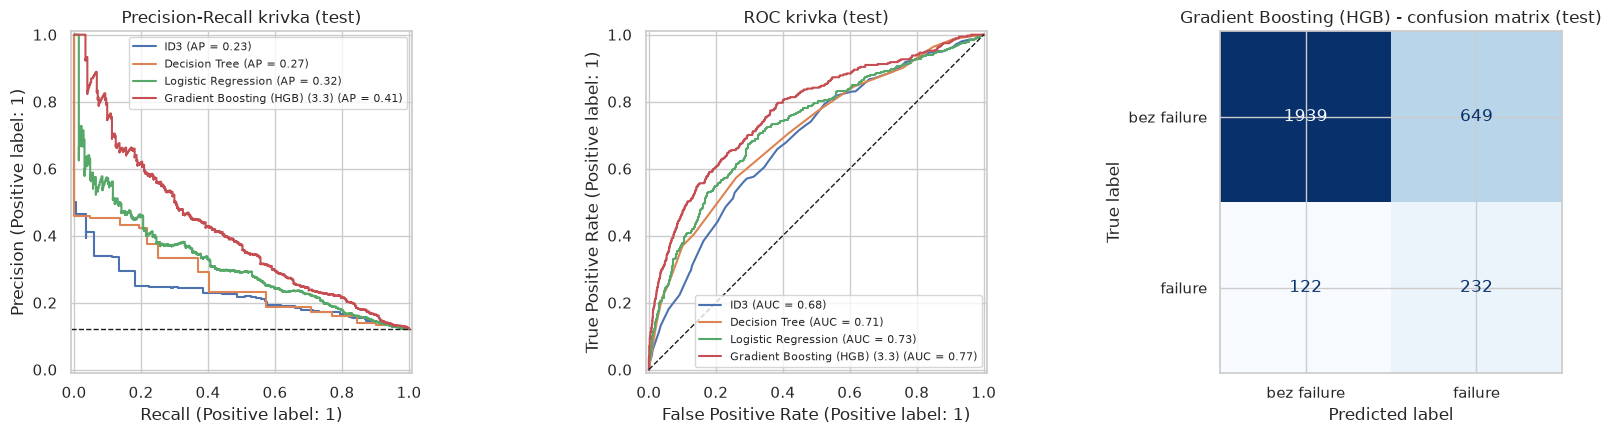

In [106]:
#3.3 D: porovnanie finalneho modelu s modelmi z 3.2 na teste
test_33 = metrics_32_test.copy()
test_33.loc[f"{best_name_33} (3.3)"] = pd.Series(final_test)
display(test_33.sort_values("pr_auc", ascending = False).round(3))

fig, axes = plt.subplots(1, 3, figsize = (17, 4.5))
for model_name, model in models_32.items():
    PrecisionRecallDisplay.from_estimator(model, test_transformed, y_test_model, name = model_name, ax = axes[0])
PrecisionRecallDisplay.from_estimator(best_model_33, X_test_raw, y_test_model, name = f"{best_name_33} (3.3)", ax = axes[0])
axes[0].axhline(y_test_model.mean(), color = "k", linestyle = "--", linewidth = 1)
axes[0].set_title("Precision-Recall krivka (test)")
for model_name, model in models_32.items():
    RocCurveDisplay.from_estimator(model, test_transformed, y_test_model, name = model_name, ax = axes[1])
RocCurveDisplay.from_estimator(best_model_33, X_test_raw, y_test_model, name = f"{best_name_33} (3.3)", ax = axes[1])
axes[1].plot([0, 1], [0, 1], "k--", linewidth = 1)
axes[1].set_title("ROC krivka (test)")
for ax in axes[:2]:
    ax.legend(loc = "lower right" if ax is axes[1] else "upper right", fontsize = 8)
ConfusionMatrixDisplay.from_estimator(best_model_33, X_test_raw, y_test_model, display_labels = ["bez failure", "failure"],
                                      cmap = "Blues", colorbar = False, ax = axes[2])
axes[2].set_title(f"{best_name_33} - confusion matrix (test)")
plt.tight_layout()
plt.show()

Na testovacej množine je HGB **najlepší vo všetkých metrikách okrem recallu**: PR-AUC 0.414 (oproti 0.320 pri LR z 3.2, +29 %), ROC-AUC 0.773, balanced accuracy 0.702, F1 0.376 a precision 0.263. PR krivka HGB leží nad ostatnými takmer v celom rozsahu - pri recalle ~0.1-0.2 dosahuje precision 0.6-0.8, t. j. najrizikovejšie jednotky identifikuje oveľa spoľahlivejšie. Z confusion matrix: zachytí 232 z 354 porúch (65.5 %, LR 244) pri 649 falošných alarmoch (LR 837) - na jednu skutočnú poruchu pripadá **3.8 alarmu** namiesto 4.4 pri LR. Za cenu 12 prehliadnutých porúch navyše teda ušetrí 188 zbytočných zásahov.

**Zhrnutie 3.3:**
- **3.3 A:** `GridSearchCV` (210 nastavení) vyladil `DecisionTreeClassifier` na `entropy`, `max_depth=5`, `min_samples_leaf=50`, `ccp_alpha=0.001` - CV PR-AUC 0.281 -> 0.318. Hlbšie stromy mali o ~0.01 vyššie CV, ale s viac než dvojnásobnou medzerou train - CV.
- **3.3 B:** ensemble stromov priniesli najväčšie zlepšenie - Bagging 0.372, Random Forest 0.392, **Gradient Boosting 0.446** CV PR-AUC. Logistická regresia (0.339) je stabilná, ale nevie zachytiť interakcie atribútov.
- **3.3 C:** všetko ladenie prebehlo 5-násobnou `StratifiedGroupKFold` CV po jednotkách len na trénovacej množine, s celým pipeline (predspracovanie sa fituje v každom folde zvlášť). Najlepší model je medzi foldami stabilný (ROC-AUC 0.776 ± 0.027, balanced accuracy 0.710 ± 0.017).
- **3.3 D:** najlepší model **`HistGradientBoostingClassifier`** (100 iterácií, hĺbka 2, `learning_rate=0.05`, `min_samples_leaf=100`, L2 = 1.0, `class_weight="balanced"`) je **bez overfitu** - rozdiel train - test ≤ 0.03 v ROC-AUC/balanced accuracy/F1, test PR-AUC v rozsahu CV foldov, learning curve sa zbieha (gap 0.039), validation curve ukazuje, že sme pred začiatkom overfitu. Zároveň **bez underfitu** - je výrazne lepší ako všetky jednoduchšie modely a validation curve ukazuje underfit až pri ≤ 25 iteráciách.

Na teste: PR-AUC 0.414, ROC-AUC 0.773, balanced accuracy 0.702, recall 0.655 - oproti najlepšiemu modelu z 3.2 (LR) o 29 % lepšia PR-AUC a o 22 % menej falošných alarmov. Model je uložený v premennej `best_model_33` (celý pipeline vrátane predspracovania) a slúži ako východisko pre vyhodnotenie stratégií v 3.4.

## 3.4 Vyhodnotenie vplyvu zvolenej stratégie riešenia na klasifikáciu (5b)
Vyhodnoťte Vami zvolené stratégie riešenia projektu z hľadiska classification quality, či sú účinné pre Váš dataset. Všetky hodnotenia podložte dôkazmi. Najlepší model má byť stabilný, bez overfitu a bez underfitu. Jeho data pipeline má byť dodaný s metadátami, ak sú tie metadáta potrebné a vyrobené v developmente.

**Metodika.** Každú stratégiu z fáz 1-3 vyhodnocujeme **ablačne** - meníme vždy jednu vec a ostatné necháme ako v referenčnom riešení. Referenčné riešenie = predspracovanie z 2.3 B (medián -> `PowerTransformer` pri zošikmených -> `StandardScaler`, 9 atribútov z 2.2 B) a dva modely z 3.3:
- **Gradient Boosting (HGB)** s vyladenými parametrami - najlepší model,
- **Logistic Regression** (`C=0.1`) - lineárny model citlivý na mierku a tvar rozdelenia, na ktorom sa efekt predspracovania prejaví výraznejšie.

Všetko meriame **rovnakou krížovou validáciou** ako v 3.3 (`StratifiedGroupKFold`, 5 foldov po `id_unit`, celý pipeline sa fituje v každom folde zvlášť) - len na trénovacej množine. Hlavná metrika je CV PR-AUC, sledujeme aj ROC-AUC, balanced accuracy, F1 a medzeru train - CV.

In [107]:
#3.4: konfigurovatelne predspracovanie - jedna funkcia pre vsetky ablacne varianty
from sklearn.base import TransformerMixin
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer, QuantileTransformer, OrdinalEncoder, OneHotEncoder,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

class QuantileClipper(BaseEstimator, TransformerMixin):
    #winsorizacia z 1.2 C ako krok pipeline: hranice (5. a 95. percentil) sa ucia len na train casti
    def __init__(self, lower = 0.05, upper = 0.95):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y = None):
        X = np.asarray(X, dtype = float)
        self.low_ = np.nanquantile(X, self.lower, axis = 0)
        self.high_ = np.nanquantile(X, self.upper, axis = 0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype = float), self.low_, self.high_) #NaN ostava NaN

    def get_feature_names_out(self, input_features = None):
        return np.asarray(input_features, dtype = object)

SKEWED_COLS = ["filterDp", "rms_vibration", "serviceHours"]
SELECTED_FEATURES = list(raw_input_cols) #9 atributov z 2.2 B (vratane class_duty)
SCALERS = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler, "none": None}
TRANSFORMERS = {
    "power": lambda: PowerTransformer(method = "yeo-johnson", standardize = False),
    "quantile": lambda: QuantileTransformer(output_distribution = "normal", random_state = 42),
    "none": None,
}

def make_preprocess(features = SELECTED_FEATURES, scaler = "standard", transformer = "power", impute = "median",
                    indicators = (), winsorize = False, onehot = (), passthrough = ()):
    def numeric_steps(skewed):
        steps = [("range", PhysicalRangeToNaN(ranges = expected_ranges, lower_bound_only = ("filterDp",)))]
        if winsorize:
            steps.append(("winsorize", QuantileClipper()))
        if impute is not None:
            steps.append(("imputer", SimpleImputer(strategy = impute)))
        if skewed and TRANSFORMERS[transformer] is not None:
            steps.append(("transform", TRANSFORMERS[transformer]()))
        if SCALERS[scaler] is not None:
            steps.append(("scaler", SCALERS[scaler]()))
        return Pipeline(steps)

    skewed = [c for c in features if c in SKEWED_COLS]
    other = [c for c in features if c not in SKEWED_COLS and c != "class_duty"]
    branches = []
    if "class_duty" in features:
        branches.append(("categorical", clone(categorical_pipeline), ["class_duty"])) #rovnaka vetva ako v 2.3 B
    if skewed:
        branches.append(("skewed", numeric_steps(True), skewed))
    if other:
        branches.append(("other", numeric_steps(False), other))
    if indicators:
        branches.append(("missing", MissingIndicator(features = "all"), list(indicators)))
    if onehot:
        branches.append(("onehot", OneHotEncoder(handle_unknown = "ignore"), list(onehot)))
    if passthrough:
        branches.append(("passthrough", "passthrough", list(passthrough)))
    return ColumnTransformer(branches)

#referencne modely z 3.3
hgb_reference = clone(hgb_search.best_estimator_.named_steps["model"])
lr_reference = clone(lr_search.best_estimator_.named_steps["model"])
ALL_RAW_COLS = SELECTED_FEATURES + ["mean_signal_dbm", "median_signal_dbm", "filterDp_suspicious", "codeModel", "fleetCode"]
X_train_all = df_train[ALL_RAW_COLS]
X_test_all = df_test[ALL_RAW_COLS]

def cv_variant(name, preprocess, model, cv = cv_groups, groups = groups_train):
    #CV celeho pipeline (predspracovanie + model) - rovnake foldy a metriky ako v 3.3
    result = cross_validate(Pipeline([("preprocess", preprocess), ("model", clone(model))]), X_train_all, y_train_model,
                            groups = groups, cv = cv, scoring = scoring_33, return_train_score = True, n_jobs = -1)
    return summary_row(name, cv_result = result)

def ablation_table(variants, models = (("HGB", hgb_reference), ("LR", lr_reference))):
    rows = []
    for name, kwargs, allowed_models in variants:
        for model_name, model in models:
            if allowed_models is None or model_name in allowed_models:
                row = cv_variant(name, make_preprocess(**kwargs), model)
                row["algoritmus"] = model_name
                rows.append(row)
    return pd.DataFrame(rows).set_index(["algoritmus", "model"]).rename_axis(["algoritmus", "variant"])

#kontrola: referencny variant musi dat rovnake CV ako HGB v 3.3
check = cv_variant("referencia", make_preprocess(), hgb_reference)
print(f"referencne predspracovanie + HGB: CV PR-AUC = {check['cv_pr_auc']:.3f} (3.3: {comparison_33.loc['Gradient Boosting (HGB)', 'cv_pr_auc']:.3f})")

referencne predspracovanie + HGB: CV PR-AUC = 0.446 (3.3: 0.446)


### 3.4 A - Stratégie riešenia v data preprocessingu (1b)
Vyhodnoťte stratégie riešenia v data preprocessingu s daným datasetom.

Vyhodnotíme rozhodnutia, ktoré sme urobili pri čistení a príprave dát:
1. **Chýbajúce hodnoty** (2.1 B - imputácia mediánom): + binárne indikátory chýbania pre `filterDp` a `rms_vibration` (zistenie z 3.2 D), imputácia priemerom, a pri HGB aj **bez imputácie** (HGB vie s `NaN` pracovať natívne - pri každom delení sa naučí, kam poslať chýbajúce hodnoty).
2. **Vychýlené hodnoty** (1.2 C): referencia ich ponecháva (`filterDp` mimo rozsahu môže byť signál poruchy), alternatíva je **winsorizácia na 5./95. percentil** - jedna z dvoch techník z 1.2 C, tu ako krok pipeline fitovaný len na train časti foldu.
3. **Nevyváženosť tried:** `class_weight="balanced"` (referencia) vs. bez vyváženia vs. random undersampling z 3.1.

In [108]:
#3.4 A (1, 2): chybajuce hodnoty a outliery - ablacia oproti referencii
preprocessing_variants = [
    ("referencia (median, 2.3 B)", {}, None),
    ("median + indikatory chybania", {"indicators": ("filterDp", "rms_vibration")}, None),
    ("imputacia priemerom", {"impute": "mean"}, None),
    ("bez imputacie (nativne NaN)", {"impute": None}, ("HGB",)),
    ("bez imputacie + indikatory", {"impute": None, "indicators": ("filterDp", "rms_vibration")}, ("HGB",)),
    ("winsorizacia 5/95 %", {"winsorize": True}, None),
]
ablation_a = ablation_table(preprocessing_variants)
display(ablation_a.round(3))

train_pr_auc  cv_pr_auc  \
algoritmus variant                                                 
HGB        referencia (median, 2.3 B)           0.487      0.446   
LR         referencia (median, 2.3 B)           0.340      0.339   
HGB        median + indikatory chybania         0.486      0.456   
LR         median + indikatory chybania         0.486      0.483   
HGB        imputacia priemerom                  0.489      0.456   
LR         imputacia priemerom                  0.346      0.345   
HGB        bez imputacie (nativne NaN)          0.492      0.457   
           bez imputacie + indikatory           0.492      0.457   
           winsorizacia 5/95 %                  0.486      0.448   
LR         winsorizacia 5/95 %                  0.334      0.333   

                                         cv_pr_auc_std  gap_pr_auc  \
algoritmus variant                                                   
HGB        referencia (median, 2.3 B)            0.048       0.040   
LR         referencia (median, 2.3 B)            0.038       0.001   
HGB        median + indikatory chybania          0.046       0.030   
LR         median + indikatory chybania          0.050       0.003   
HGB        imputacia priemerom                   0.047       0.033   
LR         imputacia priemerom                   0.040       0.001   
HGB        bez imputacie (nativne NaN)           0.048       0.035   
           bez imputacie + indikatory            0.048       0.035   
           winsorizacia 5/95 %                   0.047       0.039   
LR         winsorizacia 5/95 %                   0.037       0.001   

                                         cv_roc_auc  cv_balanced_accuracy  \
algoritmus variant                                                          
HGB        referencia (median, 2.3 B)         0.776                 0.710   
LR         referencia (median, 2.3 B)         0.728                 0.667   
HGB        median + indikatory chybania       0.783                 0.717   
LR         median + indikatory chybania       0.795                 0.726   
HGB        imputacia priemerom                0.779                 0.707   
LR         imputacia priemerom                0.733                 0.673   
HGB        bez imputacie (nativne NaN)        0.784                 0.714   
           bez imputacie + indikatory         0.784                 0.714   
           winsorizacia 5/95 %                0.776                 0.707   
LR         winsorizacia 5/95 %                0.726                 0.666   

                                         cv_f1  
algoritmus variant                              
HGB        referencia (median, 2.3 B)    0.389  
LR         referencia (median, 2.3 B)    0.326  
HGB        median + indikatory chybania  0.422  
LR         median + indikatory chybania  0.409  
HGB        imputacia priemerom           0.388  
LR         imputacia priemerom           0.332  
HGB        bez imputacie (nativne NaN)   0.412  
           bez imputacie + indikatory    0.412  
           winsorizacia 5/95 %           0.386  
LR         winsorizacia 5/95 %           0.326

In [109]:
#3.4 A (3): strategia pre nevyvazene triedy (pri HGB s referencnym predspracovanim)
imbalance_rows = []
for name, model in [
    ("class_weight='balanced' (referencia)", hgb_reference),
    ("bez vyvazenia", clone(hgb_reference).set_params(class_weight = None)),
    ("random undersampling (3.1)", RandomUnderSampledClassifier(clone(hgb_reference).set_params(class_weight = None))),
]:
    imbalance_rows.append(cv_variant(name, make_preprocess(), model))
imbalance_table = pd.DataFrame(imbalance_rows).set_index("model")
display(imbalance_table.round(3))

,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_roc_auc,cv_balanced_accuracy,cv_f1
model,,,,,,,
class_weight='balanced' (referencia),0.487,0.446,0.048,0.040,0.776,0.710,0.389
bez vyvazenia,0.499,0.462,0.045,0.037,0.782,0.540,0.150
random undersampling (3.1),0.461,0.433,0.059,0.028,0.768,0.697,0.367


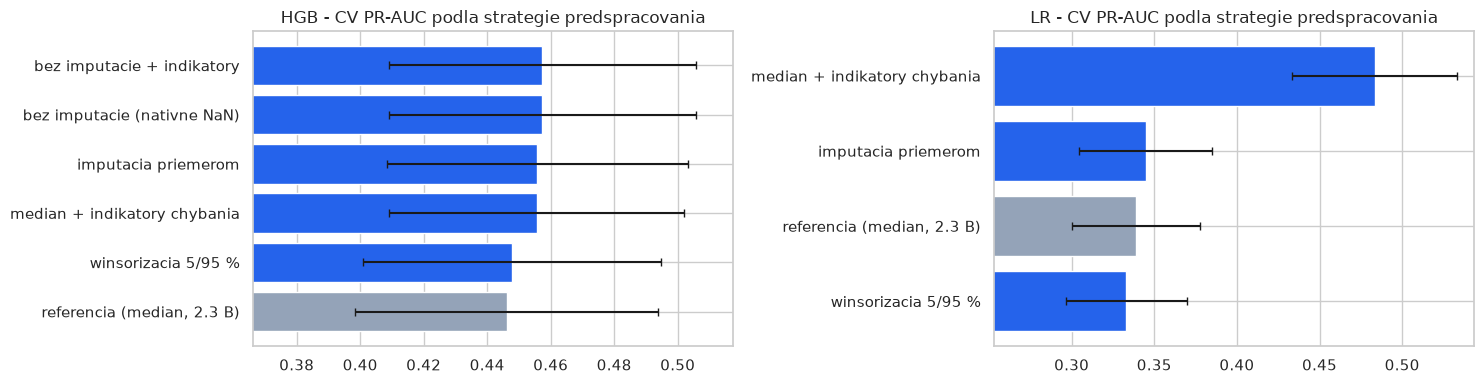

In [110]:
#3.4 A: graf - CV PR-AUC variantov predspracovania (HGB aj LR)
fig, axes = plt.subplots(1, 2, figsize = (15, 4))
for ax, algo in zip(axes, ["HGB", "LR"]):
    part = ablation_a.loc[algo].sort_values("cv_pr_auc")
    colors = ["#94a3b8" if name.startswith("referencia") else "#2563eb" for name in part.index]
    ax.barh(part.index, part["cv_pr_auc"], xerr = part["cv_pr_auc_std"], color = colors, capsize = 3)
    ax.set_xlim(part["cv_pr_auc"].min() - 0.08, part["cv_pr_auc"].max() + 0.06)
    ax.set_title(f"{algo} - CV PR-AUC podla strategie predspracovania")
plt.tight_layout()
plt.show()

**Chýbajúce hodnoty sú najsilnejšia páka v celom predspracovaní** - ale efekt závisí od algoritmu:
- **Logistic Regression:** indikátory chýbania `filterDp`/`rms_vibration` zvýšili CV PR-AUC z 0.339 na **0.483** (+42 %), ROC-AUC z 0.728 na 0.795, balanced accuracy z 0.667 na 0.726 a F1 z 0.326 na 0.409, bez nárastu medzery train - CV (0.003). Lineárny model nevie využiť „špičku“ imputovaného mediánu v strede rozdelenia (3.2 D) - až explicitný binárny stĺpec mu túto informáciu sprístupní. Imputácia priemerom pomohla len minimálne (+0.006).
- **HGB:** všetky alternatívy dali podobné mierne zlepšenie +0.010-0.011 (indikátory 0.456, priemer 0.456, natívne `NaN` 0.457, kombinácia 0.457). Stromy už časť informácie zachytili cez úzke prahy okolo mediánu, natívne `NaN` ju dostanú „čisto“ - pri každom delení sa naučí, do ktorej vetvy chýbajúce hodnoty poslať. Indikátory k natívnym `NaN` nič nepridajú (rovnaká informácia).
- **Winsorizácia 5/95 %** nepomohla ani jednému (HGB +0.002, LR -0.006). Pre stromy je orezanie extrémov takmer neutrálne (poradie hodnôt sa zachová), lineárnemu modelu mierne uškodí - extrémne `filterDp` sú informatívne (1.2 B, H2 v 1.3). Rozhodnutie z 1.2 C extrémy neorezávať sa tým potvrdilo.

**Nevyváženosť tried:** HGB bez vyváženia má paradoxne vyššiu PR-AUC (0.462 vs. 0.446) aj ROC-AUC, ale pri prahu 0.5 je nepoužiteľný (balanced accuracy 0.540, F1 0.150) - takmer nikdy nepredpovie poruchu. Váhy tried teda hlavne **posúvajú pravdepodobnosti tak, aby prah 0.5 dával zmysel**, poradie meraní podľa rizika sa takmer nemení. Random undersampling (3.1) je najhorší (0.433, najvyššia std 0.059) - zahodí ~75 % trénovacích dát. Preto v 3.4 D ladíme `class_weight` ako hyperparameter a prah volíme zvlášť.

Okrem čistenia dát je súčasťou predspracovania aj **spôsob rozdelenia dát** (2.1 A - po `id_unit`). Overíme, čo by sa stalo, keby sme validovali klasicky po riadkoch (`StratifiedKFold` bez skupín) - merania tej istej jednotky by boli v trénovacom aj validačnom folde.

In [111]:
#3.4 A: rozdelenie po jednotkach vs. po riadkoch (group leakage)
split_rows = [
    cv_variant("StratifiedGroupKFold po id_unit (nase)", make_preprocess(), hgb_reference),
    cv_variant("StratifiedKFold po riadkoch (leakage)", make_preprocess(), hgb_reference,
               cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42), groups = None),
]
split_table = pd.DataFrame(split_rows).set_index("model")
display(split_table.round(3))
print(f"test PR-AUC finalneho HGB z 3.3 D: {final_test['pr_auc']:.3f}")

,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_roc_auc,cv_balanced_accuracy,cv_f1
model,,,,,,,
StratifiedGroupKFold po id_unit (nase),0.487,0.446,0.048,0.040,0.776,0.710,0.389
StratifiedKFold po riadkoch (leakage),0.491,0.445,0.035,0.046,0.775,0.707,0.387


test PR-AUC finalneho HGB z 3.3 D: 0.414


Rozdelenie po riadkoch tu **nedalo merateľne optimistickejší odhad** (CV PR-AUC 0.445 vs. 0.446, ROC-AUC 0.775 vs. 0.776) - jediný rozdiel je menšia smerodajná odchýlka (0.035 vs. 0.048), čo je skôr artefakt ľahších foldov. Obava z 2.1 A, že ~7 meraní jednej jednotky sú takmer kópie a model by si ich zapamätal, sa pri našom (regularizovanom) modeli nepotvrdila - senzorové hodnoty sa medzi cyklami jednotky dosť líšia. Rozdelenie po `id_unit` napriek tomu ponechávame: zodpovedá reálnemu nasadeniu (model predikuje pre jednotky, ktoré pri trénovaní nevidel) a CV odhad 0.446 je v súlade s testovou PR-AUC 0.414 z 3.3 D. Pri flexibilnejšom modeli (napr. neobmedzený les v 3.3 B) by group leakage mohla byť výraznejšia.

### 3.4 B - Dátová transformácia (scaling, transformer) (1b)
Vyhodnoťte dátovú transformáciu (scaling, transformer, ...).

V 2.1 C sme porovnali 2 scalery a 2 transformery len opisne (zmena rozdelenia). Teraz zmeriame ich **vplyv na kvalitu klasifikácie** - všetky kombinácie 4 scalerov (`StandardScaler`, `MinMaxScaler`, `RobustScaler`, žiadny) a 3 možností pre zošikmené atribúty (`PowerTransformer` Yeo-Johnson, `QuantileTransformer` -> normálne rozdelenie, žiadny).

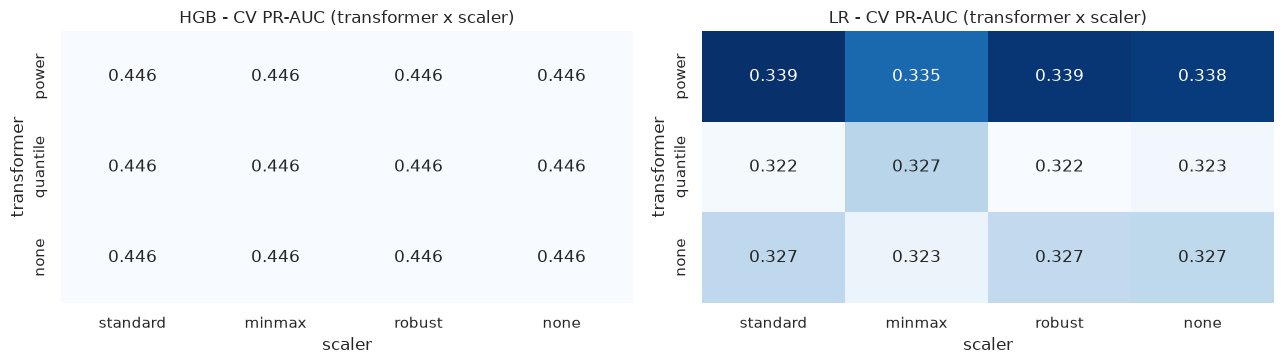

cv_pr_auc        cv_roc_auc        cv_balanced_accuracy       
                 min    max        min    max                  min    max
algoritmus                                                               
HGB            0.446  0.446      0.776  0.776                0.710  0.710
LR             0.322  0.339      0.720  0.728                0.663  0.669

In [112]:
#3.4 B: vsetky kombinacie scaler x transformer pre HGB aj LR
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category = ConvergenceWarning) #obcasne varovanie lbfgs v jednotlivych foldoch - vid komentar
transform_rows = []
for transformer in ["power", "quantile", "none"]:
    for scaler in ["standard", "minmax", "robust", "none"]:
        for model_name, model in [("HGB", hgb_reference), ("LR", lr_reference)]:
            row = cv_variant(f"{transformer} + {scaler}", make_preprocess(scaler = scaler, transformer = transformer), model)
            transform_rows.append({"algoritmus": model_name, "transformer": transformer, "scaler": scaler, **row})
transform_table = pd.DataFrame(transform_rows)

fig, axes = plt.subplots(1, 2, figsize = (13, 3.8))
for ax, algo in zip(axes, ["HGB", "LR"]):
    pivot = transform_table[transform_table["algoritmus"] == algo].pivot(index = "transformer", columns = "scaler", values = "cv_pr_auc")
    sns.heatmap(pivot.loc[["power", "quantile", "none"], ["standard", "minmax", "robust", "none"]], annot = True, fmt = ".3f",
                cmap = "Blues", ax = ax, cbar = False)
    ax.set_title(f"{algo} - CV PR-AUC (transformer x scaler)")
plt.tight_layout()
plt.show()

display(transform_table.groupby("algoritmus")[["cv_pr_auc", "cv_roc_auc", "cv_balanced_accuracy"]].agg(["min", "max"]).round(3))

**HGB je voči scalerom aj transformerom úplne invariantný** - všetkých 12 kombinácií dalo identické CV PR-AUC 0.446. Stromy rozhodujú len podľa poradia hodnôt a monotónne transformácie (škálovanie, Yeo-Johnson, kvantilová) poradie nemenia; HGB si navyše hodnoty interne aj tak rozdelí do kvantilových košov.

**Logistická regresia je citlivá hlavne na transformer:** `PowerTransformer` dáva 0.335-0.339, bez transformácie 0.323-0.327 a `QuantileTransformer` 0.322-0.327. Yeo-Johnson zníži šikmosť `filterDp`/`rms_vibration`/`serviceHours` (2.1 C) a vzťah k log-odds poruchy sa tým priblíži lineárnemu; `QuantileTransformer` je horší pravdepodobne kvôli stropu `serviceHours = 45 000 h` (2.1 C), ktorý pri mapovaní na kvantily deformuje rozdelenie. Voľba scalera mení PR-AUC len o ≤ 0.004 - pri L2 regularizácii (`C=0.1`) a prevažne už transformovaných atribútoch na mierke takmer nezáleží. (Pri niektorých kombináciách sa v jednotlivých foldoch objavilo varovanie, že `lbfgs` nedokonvergoval do 3 000 iterácií; na celej trénovacej množine konvergujú všetky kombinácie a výsledky to ovplyvňuje len minimálne, preto varovania potláčame.) Kombinácia z fázy 2 (`PowerTransformer` + `StandardScaler`, 0.339) je pre LR najlepšia - rozhodnutie z 2.1 D sa potvrdilo.

### 3.4 C - Výber atribútov, metrík, algoritmov, hyperparameter tuning, ensemble learning (1b)
Vyhodnoťte výber atribútov, metrík, algoritmov, hyperparameter tuning a ensemble learning.

**Výber atribútov (2.2).** Porovnáme našich 9 atribútov s menšími podmnožinami podľa poradia z 2.2 B (top 4, top 6, bez `oilTemperature`, ktorý v 3.2 D žiadny model nepoužil) a s rozšírenou sadou, ktorú sme v 2.2 vyradili (`mean/median_signal_dbm`, `filterDp_suspicious`, one-hot `codeModel`, `fleetCode`).

,,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_roc_auc,cv_balanced_accuracy,cv_f1
algoritmus,variant,,,,,,,
HGB,top 4 (2.2 B),0.426,0.396,0.042,0.030,0.745,0.683,0.360
LR,top 4 (2.2 B),0.200,0.202,0.017,-0.002,0.642,0.605,0.271
HGB,top 6 (2.2 B),0.479,0.448,0.050,0.031,0.777,0.710,0.388
LR,top 6 (2.2 B),0.323,0.323,0.035,-0.000,0.721,0.667,0.326
HGB,8 - bez oilTemperature,0.484,0.448,0.049,0.036,0.777,0.709,0.388
LR,8 - bez oilTemperature,0.340,0.340,0.038,-0.000,0.728,0.668,0.327
HGB,9 vybranych (referencia),0.487,0.446,0.048,0.040,0.776,0.710,0.389
LR,9 vybranych (referencia),0.340,0.339,0.038,0.001,0.728,0.667,0.326
HGB,rozsirena sada (16 stlpcov),0.487,0.447,0.047,0.040,0.776,0.709,0.388


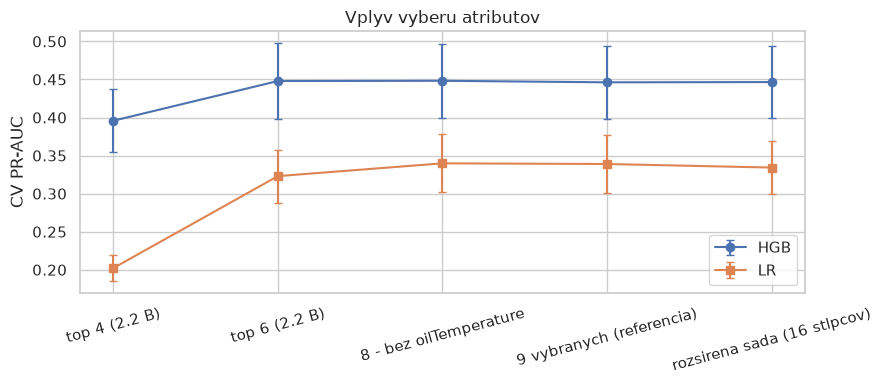

In [113]:
#3.4 C: vyber atributov - podmnoziny podla poradia z 2.2 B a rozsirena sada
ranking_22 = ["filterDp", "serviceHours", "rms_vibration", "currentMotor", "dewpointDischarge",
              "class_duty", "reservoir_pressure", "Flowmeter", "oilTemperature"]
feature_variants = [
    ("top 4 (2.2 B)", {"features": ranking_22[:4]}, None),
    ("top 6 (2.2 B)", {"features": ranking_22[:6]}, None),
    ("8 - bez oilTemperature", {"features": ranking_22[:8]}, None),
    ("9 vybranych (referencia)", {}, None),
    ("rozsirena sada (16 stlpcov)", {"features": SELECTED_FEATURES + ["mean_signal_dbm", "median_signal_dbm"],
                                    "onehot": ("codeModel", "fleetCode"), "passthrough": ("filterDp_suspicious",)}, None),
]
feature_table = ablation_table(feature_variants)
display(feature_table.round(3))

fig, ax = plt.subplots(figsize = (9, 4))
for algo, marker in [("HGB", "o"), ("LR", "s")]:
    part = feature_table.loc[algo]
    ax.errorbar(range(len(part)), part["cv_pr_auc"], yerr = part["cv_pr_auc_std"], marker = marker, capsize = 3, label = algo)
ax.set_xticks(range(len(feature_variants)))
ax.set_xticklabels([v[0] for v in feature_variants], rotation = 15)
ax.set_ylabel("CV PR-AUC")
ax.set_title("Vplyv vyberu atributov")
ax.legend()
plt.tight_layout()
plt.show()

**HGB:** od 6 atribútov sa výkon nemení (top 6: 0.448, 8 bez `oilTemperature`: 0.448, našich 9: 0.446, rozšírená sada 16 stĺpcov: 0.447); len top 4 je výrazne horšia (0.396). **LR:** top 4 má len 0.202 - chýba v nej `class_duty`, ktorý má v LR najväčší koeficient (3.2 B); od 8 atribútov je výkon stabilný (0.339-0.340), rozšírená sada mierne horšia (0.334).

Záver: (1) výber v 2.2 bol správny - vyradené atribúty (`mean/median_signal_dbm`, `filterDp_suspicious`, `codeModel`, `fleetCode`) nepridávajú nič ani jednému modelu, len komplexitu a riziko časového úniku zo signálu brán (2.2 C); (2) `oilTemperature` je zbytočný (bez neho 0.448 vs. 0.446), ale rozdiel je pod naším prahom 0.005 a ďaleko pod std medzi foldami (~0.05), preto ponechávame overených 9 atribútov; (3) poradie z 2.2 B je pre stromy rozumné, ale samotné F-test/MI/RF skóre podhodnotilo `class_duty` pre lineárny model.

**Výber metriky a rozhodovacieho prahu.** Ukážeme, prečo nemôžeme modely porovnávať podľa accuracy: triviálny model, ktorý vždy predikuje „bez poruchy“, má vyššiu accuracy než všetky naše modely. Ďalej - všetky metriky závislé od prahu (precision, recall, F1) sme doteraz počítali pri prahu 0.5 na pravdepodobnosti. Prah je však rozhodnutie, ktoré treba zvoliť podľa cieľa úlohy; robíme to na **out-of-fold predikciách** z CV na trénovacej množine (každé meranie predikuje model, ktorý ho nevidel), nie na teste.

In [114]:
#3.4 C: metriky - trivialny model vs. HGB (CV)
from sklearn.dummy import DummyClassifier
metric_rows = [
    cv_variant("vzdy 'bez failure' (DummyClassifier)", make_preprocess(), DummyClassifier(strategy = "most_frequent")),
    cv_variant("HGB (3.3)", make_preprocess(), hgb_reference),
]
dummy_accuracy = cross_validate(Pipeline([("preprocess", make_preprocess()), ("model", DummyClassifier(strategy = "most_frequent"))]),
                                X_train_all, y_train_model, groups = groups_train, cv = cv_groups, scoring = "accuracy")["test_score"].mean()
hgb_accuracy = cross_validate(Pipeline([("preprocess", make_preprocess()), ("model", clone(hgb_reference))]),
                              X_train_all, y_train_model, groups = groups_train, cv = cv_groups, scoring = "accuracy", n_jobs = -1)["test_score"].mean()
metric_table = pd.DataFrame(metric_rows).set_index("model")
metric_table["cv_accuracy"] = [dummy_accuracy, hgb_accuracy]
display(metric_table[["cv_accuracy", "cv_balanced_accuracy", "cv_f1", "cv_roc_auc", "cv_pr_auc"]].round(3))

,cv_accuracy,cv_balanced_accuracy,cv_f1,cv_roc_auc,cv_pr_auc
model,,,,,
vzdy 'bez failure' (DummyClassifier),0.878,0.50,0.000,0.500,0.122
HGB (3.3),0.749,0.71,0.389,0.776,0.446


,hodnota,precision,recall,f1,f2,alarmov na 1 poruchu
prah,,,,,,
0.5 (predvoleny),0.500,0.277,0.659,0.390,0.516,3.614
max F1,0.621,0.476,0.427,0.450,0.436,2.099
max F2 (recall 2x dolezitejsi),0.497,0.274,0.666,0.388,0.517,3.653


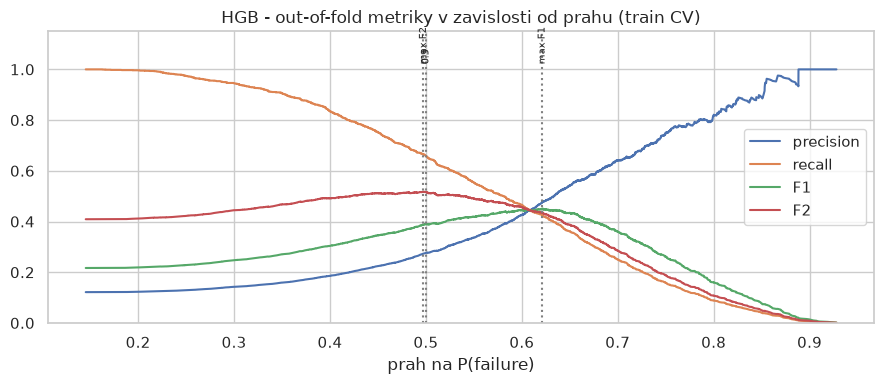

In [115]:
#3.4 C: volba rozhodovacieho prahu na out-of-fold predikciach (len train)
from sklearn.metrics import precision_recall_curve, fbeta_score

oof_score = cross_val_predict(Pipeline([("preprocess", make_preprocess()), ("model", clone(hgb_reference))]),
                              X_train_all, y_train_model, groups = groups_train, cv = cv_groups,
                              method = "predict_proba", n_jobs = -1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train_model, oof_score)
prec, rec = prec[:-1], rec[:-1]
f1_curve = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
f2_curve = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)

threshold_options = {
    "0.5 (predvoleny)": 0.5,
    "max F1": thr[np.argmax(f1_curve)],
    "max F2 (recall 2x dolezitejsi)": thr[np.argmax(f2_curve)],
}
threshold_rows = []
for name, t in threshold_options.items():
    pred = (oof_score >= t).astype(int)
    threshold_rows.append({"prah": name, "hodnota": t, "precision": precision_score(y_train_model, pred),
                           "recall": recall_score(y_train_model, pred), "f1": f1_score(y_train_model, pred),
                           "f2": fbeta_score(y_train_model, pred, beta = 2),
                           "alarmov na 1 poruchu": pred.sum() / max((pred & y_train_model).sum(), 1)})
threshold_table = pd.DataFrame(threshold_rows).set_index("prah")
display(threshold_table.round(3))

fig, ax = plt.subplots(figsize = (9, 4))
ax.plot(thr, prec, label = "precision")
ax.plot(thr, rec, label = "recall")
ax.plot(thr, f1_curve, label = "F1")
ax.plot(thr, f2_curve, label = "F2")
for name, t in threshold_options.items():
    ax.axvline(t, linestyle = ":", color = "grey")
    ax.text(t, 1.02, name.split(" (")[0], rotation = 90, fontsize = 7, va = "bottom", ha = "center")
ax.set_xlabel("prah na P(failure)")
ax.set_ylim(0, 1.15)
ax.set_title("HGB - out-of-fold metriky v zavislosti od prahu (train CV)")
ax.legend(loc = "center right")
plt.tight_layout()
plt.show()

**Accuracy je pre túto úlohu nepoužiteľná:** triviálny model „vždy bez poruchy“ má CV accuracy **0.878**, vyššiu ako HGB (0.749) - pritom nezachytí ani jednu poruchu (balanced accuracy 0.5, F1 0, PR-AUC 0.122 = podiel porúch). Preto sme v celej fáze 3 vyberali modely podľa **PR-AUC** (prahovo nezávislá, citlivá práve na kvalitu predikcie minoritnej triedy) a reportovali balanced accuracy, recall, precision a F1.

**Prah:** pri prahu 0.5 má HGB out-of-fold precision 0.277 a recall 0.659 (3.6 alarmu na 1 poruchu). Prah s maximálnym F1 (0.62) zvýši precision na **0.476**, ale recall klesne na 0.427 - zachytíme menej ako polovicu porúch. Prah s maximálnym **F2** (recall váži 2× viac) vyšiel 0.497, prakticky rovnaký ako 0.5 - `class_weight="balanced"` posunul pravdepodobnosti presne do oblasti, kde je F2 optimálne. Pre prediktívnu údržbu volíme **F2**: prehliadnutá porucha znamená neplánovanú odstávku vlaku, falošný alarm „len“ kontrolu jednotky v depe. Ak by mal prevádzkovateľ obmedzenú kapacitu servisu, prah sa dá posunúť smerom k max F1 - krivky vyššie ukazujú, akú cenu v recalle to má.

**Algoritmy, hyperparameter tuning a ensemble learning (3.1-3.3).** Zhrnieme všetky natrénované modely na jednom mieste - CV na trénovacej množine (kde ju máme) a výsledky na teste. Modely z 3.3 (vyladený strom, bagging, random forest) sme na teste zatiaľ nevyhodnotili, doplníme ich tu.

,cv_pr_auc,test_pr_auc,test_roc_auc,test_balanced_accuracy,test_f1,test_recall,test_precision
model,,,,,,,
ID3 (3.1),NaN,0.227,0.683,0.630,0.293,0.605,0.193
Decision Tree (3.2),0.281,0.267,0.710,0.656,0.330,0.573,0.231
Logistic Regression (3.2),NaN,0.320,0.729,0.683,0.340,0.689,0.226
Decision Tree - vyladeny (3.3 A),0.318,0.309,0.729,0.676,0.347,0.616,0.242
Bagging stromov (3.3 B),0.372,0.344,0.741,0.688,0.377,0.582,0.279
Random Forest (3.3 B),0.392,0.362,0.738,0.680,0.346,0.641,0.237
Logistic Regression - vyladena (3.3 B),0.339,0.320,0.730,0.682,0.339,0.686,0.225
Gradient Boosting (3.3 B),0.446,0.414,0.773,0.702,0.376,0.655,0.263


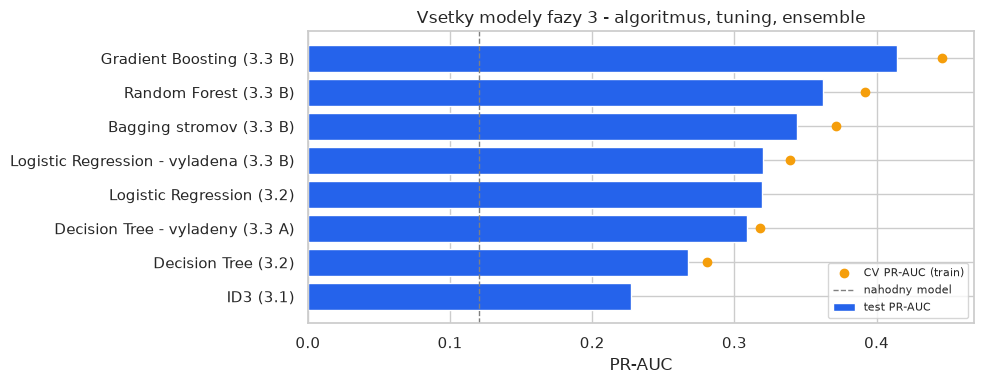

In [116]:
#3.4 C: prehlad algoritmov, tuningu a ensemble - CV (train) aj test
fitted_33 = {
    "Decision Tree - vyladeny (3.3 A)": clone(dt_search.best_estimator_).fit(X_train_raw, y_train_model),
    "Bagging stromov (3.3 B)": make_pipeline_33(BaggingClassifier(estimator = clone(best_dt_model), n_estimators = 100,
                                                                  random_state = 42, n_jobs = -1)).fit(X_train_raw, y_train_model),
    "Random Forest (3.3 B)": clone(rf_search.best_estimator_).set_params(model__n_jobs = -1).fit(X_train_raw, y_train_model),
    "Logistic Regression - vyladena (3.3 B)": clone(lr_search.best_estimator_).fit(X_train_raw, y_train_model),
    "Gradient Boosting (3.3 B)": best_model_33,
}
cv_lookup = {
    "Decision Tree (3.2)": comparison_33.loc["Decision Tree - 3.2 A (neladeny)", "cv_pr_auc"],
    "Decision Tree - vyladeny (3.3 A)": comparison_33.loc["Decision Tree - vyladeny", "cv_pr_auc"],
    "Bagging stromov (3.3 B)": comparison_33.loc["Bagging stromov", "cv_pr_auc"],
    "Random Forest (3.3 B)": comparison_33.loc["Random Forest", "cv_pr_auc"],
    "Logistic Regression - vyladena (3.3 B)": comparison_33.loc["Logistic Regression - vyladena", "cv_pr_auc"],
    "Gradient Boosting (3.3 B)": comparison_33.loc["Gradient Boosting (HGB)", "cv_pr_auc"],
}
overview_rows = []
for name, model in [("ID3 (3.1)", id3_model), ("Decision Tree (3.2)", decision_tree_model), ("Logistic Regression (3.2)", logistic_model)]:
    overview_rows.append({"model": name, "cv_pr_auc": cv_lookup.get(name, np.nan), **evaluate_classifier(model, test_transformed, y_test_model)})
for name, model in fitted_33.items():
    overview_rows.append({"model": name, "cv_pr_auc": cv_lookup.get(name, np.nan), **evaluate_classifier(model, X_test_raw, y_test_model)})
overview = pd.DataFrame(overview_rows).set_index("model").rename(columns = lambda c: c if c == "cv_pr_auc" else f"test_{c}")
display(overview[["cv_pr_auc", "test_pr_auc", "test_roc_auc", "test_balanced_accuracy", "test_f1", "test_recall", "test_precision"]].round(3))

fig, ax = plt.subplots(figsize = (10, 4))
plot_df = overview.sort_values("test_pr_auc")
ax.barh(plot_df.index, plot_df["test_pr_auc"], color = "#2563eb", label = "test PR-AUC")
ax.scatter(plot_df["cv_pr_auc"], plot_df.index, color = "#f59e0b", zorder = 3, label = "CV PR-AUC (train)")
ax.axvline(y_test_model.mean(), color = "grey", linestyle = "--", linewidth = 1, label = "nahodny model")
ax.set_xlabel("PR-AUC")
ax.set_title("Vsetky modely fazy 3 - algoritmus, tuning, ensemble")
ax.legend(loc = "lower right", fontsize = 8)
plt.tight_layout()
plt.show()

Na teste sa zopakovalo rovnaké poradie ako na CV - CV PR-AUC je pri všetkých modeloch o 0.01-0.03 vyššia ako testová, systematicky a bez výnimky, takže CV bola spoľahlivým vodidlom pri výbere:
- **algoritmus:** raw ID3 (0.227) < CART (0.267) < logistická regresia (0.320) - CART je lepší vďaka spojitým prahom a všetkým dátam, LR vďaka stabilite a dobrému predspracovaniu (2.1 C),
- **hyperparameter tuning:** strom 0.267 -> **0.309** (+16 % na teste); pri LR ladenie `C` nezmenilo nič (0.320 -> 0.320) - model je už dostatočne jednoduchý,
- **ensemble learning:** bagging 0.344, random forest 0.362, **gradient boosting 0.414** - ensemble stromov je najväčší jednotlivý skok vo fáze 3 (+34 % oproti vyladenému stromu); boosting vyhral, lebo znižuje bias (postupne opravuje chyby), kým bagging/RF len varianciu.

Všetky modely majú test balanced accuracy 0.63-0.70 a recall 0.57-0.69 - ich hlavný rozdiel je v tom, ako dobre zoradia merania podľa rizika (PR-AUC, ROC-AUC).

### 3.4 D - Najlepší model pre nasadenie (deployment) (1b)
Ktorý model je Váš najlepší model pre nasadenie (deployment)?

Kandidáti sú dvaja: (1) **HGB** - z ablácií v 3.4 A-C skombinujeme stratégie, ktoré na CV pomohli (zlepšenie CV PR-AUC aspoň o 0.005), a s takto upraveným predspracovaním **znovu vyladíme HGB** (mriežka z 3.3 B rozšírená o `class_weight` - balanced / žiadne, 40 nastavení, rovnaká CV aj pravidlo `gap <= 0.05`) - optimálne hyperparametre sa so zmenou vstupov môžu posunúť. (2) **logistická regresia** s predspracovaním, ktoré jej v 3.4 A pomohlo najviac, a znovu vyladeným `C`. Vyberáme model s najvyššou CV PR-AUC a rozhodovací prah potom zvolíme na out-of-fold predikciách podľa **F2** (3.4 C). Rozhodujeme **len podľa CV na trénovacej množine**; test použijeme až na finálne overenie.

In [117]:
#3.4 D: kombinacia stratégii, ktore na CV pomohli (oproti referencii o viac ako 0.005 PR-AUC pri HGB)
MIN_GAIN = 0.005 #strategiu prijmeme, len ak zlepsi CV PR-AUC aspon o 0.005
prep_lookup = {name: kwargs for name, kwargs, _ in preprocessing_variants}
feat_lookup = {name: kwargs for name, kwargs, _ in feature_variants}
hgb_a = ablation_a.loc["HGB"]
reference_cv = hgb_a.loc["referencia (median, 2.3 B)", "cv_pr_auc"]
final_prep_kwargs = {}

#chybajuce hodnoty: najlepsi variant (bez winsorizacie, ta sa posudzuje zvlast)
missing_candidates = hgb_a.drop(index = ["referencia (median, 2.3 B)", "winsorizacia 5/95 %"])
best_missing = missing_candidates["cv_pr_auc"].idxmax()
if missing_candidates.loc[best_missing, "cv_pr_auc"] > reference_cv + MIN_GAIN:
    final_prep_kwargs.update(prep_lookup[best_missing])
#outliery
if hgb_a.loc["winsorizacia 5/95 %", "cv_pr_auc"] > reference_cv + MIN_GAIN:
    final_prep_kwargs["winsorize"] = True
#vyber atributov
hgb_f = feature_table.loc["HGB"]
best_features = hgb_f["cv_pr_auc"].idxmax()
if hgb_f.loc[best_features, "cv_pr_auc"] > hgb_f.loc["9 vybranych (referencia)", "cv_pr_auc"] + MIN_GAIN:
    final_prep_kwargs.update(feat_lookup[best_features])
#scaler/transformer: HGB je voci nim invariantny (3.4 B), ponechavame referenciu
print("zvolene upravy predspracovania oproti 2.3 B:", final_prep_kwargs if final_prep_kwargs else "ziadne")

#3.4 A ukazala, ze vahy tried hlavne posuvaju prah (PR-AUC bez vah bola vyssia) - prah volime zvlast,
#preto class_weight ladime spolu s ostatnymi hyperparametrami
final_param_grid = {**hgb_param_grid, "model__class_weight": ["balanced", None]}
final_search = RandomizedSearchCV(
    Pipeline([("preprocess", make_preprocess(**final_prep_kwargs)),
              ("model", HistGradientBoostingClassifier(random_state = 42))]),
    final_param_grid, n_iter = 40, random_state = 42, cv = cv_groups, scoring = scoring_33,
    refit = select_without_overfit, return_train_score = True, n_jobs = -1,
)
final_search.fit(X_train_all, y_train_model, groups = groups_train)

#druhy kandidat: logisticka regresia s najlepsim predspracovanim pre LR z 3.4 A (indikatory chybania), znovu vyladene C
lr_a = ablation_a.loc["LR"]
best_lr_variant = lr_a["cv_pr_auc"].idxmax()
print("najlepsie predspracovanie pre LR (3.4 A):", best_lr_variant)
final_lr_search = GridSearchCV(
    Pipeline([("preprocess", make_preprocess(**prep_lookup[best_lr_variant])),
              ("model", LogisticRegression(class_weight = "balanced", max_iter = 3000))]),
    {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv = cv_groups, scoring = scoring_33,
    refit = select_without_overfit, return_train_score = True, n_jobs = -1,
)
final_lr_search.fit(X_train_all, y_train_model, groups = groups_train)

deploy_candidates = {
    "HGB z 3.3 (predspracovanie 2.3 B)": hgb_search,
    "HGB + upravene predspracovanie (3.4 D)": final_search,
    "LR + indikatory chybania (3.4 D)": final_lr_search,
}
candidates_table = pd.DataFrame([summary_row(name, search = search) for name, search in deploy_candidates.items()]).set_index("model")
display(candidates_table.round(3))
for name, search in deploy_candidates.items():
    print(f"{name}: {({k.replace('model__', ''): v for k, v in search.best_params_.items()})}")

zvolene upravy predspracovania oproti 2.3 B: {'impute': None}


najlepsie predspracovanie pre LR (3.4 A): median + indikatory chybania


,train_pr_auc,cv_pr_auc,cv_pr_auc_std,gap_pr_auc,cv_roc_auc,cv_balanced_accuracy,cv_f1
model,,,,,,,
HGB z 3.3 (predspracovanie 2.3 B),0.487,0.446,0.048,0.040,0.776,0.710,0.389
HGB + upravene predspracovanie (3.4 D),0.520,0.470,0.046,0.050,0.790,0.724,0.423
LR + indikatory chybania (3.4 D),0.486,0.483,0.050,0.003,0.795,0.726,0.409


HGB z 3.3 (predspracovanie 2.3 B): {'min_samples_leaf': 100, 'max_iter': 100, 'max_depth': 2, 'learning_rate': 0.05, 'l2_regularization': 1.0}
HGB + upravene predspracovanie (3.4 D): {'min_samples_leaf': 20, 'max_iter': 200, 'max_depth': 2, 'learning_rate': 0.05, 'l2_regularization': 0.0, 'class_weight': 'balanced'}
LR + indikatory chybania (3.4 D): {'C': 0.1}


model na nasadenie: LR + indikatory chybania (3.4 D)


prah (max F2 na out-of-fold predikciach): 0.490


,koeficient
missing__missingindicator_filterDp,2.332
missing__missingindicator_rms_vibration,2.071
categorical__class_duty,-1.438
other__currentMotor,0.806
skewed__serviceHours,0.356
skewed__filterDp,0.324
other__reservoir_pressure,-0.220
other__dewpointDischarge,0.197
skewed__rms_vibration,0.085
other__Flowmeter,-0.075


,train,CV (priemer),test,test - HGB z 3.3 pri prahu 0.5,gap train - test
pr_auc,0.486,0.483,0.437,0.414,0.049
roc_auc,0.798,0.795,0.796,0.773,0.002
balanced_accuracy,0.730,NaN,0.733,0.702,-0.003
precision,0.288,NaN,0.288,0.263,-0.000
recall,0.700,NaN,0.703,0.655,-0.003
f1,0.408,NaN,0.409,0.376,-0.001
f2,0.544,NaN,0.546,0.505,-0.002
accuracy,0.753,NaN,0.755,0.738,-0.002


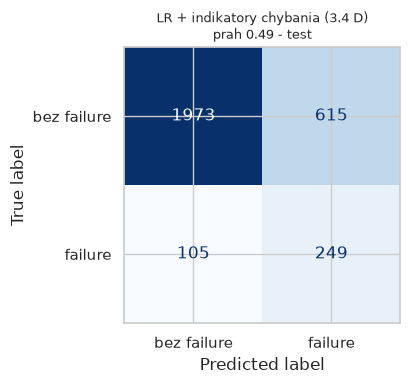

In [118]:
#3.4 D: finalny vyber podla CV, fit na celom train, prah z out-of-fold predikcii, jedno vyhodnotenie na teste
#vyber len podla CV PR-AUC (vsetci kandidati uz splnaju gap <= 0.05 z refit pravidla)
deploy_name = candidates_table["cv_pr_auc"].idxmax()
deploy_search = deploy_candidates[deploy_name]
deploy_template = clone(deploy_search.best_estimator_)
if deploy_search is hgb_search: #model z 3.3 bol ladeny na X_train_raw - predspracovanie podla stlpcov je rovnake
    deploy_template = Pipeline([("preprocess", make_preprocess()), ("model", clone(hgb_reference))])
print("model na nasadenie:", deploy_name)

deploy_cv = cross_validate(clone(deploy_template), X_train_all, y_train_model, groups = groups_train, cv = cv_groups,
                           scoring = scoring_33, return_train_score = True, n_jobs = -1)
deploy_oof = cross_val_predict(clone(deploy_template), X_train_all, y_train_model, groups = groups_train, cv = cv_groups,
                               method = "predict_proba", n_jobs = -1)[:, 1]
p_, r_, t_ = precision_recall_curve(y_train_model, deploy_oof)
DEPLOY_THRESHOLD = float(t_[np.argmax(5 * p_[:-1] * r_[:-1] / np.maximum(4 * p_[:-1] + r_[:-1], 1e-12))])
print(f"prah (max F2 na out-of-fold predikciach): {DEPLOY_THRESHOLD:.3f}")

deploy_model = clone(deploy_template).fit(X_train_all, y_train_model)
if isinstance(deploy_model.named_steps["model"], LogisticRegression):
    #linearny model je priamo interpretovatelny - koeficienty na standardizovanych vstupoch
    coef = pd.Series(deploy_model.named_steps["model"].coef_[0],
                     index = deploy_model.named_steps["preprocess"].get_feature_names_out()).sort_values(key = abs, ascending = False)
    display(coef.to_frame("koeficient").round(3))

def evaluate_at_threshold(model, X, y, threshold):
    score = model.predict_proba(X)[:, 1]
    pred = (score >= threshold).astype(int)
    return {"pr_auc": average_precision_score(y, score), "roc_auc": roc_auc_score(y, score),
            "balanced_accuracy": balanced_accuracy_score(y, pred), "precision": precision_score(y, pred),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "f2": fbeta_score(y, pred, beta = 2),
            "accuracy": accuracy_score(y, pred)}

deploy_table = pd.DataFrame({
    "train": evaluate_at_threshold(deploy_model, X_train_all, y_train_model, DEPLOY_THRESHOLD),
    "CV (priemer)": {m: deploy_cv[f"test_{m}"].mean() for m in ["pr_auc", "roc_auc"]},
    "test": evaluate_at_threshold(deploy_model, X_test_all, y_test_model, DEPLOY_THRESHOLD),
    "test - HGB z 3.3 pri prahu 0.5": evaluate_at_threshold(best_model_33, X_test_raw, y_test_model, 0.5),
})
deploy_table["gap train - test"] = deploy_table["train"] - deploy_table["test"]
display(deploy_table.round(3))

fig, ax = plt.subplots(figsize = (4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test_model, (deploy_model.predict_proba(X_test_all)[:, 1] >= DEPLOY_THRESHOLD).astype(int),
                                        display_labels = ["bez failure", "failure"], cmap = "Blues", colorbar = False, ax = ax)
ax.set_title(f"{deploy_name}\nprah {DEPLOY_THRESHOLD:.2f} - test", fontsize = 9)
plt.tight_layout()
plt.show()

**Na nasadenie vyberáme logistickú regresiu s indikátormi chýbania** (`C=0.1`, `class_weight="balanced"`, predspracovanie 2.3 B + `MissingIndicator` pre `filterDp`, `rms_vibration`). Na CV má najvyššiu PR-AUC zo všetkých kandidátov (**0.483** vs. 0.470 pri preladenom HGB s natívnymi `NaN` a 0.446 pri HGB z 3.3), najvyššiu ROC-AUC (0.795) aj balanced accuracy (0.726) a medzeru train - CV len 0.003 (HGB 0.050 - presne na hranici nášho pravidla).

**Test (prah 0.49 z max F2 na out-of-fold predikciách):** PR-AUC **0.437**, ROC-AUC **0.796**, balanced accuracy **0.733**, recall **0.703**, precision 0.288, F1 0.409. Oproti HGB z 3.3 je lepší vo všetkých metrikách (+0.023 PR-AUC, +0.023 ROC-AUC, +0.031 balanced accuracy, +0.048 recall). Zachytí 249 z 354 porúch (105 prehliadne) pri 615 falošných alarmoch - 3.5 alarmu na jednu poruchu (pri modeloch z 3.2 to bolo 4.3-5.2).

**Stabilný, bez overfitu, bez underfitu:** rozdiely train - test sú pri všetkých prahových metrikách |≤ 0.003| a pri ROC-AUC 0.002; testová PR-AUC (0.437) je menej ako 1 std pod CV (0.483 ± 0.050), CV foldy sú vyrovnané. Underfit to nie je - trénovacia PR-AUC 0.486 je 4× nad náhodným modelom a model je najlepší spomedzi všetkých skúšaných, vrátane ensemble.

**Prečo lineárny model porazil boosting:** hlavný signál v dátach tvoria (1) chýbanie merania `filterDp`/`rms_vibration` - koeficienty +2.33 a +2.07, t. j. ~10× a ~8× vyššie šance na poruchu - a (2) takmer monotónne efekty `class_duty`, `currentMotor`, `serviceHours`, `filterDp`. Keď majú tieto informácie explicitnú podobu, lineárny model ich zachytí a interakcie, ktoré pridáva boosting, prinesú viac variancie než signálu. Pre nasadenie má LR ďalšie výhody: **interpretovateľnosť** (každý koeficient vieme vysvetliť údržbe), malý artefakt (6 kB), rýchlu predikciu a stabilitu medzi foldami.

### 3.4 E - Data pipeline pre vybudovanie modelu v produkcii (1b)
Aký je data pipeline pre jeho vybudovanie na základe Vášho datasetu v produkcii?

Produkčný pipeline vychádza zo surových súborov (`readings.csv`, `units.csv`, `gateways.csv`) a skladá sa z dvoch častí:

| krok | čo robí | kde je definované | fitované na dátach? |
|---|---|---|---|
| 1. načítanie | 3 CSV s rôznymi oddeľovačmi (TAB, `,`, `;`) | 0. / 2.1 A | nie |
| 2. integrácia a čistenie | duplicity, formáty dátumov a `id_unit`, zjednotenie `class_duty`, spojenie tabuliek, hodnoty mimo fyzikálneho rozsahu -> `NaN` | `build_integrated_dataset` (2.1 A) | nie - len pravidlá (`class_duty_map`, `expected_ranges`) |
| 3. výber vstupov | stĺpce, ktoré model potrebuje | metadáta `input_columns` | nie |
| 4. predspracovanie | imputácia, transformácia, škálovanie, kódovanie | `ColumnTransformer` v sklearn `Pipeline` | **áno - len na train** |
| 5. model | vybraný model z 3.4 D -> P(failure) | sklearn `Pipeline` | **áno - len na train** |
| 6. rozhodnutie | alarm, ak P(failure) ≥ prah | metadáta `threshold` | áno - prah z out-of-fold CV |

Kroky 4-5 sú **jeden sklearn `Pipeline` objekt** uložený cez `joblib`; kroky 2 a 6 potrebujú **metadáta**, ktoré vznikli pri vývoji (mapovanie `class_duty`, fyzikálne rozsahy, prah, zoznam vstupov, verzie knižníc) - ukladáme ich do JSON vedľa modelu. Bez nich by produkčné dáta neprešli rovnakým čistením ako trénovacie.

In [119]:
#3.4 E: ulozenie modelu (pipeline) a metadat vytvorenych pri vyvoji
import joblib, json, sys, platform, hashlib, sklearn
from pathlib import Path
from datetime import datetime

MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok = True)
model_path = MODEL_DIR / "apu_failure_model.joblib"
metadata_path = MODEL_DIR / "apu_failure_model_metadata.json"
joblib.dump(deploy_model, model_path)

fitted_prep = deploy_model.named_steps["preprocess"]
used_columns = set()
for branch_name, _, branch_cols in fitted_prep.transformers_:
    if branch_name != "remainder":
        used_columns.update(branch_cols)
input_columns = [c for c in X_train_all.columns if c in used_columns]
metadata = {
    "model_name": deploy_name,
    "created": datetime.now().isoformat(timespec = "seconds"),
    "task": "binarna klasifikacia failure (APU predictive maintenance), dataset 046",
    "artifact": {"file": model_path.name, "sha256": hashlib.sha256(model_path.read_bytes()).hexdigest()},
    "environment": {"python": platform.python_version(), "scikit_learn": sklearn.__version__,
                    "pandas": pd.__version__, "numpy": np.__version__},
    "input_columns": input_columns,
    "input_dtypes": {c: str(df_train[c].dtype) for c in input_columns},
    "class_duty_levels": ["light", "medium", "heavy"],
    "cleaning_rules": {
        "class_duty_map": class_duty_map,
        "expected_ranges": {k: list(map(float, v)) for k, v in expected_ranges.items()},
        "function": "build_integrated_dataset (2.1 A)",
    },
    "preprocessing": str(fitted_prep),
    "imputation_medians": {
        name: dict(zip(cols, [v if isinstance(v, str) else float(v) for v in step.named_steps["imputer"].statistics_]))
        for name, step, cols in fitted_prep.transformers_
        if isinstance(step, Pipeline) and "imputer" in step.named_steps
    },
    "hyperparameters": {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                        for k, v in deploy_model.named_steps["model"].get_params().items()},
    "threshold": {"value": DEPLOY_THRESHOLD, "rule": "max F2 na out-of-fold predikciach 5-fold StratifiedGroupKFold (train)"},
    "training_data": {
        "rows": int(len(df_train)), "units": int(df_train["id_unit"].nunique()),
        "failure_rate": float(y_train_model.mean()),
        "cycle_ts_min": str(df_train["cycle_ts"].min()), "cycle_ts_max": str(df_train["cycle_ts"].max()),
        "split": "80/20 po id_unit, stratifikacia podla failure jednotky, random_state=42 (2.1 A)",
    },
    "metrics": {
        "cv": {m: float(deploy_cv[f"test_{m}"].mean()) for m in ["pr_auc", "roc_auc", "balanced_accuracy", "f1"]},
        "test_at_threshold": {k: float(v) for k, v in deploy_table["test"].items()},
    },
}
metadata_path.write_text(json.dumps(metadata, indent = 2, ensure_ascii = False, default = str))
print(f"ulozene: {model_path} ({model_path.stat().st_size / 1024:.0f} kB), {metadata_path}")
print(json.dumps({k: metadata[k] for k in ["model_name", "input_columns", "threshold", "environment"]}, indent = 2, ensure_ascii = False))

ulozene: model/apu_failure_model.joblib (7 kB), model/apu_failure_model_metadata.json
{
  "model_name": "LR + indikatory chybania (3.4 D)",
  "input_columns": [
    "class_duty",
    "filterDp",
    "rms_vibration",
    "serviceHours",
    "currentMotor",
    "oilTemperature",
    "reservoir_pressure",
    "Flowmeter",
    "dewpointDischarge"
  ],
  "threshold": {
    "value": 0.49049186389469285,
    "rule": "max F2 na out-of-fold predikciach 5-fold StratifiedGroupKFold (train)"
  },
  "environment": {
    "python": "3.14.10",
    "scikit_learn": "1.9.1",
    "pandas": "3.0.6",
    "numpy": "2.5.3"
  }
}


Produkčná funkcia: zo surových CSV vytvorí predikcie len s pomocou uloženého modelu a metadát (žiadne objekty z pamäte notebooku okrem funkcie čistenia z 2.1 A). Simulujeme príchod nových dát - surové súbory zúžime na testovacie jednotky a overíme, že výsledok je identický s modelom v pamäti.

In [120]:
#3.4 E: produkcny pipeline - surove CSV -> integracia/cistenie -> ulozeny model -> alarmy
def load_deployment(model_dir = "model"):
    model_dir = Path(model_dir)
    meta = json.loads((model_dir / "apu_failure_model_metadata.json").read_text())
    artifact = model_dir / meta["artifact"]["file"]
    if hashlib.sha256(artifact.read_bytes()).hexdigest() != meta["artifact"]["sha256"]:
        raise ValueError("model nezodpoveda metadatam (sha256)")
    if sklearn.__version__ != meta["environment"]["scikit_learn"]:
        print(f"POZOR: model bol vytvoreny v scikit-learn {meta['environment']['scikit_learn']}, teraz {sklearn.__version__}")
    return joblib.load(artifact), meta

def predict_failure(readings_raw, units_raw, gateways_raw, model, meta):
    df = build_integrated_dataset(readings_raw, units_raw, gateways_raw,
                                  class_duty_map = meta["cleaning_rules"]["class_duty_map"],
                                  expected_ranges = {k: tuple(v) for k, v in meta["cleaning_rules"]["expected_ranges"].items()})
    missing = set(meta["input_columns"]) - set(df.columns)
    if missing:
        raise ValueError(f"chybajuce vstupne stlpce: {missing}")
    unknown_duty = ~df["class_duty"].isin(meta["class_duty_levels"]) & df["class_duty"].notna()
    if unknown_duty.any():
        raise ValueError(f"neznama kategoria class_duty: {df.loc[unknown_duty, 'class_duty'].unique()}")
    out = df[["id_unit", "cycle_ts"]].copy()
    out["p_failure"] = model.predict_proba(df[meta["input_columns"]])[:, 1]
    out["alarm"] = (out["p_failure"] >= meta["threshold"]["value"]).astype(int)
    return out, df

#simulacia novych dat: surove subory zuzene na testovacie jednotky
prod_model, prod_meta = load_deployment()
unit_num = readings["id_unit"].astype(str).str.extract(r"(\d+)")[0].astype(int)
new_readings = readings[unit_num.isin(df_test["id_unit"].unique())]
predictions, df_new = predict_failure(new_readings, units, gateways, prod_model, prod_meta)

in_memory = deploy_model.predict_proba(X_test_all)[:, 1]
merged = predictions.merge(df_test[["id_unit", "cycle_ts"]].assign(p_memory = in_memory), on = ["id_unit", "cycle_ts"], how = "inner")
print(f"novych merani: {len(predictions)}, z toho sparovanych s df_test: {len(merged)}")
print(f"max rozdiel P(failure) produkcia vs. model v pamati: {np.abs(merged['p_failure'] - merged['p_memory']).max():.2e}")
print(f"alarmy: {predictions['alarm'].sum()} z {len(predictions)} merani "
      f"({predictions.groupby('id_unit')['alarm'].max().sum()} z {predictions['id_unit'].nunique()} jednotiek)")
display(predictions.sort_values("p_failure", ascending = False).head(8).round({"p_failure": 3}))

novych merani: 2942, z toho sparovanych s df_test: 2942
max rozdiel P(failure) produkcia vs. model v pamati: 0.00e+00
alarmy: 864 z 2942 merani (304 z 400 jednotiek)


,id_unit,cycle_ts,p_failure,alarm
144,83,2023-02-15 00:00:00,0.991,1
2437,1679,2023-08-13 00:00:00,0.987,1
2881,1949,2023-08-05 00:00:00,0.986,1
547,341,2023-08-24 00:00:00,0.986,1
2624,1768,2023-05-14 00:00:00,0.985,1
715,461,2023-09-21 09:03:00,0.983,1
915,587,2023-05-30 23:39:00,0.981,1
805,521,2023-11-08 00:00:00,0.980,1


Produkčný pipeline funguje end-to-end: zo surových CSV zúžených na 400 testovacích jednotiek (simulácia nových dát) vytvoril funkciou `build_integrated_dataset` (2.1 A) a uloženým modelom predikcie pre všetkých 2 942 meraní, **identické s modelom v pamäti** (max. rozdiel 0.0). Pri načítaní sa overuje SHA-256 artefaktu voči metadátam a verzia scikit-learn; pri predikcii existencia vstupných stĺpcov a známe kategórie `class_duty`.

**Dodané súbory** (`model/`):
- `apu_failure_model.joblib` - celý sklearn `Pipeline` (kontrola fyzikálneho rozsahu, imputácia, `PowerTransformer`, `StandardScaler`, `MissingIndicator`, `OrdinalEncoder`, `LogisticRegression`), fitovaný len na train; vlastný transformátor `PhysicalRangeToNaN` (2.3 B) musí byť pri načítaní modelu v inom procese definovaný/importovaný,
- `apu_failure_model_metadata.json` - metadáta z vývoja, bez ktorých sa model nedá správne použiť: pravidlá čistenia (`class_duty_map`, `expected_ranges`), zoznam a typy vstupov, mediány imputácie, hyperparametre, **prah 0.49** a pravidlo jeho výberu, popis trénovacích dát (počty, miera `failure`, obdobie, spôsob splitu), CV a testové metriky, verzie knižníc a hash artefaktu.

V testovacích dátach model vyhlásil alarm pri 864 z 2 942 meraní, ktoré patria 304 zo 400 jednotiek - jednotka má ~7 meraní a stačí jedno rizikové. V prevádzke preto odporúčame alarmy **prioritizovať podľa `p_failure`** (tabuľka vyššie - najrizikovejšie merania majú P > 0.98) a plánovať kontroly od najvyššieho rizika. **Pretrénovanie:** pri nových dátach sa zopakuje integrácia (2.1 A), split po jednotkách, fit pipeline, výber prahu na out-of-fold CV a uloží sa nová verzia modelu s novými metadátami.

**Zhrnutie 3.4:**
- **3.4 A - predspracovanie:** najväčší vplyv má spracovanie chýbajúcich hodnôt - indikátory chýbania zlepšili LR o 42 % (CV PR-AUC 0.339 -> 0.483), natívne `NaN` HGB o +0.011. Winsorizácia nepomohla (rozhodnutie z 1.2 C ponechať extrémy sa potvrdilo). Váhy tried hlavne posúvajú prah, undersampling škodí stratou dát. Split po jednotkách vs. po riadkoch tu nedal merateľný rozdiel, ponechávame ho ako metodicky správny.
- **3.4 B - transformácie:** HGB je voči scalerom/transformerom invariantný (12 × 0.446); LR profituje z `PowerTransformer` (+0.012-0.017 oproti ostatným), na voľbe scalera takmer nezáleží - voľba z 2.1 C/D bola pre LR optimálna.
- **3.4 C - atribúty, metriky, algoritmy, tuning, ensemble:** 9 atribútov z 2.2 je správna voľba (rozšírená sada nič nepridá, top 4 výrazne stratí). Accuracy je zavádzajúca (triviálny model 0.878), preto PR-AUC a prah podľa F2. Tuning stromu +16 %, ensemble +34 %, boosting najlepší zo stromových metód.
- **3.4 D - najlepší model:** **logistická regresia s indikátormi chýbania** (prah 0.49) - test PR-AUC 0.437, ROC-AUC 0.796, balanced accuracy 0.733, recall 0.703; rozdiel train - test ≈ 0, lepšia ako všetky ensemble modely a navyše interpretovateľná.
- **3.4 E - produkčný pipeline:** surové CSV -> `build_integrated_dataset` -> uložený sklearn `Pipeline` (`joblib`) -> prah z metadát (`JSON`); overený na simulovaných nových dátach s identickými výsledkami.

Najdôležitejšie poučenie fázy 3: **väčší vplyv ako zložitejší algoritmus malo lepšie pochopenie dát** - zistenie, že chýbajúce meranie senzora signalizuje poruchu (3.2 D), posunulo jednoduchý lineárny model nad všetky ensemble metódy.

## Zhrnutie Fázy 3

**Aký je náš najlepší model?** Logistická regresia (`C=0.1`, `class_weight="balanced"`) nad predspracovaním z fázy 2 doplneným o **indikátory chýbajúcich hodnôt** `filterDp` a `rms_vibration`, s rozhodovacím prahom **0.49** (maximum F2 na out-of-fold predikciách). Na odloženom teste: **PR-AUC 0.437, ROC-AUC 0.796, balanced accuracy 0.733, recall 0.703, precision 0.288** - zachytí 249 z 354 porúch pri 3.5 alarmu na jednu skutočnú poruchu.

**Je stabilný, bez overfitu a bez underfitu?** Áno. Rozdiel train - test je pri všetkých prahových metrikách ≤ 0.003, pri ROC-AUC 0.002; medzera train - CV v PR-AUC je 0.003 a testová PR-AUC leží v rozsahu krížovej validácie (0.483 ± 0.050). Underfit nie je - model je najlepší spomedzi všetkých skúšaných vrátane ensemble metód a 4× lepší ako náhodný model.

**Ako sme sa k nemu dostali?**
- **3.1:** vlastný raw ID3 (informačný zisk, vetvenie na všetky hodnoty, diskretizácia a undersampling mimo algoritmu); overfit neobmedzeného stromu (rozdiel train - test 0.251) sme odstránili pre-pruningom na hĺbku 4 (rozdiel 0.015).
- **3.2:** CART strom a logistická regresia - LR najlepšia (test PR-AUC 0.320); pravidlá stromu odhalili, že **chýbajúce meranie senzora signalizuje poruchu** (55-58 % `failure` oproti ~10 %).
- **3.3:** ladenie s 5-násobnou CV po jednotkách a pravidlom `gap train - CV ≤ 0.05`; ensemble stromov (bagging, random forest, gradient boosting) zlepšili strom o 34 %, najlepší HGB mal test PR-AUC 0.414.
- **3.4:** ablačné vyhodnotenie stratégií ukázalo, že najväčší vplyv má spracovanie chýbajúcich hodnôt (+42 % pre LR), transformácie pomáhajú len lineárnemu modelu, výber 9 atribútov z fázy 2 je správny a accuracy je pre túto úlohu zavádzajúca.

**Data pipeline v produkcii:** surové CSV -> `build_integrated_dataset` (2.1 A, pravidlá čistenia z metadát) -> uložený sklearn `Pipeline` (`model/apu_failure_model.joblib`) -> alarm podľa prahu z `model/apu_failure_model_metadata.json`. Metadáta obsahujú pravidlá čistenia, vstupy, mediány imputácie, hyperparametre, prah, popis trénovacích dát, metriky, verzie knižníc a hash modelu; pipeline je overený na simulovaných nových dátach s identickými výsledkami.

---
**Percentuálny podiel práce členov dvojice (Fáza 3):** Samuel Ivan = 50%, Juraj Krátky = 50%